# Final report models

Only the models of the report's storyline, in the order the report tells it, each with the usual measurements (held-out
likelihood; window-classifier AUC and individuality; the AUC under fairer windowings; the individuality grid; the
distance-to-dots profile; the matched profile; attraction; turn toward the dots; the head analysis). The full development
history — every other model and arm — stays in `Report_models.ipynb`; the ablation study is in
`Final_report_ablations.ipynb` and the two-group and multi-fish experiments in `Final_report_extrapolations.ipynb`.

**How to read it.**
- **Seeds.** Seed 0 and seed 101 are different cross-validation splits. Models are compared only on the same seed; the
  second seed is a second paired comparison, never pooled. Differences under ~0.05 AUC at one seed are within the seed
  noise (~0.03 per seed for these recipes); a claim needs the same direction at both seeds.
- **Headline AUC = matched** (generated windows cut at the real fish's own window positions, 1:1); 0.5 = indistinguishable,
  real against real ~0.52. Standard and no-radial readings alongside.
- **Profiles** (dip, grading, moving / static error, attraction) are from programme rollouts on per-block random streams,
  except Models 1–3, which are on the old single stream (marked; their AUC and likelihood are unaffected). Profile numbers carry rollout noise: grading ±1 mm, attraction ±1–2 mm, static error ±0.3.
- Real fish: dip 4.23 mm at 13.5 s, plateau 17.26 mm, 1-dot plateau 22.26 mm, grading 6.00 mm, attraction
  1.16 / 6.19 / 5.19 / 6.43 / 6.94 mm (1 / 2 / 4 / 6 / 8 dots).
- **XX** = a result that does not exist yet.

The cells of each model can be re-run on their own after the setup cell (they read `report_ckpts/M<key>`).

## Contents

1. [Summary tables](#summary) — every storyline model at both seeds; every step's change at both seeds
2. [Main line](#main) — [Model 1](#model-1) · [Model 2](#model-2) · [Model 3](#model-3) · [Model 4](#model-4) ·
   [25d](#m25d) · [26e](#m26e) (checks: [29a](#m29a), [29b](#m29b), [35a](#m35a))
3. [Drift branch](#drift) — [18a](#m18a) · [18a + drift](#m24b) · [Model 27](#model-27) · [Model 17](#model-17) ·
   [14f](#m14f)
4. [Scaling up: three hidden layers](#scale) — [M6](#m36a) · [D4](#m36c) · [F](#m36e)
5. [Lower-clip check: log range down to 2 px](#rzlo) — [M6](#m42a) · [D4](#m42c) · [F](#m42e)
6. [Slow-state time constant: tau = 200](#tau) — [D4](#m37a) · [F](#m37c)
7. [Turn-size individuality](#tsize) — [M6](#m38a) · [D4](#m38c) · [F](#m38e)
8. [Turn-size latent with tau = 200](#tsz200) — [D4](#m46a) · [F](#m46c)
9. [Fixed drift strength](#driftfix) — [0](#m47a) · [tau 70](#m47b) · [tau 200](#m47d) · [F on strength 0](#m48a)
10. [Appendix: the correction on other bases](#app) — [28a/b](#m28b) · [28c/d](#m28d) · [16b](#m16b) · [28e/f](#m28f)
11. [Supporting numbers](#support) — seed noise (Model 12); components alone on Model 4 (Model 25) and removed from 18a
   (Model 26)

In [ ]:
# Setup: the evaluation code lives in ../scripts.
import sys; sys.path.insert(0, "."); sys.path.insert(0, "../scripts")
import numpy as np, pandas as pd
pd.set_option("display.width", 250)
from rollout_model1_local import run
from model_figures import window_stats_grid, dot_profile, attraction_table, toward_by_n
from input_ablation import profile_variants_matched
REJ = {"wall_reject": {"d0": 2.0, "d1": 10.0, "max_draws": 20}}   # generation-time wall containment (Models 2+)

<a id="summary"></a>
## Summary tables

In [ ]:
import json, os
import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

def _s(key):
    """Key numbers of one notebook unit (None if it does not exist yet). A trailing * = profile numbers on the old stream."""
    p = f"report_outputs/summary_M{key.rstrip('*')}.json" if key else None
    return json.load(open(p)) if p and os.path.exists(p) else None

ROWS = [('1  Model 1', '1', None), ('2  Model 2', '2', None), ('3  Model 3', '3', None), ('4  Model 4', '20f', '30a'), ('5  25d', '25d', '30b'), ('   29a (check)', '29a', '30c'), ('   29b (check)', '29b', None), ('   35a (check: 26e − run clock)', '35a', '35b'), ('6  26e = ablation model', '26e', '30d'), ('7  18a', '18a', '24a'), ('8  18a + drift', '24b', '24c'), ('9  Model 27', '16e', '30e'), ('10 Model 17', '11e', '32a'), ('11 14f = final model', '14f', '32b'), ('S  26e, three layers', '36a', '36b'), ('S  Model 17, three layers', '36c', '36d'), ('S  14f, three layers', '36e', '36f'), ('C  26e, lower clip', '42a', '42b'), ('C  Model 17, lower clip', '42c', '42d'), ('C  14f, lower clip', '42e', '42f'), ('T  Model 17, tau 200', '37a', '37b'), ('T  14f, tau 200', '37c', '37d'), ('Z  26e, turn size', '38a', '38b'), ('Z  Model 17, turn size', '38c', '38d'), ('Z  14f, turn size', '38e', '38f'), ('ZT Model 17, turn size + tau 200', '46a', '46b'), ('ZT 14f, turn size + tau 200', '46c', '46d'), ('G  D4 drift strength 0', '47a', '47f'), ('G  D4 tau 70 half', '47b', '47g'), ('G  D4 tau 70 full', '47c', '47h'), ('G  D4 tau 200 half', '47d', '47i'), ('G  D4 tau 200 full', '47e', '47j'), ('G  F on strength-0 D4', '48a', '48b'), ('A  28b (26e + corr.)', '28b', None), ('A  28d (26e + corr., always on)', '28d', None), ('A  16b (M27 + corr.)', '16b', None)]
COLS = [("likelihood (bits/bout)", "lik_joint", 3), ("matched AUC", "auc_matched", 3), ("std AUC", "auc_std", 3),
        ("no-radial AUC", "auc_matched_norad", 3), ("dip (mm)", "dip", 2), ("dip latency (s)", "lat", 1),
        ("grading (mm)", "grading", 2), ("moving err (SEM)", "mv_err_sem", 2), ("static err (SEM)", "st_err_sem", 2),
        ("2-dot attraction", "attr_N2", 2), ("8-dot attraction", "attr_N8", 2)]
PROFILE = {"dip", "lat", "grading", "mv_err_sem", "st_err_sem", "attr_N2", "attr_N8"}

def _cell(key, c, nd):
    s = _s(key)
    if s is None or s.get(c) is None:
        return "XX"
    if key.endswith("*") and c in PROFILE:              # old-stream profile numbers do not pair
        return f"({s[c]:.{nd}f})"
    return f"{s[c]:.{nd}f}"

T = pd.DataFrame([{lab: f"{_cell(k0, c, nd)} | {_cell(k1, c, nd)}" for lab, c, nd in COLS}
                  for _, k0, k1 in ROWS], index=[r[0] for r in ROWS])
T.insert(0, "keys (s0 | s101)", [f"{k0} | {k1 or 'XX'}" for _, k0, k1 in ROWS])
print("Every storyline model: seed 0 | seed 101 (XX = not run; (x) = profile number on the old stream, not paired)")
print("Real fish: dip 4.23 @ 13.5 s, grading 6.00, attraction 2 dots 6.19 / 8 dots 6.94; real-vs-real AUC ~0.52.")
T

Every storyline model: seed 0 | seed 101 (XX = not run; (x) = profile number on the old stream, not paired)
Real fish: dip 4.23 @ 13.5 s, grading 6.00, attraction 2 dots 6.19 / 8 dots 6.94; real-vs-real AUC ~0.52.
                                 keys (s0 | s101) likelihood (bits/bout)    matched AUC        std AUC  no-radial AUC     dip (mm) dip latency (s) grading (mm) moving err (SEM) static err (SEM) 2-dot attraction 8-dot attraction
1  Model 1                                 1 | XX            13.419 | XX     0.869 | XX     0.872 | XX     0.837 | XX    1.05 | XX        6.0 | XX    1.02 | XX        2.51 | XX        3.10 | XX        1.75 | XX        1.04 | XX
2  Model 2                                 2 | XX            13.419 | XX     0.839 | XX     0.853 | XX     0.832 | XX    1.19 | XX        5.5 | XX    2.83 | XX        2.31 | XX        3.39 | XX        1.08 | XX        2.27 | XX
3  Model 3                                 3 | XX            13.361 | XX     0.701 | XX     0.707 | XX

In [ ]:
import json, os
import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

def _s(key):
    """Key numbers of one notebook unit (None if it does not exist yet). A trailing * = profile numbers on the old stream."""
    p = f"report_outputs/summary_M{key.rstrip('*')}.json" if key else None
    return json.load(open(p)) if p and os.path.exists(p) else None

STEPS = [('1 -> 2  + wall rejection', ('1', '2'), None), ('2 -> 3  + latent', ('2', '3'), None), ('3 -> 4  + S4i products (old stream)', ('3', '4'), None), ('4 -> 25d  + x3 turn weight', ('20f', '25d'), ('30a', '30b')), ('25d -> 26e  + range products + temporal set', ('25d', '26e'), ('30b', '30d')), ('25d -> 29a  range products alone', ('25d', '29a'), ('30b', '30c')), ('29a -> 26e  + temporal set', ('29a', '26e'), ('30c', '30d')), ('25d -> 29b  temporal set alone', ('25d', '29b'), None), ('29b -> 26e  + range products', ('29b', '26e'), None), ('26e -> 35a  run clock removed', ('26e', '35a'), ('30d', '35b')), ('26e -> 18a  + static block', ('26e', '18a'), ('30d', '24a')), ('18a -> 18a + drift', ('18a', '24b'), ('24a', '24c')), ('18a -> Model 27  bumps', ('18a', '16e'), ('24a', '30e')), ('Model 27 -> Model 17  + drift', ('16e', '11e'), ('30e', '32a')), ('18a + drift -> Model 17  bumps, with drift', ('24b', '11e'), ('24c', '32a')), ('Model 17 -> 14f  + correction', ('11e', '14f'), ('32a', '32b')), ('26e -> 28b  + correction', ('26e', '28b'), None), ('26e -> Model 17  (head to head)', ('26e', '11e'), ('30d', '32a')), ('26e -> 14f  (head to head)', ('26e', '14f'), ('30d', '32b')), ('26e -> three layers', ('26e', '36a'), ('30d', '36b')), ('Model 17 -> three layers', ('11e', '36c'), ('32a', '36d')), ('14f -> three layers', ('14f', '36e'), ('32b', '36f')), ('26e -> lower clip', ('26e', '42a'), ('30d', '42b')), ('Model 17 -> lower clip', ('11e', '42c'), ('32a', '42d')), ('14f -> lower clip', ('14f', '42e'), ('32b', '42f')), ('Model 17 -> tau 200', ('11e', '37a'), ('32a', '37b')), ('14f -> tau 200', ('14f', '37c'), ('32b', '37d')), ('26e -> turn size', ('26e', '38a'), ('30d', '38b')), ('Model 17 -> turn size', ('11e', '38c'), ('32a', '38d')), ('14f -> turn size', ('14f', '38e'), ('32b', '38f')), ('Model 17 -> turn size + tau 200', ('11e', '46a'), ('32a', '46b')), ('14f -> turn size + tau 200', ('14f', '46c'), ('32b', '46d')), ('tau 200 D4 -> + turn size', ('37a', '46a'), ('37b', '46b')), ('turn-size D4 -> + tau 200', ('38c', '46a'), ('38d', '46b')), ('fixed full: tau 70 -> tau 200', ('47c', '47e'), ('47h', '47j')), ('fixed half: tau 70 -> tau 200', ('47b', '47d'), ('47g', '47i')), ('tau 70: strength 0 -> full', ('47a', '47c'), ('47f', '47h')), ('Model 17 -> fixed full strength', ('11e', '47c'), ('32a', '47h')), ('strength-0 D4 -> + correction', ('47a', '48a'), ('47f', '48b')), ('14f -> F on strength-0 D4', ('14f', '48a'), ('32b', '48b'))]
D = [("d likelihood", "lik_joint", 3), ("d matched AUC", "auc_matched", 3), ("d std AUC", "auc_std", 3),
     ("d no-radial AUC", "auc_matched_norad", 3), ("d dip", "dip", 2), ("d grading", "grading", 2),
     ("d moving err", "mv_err_sem", 2), ("d static err", "st_err_sem", 2)]
PROFILE = {"dip", "grading", "mv_err_sem", "st_err_sem"}

def _d(pair, c):
    if pair is None:
        return None
    a, b = _s(pair[0]), _s(pair[1])
    if a is None or b is None or a.get(c) is None or b.get(c) is None:
        return None
    if c in PROFILE and (pair[0].endswith("*") or pair[1].endswith("*")):
        return None                                      # mixes random streams: not a paired profile change
    return b[c] - a[c]

rows = []
for lab, p0, p1 in STEPS:
    r = {"step": lab}
    for name, c, nd in D:
        d0, d1 = _d(p0, c), _d(p1, c)
        f = lambda v: "XX" if v is None else f"{v:+.{nd}f}"
        r[name] = f"{f(d0)} | {f(d1)}"
    m0, m1 = _d(p0, "auc_matched"), _d(p1, "auc_matched")
    r["matched: same sign at both seeds?"] = ("one seed" if (m0 is None or m1 is None) else
                                             ("yes" if np.sign(m0) == np.sign(m1) else "NO (seed-dependent)"))
    rows.append(r)
print("Every step: change seed 0 | seed 101 (negative AUC / likelihood / errors = better; XX = not run or not paired)")
pd.DataFrame(rows).set_index("step")

Every step: change seed 0 | seed 101 (negative AUC / likelihood / errors = better; XX = not run or not paired)
                                                d likelihood    d matched AUC        d std AUC  d no-radial AUC          d dip      d grading   d moving err   d static err matched: same sign at both seeds?
step                                                                                                                                                                                                         
1 -> 2  + wall rejection                         +0.000 | XX      -0.030 | XX      -0.019 | XX      -0.005 | XX     +0.13 | XX     +1.80 | XX     -0.20 | XX     +0.29 | XX                          one seed
2 -> 3  + latent                                 -0.057 | XX      -0.138 | XX      -0.146 | XX      -0.167 | XX     -0.28 | XX     -0.20 | XX     +0.17 | XX     -0.55 | XX                          one seed
3 -> 4  + S4i products (old stream)              +0.005 | XX     

<a id="main"></a>
## 1. Main line — closed-loop profiles improve at constant AUC

Each step adds one thing to
the previous model. The AUC gains stop after the latent (Model 3); from Model 4 on, what improves — at both seeds — is the
closed-loop response to the dots (dip, grading, moving and static errors). The main line ends at **26e, the ablation
model** (no drift, no correction).

<a id="model-1"></a>
### Model 1

**Change:** the simplest stimulus code (S0), no latent

Baseline. *Profile numbers on the old single random stream (see the note at the top).*

#### Model 1 — seed 0 (key `1`)

In [ ]:
# Model 1: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M1/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_1 = _l[_l.arm == "S0_adt"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_1.index = ["turn", "displacement", "interval", "joint"]
print(lik_1.round(3).to_string())

turn             7.661
displacement     4.536
interval         1.222
joint           13.419


In [ ]:
# Model 1: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_1, c2st_1 = run(ckpt_dir="report_ckpts/M1", arms="S0_adt", R=20, jobs=4, progress=False)

arms filter ['S0_adt'] -> writing panelB_model1_S0_adt.csv / c2st_model1_S0_adt.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_S0_adt.csv  (15 rows) in 1638s

Metric B, mean over held-out fish (lower = closer to real):
arm                      S0_adt
abs_dtheta_w1            6.6508
symbol_js                0.0064
dt_w1                    0.2216
dist_w1                  2.5233
trans_js                 0.0082
acf_l2                   0.0488
runlen_w1                0.1391
bigram_H_gap             0.0745
tuning_mse               0.0193
following_gap_h          0.0373
following_gap_static_h   0.0330
dot_dist_w1             13.0985
time_near_dot_gap        0.0533
approach_gap             0.5255
dot_dist_bias           -4.7178
time_far_gap             0.0633
wall_frac_gap            0.0445

arms ranked by the load-bearing stimulus metrics:
        followin

In [ ]:
# Model 1: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M1", "S0_adt", rej=None, jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_1 = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_1.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.869            0.003      0.837         0.003
matched to the real runs (same bouts, 1:1)            0.869            0.002      0.837         0.003



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.439         0.088        0.023          0.263         1.084
                      median           0.449       0.434         0.098        0.024          0.250         1.054
                      SD               0.159       0.181         0.015        0.007          0.479         1.208
                      q90              0.679       0.693         0.074        0.031

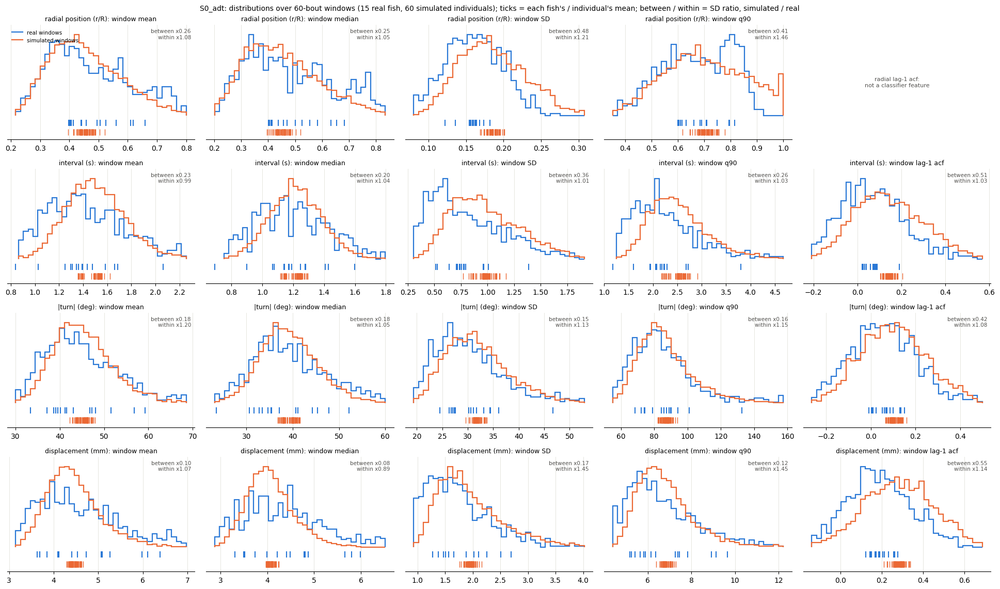

In [ ]:
# Model 1: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_1 = window_stats_grid("report_ckpts/M1", "S0_adt", rej=None, reps=4)


  S0_adt_fold0.pt: 3 rollouts
  S0_adt_fold1.pt: 3 rollouts
  S0_adt_fold2.pt: 3 rollouts
  S0_adt_fold3.pt: 3 rollouts
  S0_adt_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.56     1.09  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  21.0 +/- 0.7
d2s3.5    2.96     2.36  2.64  0.99  11.0  19.0                  17.4 +/- 0.9  20.3 +/- 0.7
d4s3.5    2.85     1.78  4.68  1.49  19.0   7.0                  18.7 +/- 1.7  20.9 +/- 0.8
d6s3.5    4.10     3.02  4.62  0.23  13.0   5.0                  16.7 +/- 1.3  20.8 +/- 0.8
d8s3.5    4.45     4.15  4.97  0.47  11.0  11.0

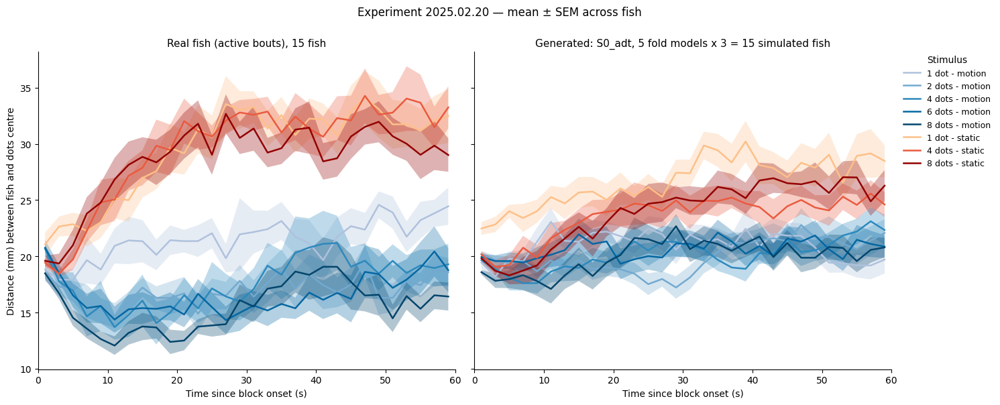

In [ ]:
# Model 1: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
# the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
st, gen_p, prof = dot_profile("report_ckpts/M1", "S0_adt", rej=None)

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                      mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                   
REAL   

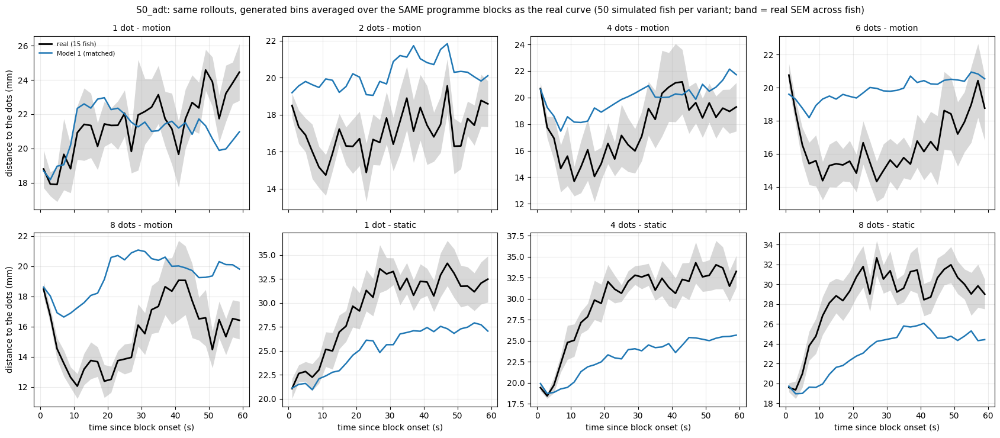

In [ ]:
# Model 1: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
# (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
varm_1, _ = profile_variants_matched("report_ckpts/M1", "S0_adt", {"Model 1": {"arm": "S0_adt"}}, rej=None, r_per_model=10,
                                       show_raw=False)

In [ ]:
# Model 1: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
# (~1 mm for one dot, ~6 mm from two up).
attr_1, _ = attraction_table("report_ckpts/M1", ["S0_adt"], rej=None, r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                    S0_adt                  
           plateau   null attraction plateau   null attraction
cond_label                                                    
d1s3.5       22.41  23.57       1.16   20.88  22.27       1.39
d2s3.5       17.39  23.58       6.19   20.41  22.17       1.75
d4s3.5       18.74  23.93       5.19   20.94  22.17       1.23
d6s3.5       16.69  23.12       6.43   20.66  22.01       1.35
d8s3.5       16.41  23.36       6.94   21.02  22.06       1.04


In [ ]:
# Model 1: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_1 = toward_by_n("report_ckpts/M1", ["S0_adt"], rej=None)
print(tow_1.round(2).to_string())

           real  S0_adt
win    N               
0-20 s 1   9.09    9.08
       2  13.90    9.59
       4  15.73   10.37
       6  14.50   10.33
       8  16.00   11.55
4-20 s 1   6.25    8.61
       2  12.27    9.21
       4  14.35   10.07
       6  12.79    9.95
       8  15.11   11.14


Model 1: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s             4-20 s             20-60 s            
         real gap Model 1   real gap Model 1    real gap Model 1
cond                                                            
d1s3.5  25.08      -12.00   6.64        2.86    7.55        1.69
d2s3.5  22.99       -9.16  12.94       -3.46   12.56       -2.27
d4s3.5  27.14      -14.39  15.54       -5.01   12.09       -1.67
d6s3.5  32.55      -19.55  13.80       -3.38   15.84       -5.03
d8s3.5  34.04      -19.69  14.45       -2.68   13.80       -2.19
d1s0     6.82        2.63   4.22        2.12    1.96        4.06
d4s0     4.81        4.83   1.86        4.09    1.74        5.40
d8s0     5.26        4.25   2.63        3.91    2.39        5.56

turn size |Δθ| (deg): real fish (mean over held-out fish) and each model's gap = model - real (p

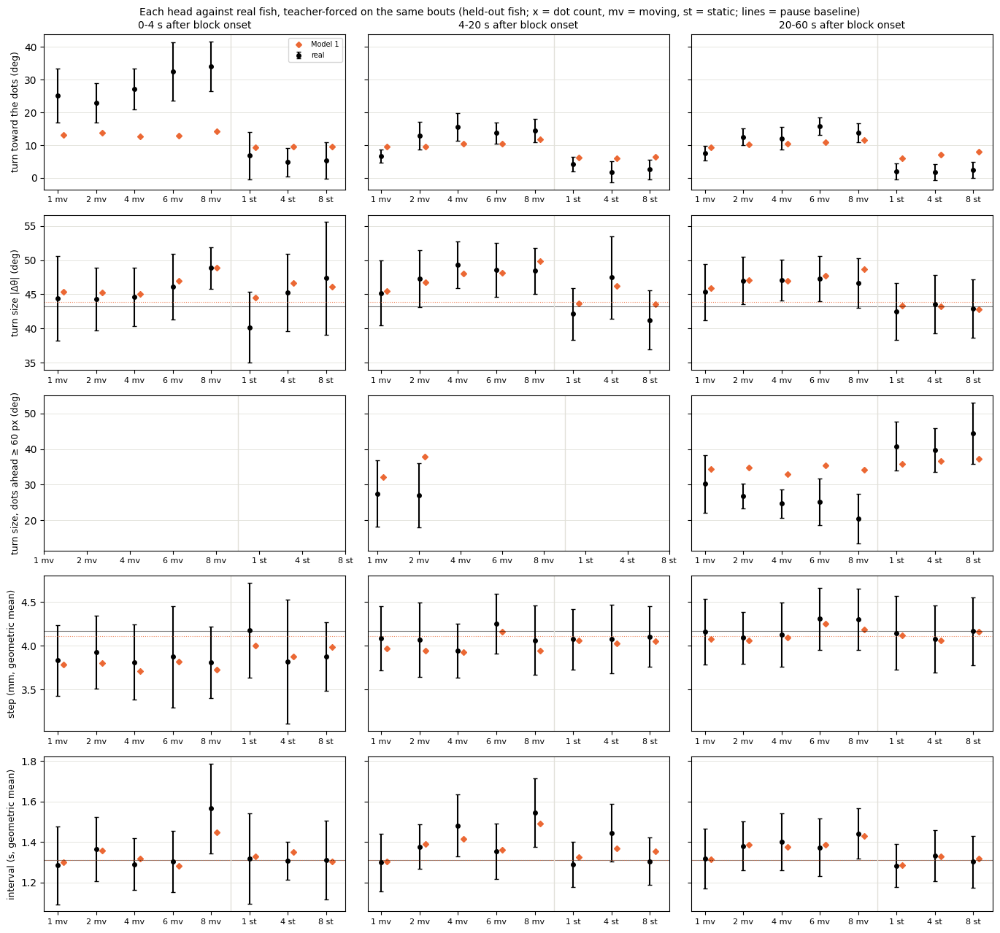

In [ ]:
# Model 1: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_1, hg_1 = head_gaps({"Model 1": ("report_ckpts/M1", "S0_adt")}, rej=None)

#### Model 1 — seed 101

XX — not trained at seed 101 (optional: the steps 1 → 3 are 3–5× the seed noise)

<a id="model-2"></a>
### Model 2

**Change:** + wall rejection (generation only, the same weights as Model 1)

Removes the wall artefacts: the gain is in the radial features. *Old stream.*

#### Model 2 — seed 0 (key `2`)

In [ ]:
# Model 2: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M2/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_2 = _l[_l.arm == "S0_adt"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_2.index = ["turn", "displacement", "interval", "joint"]
print(lik_2.round(3).to_string())

turn             7.661
displacement     4.536
interval         1.222
joint           13.419


In [ ]:
# Model 2: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_2, c2st_2 = run(ckpt_dir="report_ckpts/M2", arms="S0_adt", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S0_adt'] -> writing panelB_model1_rej_S0_adt.csv / c2st_model1_rej_S0_adt.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S0_adt.csv  (15 rows) in 1647s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S0_adt_rej
abs_dtheta_w1               6.5251
symbol_js                   0.0064
dt_w1                       0.2172
dist_w1                     2.4957
trans_js                    0.0082
acf_l2                      0.0489
runlen_w1                   0.1389
bigram_H_gap                0.0751
tuning_mse                  0.0197
following_gap_h             0.0366
following_gap_static_h      0.0380
dot_dist_w1                13.0331
time_near_dot_gap           0.0537
approach_gap             

In [ ]:
# Model 2: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M2", "S0_adt", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_2 = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_2.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.847            0.003      0.841         0.003
matched to the real runs (same bouts, 1:1)            0.839            0.003      0.832         0.003



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.427         0.088        0.018          0.200         0.889
                      median           0.449       0.422         0.098        0.019          0.193         0.904
                      SD               0.159       0.175         0.015        0.005          0.354         0.960
                      q90              0.679       0.680         0.074        0.021

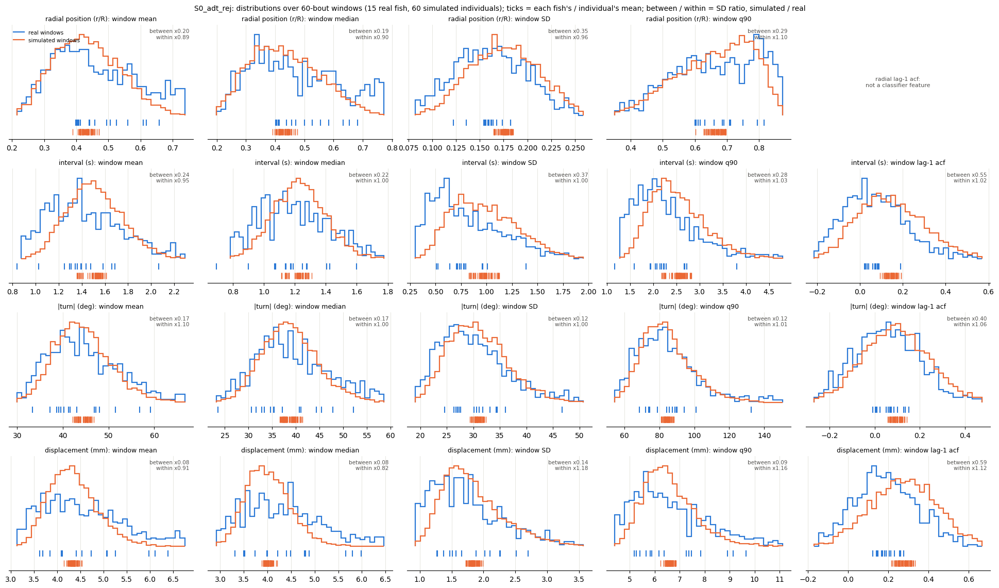

In [ ]:
# Model 2: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_2 = window_stats_grid("report_ckpts/M2", "S0_adt", rej=REJ["wall_reject"], reps=4)


  S0_adt_fold0.pt: 3 rollouts
  S0_adt_fold1.pt: 3 rollouts
  S0_adt_fold2.pt: 3 rollouts
  S0_adt_fold3.pt: 3 rollouts
  S0_adt_fold4.pt: 3 rollouts
dropped 9.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.56     1.08  0.15  0.37   3.0   3.0                  22.3 +/- 0.9  23.1 +/- 1.0
d2s3.5    2.92     2.33  2.64  1.86  11.0  11.0                  17.4 +/- 0.9  20.4 +/- 0.6
d4s3.5    2.64     1.59  4.68   1.8  19.0   7.0                  18.7 +/- 1.7  21.3 +/- 0.8
d6s3.5    3.35     2.45  4.62  1.12  13.0   5.0                  16.7 +/- 1.3  20.3 +/- 0.5
d8s3.5    3.17     2.99  4.97  1.21  11.0   7.0 

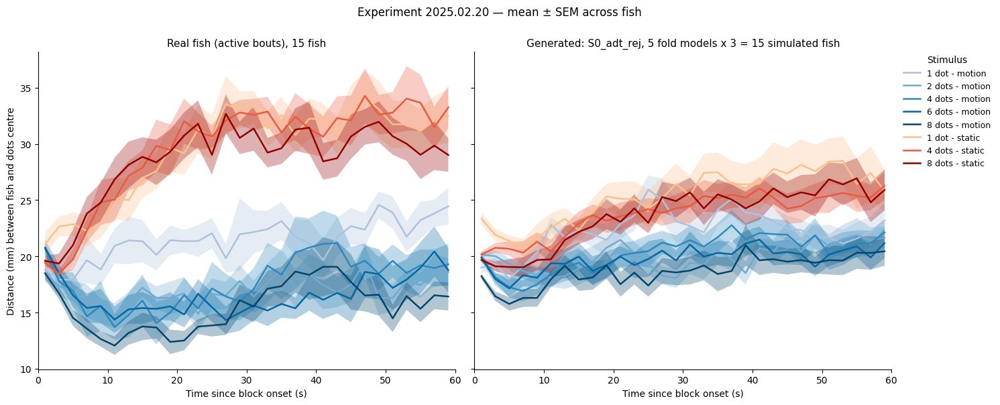

In [ ]:
# Model 2: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
# the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
st, gen_p, prof = dot_profile("report_ckpts/M2", "S0_adt", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                      mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                   
REAL   

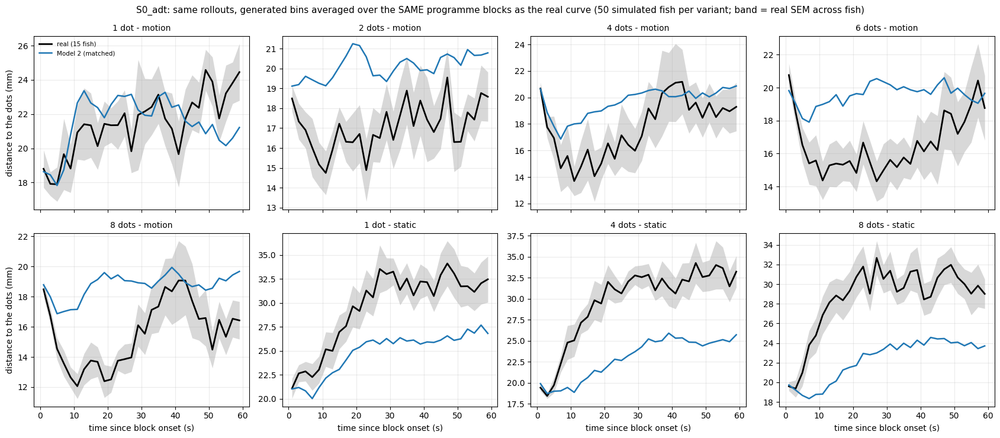

In [ ]:
# Model 2: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
# (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
varm_2, _ = profile_variants_matched("report_ckpts/M2", "S0_adt", {"Model 2": {"arm": "S0_adt"}}, rej=REJ["wall_reject"], r_per_model=10,
                                       show_raw=False)

In [ ]:
# Model 2: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
# (~1 mm for one dot, ~6 mm from two up).
attr_2, _ = attraction_table("report_ckpts/M2", ["S0_adt"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                    S0_adt                  
           plateau   null attraction plateau   null attraction
cond_label                                                    
d1s3.5       22.41  23.57       1.16   22.36  21.70      -0.66
d2s3.5       17.39  23.58       6.19   20.40  21.48       1.08
d4s3.5       18.74  23.93       5.19   21.22  21.61       0.39
d6s3.5       16.69  23.12       6.43   20.29  21.75       1.46
d8s3.5       16.41  23.36       6.94   19.37  21.64       2.27


In [ ]:
# Model 2: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_2 = toward_by_n("report_ckpts/M2", ["S0_adt"], rej=REJ["wall_reject"])
print(tow_2.round(2).to_string())

           real  S0_adt
win    N               
0-20 s 1   9.09    9.08
       2  13.90    9.59
       4  15.73   10.37
       6  14.50   10.33
       8  16.00   11.55
4-20 s 1   6.25    8.61
       2  12.27    9.21
       4  14.35   10.07
       6  12.79    9.95
       8  15.11   11.14


Model 2: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s             4-20 s             20-60 s            
         real gap Model 2   real gap Model 2    real gap Model 2
cond                                                            
d1s3.5  25.08      -12.00   6.64        2.86    7.55        1.69
d2s3.5  22.99       -9.16  12.94       -3.46   12.56       -2.27
d4s3.5  27.14      -14.39  15.54       -5.01   12.09       -1.67
d6s3.5  32.55      -19.55  13.80       -3.38   15.84       -5.03
d8s3.5  34.04      -19.69  14.45       -2.68   13.80       -2.19
d1s0     6.82        2.63   4.22        2.12    1.96        4.06
d4s0     4.81        4.83   1.86        4.09    1.74        5.40
d8s0     5.26        4.25   2.63        3.91    2.39        5.56

turn size |Δθ| (deg): real fish (mean over held-out fish) and each model's gap = model - real (p

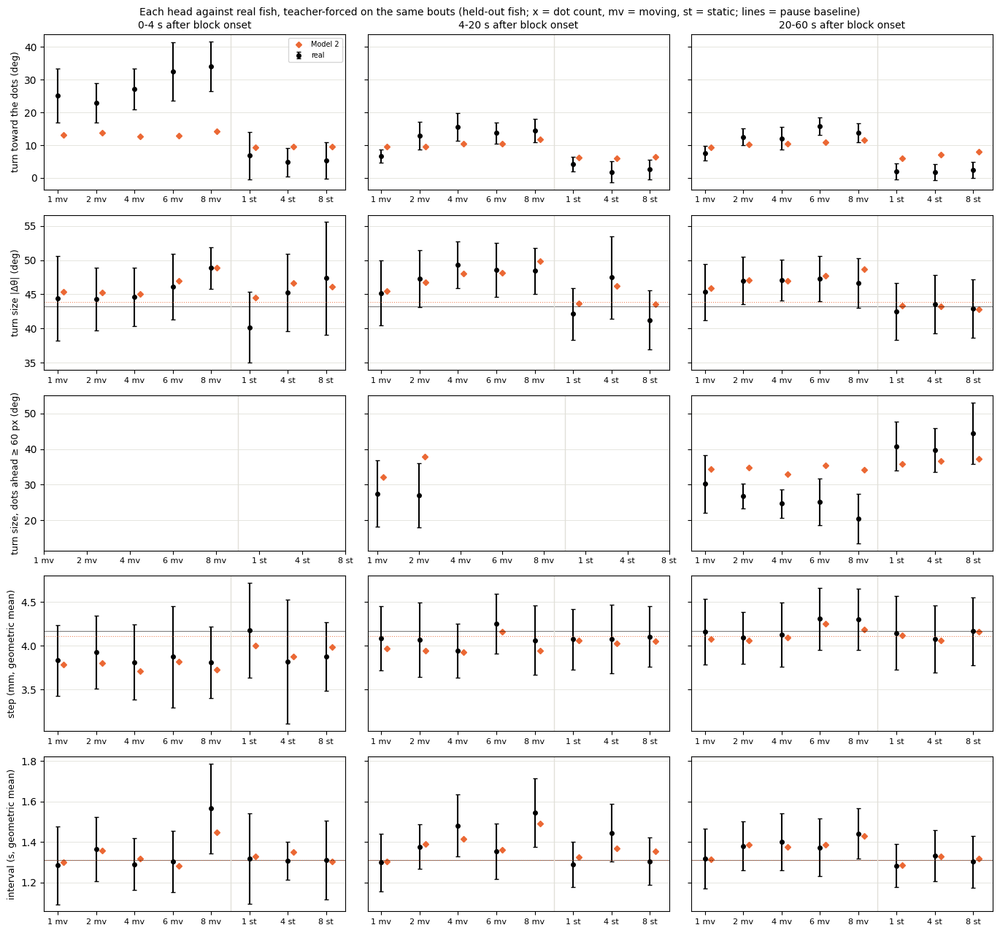

In [ ]:
# Model 2: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_2, hg_2 = head_gaps({"Model 2": ("report_ckpts/M2", "S0_adt")}, rej=REJ["wall_reject"])

#### Model 2 — seed 101

XX — not needed: the same weights as Model 1

<a id="model-3"></a>
### Model 3

**Change:** + per-fish latent

Individuality: the largest single gain (matched AUC −0.14, 3–5× the noise); between-fish spread 0.1–0.2 → 0.9–1.2 of real. *Old stream.*

#### Model 3 — seed 0 (key `3`)

In [ ]:
# Model 3: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M3/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_3 = _l[_l.arm == "S0_adt_z2"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_3.index = ["turn", "displacement", "interval", "joint"]
print(lik_3.round(3).to_string())

turn             7.649
displacement     4.492
interval         1.221
joint           13.361


In [ ]:
# Model 3: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_3, c2st_3 = run(ckpt_dir="report_ckpts/M3", arms="S0_adt_z2", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S0_adt_z2'] -> writing panelB_model1_rej_S0_adt_z2.csv / c2st_model1_rej_S0_adt_z2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S0_adt_z2.csv  (15 rows) in 1649s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S0_adt_z2_rej
abs_dtheta_w1                  8.6045
symbol_js                      0.0124
dt_w1                          0.3506
dist_w1                        4.4595
trans_js                       0.0142
acf_l2                         0.0483
runlen_w1                      0.1810
bigram_H_gap                   0.1065
tuning_mse                     0.0210
following_gap_h                0.0373
following_gap_static_h         0.0342
dot_dist_w1                   15.2062
time_near

In [ ]:
# Model 3: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M3", "S0_adt_z2", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_3 = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_3.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.708            0.013      0.678         0.018
matched to the real runs (same bouts, 1:1)            0.701            0.014      0.666         0.020



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.443         0.088        0.037          0.425         0.879
                      median           0.449       0.440         0.098        0.041          0.416         0.884
                      SD               0.159       0.173         0.015        0.012          0.743         0.970
                      q90              0.679       0.692         0.074        0.047

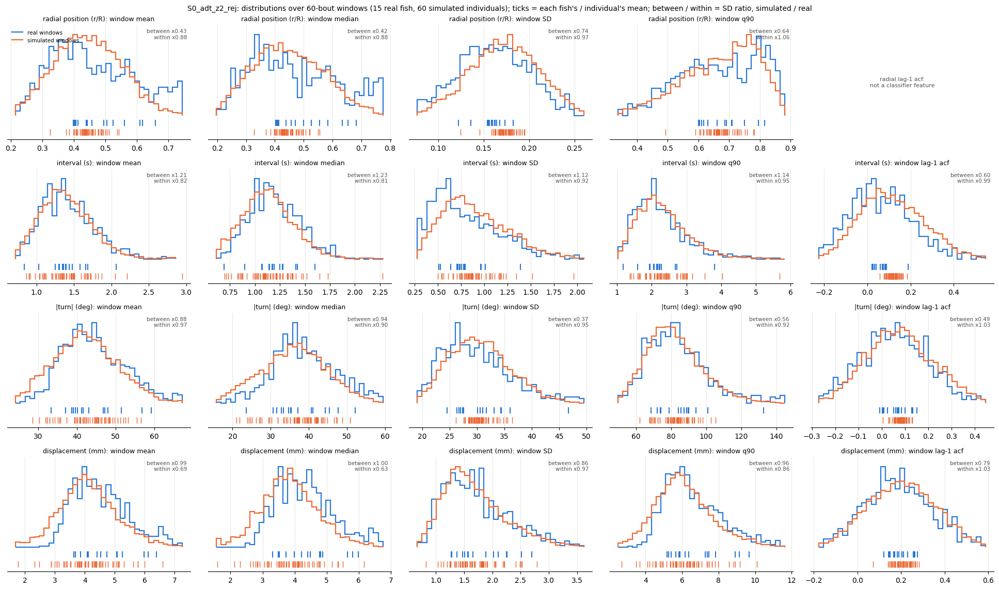

In [ ]:
# Model 3: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_3 = window_stats_grid("report_ckpts/M3", "S0_adt_z2", rej=REJ["wall_reject"], reps=4)


  S0_adt_z2_fold0.pt: 3 rollouts
  S0_adt_z2_fold1.pt: 3 rollouts
  S0_adt_z2_fold2.pt: 3 rollouts
  S0_adt_z2_fold3.pt: 3 rollouts
  S0_adt_z2_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.43     0.93  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  22.8 +/- 0.8
d2s3.5    3.95     3.12  2.64   0.0  11.0   1.0                  17.4 +/- 0.9  21.2 +/- 1.0
d4s3.5    2.60     1.63  4.68  1.17  19.0   9.0                  18.7 +/- 1.7  20.9 +/- 1.0
d6s3.5    3.00     2.18  4.62   0.8  13.0   7.0                  16.7 +/- 1.3  19.8 +/- 1.0
d8s3.5    4.46     4.12  4.97  0

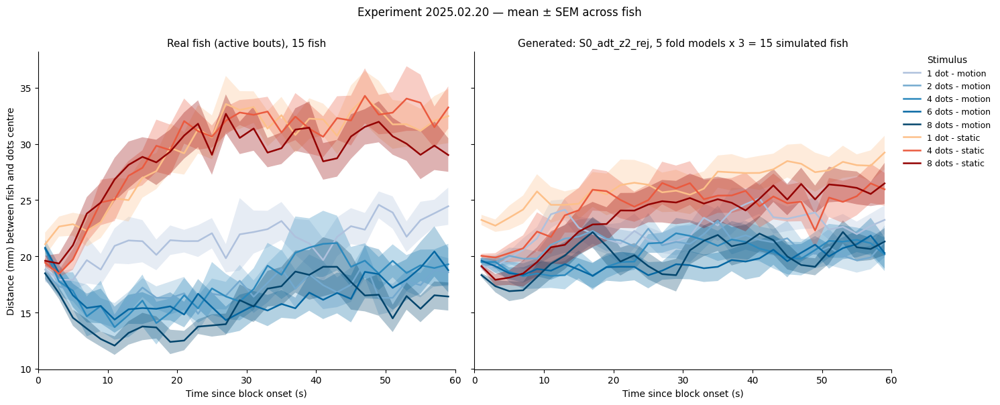

In [ ]:
# Model 3: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
# the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
st, gen_p, prof = dot_profile("report_ckpts/M3", "S0_adt_z2", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                      mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                   
REAL   

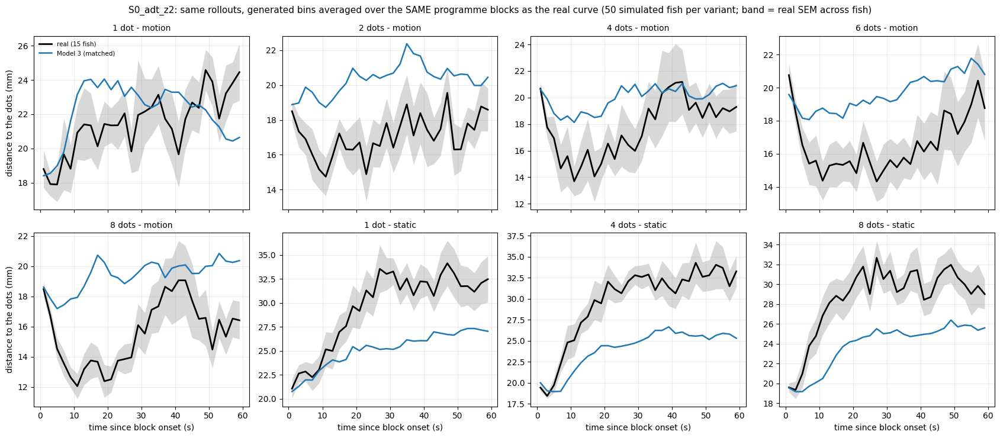

In [ ]:
# Model 3: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
# (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
varm_3, _ = profile_variants_matched("report_ckpts/M3", "S0_adt_z2", {"Model 3": {"arm": "S0_adt_z2"}}, rej=REJ["wall_reject"], r_per_model=10,
                                       show_raw=False)

In [ ]:
# Model 3: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
# (~1 mm for one dot, ~6 mm from two up).
attr_3, _ = attraction_table("report_ckpts/M3", ["S0_adt_z2"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S0_adt_z2                  
           plateau   null attraction   plateau   null attraction
cond_label                                                      
d1s3.5       22.41  23.57       1.16     22.80  22.26      -0.54
d2s3.5       17.39  23.58       6.19     21.34  22.30       0.95
d4s3.5       18.74  23.93       5.19     20.62  22.18       1.56
d6s3.5       16.69  23.12       6.43     20.30  22.15       1.85
d8s3.5       16.41  23.36       6.94     20.30  22.27       1.97


In [ ]:
# Model 3: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_3 = toward_by_n("report_ckpts/M3", ["S0_adt_z2"], rej=REJ["wall_reject"])
print(tow_3.round(2).to_string())

           real  S0_adt_z2
win    N                  
0-20 s 1   9.09       8.24
       2  13.90       9.16
       4  15.73       9.62
       6  14.50       9.02
       8  16.00      10.52
4-20 s 1   6.25       7.99
       2  12.27       9.12
       4  14.35       9.61
       6  12.79       8.67
       8  15.11      10.03


Model 3: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s             4-20 s             20-60 s            
         real gap Model 3   real gap Model 3    real gap Model 3
cond                                                            
d1s3.5  25.08      -13.44   6.64        2.28    7.55        1.51
d2s3.5  22.99      -10.65  12.94       -3.64   12.56       -2.79
d4s3.5  27.14      -15.26  15.54       -5.66   12.09       -2.01
d6s3.5  32.55      -19.36  13.80       -4.23   15.84       -5.61
d8s3.5  34.04      -20.98  14.45       -3.06   13.80       -2.89
d1s0     6.82        1.89   4.22        2.01    1.96        4.88
d4s0     4.81        4.40   1.86        4.61    1.74        5.28
d8s0     5.26        3.90   2.63        3.73    2.39        5.00

turn size |Δθ| (deg): real fish (mean over held-out fish) and each model's gap = model - real (p

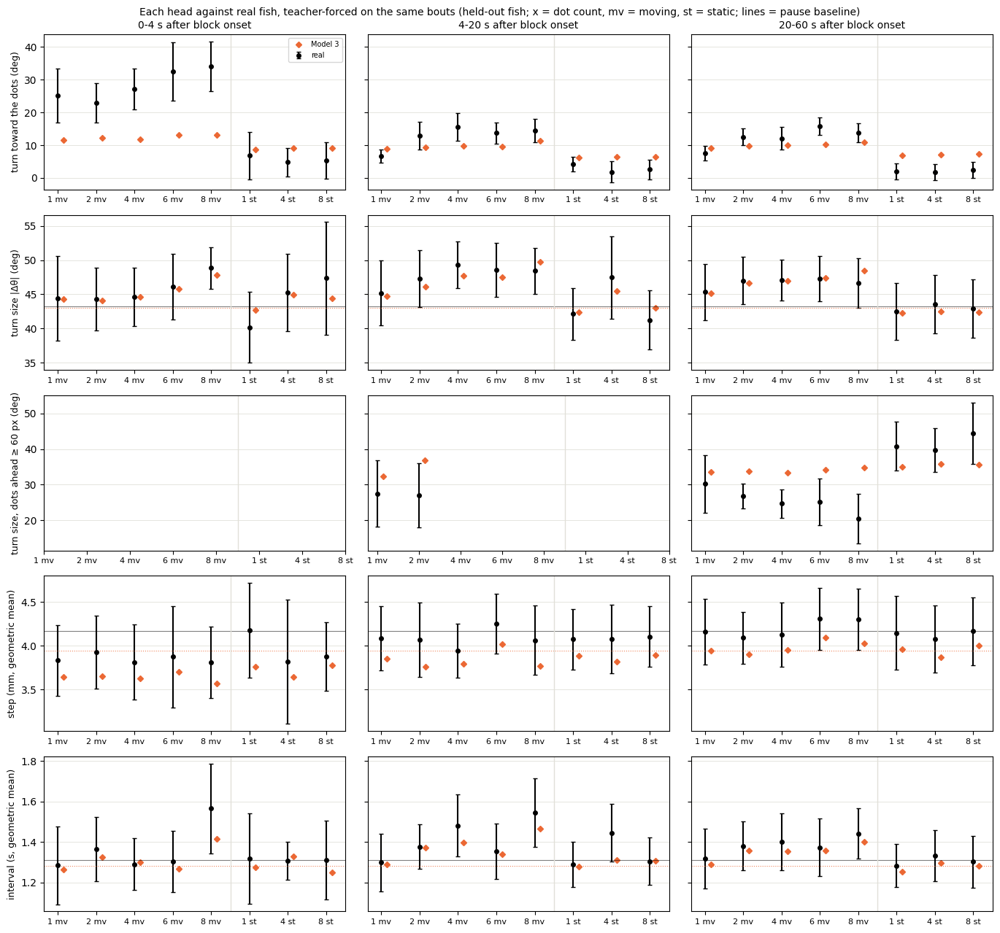

In [ ]:
# Model 3: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_3, hg_3 = head_gaps({"Model 3": ("report_ckpts/M3", "S0_adt_z2")}, rej=REJ["wall_reject"])

#### Model 3 — seed 101

XX — not trained at seed 101 (optional)

<a id="model-4"></a>
### Model 4

**Change:** + count × bearing and moving × bearing (S4i code)

The response to the dots appears (dip 0.9 → 2.1 mm, static error 2.8 → 1.1); the AUC change is within noise. Seed 0 is shown on per-block streams (key 20f); key '4' is the same checkpoint on the old stream (identical likelihood and AUC), used only for the 3 → 4 step.

#### Model 4 — seed 0 (key `20f`)

In [ ]:
# Model 20f: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M20f/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_20f = _l[_l.arm == "S4i_adt_z2"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_20f.index = ["turn", "displacement", "interval", "joint"]
print(lik_20f.round(3).to_string())

turn             7.652
displacement     4.496
interval         1.217
joint           13.366


In [ ]:
# Model 20f: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_20f, c2st_20f = run(ckpt_dir="report_ckpts/M20f", arms="S4i_adt_z2", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2'] -> writing panelB_model1_rej_S4i_adt_z2.csv / c2st_model1_rej_S4i_adt_z2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2.csv  (15 rows) in 592s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_rej
abs_dtheta_w1                   8.7680
symbol_js                       0.0125
dt_w1                           0.3823
dist_w1                         3.8186
trans_js                        0.0144
acf_l2                          0.0500
runlen_w1                       0.1745
bigram_H_gap                    0.1132
tuning_mse                      0.0200
following_gap_h                 0.0336
following_gap_static_h          0.0199
dot_dist_w1                    1

In [ ]:
# Model 20f: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M20f", "S4i_adt_z2", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_20f = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_20f.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.667            0.025      0.627         0.028
matched to the real runs (same bouts, 1:1)            0.669            0.024      0.618         0.029



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.448         0.088        0.043          0.491         0.882
                      median           0.449       0.447         0.098        0.048          0.486         0.892
                      SD               0.159       0.177         0.015        0.012          0.749         0.960
                      q90              0.679       0.702         0.074        0.053

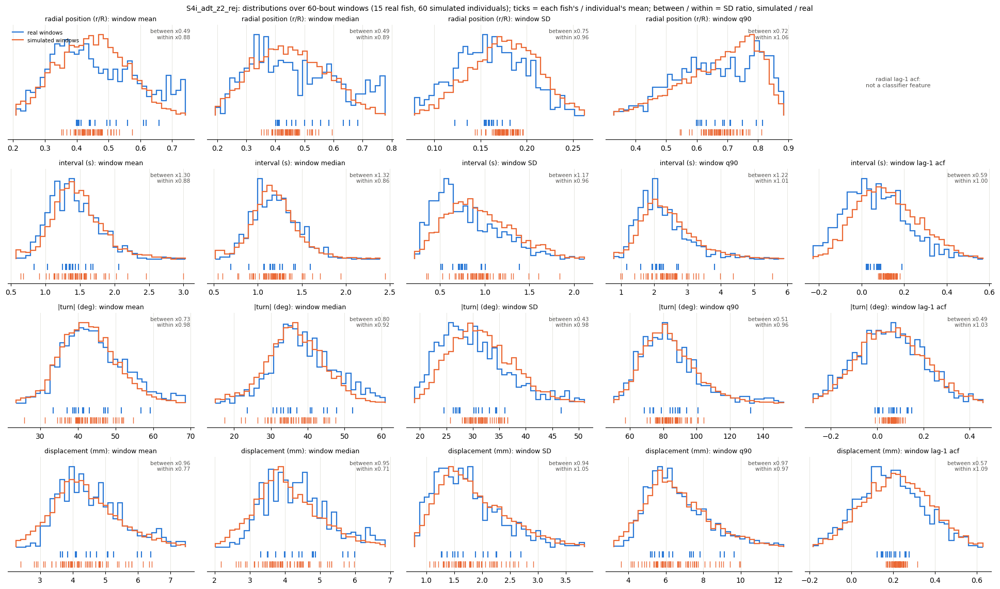

In [ ]:
# Model 20f: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_20f = window_stats_grid("report_ckpts/M20f", "S4i_adt_z2", rej=REJ["wall_reject"], reps=4)


  S4i_adt_z2_fold0.pt: 3 rollouts
  S4i_adt_z2_fold1.pt: 3 rollouts
  S4i_adt_z2_fold2.pt: 3 rollouts
  S4i_adt_z2_fold3.pt: 3 rollouts
  S4i_adt_z2_fold4.pt: 3 rollouts
dropped 8.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.98     1.38  0.15  0.37   3.0   5.0                  22.3 +/- 0.9  20.9 +/- 0.7
d2s3.5    2.06     1.66  2.64   1.9  11.0  13.0                  17.4 +/- 0.9  18.9 +/- 1.0
d4s3.5    1.49     0.98  4.68   2.1  19.0   7.0                  18.7 +/- 1.7  19.4 +/- 0.8
d6s3.5    1.70     1.24  4.62  2.64  13.0   9.0                  16.7 +/- 1.3  17.9 +/- 0.7
d8s3.5    2.52     2.49  4.9

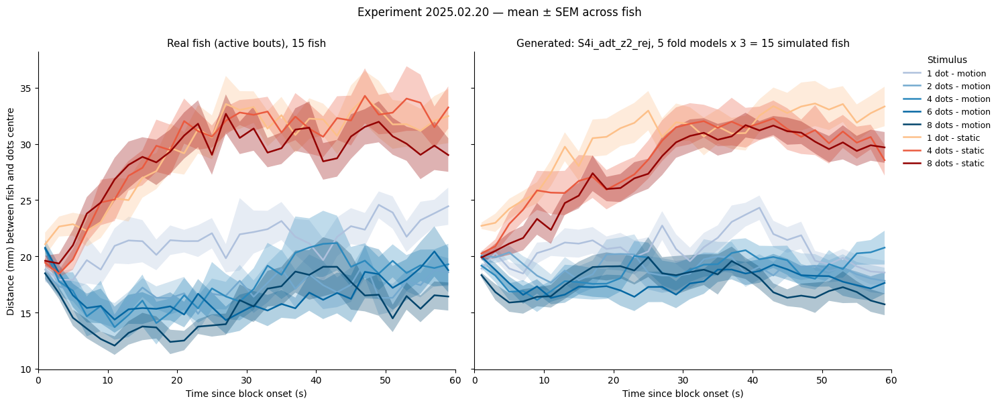

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 20f: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M20f", "S4i_adt_z2", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

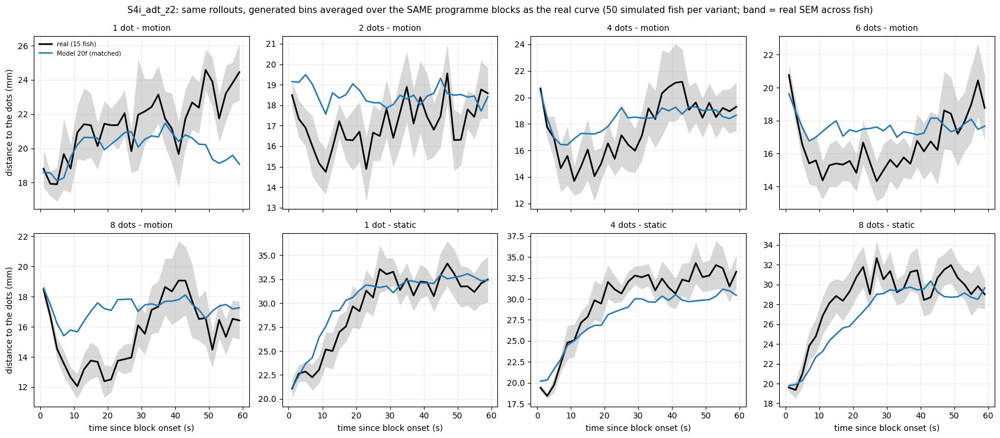

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 20f: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_20f, _ = profile_variants_matched("report_ckpts/M20f", "S4i_adt_z2", {"Model 20f": {"arm": "S4i_adt_z2"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 20f: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_20f, _ = attraction_table("report_ckpts/M20f", ["S4i_adt_z2"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2                  
           plateau   null attraction    plateau   null attraction
cond_label                                                       
d1s3.5       22.41  23.57       1.16      21.18  22.22       1.04
d2s3.5       17.39  23.58       6.19      18.95  22.23       3.28
d4s3.5       18.74  23.93       5.19      19.71  22.34       2.63
d6s3.5       16.69  23.12       6.43      18.33  22.09       3.76
d8s3.5       16.41  23.36       6.94      18.08  22.17       4.10


In [ ]:
# Model 20f: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_20f = toward_by_n("report_ckpts/M20f", ["S4i_adt_z2"], rej=REJ["wall_reject"])
print(tow_20f.round(2).to_string())

           real  S4i_adt_z2
win    N                   
0-20 s 1   9.09       10.09
       2  13.90       10.92
       4  15.73       12.43
       6  14.50       12.57
       8  16.00       14.05
4-20 s 1   6.25        9.58
       2  12.27       10.80
       4  14.35       11.96
       6  12.79       12.08
       8  15.11       13.30


Model 20f: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 20f   real gap Model 20f    real gap Model 20f
cond                                                                  
d1s3.5  25.08        -11.00   6.64          3.85    7.55          2.73
d2s3.5  22.99         -7.53  12.94         -1.95   12.56         -1.40
d4s3.5  27.14        -10.24  15.54         -3.35   12.09          0.12
d6s3.5  32.55        -16.20  13.80         -1.05   15.84         -3.03
d8s3.5  34.04        -14.61  14.45         -0.04   13.80          0.03
d1s0     6.82         -4.19   4.22         -2.53    1.96          0.18
d4s0     4.81         -1.55   1.86          0.53    1.74          2.08
d8s0     5.26         -2.47   2.63          0.73    2.39          1.67

turn size |Δθ| (deg): real f

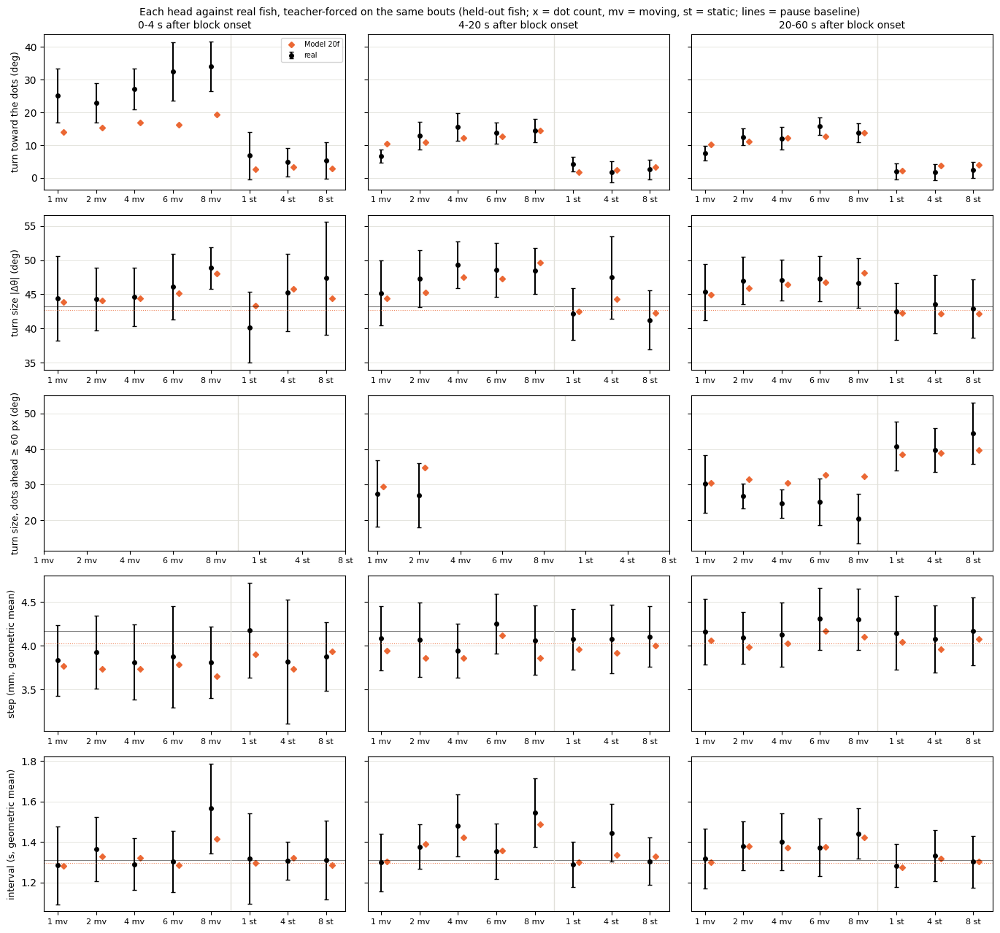

In [ ]:
# Model 20f: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_20f, hg_20f = head_gaps({"Model 20f": ("report_ckpts/M20f", "S4i_adt_z2")}, rej=REJ["wall_reject"])

#### Model 4 — seed 101 (key `30a`)

In [ ]:
# Model 30a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M30a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_30a = _l[_l.arm == "S4i_adt_z2"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_30a.index = ["turn", "displacement", "interval", "joint"]
print(lik_30a.round(3).to_string())

turn             7.653
displacement     4.492
interval         1.211
joint           13.356


In [ ]:
# Model 30a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_30a, c2st_30a = run(ckpt_dir="report_ckpts/M30a", arms="S4i_adt_z2", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2'] -> writing panelB_model1_rej_S4i_adt_z2.csv / c2st_model1_rej_S4i_adt_z2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2.csv  (15 rows) in 661s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_rej
abs_dtheta_w1                   9.1707
symbol_js                       0.0147
dt_w1                           0.3560
dist_w1                         4.0135
trans_js                        0.0159
acf_l2                          0.0447
runlen_w1                       0.1687
bigram_H_gap                    0.1236
tuning_mse                      0.0195
following_gap_h                 0.0366
following_gap_static_h          0.0197
dot_dist_w1                    1

In [ ]:
# Model 30a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M30a", "S4i_adt_z2", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_30a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_30a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.705            0.015      0.677         0.015
matched to the real runs (same bouts, 1:1)            0.703            0.016      0.676         0.016



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.458         0.088        0.036          0.411         0.915
                      median           0.449       0.456         0.098        0.039          0.402         0.923
                      SD               0.159       0.177         0.015        0.011          0.701         0.997
                      q90              0.679       0.714         0.074        0.044

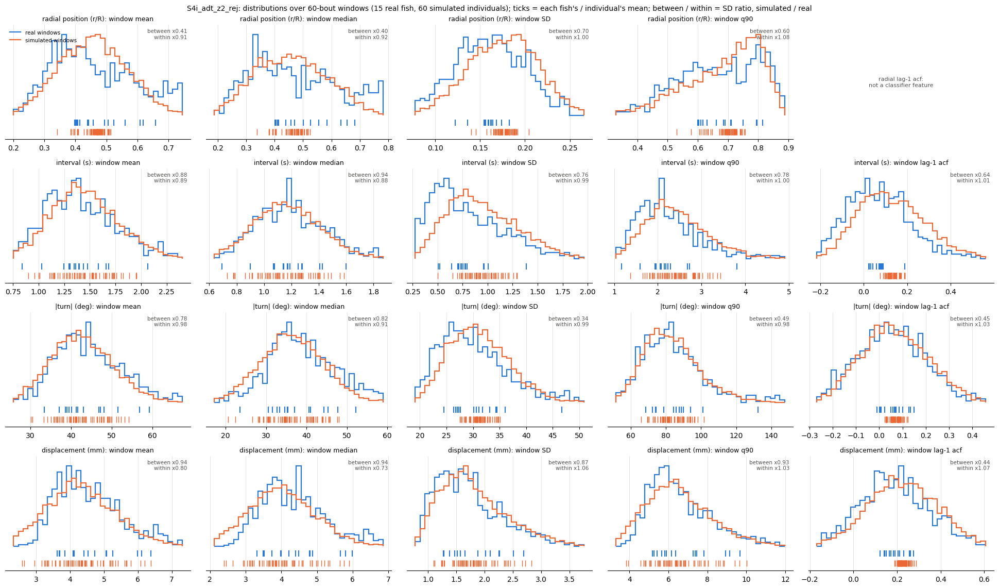

In [ ]:
# Model 30a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_30a = window_stats_grid("report_ckpts/M30a", "S4i_adt_z2", rej=REJ["wall_reject"], reps=4)


  S4i_adt_z2_fold0.pt: 3 rollouts
  S4i_adt_z2_fold1.pt: 3 rollouts
  S4i_adt_z2_fold2.pt: 3 rollouts
  S4i_adt_z2_fold3.pt: 3 rollouts
  S4i_adt_z2_fold4.pt: 3 rollouts
dropped 11.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.21     1.51  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  20.1 +/- 1.0
d2s3.5    1.71     1.37  2.64  1.96  11.0  11.0                  17.4 +/- 0.9  18.7 +/- 0.8
d4s3.5    1.87     1.07  4.68  2.92  19.0   9.0                  18.7 +/- 1.7  18.8 +/- 1.1
d6s3.5    1.60     1.16  4.62  3.15  13.0  11.0                  16.7 +/- 1.3  17.8 +/- 0.9
d8s3.5    2.18     2.19  4.

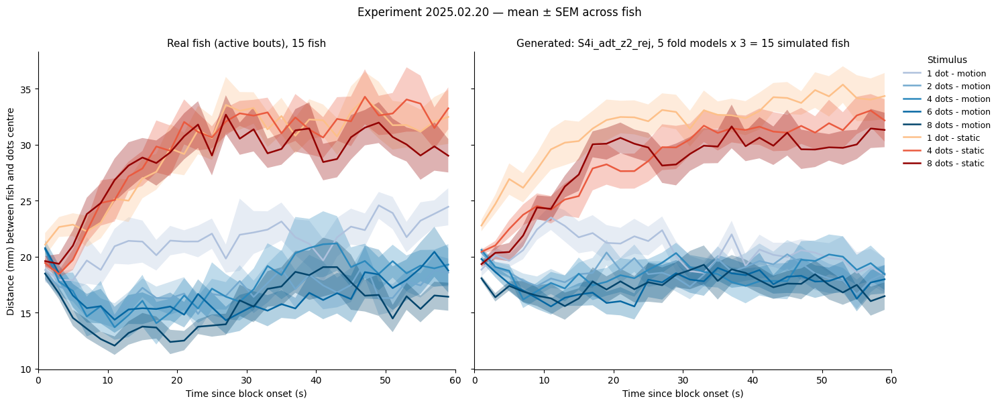

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M30a", "S4i_adt_z2", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

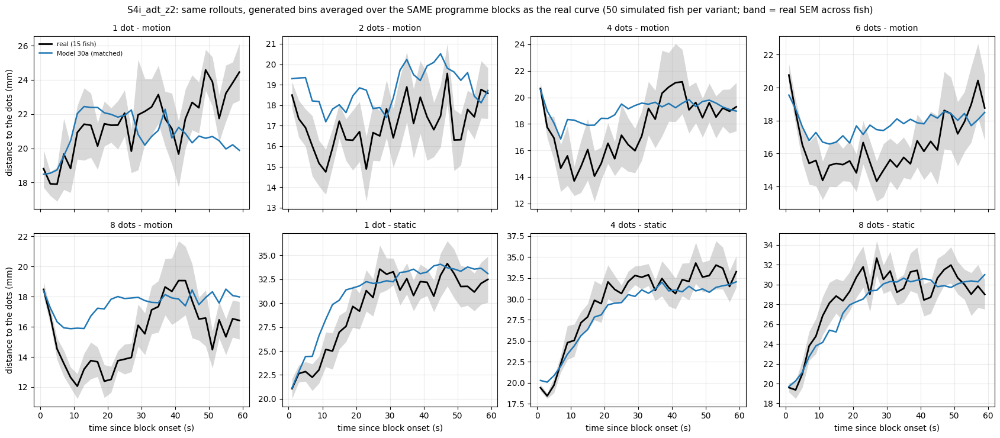

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_30a, _ = profile_variants_matched("report_ckpts/M30a", "S4i_adt_z2", {"Model 30a": {"arm": "S4i_adt_z2"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_30a, _ = attraction_table("report_ckpts/M30a", ["S4i_adt_z2"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2                  
           plateau   null attraction    plateau   null attraction
cond_label                                                       
d1s3.5       22.41  23.57       1.16      20.39  22.77       2.38
d2s3.5       17.39  23.58       6.19      18.62  22.31       3.69
d4s3.5       18.74  23.93       5.19      19.04  22.36       3.32
d6s3.5       16.69  23.12       6.43      18.19  22.25       4.06
d8s3.5       16.41  23.36       6.94      17.70  22.35       4.65


In [ ]:
# Model 30a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_30a = toward_by_n("report_ckpts/M30a", ["S4i_adt_z2"], rej=REJ["wall_reject"])
print(tow_30a.round(2).to_string())

           real  S4i_adt_z2
win    N                   
0-20 s 1   9.09        9.51
       2  13.90       10.46
       4  15.73       11.97
       6  14.50       12.01
       8  16.00       13.84
4-20 s 1   6.25        9.16
       2  12.27       10.19
       4  14.35       11.72
       6  12.79       11.41
       8  15.11       13.11


Model 30a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 30a   real gap Model 30a    real gap Model 30a
cond                                                                  
d1s3.5  25.08        -12.17   6.64          3.28    7.55          2.46
d2s3.5  22.99         -8.24  12.94         -2.56   12.56         -1.90
d4s3.5  27.14        -11.88  15.54         -3.77   12.09         -0.49
d6s3.5  32.55        -17.35  13.80         -1.52   15.84         -3.40
d8s3.5  34.04        -16.46  14.45         -0.14   13.80         -0.59
d1s0     6.82         -4.55   4.22         -2.62    1.96          0.36
d4s0     4.81         -2.25   1.86          0.09    1.74          1.65
d8s0     5.26         -2.55   2.63          0.26    2.39          1.56

turn size |Δθ| (deg): real f

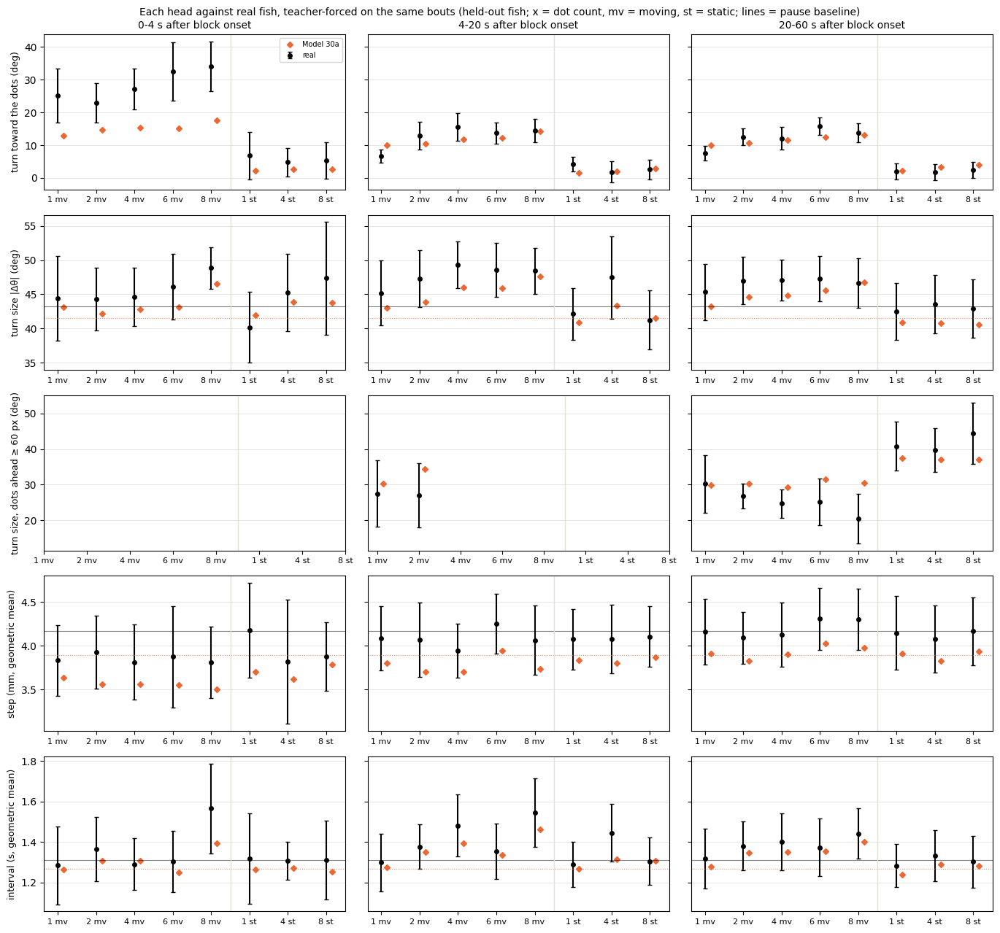

In [ ]:
# Model 30a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_30a, hg_30a = head_gaps({"Model 30a": ("report_ckpts/M30a", "S4i_adt_z2")}, rej=REJ["wall_reject"])

<a id="m25d"></a>
### 25d

**Change:** + ×3 turn weight on far moving bouts

The one component that helps on its own: grading +1.7 | +1.9 mm and moving error −0.3 | −0.4 replicate at both seeds; matched AUC −0.02 | −0.03.

#### 25d — seed 0 (key `25d`)

In [ ]:
# Model 25d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M25d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_25d = _l[_l.arm == "S4i_adt_z2_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_25d.index = ["turn", "displacement", "interval", "joint"]
print(lik_25d.round(3).to_string())

turn             7.649
displacement     4.493
interval         1.196
joint           13.338


In [ ]:
# Model 25d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_25d, c2st_25d = run(ckpt_dir="report_ckpts/M25d", arms="S4i_adt_z2_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2_w3ft'] -> writing panelB_model1_rej_S4i_adt_z2_w3ft.csv / c2st_model1_rej_S4i_adt_z2_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2_w3ft.csv  (15 rows) in 2081s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_w3ft_rej
abs_dtheta_w1                        8.5662
symbol_js                            0.0113
dt_w1                                0.4009
dist_w1                              3.8659
trans_js                             0.0130
acf_l2                               0.0472
runlen_w1                            0.1630
bigram_H_gap                         0.1081
tuning_mse                           0.0193
following_gap_h                      0.

In [ ]:
# Model 25d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M25d", "S4i_adt_z2_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_25d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_25d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.650            0.027      0.606         0.028
matched to the real runs (same bouts, 1:1)            0.648            0.026      0.589         0.028



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.456         0.088        0.048          0.543         0.910
                      median           0.449       0.456         0.098        0.051          0.524         0.916
                      SD               0.159       0.174         0.015        0.012          0.802         0.998
                      q90              0.679       0.705         0.074        0.059

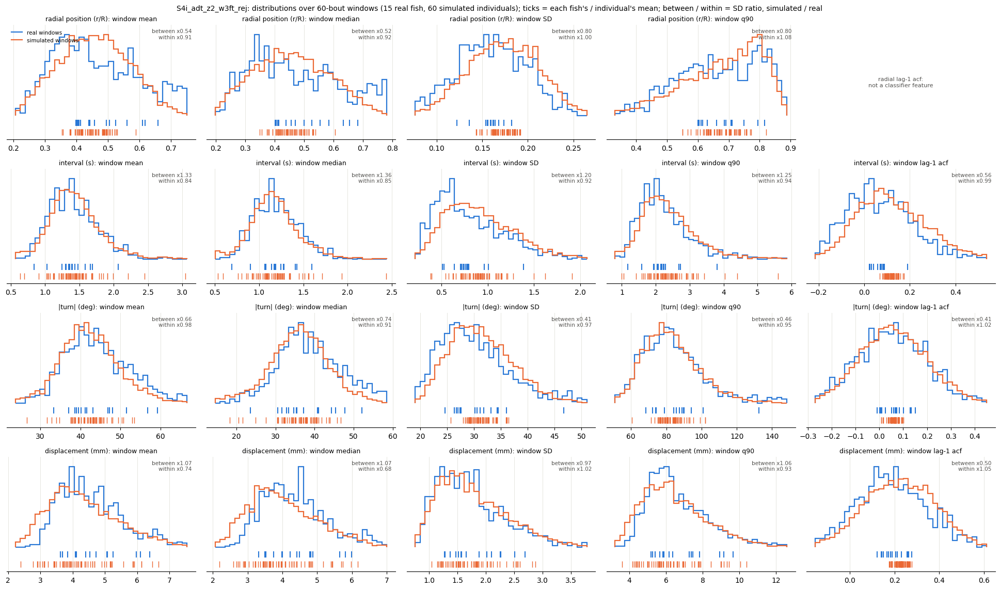

In [ ]:
# Model 25d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_25d = window_stats_grid("report_ckpts/M25d", "S4i_adt_z2_w3ft", rej=REJ["wall_reject"], reps=4)


  S4i_adt_z2_w3ft_fold0.pt: 3 rollouts
  S4i_adt_z2_w3ft_fold1.pt: 3 rollouts
  S4i_adt_z2_w3ft_fold2.pt: 3 rollouts
  S4i_adt_z2_w3ft_fold3.pt: 3 rollouts
  S4i_adt_z2_w3ft_fold4.pt: 3 rollouts
dropped 10.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.11     1.46  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  20.5 +/- 1.0
d2s3.5    2.20     1.83  2.64  1.39  11.0  19.0                  17.4 +/- 0.9  18.9 +/- 0.6
d4s3.5    1.38     0.80  4.68  3.37  19.0  15.0                  18.7 +/- 1.7  17.6 +/- 1.0
d6s3.5    1.69     1.18  4.62  3.03  13.0  19.0                  16.7 +/- 1.3  18.3 +/- 0.9
d8

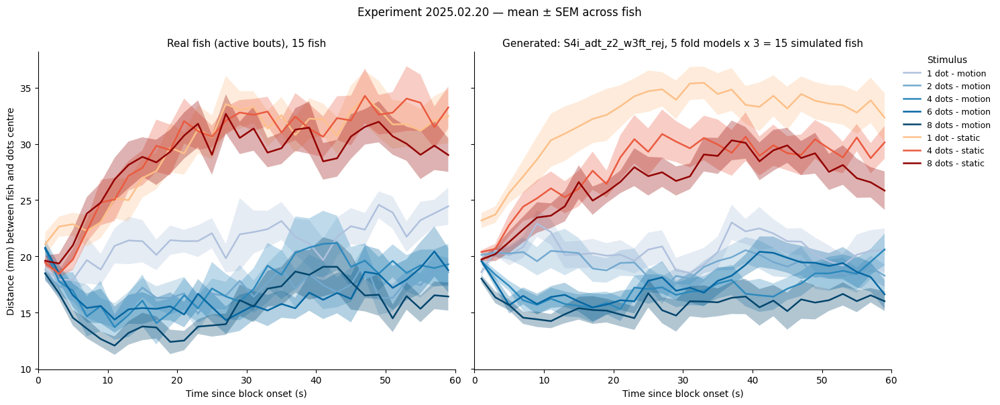

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 25d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M25d", "S4i_adt_z2_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

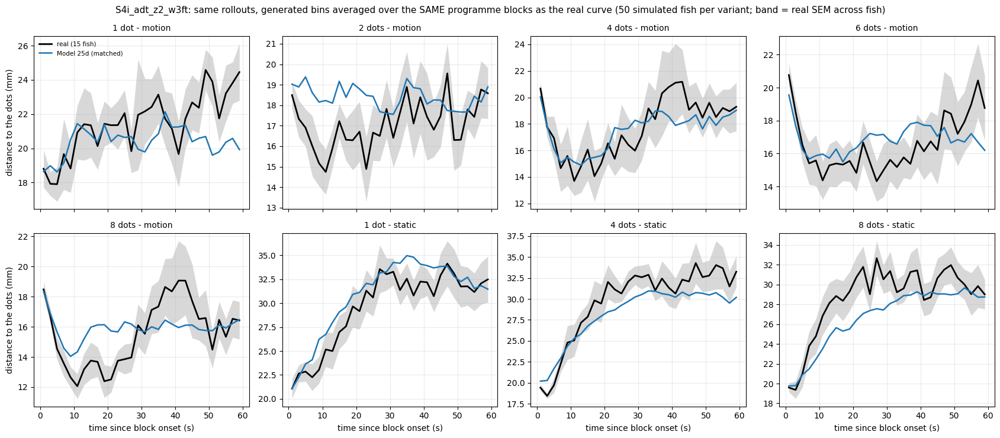

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 25d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_25d, _ = profile_variants_matched("report_ckpts/M25d", "S4i_adt_z2_w3ft", {"Model 25d": {"arm": "S4i_adt_z2_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 25d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_25d, _ = attraction_table("report_ckpts/M25d", ["S4i_adt_z2_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2_w3ft                  
           plateau   null attraction         plateau   null attraction
cond_label                                                            
d1s3.5       22.41  23.57       1.16           21.22  22.41       1.19
d2s3.5       17.39  23.58       6.19           18.97  22.33       3.36
d4s3.5       18.74  23.93       5.19           18.40  22.67       4.27
d6s3.5       16.69  23.12       6.43           17.94  22.35       4.41
d8s3.5       16.41  23.36       6.94           17.00  22.60       5.60


In [ ]:
# Model 25d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_25d = toward_by_n("report_ckpts/M25d", ["S4i_adt_z2_w3ft"], rej=REJ["wall_reject"])
print(tow_25d.round(2).to_string())

           real  S4i_adt_z2_w3ft
win    N                        
0-20 s 1   9.09            10.34
       2  13.90            12.48
       4  15.73            14.54
       6  14.50            15.07
       8  16.00            17.42
4-20 s 1   6.25             9.32
       2  12.27            11.73
       4  14.35            13.69
       6  12.79            14.02
       8  15.11            15.93


Model 25d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 25d   real gap Model 25d    real gap Model 25d
cond                                                                  
d1s3.5  25.08         -8.80   6.64          3.89    7.55          2.51
d2s3.5  22.99         -4.25  12.94         -0.46   12.56         -0.55
d4s3.5  27.14         -6.65  15.54         -1.34   12.09          1.40
d6s3.5  32.55        -11.56  13.80          1.33   15.84         -1.15
d8s3.5  34.04         -9.90  14.45          3.46   13.80          2.03
d1s0     6.82         -4.97   4.22         -3.47    1.96         -0.79
d4s0     4.81         -0.10   1.86          1.17    1.74          2.08
d8s0     5.26          1.07   2.63          1.85    2.39          2.76

turn size |Δθ| (deg): real f

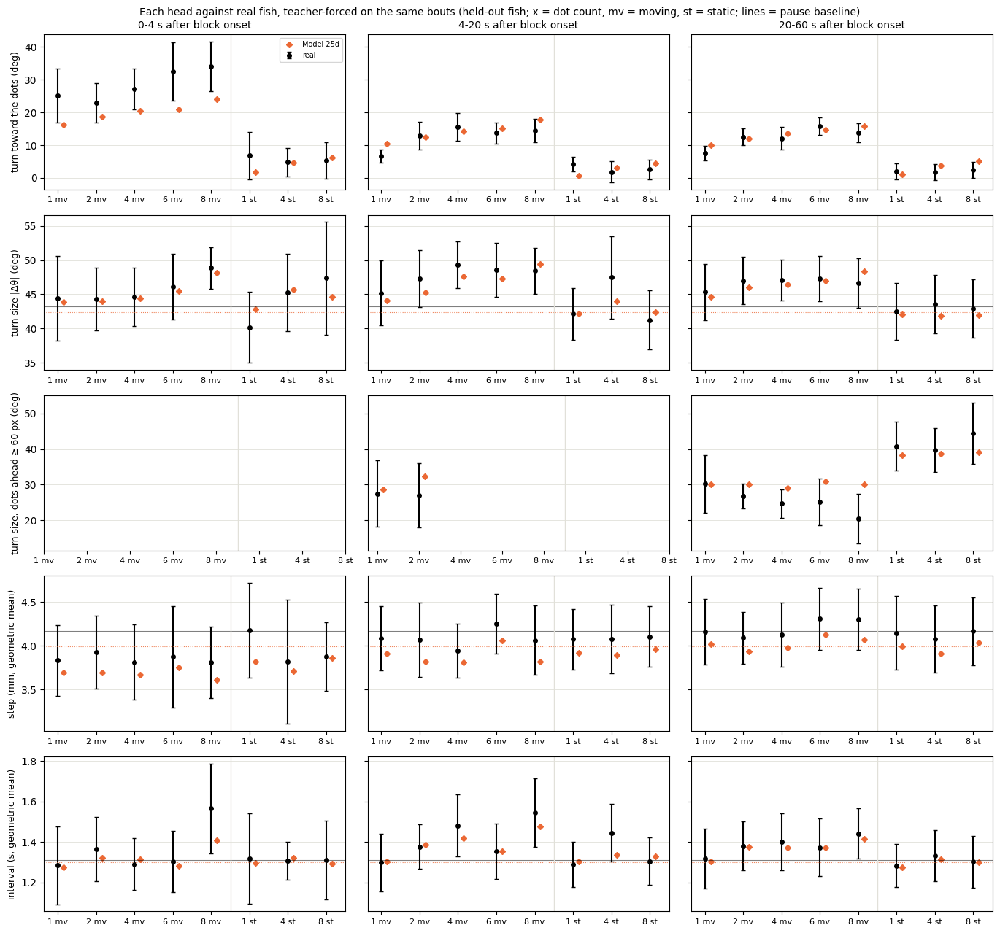

In [ ]:
# Model 25d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_25d, hg_25d = head_gaps({"Model 25d": ("report_ckpts/M25d", "S4i_adt_z2_w3ft")}, rej=REJ["wall_reject"])

#### 25d — seed 101 (key `30b`)

In [ ]:
# Model 30b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M30b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_30b = _l[_l.arm == "S4i_adt_z2_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_30b.index = ["turn", "displacement", "interval", "joint"]
print(lik_30b.round(3).to_string())

turn             7.675
displacement     4.496
interval         1.219
joint           13.390


In [ ]:
# Model 30b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_30b, c2st_30b = run(ckpt_dir="report_ckpts/M30b", arms="S4i_adt_z2_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2_w3ft'] -> writing panelB_model1_rej_S4i_adt_z2_w3ft.csv / c2st_model1_rej_S4i_adt_z2_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2_w3ft.csv  (15 rows) in 600s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_w3ft_rej
abs_dtheta_w1                        9.2541
symbol_js                            0.0161
dt_w1                                0.3684
dist_w1                              4.3677
trans_js                             0.0172
acf_l2                               0.0446
runlen_w1                            0.1737
bigram_H_gap                         0.1254
tuning_mse                           0.0197
following_gap_h                      0.0

In [ ]:
# Model 30b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M30b", "S4i_adt_z2_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_30b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_30b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.673            0.024      0.644         0.025
matched to the real runs (same bouts, 1:1)            0.673            0.022      0.641         0.023



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.451         0.088        0.033          0.380         0.930
                      median           0.449       0.449         0.098        0.036          0.364         0.932
                      SD               0.159       0.174         0.015        0.012          0.802         0.974
                      q90              0.679       0.702         0.074        0.046

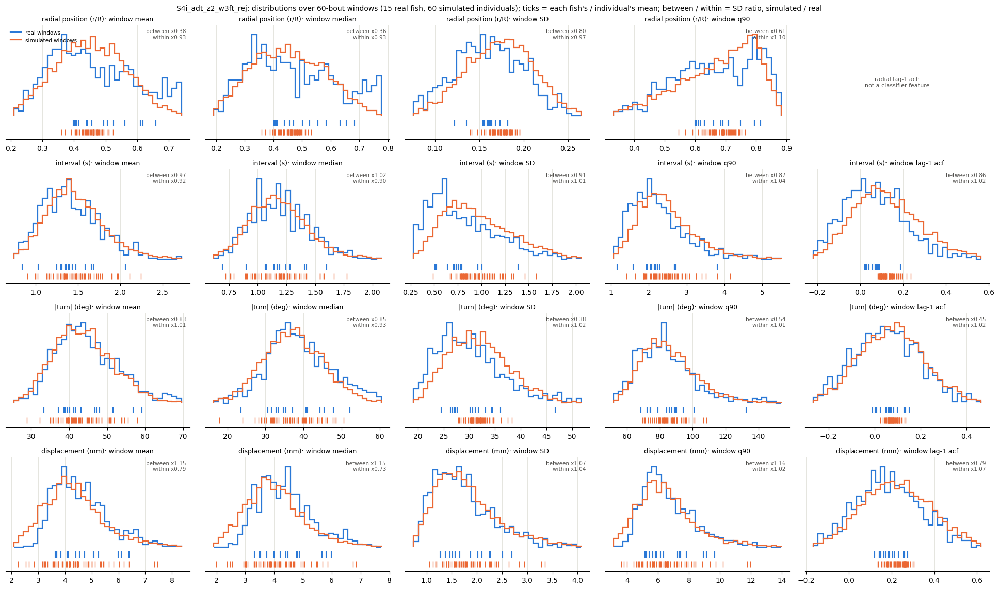

In [ ]:
# Model 30b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_30b = window_stats_grid("report_ckpts/M30b", "S4i_adt_z2_w3ft", rej=REJ["wall_reject"], reps=4)


  S4i_adt_z2_w3ft_fold0.pt: 3 rollouts
  S4i_adt_z2_w3ft_fold1.pt: 3 rollouts
  S4i_adt_z2_w3ft_fold2.pt: 3 rollouts
  S4i_adt_z2_w3ft_fold3.pt: 3 rollouts
  S4i_adt_z2_w3ft_fold4.pt: 3 rollouts
dropped 11.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.91     1.34  0.15  0.11   3.0   3.0                  22.3 +/- 0.9  21.2 +/- 0.8
d2s3.5    2.08     1.62  2.64  1.95  11.0  11.0                  17.4 +/- 0.9  19.5 +/- 1.1
d4s3.5    1.32     0.82  4.68  2.98  19.0  11.0                  18.7 +/- 1.7  17.8 +/- 0.9
d6s3.5    1.45     1.05  4.62  3.62  13.0  11.0                  16.7 +/- 1.3  18.2 +/- 1.0
d8

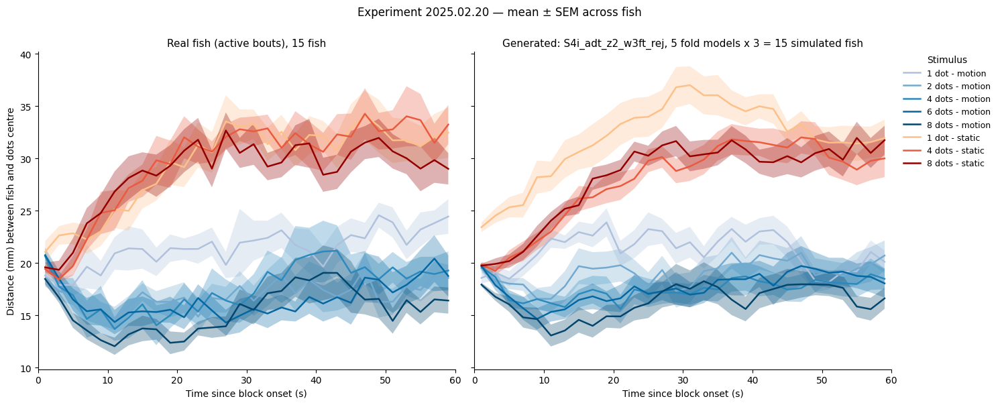

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M30b", "S4i_adt_z2_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

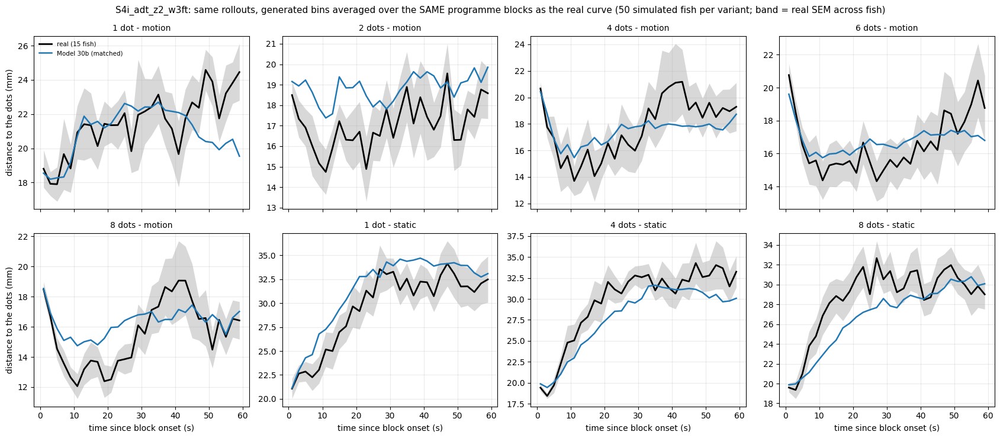

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_30b, _ = profile_variants_matched("report_ckpts/M30b", "S4i_adt_z2_w3ft", {"Model 30b": {"arm": "S4i_adt_z2_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_30b, _ = attraction_table("report_ckpts/M30b", ["S4i_adt_z2_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2_w3ft                  
           plateau   null attraction         plateau   null attraction
cond_label                                                            
d1s3.5       22.41  23.57       1.16           21.83  22.52       0.68
d2s3.5       17.39  23.58       6.19           19.71  22.38       2.67
d4s3.5       18.74  23.93       5.19           17.89  22.42       4.53
d6s3.5       16.69  23.12       6.43           17.37  22.10       4.74
d8s3.5       16.41  23.36       6.94           16.28  22.12       5.84


In [ ]:
# Model 30b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_30b = toward_by_n("report_ckpts/M30b", ["S4i_adt_z2_w3ft"], rej=REJ["wall_reject"])
print(tow_30b.round(2).to_string())

           real  S4i_adt_z2_w3ft
win    N                        
0-20 s 1   9.09             9.01
       2  13.90            11.22
       4  15.73            13.45
       6  14.50            13.61
       8  16.00            16.26
4-20 s 1   6.25             8.33
       2  12.27            10.81
       4  14.35            12.81
       6  12.79            12.70
       8  15.11            14.95


Model 30b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 30b   real gap Model 30b    real gap Model 30b
cond                                                                  
d1s3.5  25.08        -11.71   6.64          2.71    7.55          1.63
d2s3.5  22.99         -6.70  12.94         -1.55   12.56         -1.56
d4s3.5  27.14         -9.20  15.54         -2.29   12.09          0.52
d6s3.5  32.55        -14.43  13.80          0.12   15.84         -1.72
d8s3.5  34.04        -11.81  14.45          2.08   13.80          1.09
d1s0     6.82         -5.41   4.22         -3.60    1.96         -0.76
d4s0     4.81         -0.33   1.86          1.41    1.74          1.65
d8s0     5.26         -0.21   2.63          1.14    2.39          2.26

turn size |Δθ| (deg): real f

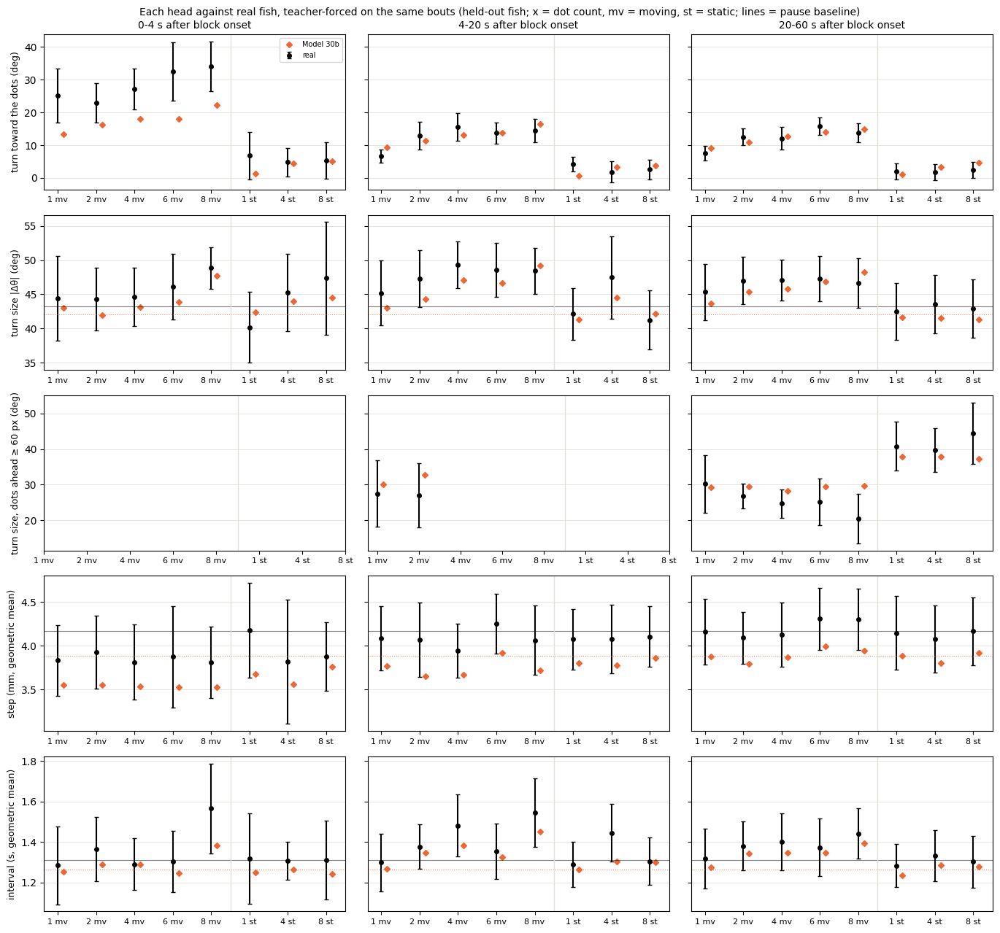

In [ ]:
# Model 30b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_30b, hg_30b = head_gaps({"Model 30b": ("report_ckpts/M30b", "S4i_adt_z2_w3ft")}, rej=REJ["wall_reject"])

<a id="m26e"></a>
### 26e — the ablation model

**Change:** + range × bearing products (S4x) and the temporal set (centred interval lags with the 10 s truncation, run clock, aligned-and-far flag)

The dip deepens at both seeds (2.7 → 3.7 | 2.7 → 3.0 mm); AUC flat at seed 0, better at seed 101. The two components only work together — see the checks below.

#### 26e — the ablation model — seed 0 (key `26e`)

In [ ]:
# Model 26e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M26e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_26e = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_26e.index = ["turn", "displacement", "interval", "joint"]
print(lik_26e.round(3).to_string())

turn             7.665
displacement     4.505
interval         1.215
joint           13.385


In [ ]:
# Model 26e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_26e, c2st_26e = run(ckpt_dir="report_ckpts/M26e", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 772s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                     8.5212
symbol_js                                         0.0117
dt_w1                                             0.4120
dist_w1                                           3.6844
trans_js                                          0.0132
acf_l2                                            0.0463
runlen_w1                    

In [ ]:
# Model 26e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M26e", "S4x_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_26e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_26e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.678            0.015      0.611         0.018
matched to the real runs (same bouts, 1:1)            0.671            0.016      0.599         0.017



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.453         0.088        0.031          0.359         0.944
                      median           0.449       0.448         0.098        0.035          0.359         0.946
                      SD               0.159       0.179         0.015        0.012          0.788         1.011
                      q90              0.679       0.712         0.074        0.043

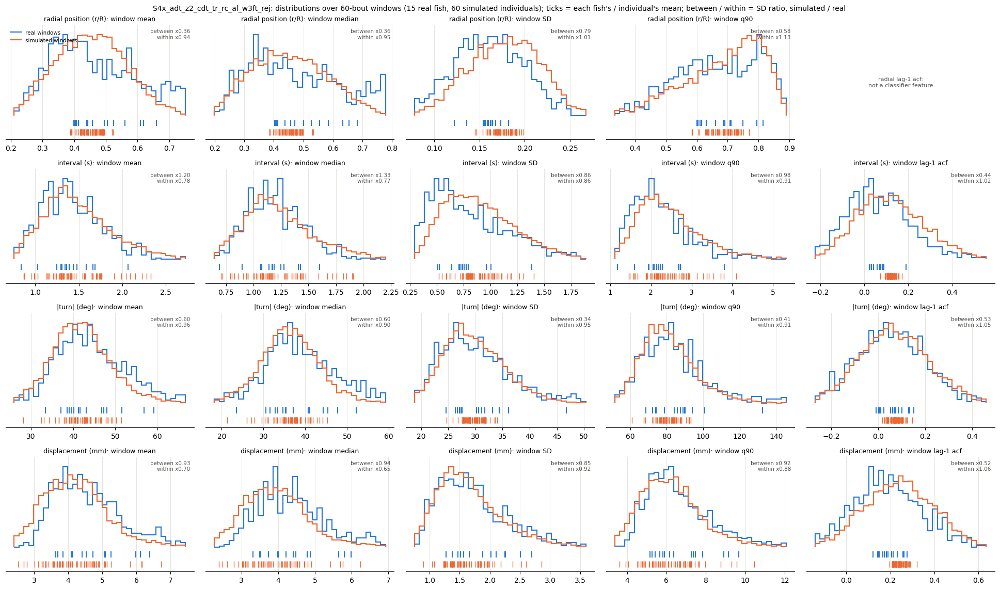

In [ ]:
# Model 26e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_26e = window_stats_grid("report_ckpts/M26e", "S4x_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 11.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.60     1.04  0.15  0.97   3.0   7.0                  22.3 +/- 0.9  22.2 +/- 0.7
d2s3.5    1.55     1.20  2.64  3.15  11.0  11.0                  17.4 +/- 0.9  19.0 +/- 0.6
d4s3.5    1.10     0.66  4.68  3.92  19.0  15.0                  18.7 +/- 1.7  17.9 +/- 0.7
d6s3.5    1.63     1.15  4.62

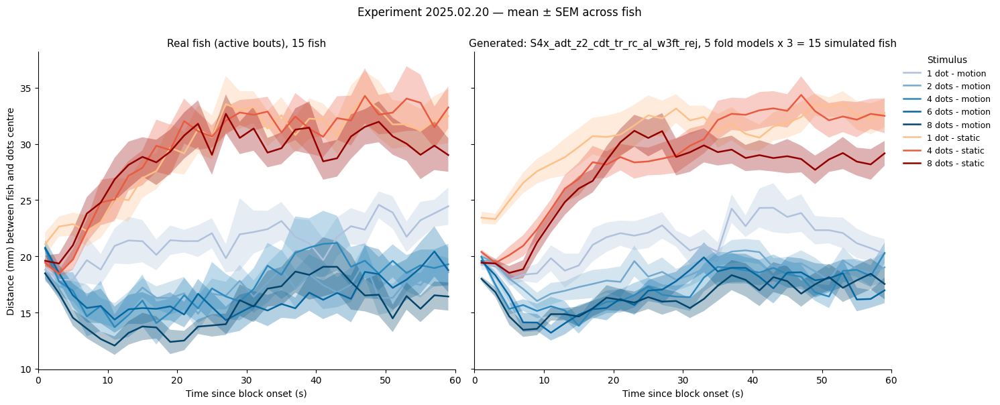

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 26e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M26e", "S4x_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

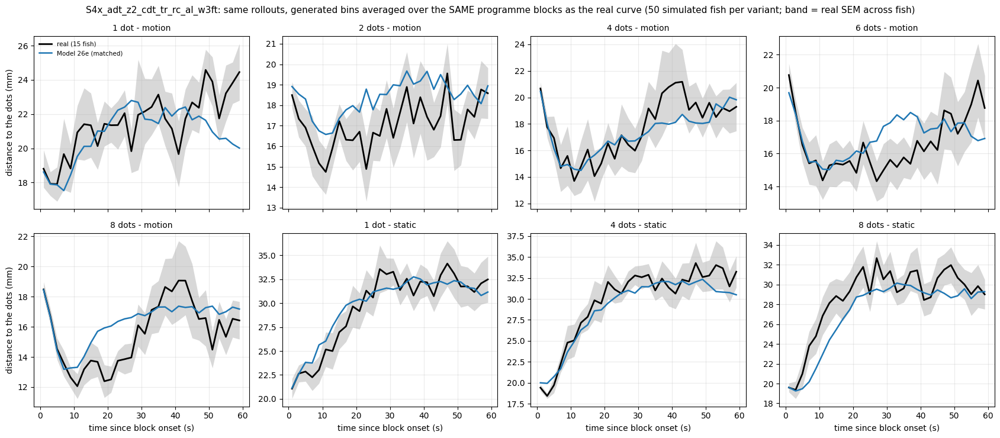

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 26e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_26e, _ = profile_variants_matched("report_ckpts/M26e", "S4x_adt_z2_cdt_tr_rc_al_w3ft", {"Model 26e": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 26e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_26e, _ = attraction_table("report_ckpts/M26e", ["S4x_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                      plateau   null attraction
cond_label                                                                         
d1s3.5       22.41  23.57       1.16                        21.49  22.79       1.30
d2s3.5       17.39  23.58       6.19                        18.99  22.36       3.37
d4s3.5       18.74  23.93       5.19                        17.58  22.28       4.70
d6s3.5       16.69  23.12       6.43                        17.40  22.29       4.89
d8s3.5       16.41  23.36       6.94                        16.79  22.23       5.43


In [ ]:
# Model 26e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_26e = toward_by_n("report_ckpts/M26e", ["S4x_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"])
print(tow_26e.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft
win    N                                     
0-20 s 1   9.09                          9.96
       2  13.90                         11.24
       4  15.73                         13.57
       6  14.50                         13.23
       8  16.00                         16.27
4-20 s 1   6.25                          9.04
       2  12.27                         10.69
       4  14.35                         12.52
       6  12.79                         12.13
       8  15.11                         14.96


Model 26e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 26e   real gap Model 26e    real gap Model 26e
cond                                                                  
d1s3.5  25.08         -9.22   6.64          3.63    7.55          2.36
d2s3.5  22.99         -6.58  12.94         -1.63   12.56         -1.23
d4s3.5  27.14         -7.35  15.54         -2.36   12.09          0.37
d6s3.5  32.55        -13.05  13.80          0.36   15.84         -2.17
d8s3.5  34.04        -11.30  14.45          1.58   13.80          1.06
d1s0     6.82         -5.38   4.22         -3.32    1.96          0.42
d4s0     4.81         -0.92   1.86          2.46    1.74          2.45
d8s0     5.26         -1.63   2.63          1.50    2.39          2.81

turn size |Δθ| (deg): real f

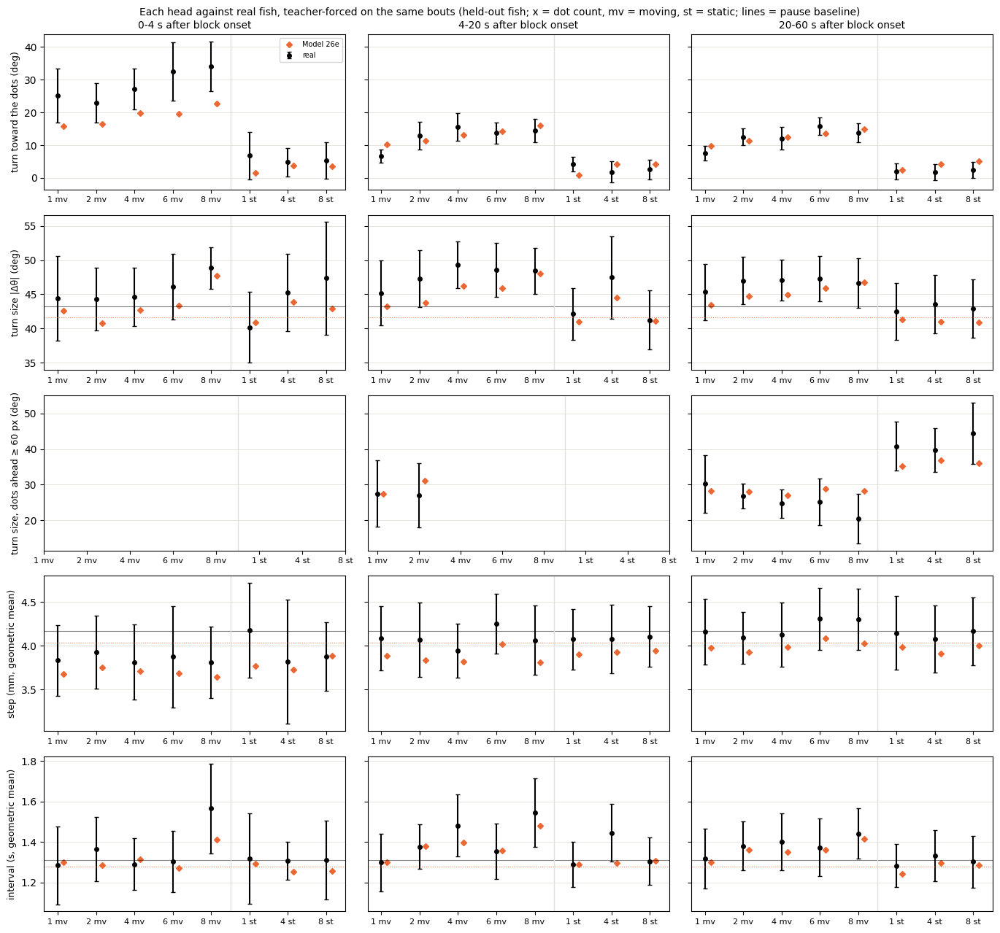

In [ ]:
# Model 26e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_26e, hg_26e = head_gaps({"Model 26e": ("report_ckpts/M26e", "S4x_adt_z2_cdt_tr_rc_al_w3ft")}, rej=REJ["wall_reject"])

#### 26e — the ablation model — seed 101 (key `30d`)

In [ ]:
# Model 30d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M30d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_30d = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_30d.index = ["turn", "displacement", "interval", "joint"]
print(lik_30d.round(3).to_string())

turn             7.668
displacement     4.497
interval         1.222
joint           13.387


In [ ]:
# Model 30d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_30d, c2st_30d = run(ckpt_dir="report_ckpts/M30d", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 734s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                     8.1119
symbol_js                                         0.0123
dt_w1                                             0.3829
dist_w1                                           3.7783
trans_js                                          0.0142
acf_l2                                            0.0474
runlen_w1                    

In [ ]:
# Model 30d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M30d", "S4x_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_30d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_30d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.664            0.027      0.586         0.034
matched to the real runs (same bouts, 1:1)            0.645            0.029      0.575         0.035



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.474         0.088        0.034          0.386         0.893
                      median           0.449       0.475         0.098        0.038          0.387         0.903
                      SD               0.159       0.182         0.015        0.010          0.615         0.937
                      q90              0.679       0.737         0.074        0.041

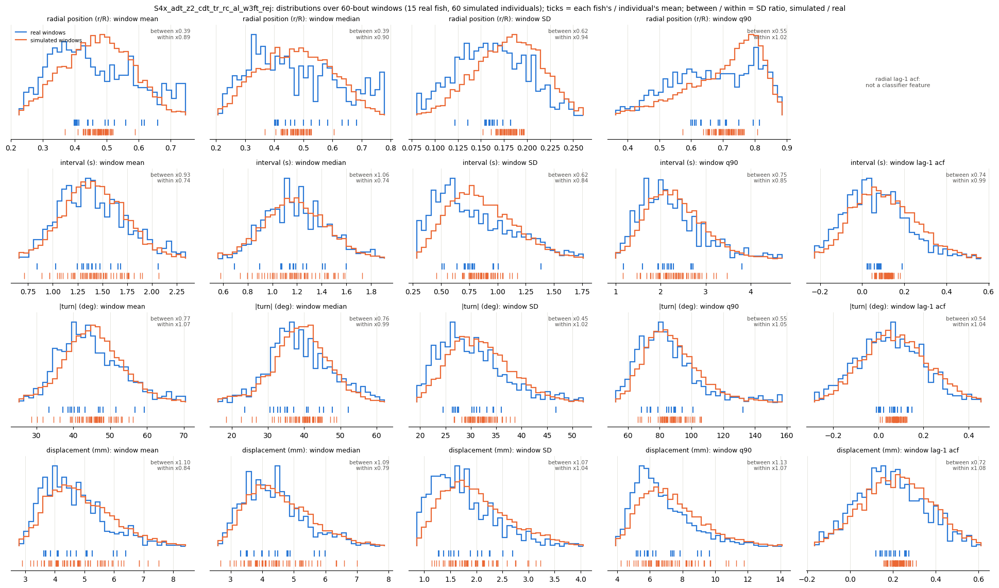

In [ ]:
# Model 30d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_30d = window_stats_grid("report_ckpts/M30d", "S4x_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 11.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.52     1.05  0.15  0.83   3.0   5.0                  22.3 +/- 0.9  21.5 +/- 0.6
d2s3.5    1.33     1.10  2.64   3.0  11.0   9.0                  17.4 +/- 0.9  18.5 +/- 0.9
d4s3.5    1.27     0.76  4.68  3.84  19.0  13.0                  18.7 +/- 1.7  18.1 +/- 0.9
d6s3.5    1.46     0.95  4.62

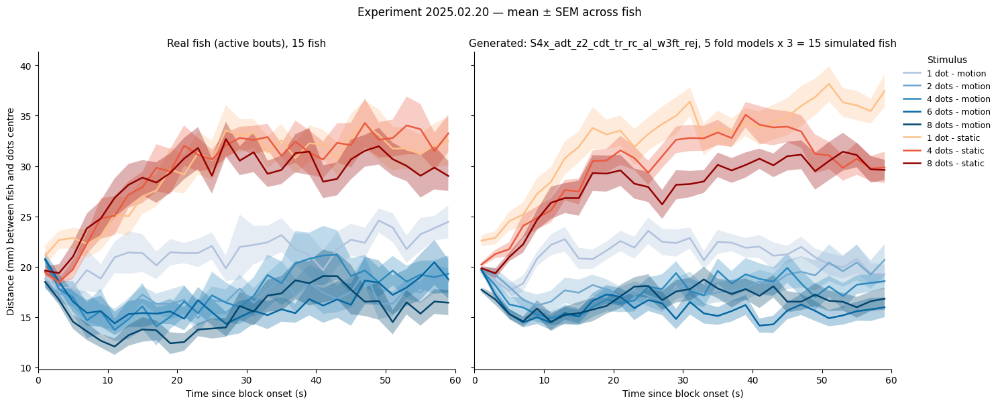

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M30d", "S4x_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

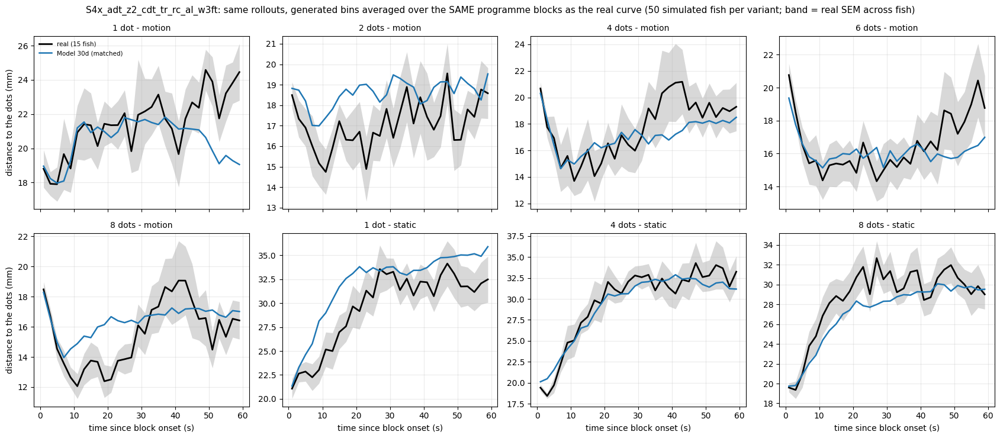

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_30d, _ = profile_variants_matched("report_ckpts/M30d", "S4x_adt_z2_cdt_tr_rc_al_w3ft", {"Model 30d": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_30d, _ = attraction_table("report_ckpts/M30d", ["S4x_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                      plateau   null attraction
cond_label                                                                         
d1s3.5       22.41  23.57       1.16                        21.53  22.84       1.31
d2s3.5       17.39  23.58       6.19                        18.80  22.43       3.63
d4s3.5       18.74  23.93       5.19                        17.85  22.76       4.91
d6s3.5       16.69  23.12       6.43                        16.21  22.62       6.41
d8s3.5       16.41  23.36       6.94                        17.12  22.89       5.77


In [ ]:
# Model 30d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_30d = toward_by_n("report_ckpts/M30d", ["S4x_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"])
print(tow_30d.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft
win    N                                     
0-20 s 1   9.09                         10.02
       2  13.90                         12.02
       4  15.73                         13.74
       6  14.50                         14.52
       8  16.00                         16.44
4-20 s 1   6.25                          9.00
       2  12.27                         11.57
       4  14.35                         12.80
       6  12.79                         13.69
       8  15.11                         15.33


Model 30d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 30d   real gap Model 30d    real gap Model 30d
cond                                                                  
d1s3.5  25.08         -9.78   6.64          3.66    7.55          2.46
d2s3.5  22.99         -5.50  12.94         -0.95   12.56         -1.23
d4s3.5  27.14         -7.55  15.54         -2.33   12.09          0.53
d6s3.5  32.55        -13.40  13.80          1.14   15.84         -1.78
d8s3.5  34.04        -10.32  14.45          2.21   13.80          1.10
d1s0     6.82         -6.03   4.22         -4.30    1.96         -1.49
d4s0     4.81         -1.89   1.86          0.27    1.74          1.79
d8s0     5.26         -1.49   2.63          0.63    2.39          2.59

turn size |Δθ| (deg): real f

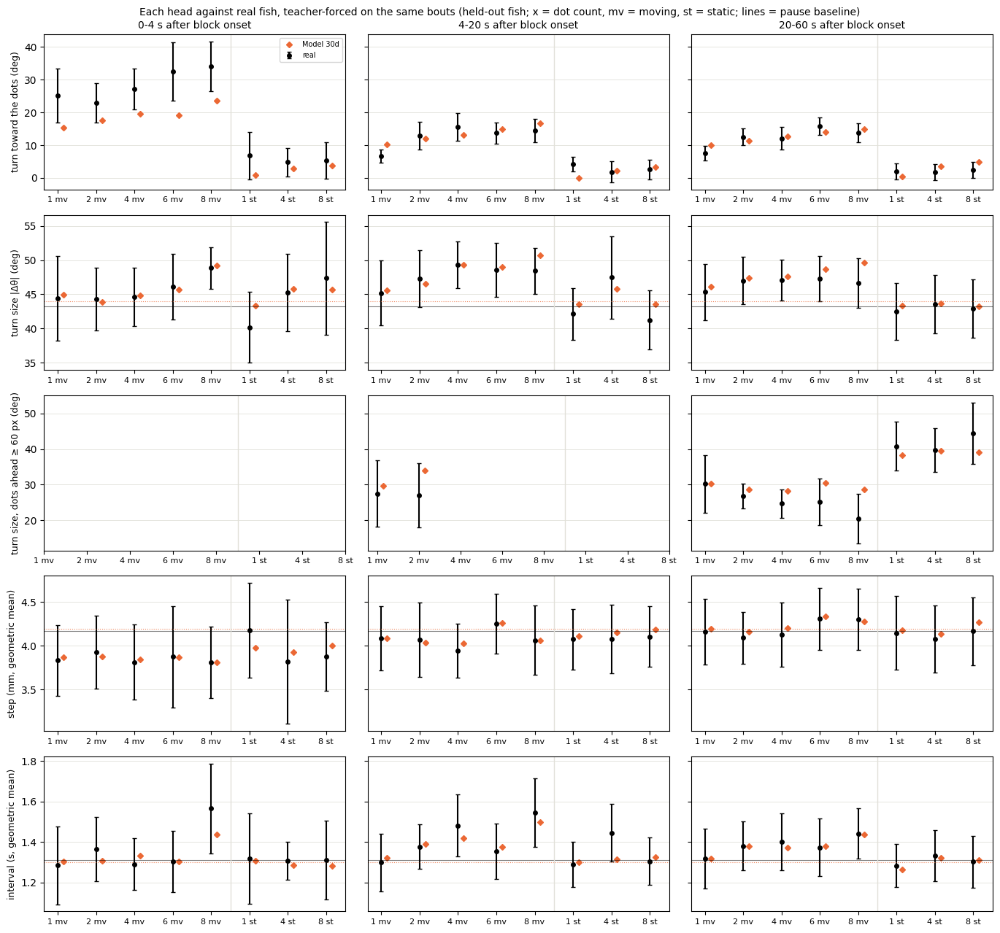

In [ ]:
# Model 30d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_30d, hg_30d = head_gaps({"Model 30d": ("report_ckpts/M30d", "S4x_adt_z2_cdt_tr_rc_al_w3ft")}, rej=REJ["wall_reject"])

<a id="m29a"></a>
#### Check: 29a — range products alone

**Change:** 25d + S4x

Worse at both seeds (matched +0.07 | +0.08).

##### Check: 29a — range products alone — seed 0 (key `29a`)

In [ ]:
# Model 29a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M29a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_29a = _l[_l.arm == "S4x_adt_z2_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_29a.index = ["turn", "displacement", "interval", "joint"]
print(lik_29a.round(3).to_string())

turn             7.653
displacement     4.488
interval         1.218
joint           13.360


In [ ]:
# Model 29a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_29a, c2st_29a = run(ckpt_dir="report_ckpts/M29a", arms="S4x_adt_z2_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_w3ft.csv / c2st_model1_rej_S4x_adt_z2_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_w3ft.csv  (15 rows) in 602s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_w3ft_rej
abs_dtheta_w1                        8.2307
symbol_js                            0.0113
dt_w1                                0.4132
dist_w1                              3.6892
trans_js                             0.0128
acf_l2                               0.0501
runlen_w1                            0.1653
bigram_H_gap                         0.1080
tuning_mse                           0.0201
following_gap_h                      0.0

In [ ]:
# Model 29a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M29a", "S4x_adt_z2_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_29a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_29a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.733            0.019      0.678         0.022
matched to the real runs (same bouts, 1:1)            0.722            0.020      0.662         0.025



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.466         0.088        0.031          0.357         0.882
                      median           0.449       0.466         0.098        0.035          0.354         0.901
                      SD               0.159       0.180         0.015        0.009          0.553         0.953
                      q90              0.679       0.721         0.074        0.038

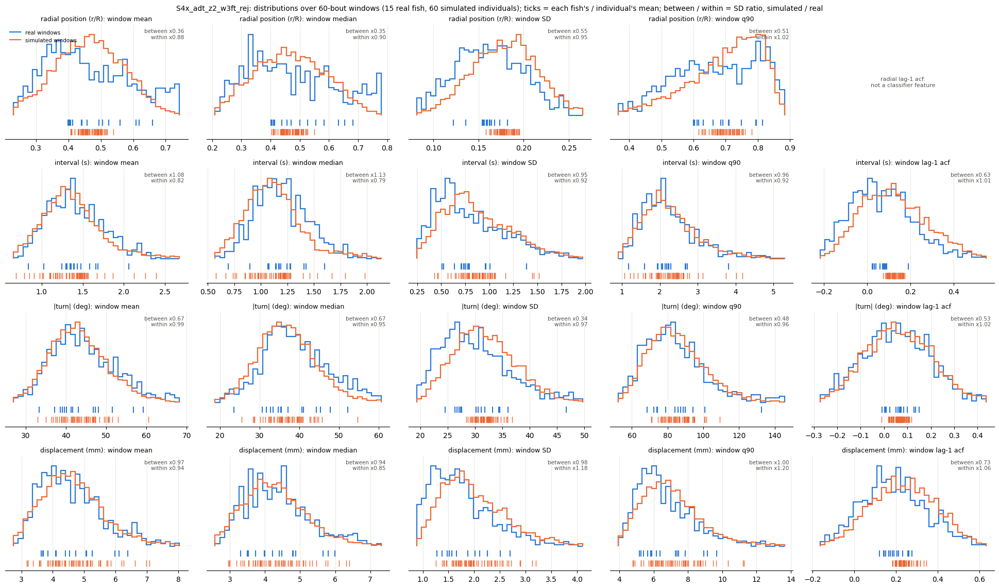

In [ ]:
# Model 29a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_29a = window_stats_grid("report_ckpts/M29a", "S4x_adt_z2_w3ft", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_w3ft_fold0.pt: 3 rollouts
  S4x_adt_z2_w3ft_fold1.pt: 3 rollouts
  S4x_adt_z2_w3ft_fold2.pt: 3 rollouts
  S4x_adt_z2_w3ft_fold3.pt: 3 rollouts
  S4x_adt_z2_w3ft_fold4.pt: 3 rollouts
dropped 11.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.39     0.90  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  22.7 +/- 0.7
d2s3.5    2.94     2.26  2.64  1.18  11.0   9.0                  17.4 +/- 0.9  20.8 +/- 0.5
d4s3.5    2.08     1.30  4.68  2.47  19.0   7.0                  18.7 +/- 1.7  19.1 +/- 0.8
d6s3.5    2.27     1.72  4.62  2.16  13.0   7.0                  16.7 +/- 1.3  19.0 +/- 0.8
d8

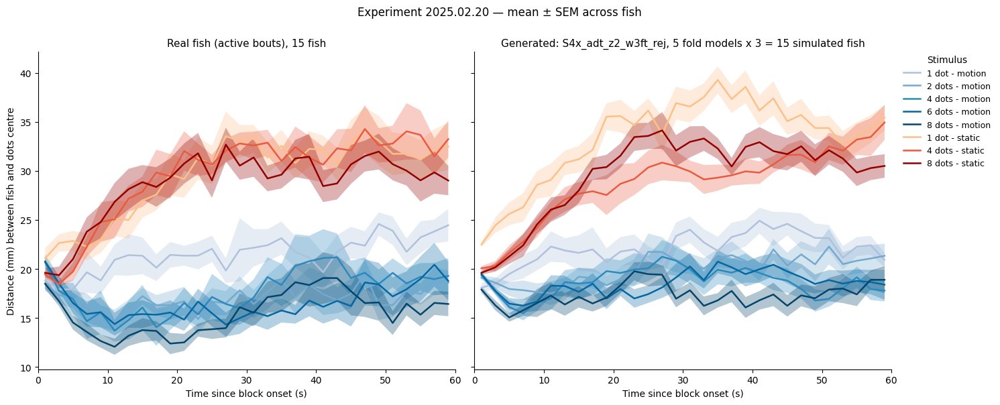

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 29a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M29a", "S4x_adt_z2_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

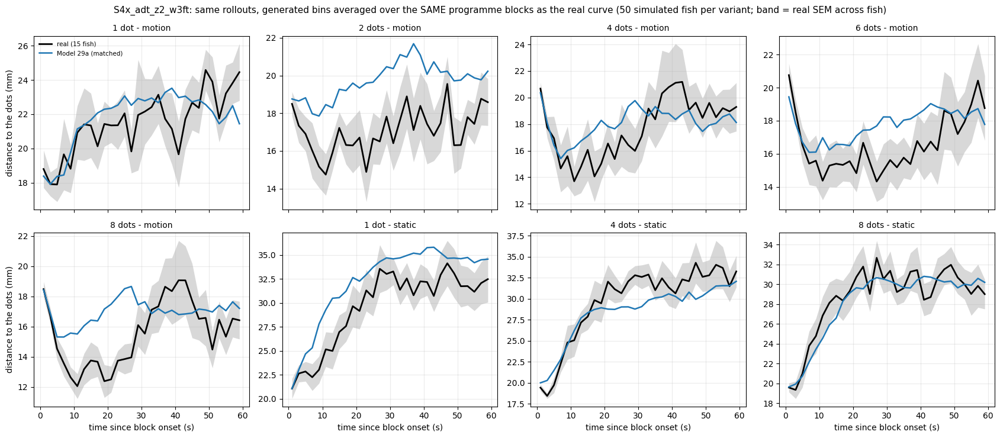

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 29a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_29a, _ = profile_variants_matched("report_ckpts/M29a", "S4x_adt_z2_w3ft", {"Model 29a": {"arm": "S4x_adt_z2_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 29a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_29a, _ = attraction_table("report_ckpts/M29a", ["S4x_adt_z2_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_w3ft                  
           plateau   null attraction         plateau   null attraction
cond_label                                                            
d1s3.5       22.41  23.57       1.16           22.72  23.06       0.34
d2s3.5       17.39  23.58       6.19           19.63  22.82       3.19
d4s3.5       18.74  23.93       5.19           19.02  23.00       3.98
d6s3.5       16.69  23.12       6.43           18.38  23.03       4.65
d8s3.5       16.41  23.36       6.94           17.33  22.86       5.53


In [ ]:
# Model 29a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_29a = toward_by_n("report_ckpts/M29a", ["S4x_adt_z2_w3ft"], rej=REJ["wall_reject"])
print(tow_29a.round(2).to_string())

           real  S4x_adt_z2_w3ft
win    N                        
0-20 s 1   9.09            10.24
       2  13.90            12.22
       4  15.73            13.61
       6  14.50            13.83
       8  16.00            16.17
4-20 s 1   6.25             9.11
       2  12.27            11.51
       4  14.35            12.56
       6  12.79            12.75
       8  15.11            14.44


Model 29a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 29a   real gap Model 29a    real gap Model 29a
cond                                                                  
d1s3.5  25.08         -8.68   6.64          3.96    7.55          2.55
d2s3.5  22.99         -5.77  12.94         -0.74   12.56         -0.85
d4s3.5  27.14         -7.70  15.54         -2.21   12.09          0.57
d6s3.5  32.55        -12.15  13.80          0.08   15.84         -2.00
d8s3.5  34.04        -10.62  14.45          1.61   13.80          0.76
d1s0     6.82         -5.54   4.22         -3.27    1.96         -0.23
d4s0     4.81         -0.98   1.86          0.50    1.74          2.38
d8s0     5.26         -0.02   2.63          1.44    2.39          2.91

turn size |Δθ| (deg): real f

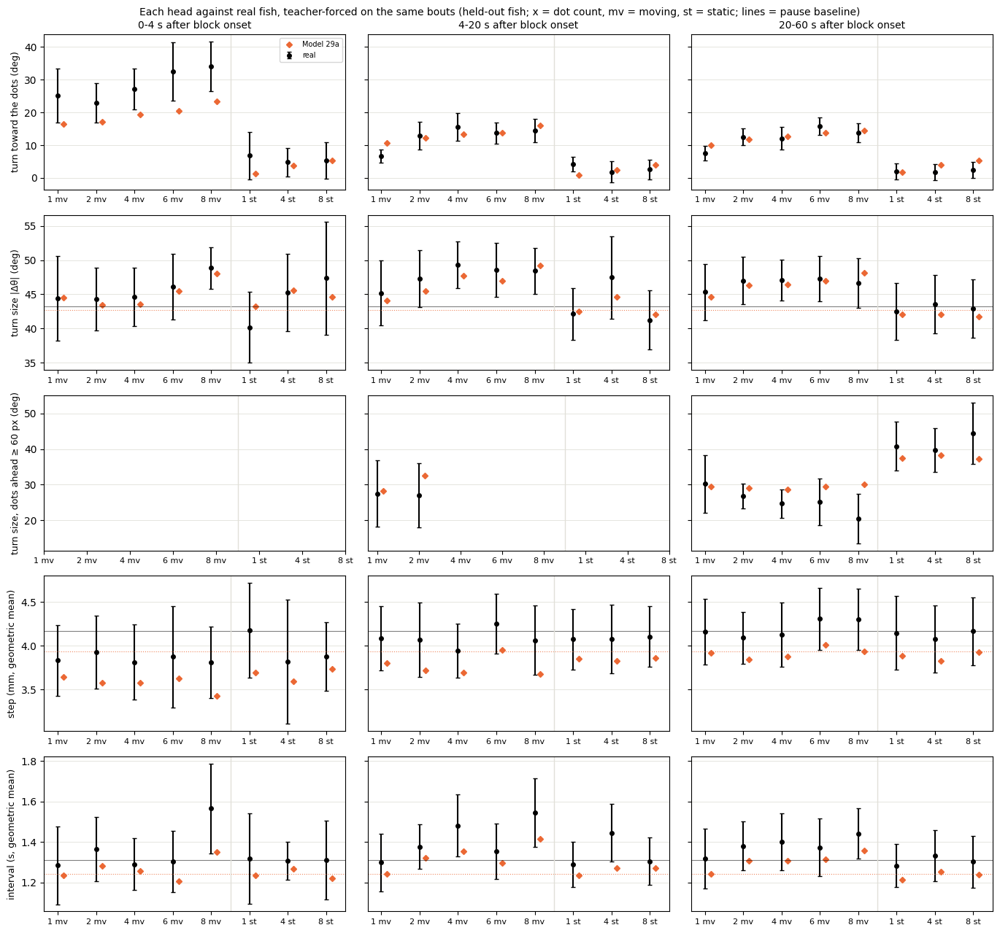

In [ ]:
# Model 29a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_29a, hg_29a = head_gaps({"Model 29a": ("report_ckpts/M29a", "S4x_adt_z2_w3ft")}, rej=REJ["wall_reject"])

##### Check: 29a — range products alone — seed 101 (key `30c`)

In [ ]:
# Model 30c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M30c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_30c = _l[_l.arm == "S4x_adt_z2_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_30c.index = ["turn", "displacement", "interval", "joint"]
print(lik_30c.round(3).to_string())

turn             7.657
displacement     4.542
interval         1.214
joint           13.413


In [ ]:
# Model 30c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_30c, c2st_30c = run(ckpt_dir="report_ckpts/M30c", arms="S4x_adt_z2_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_w3ft.csv / c2st_model1_rej_S4x_adt_z2_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_w3ft.csv  (15 rows) in 621s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_w3ft_rej
abs_dtheta_w1                        8.7299
symbol_js                            0.0128
dt_w1                                0.3872
dist_w1                              5.6549
trans_js                             0.0143
acf_l2                               0.0463
runlen_w1                            0.1751
bigram_H_gap                         0.1183
tuning_mse                           0.0191
following_gap_h                      0.0

In [ ]:
# Model 30c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M30c", "S4x_adt_z2_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_30c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_30c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.754            0.019      0.723         0.024
matched to the real runs (same bouts, 1:1)            0.753            0.021      0.721         0.025



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.414         0.088        0.062          0.709         0.953
                      median           0.449       0.409         0.098        0.064          0.658         0.937
                      SD               0.159       0.162         0.015        0.029          1.866         0.983
                      q90              0.679       0.646         0.074        0.096

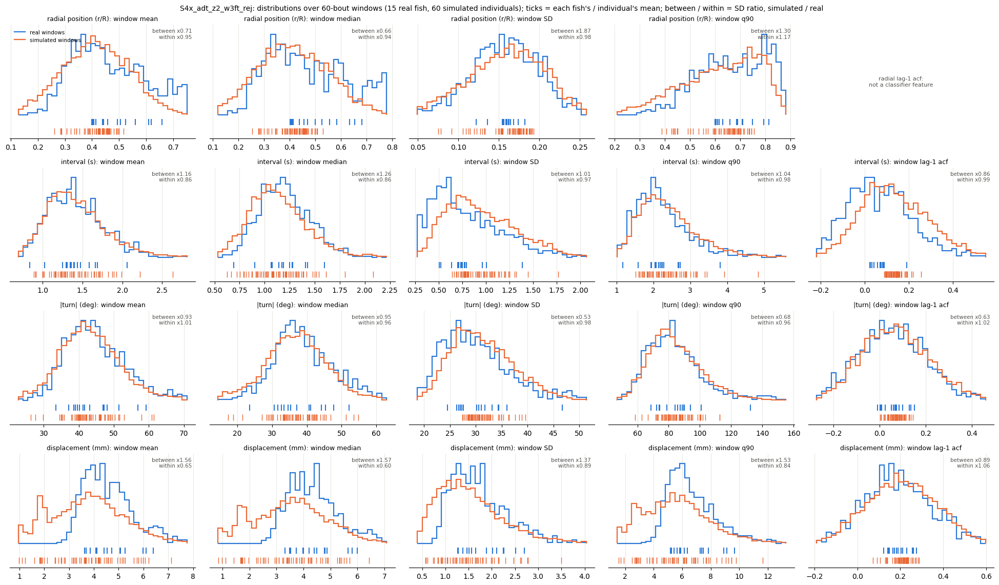

In [ ]:
# Model 30c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_30c = window_stats_grid("report_ckpts/M30c", "S4x_adt_z2_w3ft", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_w3ft_fold0.pt: 3 rollouts
  S4x_adt_z2_w3ft_fold1.pt: 3 rollouts
  S4x_adt_z2_w3ft_fold2.pt: 3 rollouts
  S4x_adt_z2_w3ft_fold3.pt: 3 rollouts
  S4x_adt_z2_w3ft_fold4.pt: 3 rollouts
dropped 11.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.34     0.93  0.15  0.37   3.0   5.0                  22.3 +/- 0.9  21.7 +/- 0.9
d2s3.5    1.72     1.41  2.64  1.64  11.0  11.0                  17.4 +/- 0.9  18.7 +/- 0.8
d4s3.5    1.51     0.84  4.68  3.84  19.0   9.0                  18.7 +/- 1.7  16.8 +/- 0.8
d6s3.5    1.06     0.77  4.62  3.77  13.0   9.0                  16.7 +/- 1.3  17.1 +/- 0.8
d8

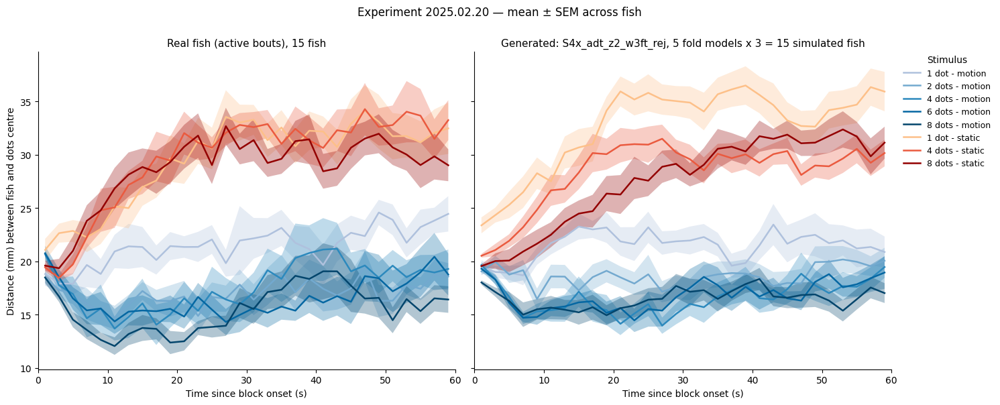

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M30c", "S4x_adt_z2_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

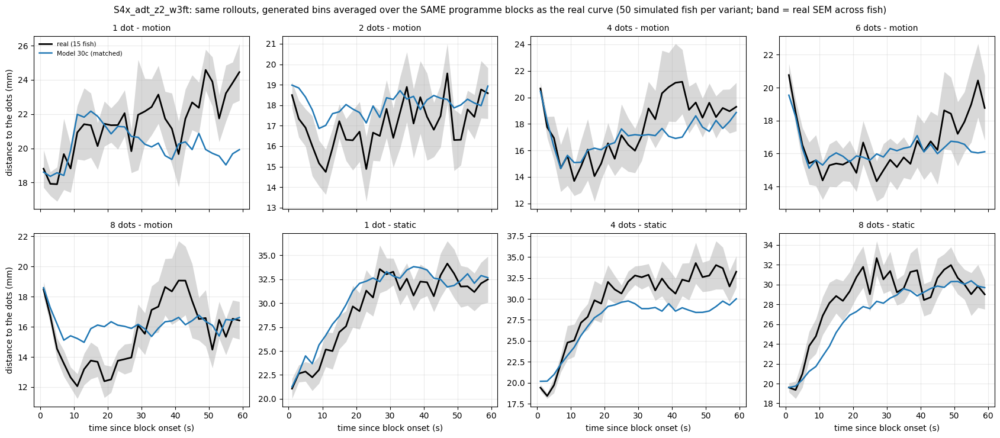

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_30c, _ = profile_variants_matched("report_ckpts/M30c", "S4x_adt_z2_w3ft", {"Model 30c": {"arm": "S4x_adt_z2_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_30c, _ = attraction_table("report_ckpts/M30c", ["S4x_adt_z2_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_w3ft                  
           plateau   null attraction         plateau   null attraction
cond_label                                                            
d1s3.5       22.41  23.57       1.16           20.76  21.76       1.00
d2s3.5       17.39  23.58       6.19           18.35  21.14       2.79
d4s3.5       18.74  23.93       5.19           17.04  21.33       4.30
d6s3.5       16.69  23.12       6.43           16.47  21.22       4.76
d8s3.5       16.41  23.36       6.94           16.12  21.28       5.16


In [ ]:
# Model 30c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_30c = toward_by_n("report_ckpts/M30c", ["S4x_adt_z2_w3ft"], rej=REJ["wall_reject"])
print(tow_30c.round(2).to_string())

           real  S4x_adt_z2_w3ft
win    N                        
0-20 s 1   9.09             9.59
       2  13.90            11.83
       4  15.73            13.46
       6  14.50            14.08
       8  16.00            16.51
4-20 s 1   6.25             8.46
       2  12.27            11.22
       4  14.35            12.29
       6  12.79            12.99
       8  15.11            15.02


Model 30c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 30c   real gap Model 30c    real gap Model 30c
cond                                                                  
d1s3.5  25.08        -10.00   6.64          3.35    7.55          2.01
d2s3.5  22.99         -4.59  12.94         -0.93   12.56         -0.87
d4s3.5  27.14         -6.95  15.54         -2.43   12.09          0.59
d6s3.5  32.55        -11.76  13.80          0.40   15.84         -1.46
d8s3.5  34.04         -9.89  14.45          2.25   13.80          1.65
d1s0     6.82         -6.15   4.22         -4.63    1.96         -1.41
d4s0     4.81         -2.32   1.86         -0.39    1.74          1.94
d8s0     5.26         -1.02   2.63          0.87    2.39          2.76

turn size |Δθ| (deg): real f

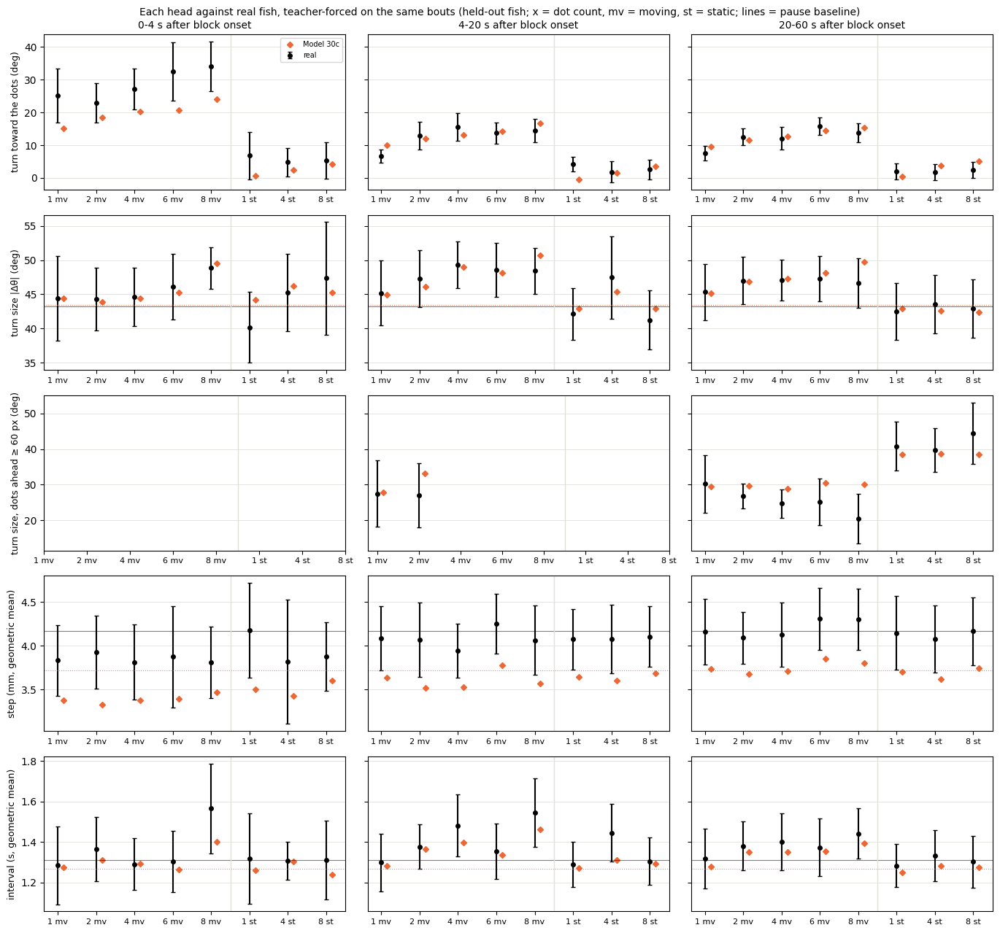

In [ ]:
# Model 30c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_30c, hg_30c = head_gaps({"Model 30c": ("report_ckpts/M30c", "S4x_adt_z2_w3ft")}, rej=REJ["wall_reject"])

<a id="m29b"></a>
#### Check: 29b — temporal set alone

**Change:** 25d + the temporal set (S4i code)

No AUC gain (matched +0.04), most of the dip (3.4 mm).

##### Check: 29b — temporal set alone — seed 0 (key `29b`)

In [ ]:
# Model 29b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M29b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_29b = _l[_l.arm == "S4i_adt_z2_cdt_tr_rc_al_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_29b.index = ["turn", "displacement", "interval", "joint"]
print(lik_29b.round(3).to_string())

turn             7.661
displacement     4.500
interval         1.231
joint           13.391


In [ ]:
# Model 29b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_29b, c2st_29b = run(ckpt_dir="report_ckpts/M29b", arms="S4i_adt_z2_cdt_tr_rc_al_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 677s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                     7.3962
symbol_js                                         0.0095
dt_w1                                             0.4000
dist_w1                                           4.0246
trans_js                                          0.0114
acf_l2                                            0.0447
runlen_w1                    

In [ ]:
# Model 29b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M29b", "S4i_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_29b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_29b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.695            0.015      0.625         0.018
matched to the real runs (same bouts, 1:1)            0.692            0.014      0.615         0.016



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.464         0.088        0.032          0.364         0.907
                      median           0.449       0.462         0.098        0.035          0.356         0.915
                      SD               0.159       0.179         0.015        0.008          0.546         0.995
                      q90              0.679       0.722         0.074        0.039

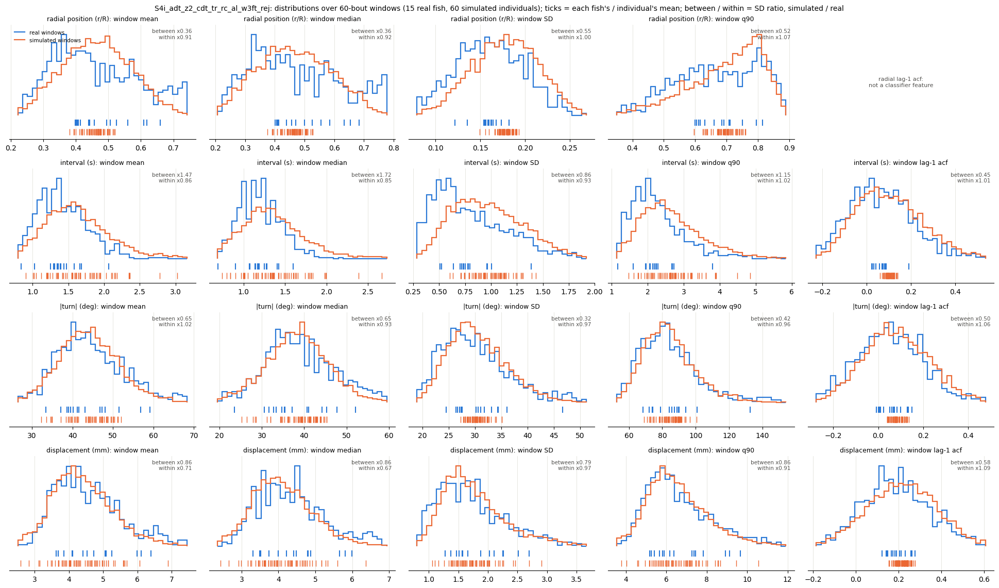

In [ ]:
# Model 29b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_29b = window_stats_grid("report_ckpts/M29b", "S4i_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], reps=4)


  S4i_adt_z2_cdt_tr_rc_al_w3ft_fold0.pt: 3 rollouts
  S4i_adt_z2_cdt_tr_rc_al_w3ft_fold1.pt: 3 rollouts
  S4i_adt_z2_cdt_tr_rc_al_w3ft_fold2.pt: 3 rollouts
  S4i_adt_z2_cdt_tr_rc_al_w3ft_fold3.pt: 3 rollouts
  S4i_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.40     0.95  0.15  0.68   3.0   5.0                  22.3 +/- 0.9  21.2 +/- 1.0
d2s3.5    1.85     1.48  2.64  2.55  11.0  11.0                  17.4 +/- 0.9  19.0 +/- 0.9
d4s3.5    1.05     0.61  4.68  5.68  19.0  15.0                  18.7 +/- 1.7  18.3 +/- 0.8
d6s3.5    1.31     0.88  4.62

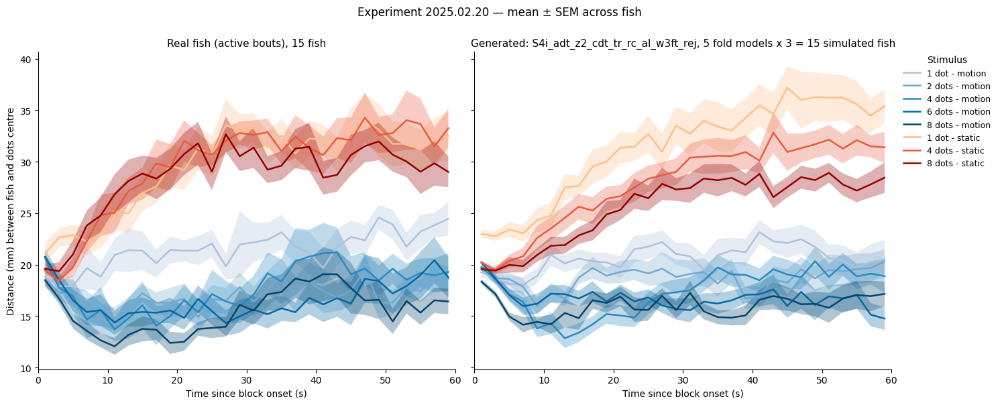

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 29b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M29b", "S4i_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

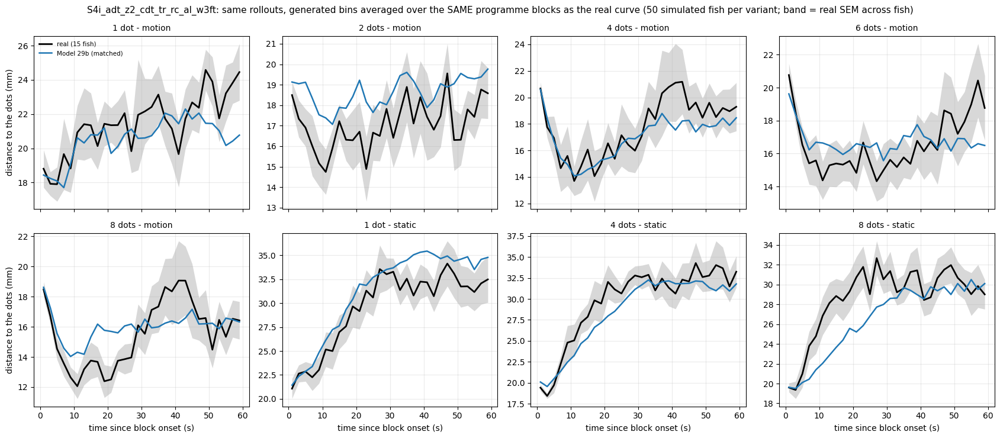

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 29b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_29b, _ = profile_variants_matched("report_ckpts/M29b", "S4i_adt_z2_cdt_tr_rc_al_w3ft", {"Model 29b": {"arm": "S4i_adt_z2_cdt_tr_rc_al_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 29b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_29b, _ = attraction_table("report_ckpts/M29b", ["S4i_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                      plateau   null attraction
cond_label                                                                         
d1s3.5       22.41  23.57       1.16                        21.36  22.59       1.23
d2s3.5       17.39  23.58       6.19                        18.75  22.61       3.86
d4s3.5       18.74  23.93       5.19                        17.91  22.29       4.38
d6s3.5       16.69  23.12       6.43                        16.69  22.59       5.90
d8s3.5       16.41  23.36       6.94                        16.55  22.25       5.70


In [ ]:
# Model 29b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_29b = toward_by_n("report_ckpts/M29b", ["S4i_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"])
print(tow_29b.round(2).to_string())

           real  S4i_adt_z2_cdt_tr_rc_al_w3ft
win    N                                     
0-20 s 1   9.09                         10.07
       2  13.90                         11.90
       4  15.73                         14.43
       6  14.50                         14.37
       8  16.00                         17.12
4-20 s 1   6.25                          9.29
       2  12.27                         11.72
       4  14.35                         13.98
       6  12.79                         13.67
       8  15.11                         15.83


Model 29b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 29b   real gap Model 29b    real gap Model 29b
cond                                                                  
d1s3.5  25.08         -9.75   6.64          3.73    7.55          2.33
d2s3.5  22.99         -6.67  12.94         -1.11   12.56         -0.85
d4s3.5  27.14         -8.77  15.54         -1.22   12.09          1.41
d6s3.5  32.55        -13.60  13.80          0.95   15.84         -1.29
d8s3.5  34.04        -11.16  14.45          2.77   13.80          1.76
d1s0     6.82         -5.03   4.22         -3.56    1.96         -1.04
d4s0     4.81         -0.94   1.86          0.76    1.74          2.37
d8s0     5.26          0.63   2.63          1.91    2.39          2.60

turn size |Δθ| (deg): real f

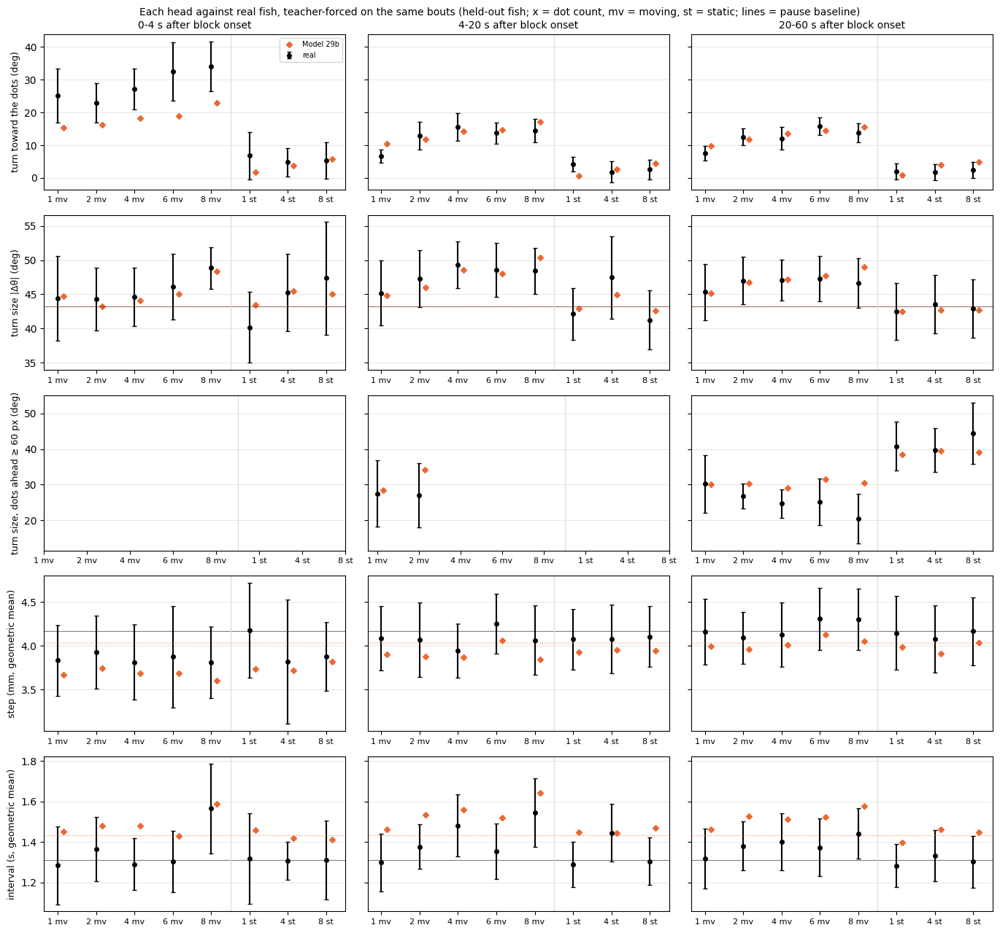

In [ ]:
# Model 29b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_29b, hg_29b = head_gaps({"Model 29b": ("report_ckpts/M29b", "S4i_adt_z2_cdt_tr_rc_al_w3ft")}, rej=REJ["wall_reject"])

##### Check: 29b — temporal set alone — seed 101

XX — not trained at seed 101 (optional)

<a id="m35a"></a>
#### Check: 35a — 26e without the run clock

**Change:** 26e − run clock (the rest of the temporal set and S4x kept)

The run clock alone, removed from 26e. Matched AUC worse at both seeds (+0.034 | +0.078, beyond the 0.05 bar at seed 101 only), likelihood unchanged (−0.005 | −0.007 bits), dip −1.16 | +0.12 mm (not replicated), grading unchanged, static error +0.40 | +0.45. Same checkpoints as the ablation notebook.

##### Check: 35a — 26e without the run clock — seed 0 (key `35a`)

In [ ]:
# Model 35a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M35a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_35a = _l[_l.arm == "S4x_adt_z2_cdt_tr_al_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_35a.index = ["turn", "displacement", "interval", "joint"]
print(lik_35a.round(3).to_string())

turn             7.660
displacement     4.498
interval         1.222
joint           13.380


In [ ]:
# Model 35a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_35a, c2st_35a = run(ckpt_dir="report_ckpts/M35a", arms="S4x_adt_z2_cdt_tr_al_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv  (15 rows) in 3958s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_al_w3ft_rej
abs_dtheta_w1                                  7.7210
symbol_js                                      0.0096
dt_w1                                          0.3756
dist_w1                                        3.8986
trans_js                                       0.0114
acf_l2                                         0.0475
runlen_w1                                      0.1501
bigram_

In [ ]:
# Model 35a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M35a", "S4x_adt_z2_cdt_tr_al_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_35a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_35a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.712            0.012      0.661         0.012
matched to the real runs (same bouts, 1:1)            0.705            0.012      0.648         0.012



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.460         0.088        0.035          0.396         0.923
                      median           0.449       0.457         0.098        0.039          0.400         0.927
                      SD               0.159       0.178         0.015        0.010          0.640         0.982
                      q90              0.679       0.717         0.074        0.043

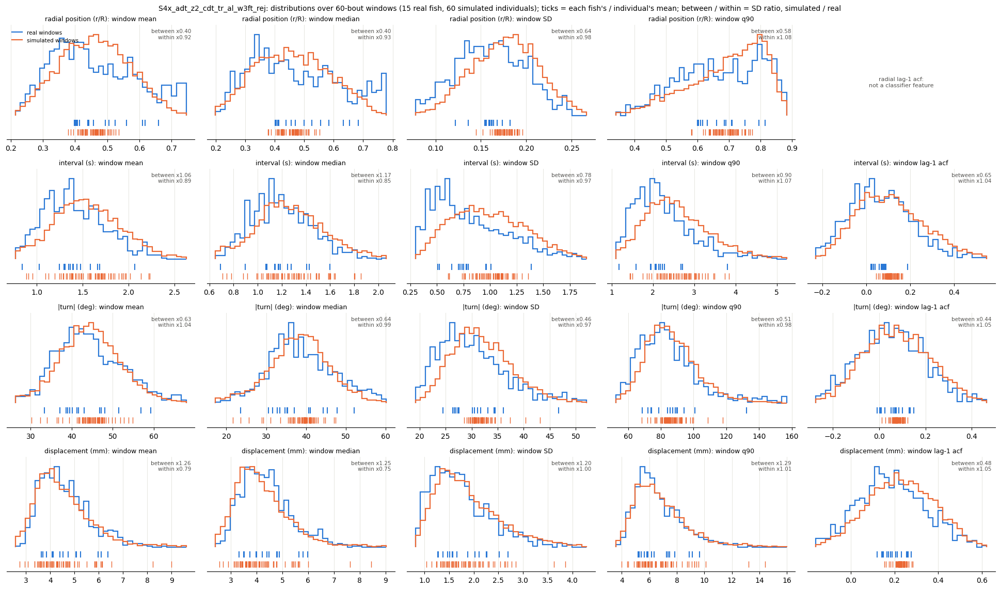

In [ ]:
# Model 35a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_35a = window_stats_grid("report_ckpts/M35a", "S4x_adt_z2_cdt_tr_al_w3ft", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_al_w3ft_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_al_w3ft_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_al_w3ft_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_al_w3ft_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_al_w3ft_fold4.pt: 3 rollouts
dropped 12.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.22     0.88  0.15  0.31   3.0   3.0                  22.3 +/- 0.9  22.7 +/- 0.9
d2s3.5    3.72     2.94  2.64  0.89  11.0   7.0                  17.4 +/- 0.9  21.3 +/- 1.0
d4s3.5    1.77     1.09  4.68  2.34  19.0   7.0                  18.7 +/- 1.7  19.7 +/- 1.1
d6s3.5    1.55     1.17  4.62  3.67  13.0   

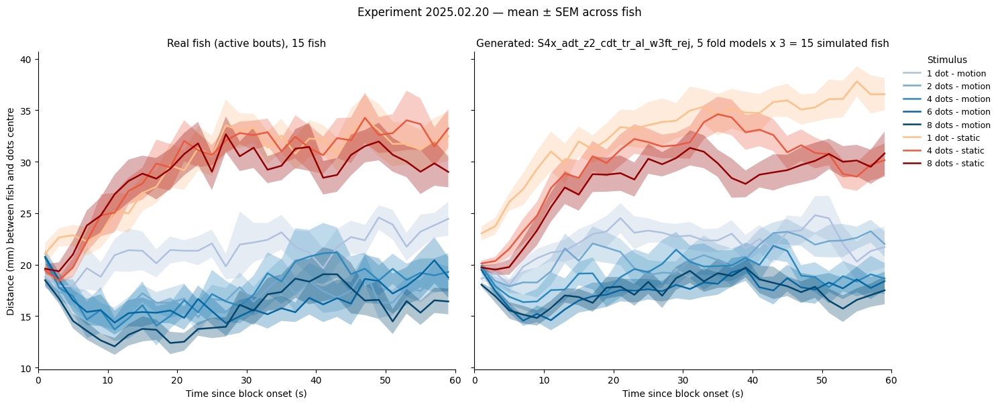

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 35a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M35a", "S4x_adt_z2_cdt_tr_al_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

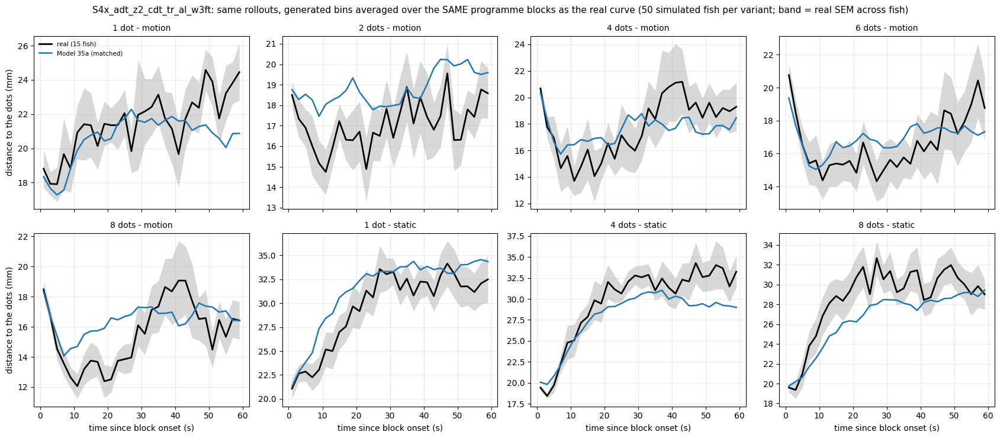

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 35a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_35a, _ = profile_variants_matched("report_ckpts/M35a", "S4x_adt_z2_cdt_tr_al_w3ft", {"Model 35a": {"arm": "S4x_adt_z2_cdt_tr_al_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 35a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_35a, _ = attraction_table("report_ckpts/M35a", ["S4x_adt_z2_cdt_tr_al_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_al_w3ft                  
           plateau   null attraction                   plateau   null attraction
cond_label                                                                      
d1s3.5       22.41  23.57       1.16                     21.68  22.78       1.09
d2s3.5       17.39  23.58       6.19                     19.87  22.95       3.08
d4s3.5       18.74  23.93       5.19                     18.67  23.22       4.55
d6s3.5       16.69  23.12       6.43                     17.41  22.81       5.39
d8s3.5       16.41  23.36       6.94                     17.41  22.80       5.39


In [ ]:
# Model 35a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_35a = toward_by_n("report_ckpts/M35a", ["S4x_adt_z2_cdt_tr_al_w3ft"], rej=REJ["wall_reject"])
print(tow_35a.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_al_w3ft
win    N                                  
0-20 s 1   9.09                      10.21
       2  13.90                      11.81
       4  15.73                      13.77
       6  14.50                      14.63
       8  16.00                      16.83
4-20 s 1   6.25                       9.33
       2  12.27                      10.93
       4  14.35                      12.65
       6  12.79                      13.51
       8  15.11                      15.23


Model 35a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 35a   real gap Model 35a    real gap Model 35a
cond                                                                  
d1s3.5  25.08         -9.47   6.64          3.98    7.55          2.56
d2s3.5  22.99         -4.87  12.94         -1.21   12.56         -1.13
d4s3.5  27.14         -7.38  15.54         -2.14   12.09          0.83
d6s3.5  32.55        -11.03  13.80          1.08   15.84         -1.45
d8s3.5  34.04         -8.89  14.45          2.26   13.80          1.60
d1s0     6.82         -5.47   4.22         -3.65    1.96         -0.51
d4s0     4.81         -1.08   1.86          1.06    1.74          2.33
d8s0     5.26         -0.60   2.63          1.08    2.39          2.72

turn size |Δθ| (deg): real f

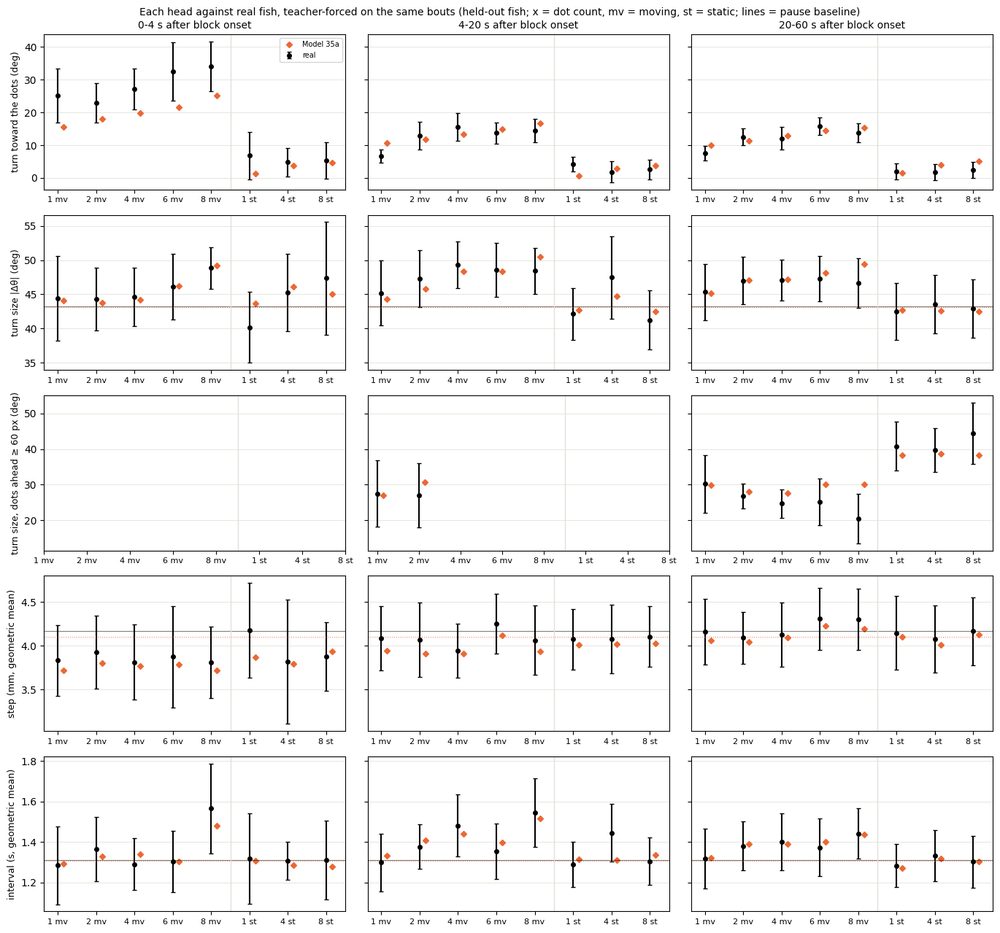

In [ ]:
# Model 35a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_35a, hg_35a = head_gaps({"Model 35a": ("report_ckpts/M35a", "S4x_adt_z2_cdt_tr_al_w3ft")}, rej=REJ["wall_reject"])

##### Check: 35a — 26e without the run clock — seed 101 (key `35b`)

In [ ]:
# Model 35b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M35b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_35b = _l[_l.arm == "S4x_adt_z2_cdt_tr_al_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_35b.index = ["turn", "displacement", "interval", "joint"]
print(lik_35b.round(3).to_string())

turn             7.664
displacement     4.508
interval         1.208
joint           13.380


In [ ]:
# Model 35b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_35b, c2st_35b = run(ckpt_dir="report_ckpts/M35b", arms="S4x_adt_z2_cdt_tr_al_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_al_w3ft.csv  (15 rows) in 2680s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_al_w3ft_rej
abs_dtheta_w1                                  9.1976
symbol_js                                      0.0136
dt_w1                                          0.4079
dist_w1                                        4.3895
trans_js                                       0.0151
acf_l2                                         0.0466
runlen_w1                                      0.1726
bigram_

In [ ]:
# Model 35b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M35b", "S4x_adt_z2_cdt_tr_al_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_35b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_35b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.726            0.013      0.686         0.014
matched to the real runs (same bouts, 1:1)            0.723            0.012      0.681         0.014



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.446         0.088        0.035          0.404         0.950
                      median           0.449       0.441         0.098        0.039          0.399         0.952
                      SD               0.159       0.172         0.015        0.013          0.816         1.028
                      q90              0.679       0.695         0.074        0.047

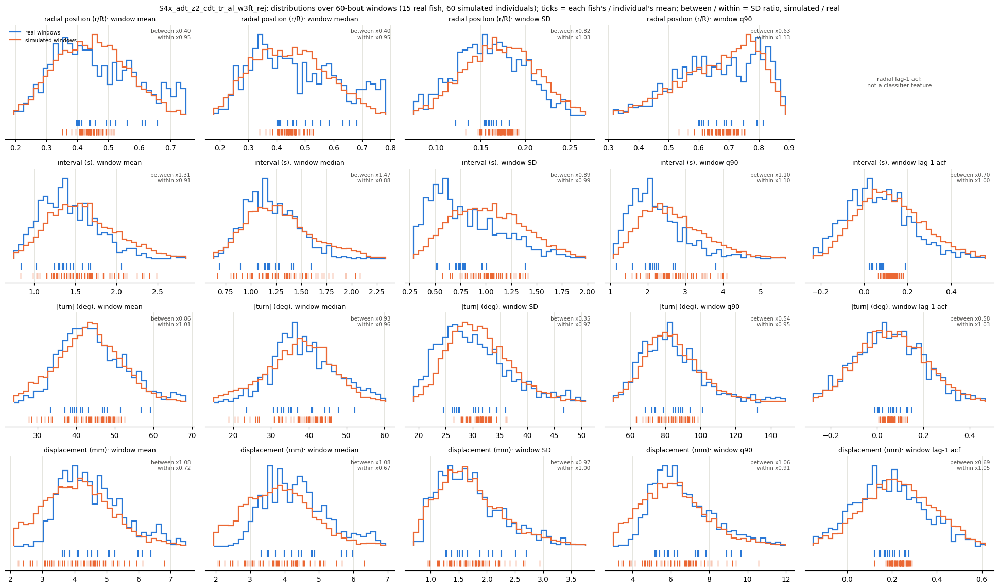

In [ ]:
# Model 35b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_35b = window_stats_grid("report_ckpts/M35b", "S4x_adt_z2_cdt_tr_al_w3ft", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_al_w3ft_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_al_w3ft_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_al_w3ft_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_al_w3ft_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_al_w3ft_fold4.pt: 3 rollouts
dropped 11.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.00     1.34  0.15  0.79   3.0   7.0                  22.3 +/- 0.9  20.1 +/- 0.9
d2s3.5    1.76     1.46  2.64  1.35  11.0   9.0                  17.4 +/- 0.9  18.1 +/- 0.8
d4s3.5    1.96     1.09  4.68  3.46  19.0   9.0                  18.7 +/- 1.7  16.1 +/- 0.7
d6s3.5    1.26     0.82  4.62  4.19  13.0  1

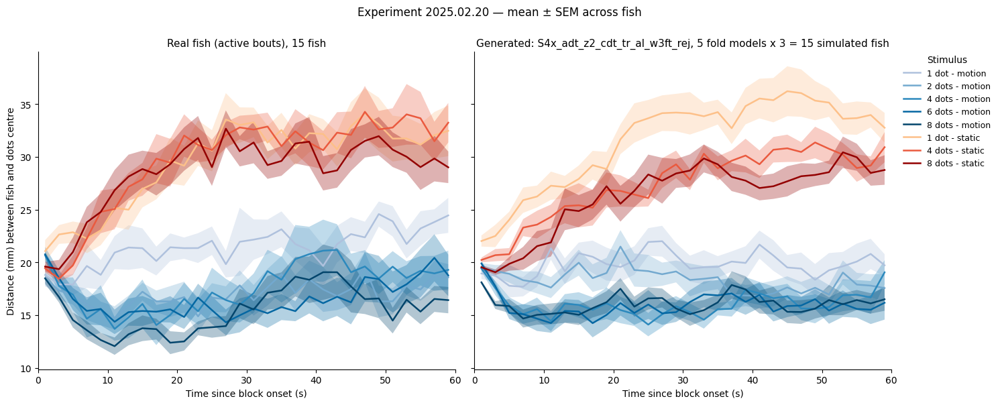

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 35b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M35b", "S4x_adt_z2_cdt_tr_al_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

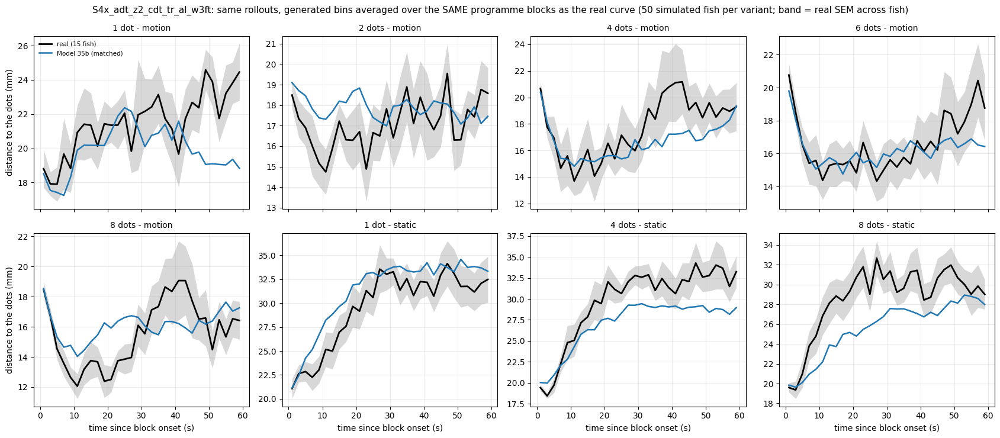

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 35b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_35b, _ = profile_variants_matched("report_ckpts/M35b", "S4x_adt_z2_cdt_tr_al_w3ft", {"Model 35b": {"arm": "S4x_adt_z2_cdt_tr_al_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 35b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_35b, _ = attraction_table("report_ckpts/M35b", ["S4x_adt_z2_cdt_tr_al_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_al_w3ft                  
           plateau   null attraction                   plateau   null attraction
cond_label                                                                      
d1s3.5       22.41  23.57       1.16                     20.46  21.94       1.48
d2s3.5       17.39  23.58       6.19                     18.71  21.81       3.10
d4s3.5       18.74  23.93       5.19                     16.73  21.97       5.24
d6s3.5       16.69  23.12       6.43                     16.02  21.75       5.73
d8s3.5       16.41  23.36       6.94                     16.12  21.66       5.55


In [ ]:
# Model 35b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_35b = toward_by_n("report_ckpts/M35b", ["S4x_adt_z2_cdt_tr_al_w3ft"], rej=REJ["wall_reject"])
print(tow_35b.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_al_w3ft
win    N                                  
0-20 s 1   9.09                      10.06
       2  13.90                      12.44
       4  15.73                      14.45
       6  14.50                      15.30
       8  16.00                      17.38
4-20 s 1   6.25                       9.14
       2  12.27                      11.76
       4  14.35                      13.33
       6  12.79                      14.18
       8  15.11                      15.70


Model 35b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 35b   real gap Model 35b    real gap Model 35b
cond                                                                  
d1s3.5  25.08         -9.41   6.64          3.85    7.55          2.80
d2s3.5  22.99         -4.50  12.94         -0.31   12.56         -0.66
d4s3.5  27.14         -6.05  15.54         -1.74   12.09          1.41
d6s3.5  32.55        -11.84  13.80          1.90   15.84         -1.26
d8s3.5  34.04         -8.64  14.45          2.56   13.80          1.50
d1s0     6.82         -5.21   4.22         -3.45    1.96         -0.56
d4s0     4.81         -1.52   1.86          1.06    1.74          2.92
d8s0     5.26          0.01   2.63          1.88    2.39          3.49

turn size |Δθ| (deg): real f

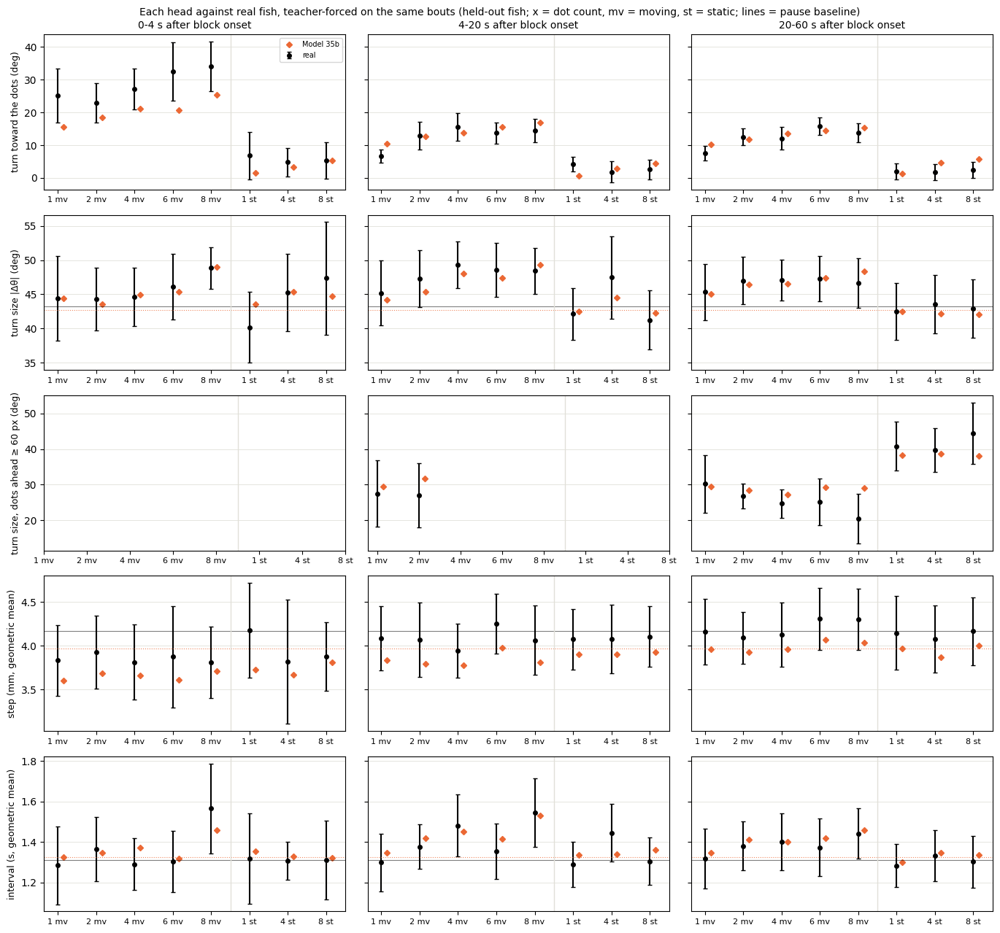

In [ ]:
# Model 35b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_35b, hg_35b = head_gaps({"Model 35b": ("report_ckpts/M35b", "S4x_adt_z2_cdt_tr_al_w3ft")}, rej=REJ["wall_reject"])

<a id="drift"></a>
## 2. Drift branch — best likelihood and slow structure (not for ablations)

The AR(1)
slow state (drift) improves the held-out likelihood and reproduces the slow window-to-window correlation at both seeds,
but costs dip. With the drift, the bump code beats S4x at both seeds; whether the drift improves AUC on the bump code
depends on the seed (−0.05 | +0.003).

<a id="m18a"></a>
### 18a

**Change:** 26e + static block (a control)

The static block has no replicated effect; 18a only makes the next comparisons differ by one thing.

#### 18a — seed 0 (key `18a`)

In [ ]:
# Model 18a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M18a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_18a = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_18a.index = ["turn", "displacement", "interval", "joint"]
print(lik_18a.round(3).to_string())

turn             7.667
displacement     4.508
interval         1.218
joint           13.393


In [ ]:
# Model 18a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_18a, c2st_18a = run(ckpt_dir="report_ckpts/M18a", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 878s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                        8.6091
symbol_js                                            0.0130
dt_w1                                                0.3785
dist_w1                                              4.1703
trans_js                                             0.0144
acf_l2                                               0.0

In [ ]:
# Model 18a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M18a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_18a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_18a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.659            0.020      0.577         0.021
matched to the real runs (same bouts, 1:1)            0.662            0.021      0.568         0.021



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.474         0.088        0.035          0.394         0.917
                      median           0.449       0.472         0.098        0.039          0.394         0.932
                      SD               0.159       0.183         0.015        0.011          0.720         0.991
                      q90              0.679       0.735         0.074        0.044

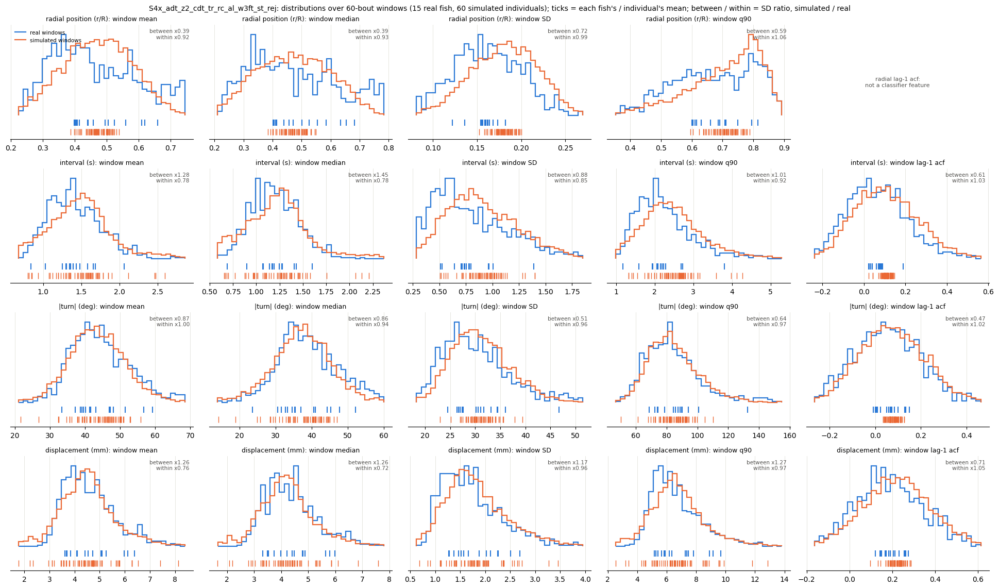

In [ ]:
# Model 18a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_18a = window_stats_grid("report_ckpts/M18a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 11.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.50     1.04  0.15  0.04   3.0   5.0                  22.3 +/- 0.9  21.8 +/- 0.8
d2s3.5    2.48     1.94  2.64   2.2  11.0  15.0                  17.4 +/- 0.9  20.0 +/- 0.7
d4s3.5    1.41     0.84  4.68  3.63  19.0   9.0                  18.7 +/- 1.7  18.7 +/- 0.6
d6s3.5    1.97

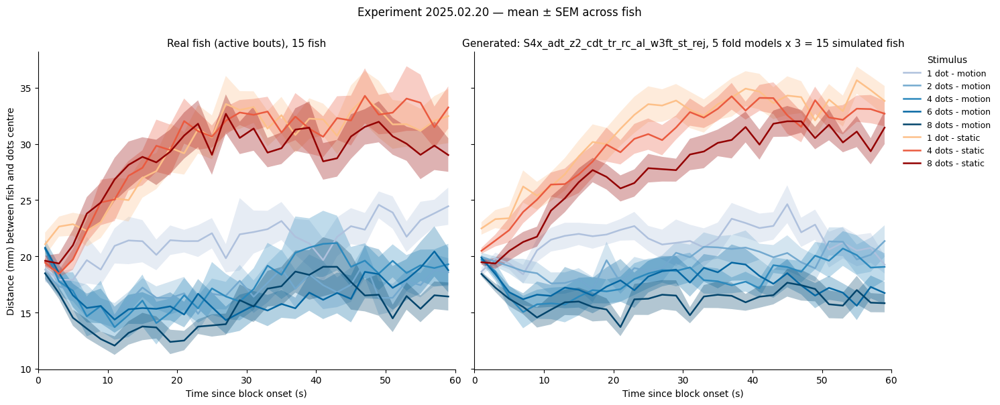

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 18a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M18a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

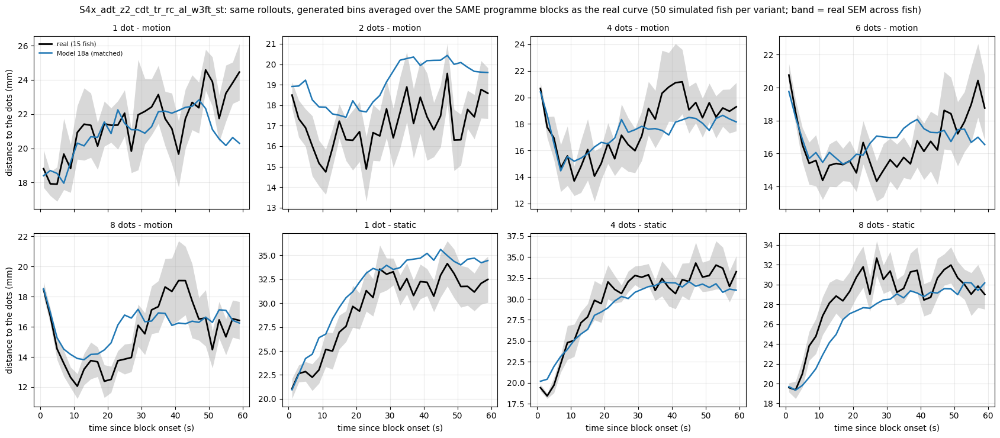

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 18a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_18a, _ = profile_variants_matched("report_ckpts/M18a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st", {"Model 18a": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 18a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_18a, _ = attraction_table("report_ckpts/M18a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           22.27  23.32       1.05
d2s3.5       17.39  23.58       6.19                           19.54  22.69       3.15
d4s3.5       18.74  23.93       5.19                           18.33  22.74       4.42
d6s3.5       16.69  23.12       6.43                           17.29  22.77       5.48
d8s3.5       16.41  23.36       6.94                           16.91  22.77       5.86


In [ ]:
# Model 18a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_18a = toward_by_n("report_ckpts/M18a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_18a.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_st
win    N                                        
0-20 s 1   9.09                             9.58
       2  13.90                            11.12
       4  15.73                            13.07
       6  14.50                            13.07
       8  16.00                            15.53
4-20 s 1   6.25                             8.87
       2  12.27                            10.91
       4  14.35                            12.42
       6  12.79                            12.22
       8  15.11                            14.43


Model 18a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 18a   real gap Model 18a    real gap Model 18a
cond                                                                  
d1s3.5  25.08        -10.15   6.64          3.61    7.55          1.90
d2s3.5  22.99         -6.47  12.94         -2.08   12.56         -1.37
d4s3.5  27.14         -9.16  15.54         -2.49   12.09         -0.07
d6s3.5  32.55        -13.62  13.80         -0.29   15.84         -2.59
d8s3.5  34.04        -11.96  14.45          1.20   13.80          0.41
d1s0     6.82         -6.37   4.22         -3.90    1.96         -1.16
d4s0     4.81         -2.68   1.86          0.42    1.74          1.74
d8s0     5.26         -2.46   2.63          0.97    2.39          2.27

turn size |Δθ| (deg): real f

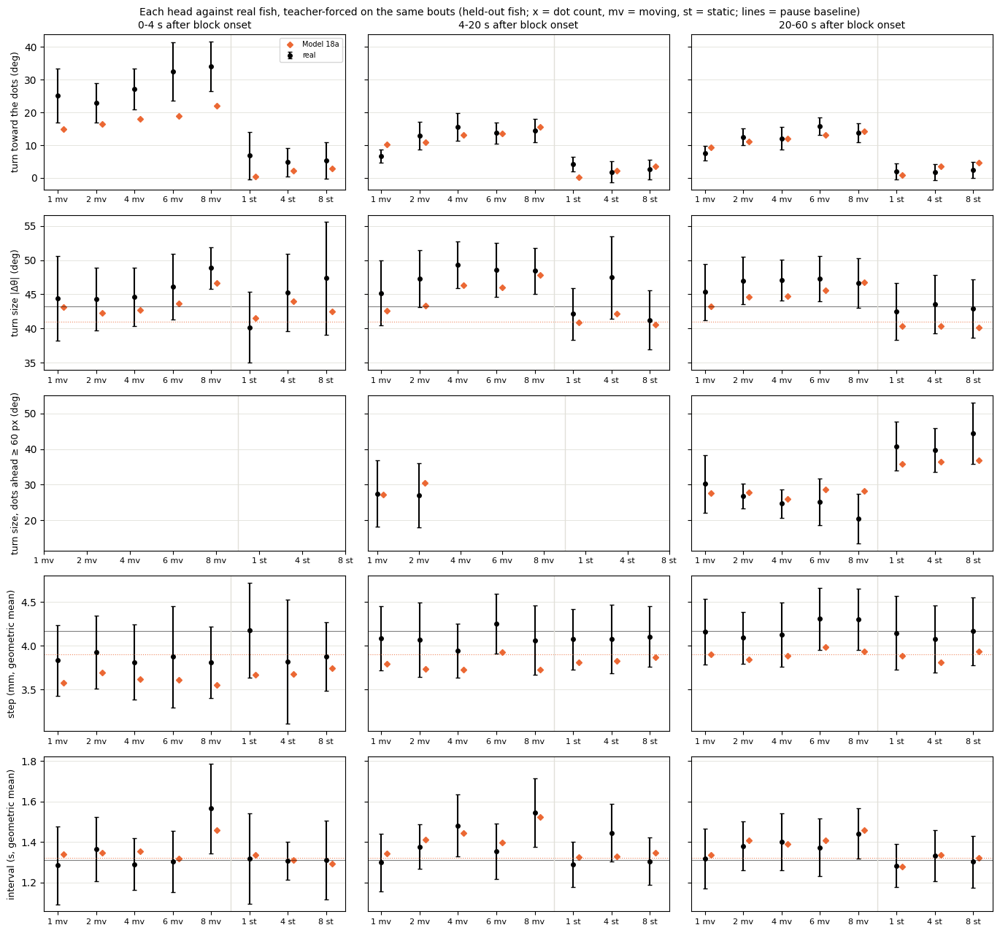

In [ ]:
# Model 18a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_18a, hg_18a = head_gaps({"Model 18a": ("report_ckpts/M18a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

#### 18a — seed 101 (key `24a`)

In [ ]:
# Model 24a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M24a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_24a = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_24a.index = ["turn", "displacement", "interval", "joint"]
print(lik_24a.round(3).to_string())

turn             7.667
displacement     4.503
interval         1.226
joint           13.395


In [ ]:
# Model 24a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_24a, c2st_24a = run(ckpt_dir="report_ckpts/M24a", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 708s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                        7.7735
symbol_js                                            0.0111
dt_w1                                                0.3803
dist_w1                                              3.5684
trans_js                                             0.0126
acf_l2                                               0.0

In [ ]:
# Model 24a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M24a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_24a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_24a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.664            0.015      0.586         0.020
matched to the real runs (same bouts, 1:1)            0.652            0.016      0.572         0.021



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.468         0.088        0.032          0.361         0.886
                      median           0.449       0.468         0.098        0.034          0.348         0.905
                      SD               0.159       0.180         0.015        0.010          0.667         0.956
                      q90              0.679       0.727         0.074        0.041

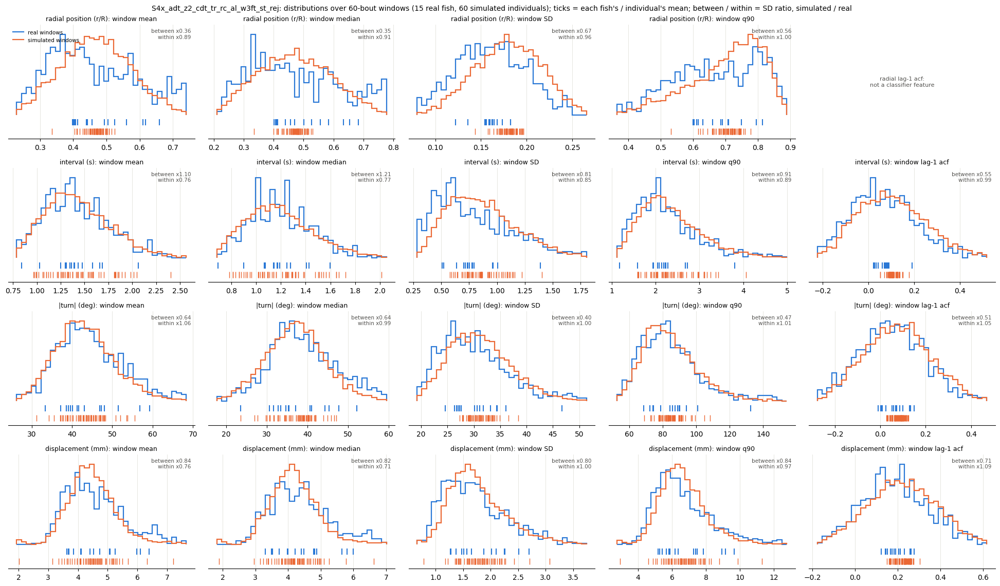

In [ ]:
# Model 24a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_24a = window_stats_grid("report_ckpts/M24a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 12.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.54     1.09  0.15  0.04   3.0   3.0                  22.3 +/- 0.9  22.7 +/- 0.8
d2s3.5    1.75     1.37  2.64  1.75  11.0   9.0                  17.4 +/- 0.9  19.1 +/- 0.9
d4s3.5    1.29     0.72  4.68  3.62  19.0   9.0                  18.7 +/- 1.7  17.4 +/- 0.7
d6s3.5    1.58

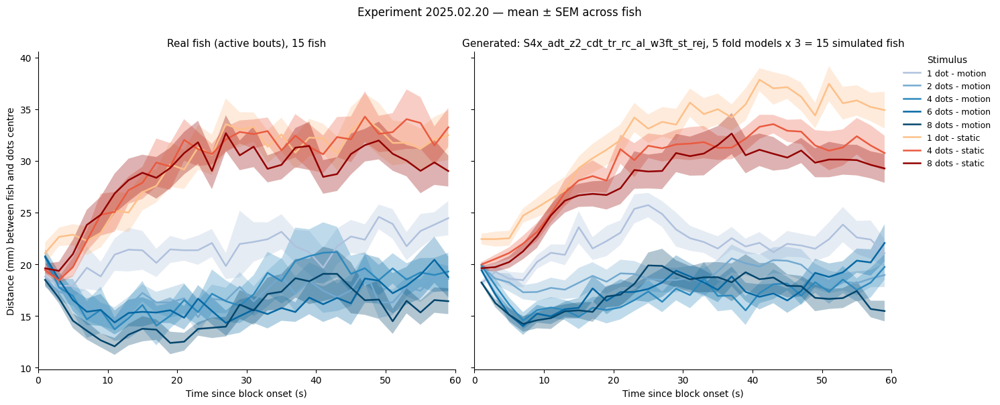

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M24a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

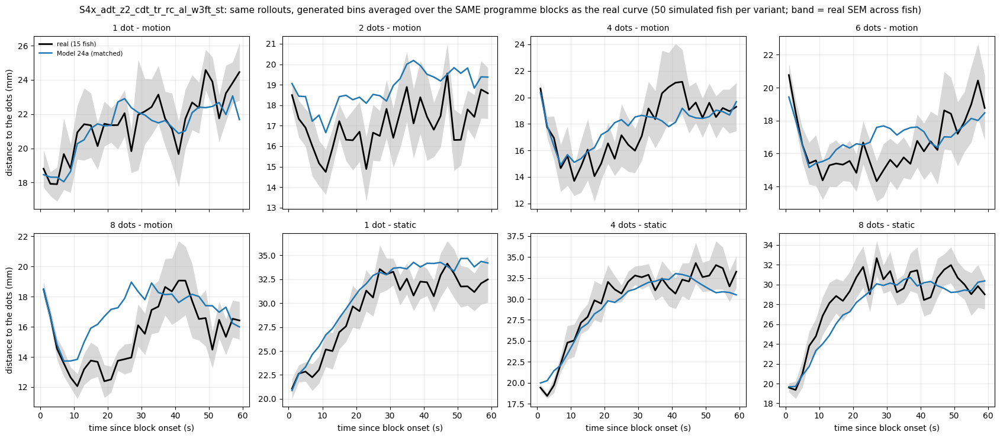

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_24a, _ = profile_variants_matched("report_ckpts/M24a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st", {"Model 24a": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_24a, _ = attraction_table("report_ckpts/M24a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           22.40  23.68       1.28
d2s3.5       17.39  23.58       6.19                           19.28  23.26       3.99
d4s3.5       18.74  23.93       5.19                           17.85  23.59       5.74
d6s3.5       16.69  23.12       6.43                           17.80  23.35       5.56
d8s3.5       16.41  23.36       6.94                           18.13  23.79       5.66


In [ ]:
# Model 24a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_24a = toward_by_n("report_ckpts/M24a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_24a.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_st
win    N                                        
0-20 s 1   9.09                             9.84
       2  13.90                            11.67
       4  15.73                            13.57
       6  14.50                            14.36
       8  16.00                            15.74
4-20 s 1   6.25                             8.96
       2  12.27                            11.08
       4  14.35                            12.61
       6  12.79                            13.30
       8  15.11                            14.15


Model 24a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 24a   real gap Model 24a    real gap Model 24a
cond                                                                  
d1s3.5  25.08        -10.49   6.64          3.77    7.55          2.11
d2s3.5  22.99         -5.94  12.94         -1.39   12.56         -1.44
d4s3.5  27.14         -8.61  15.54         -1.84   12.09          0.46
d6s3.5  32.55        -12.24  13.80          0.96   15.84         -1.95
d8s3.5  34.04        -10.91  14.45          1.24   13.80          0.64
d1s0     6.82         -5.64   4.22         -2.96    1.96         -0.95
d4s0     4.81         -1.44   1.86          1.17    1.74          2.41
d8s0     5.26         -1.32   2.63          1.37    2.39          2.72

turn size |Δθ| (deg): real f

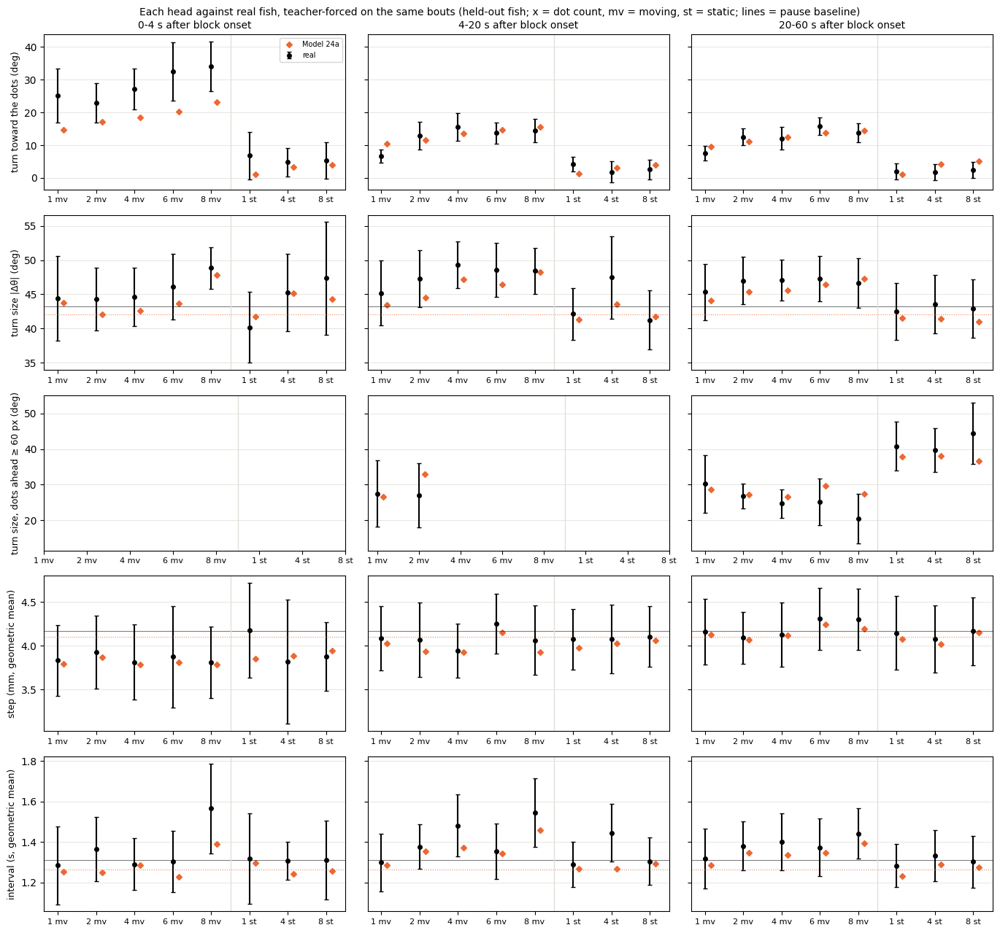

In [ ]:
# Model 24a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_24a, hg_24a = head_gaps({"Model 24a": ("report_ckpts/M24a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

<a id="m24b"></a>
### 18a + drift

**Change:** + AR(1) slow state on the S4x code

Likelihood better (−0.065 | −0.047 bits) and the slow window correlation reproduced; matched AUC and dip worse at both seeds.

#### 18a + drift — seed 0 (key `24b`)

In [ ]:
# Model 24b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M24b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_24b = _l[_l.arm == "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_24b.index = ["turn", "displacement", "interval", "joint"]
print(lik_24b.round(3).to_string())

turn             7.622
displacement     4.517
interval         1.190
joint           13.329


In [ ]:
# Model 24b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_24b, c2st_24b = run(ckpt_dir="report_ckpts/M24b", arms="S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 724s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                              8.0316
symbol_js                                                  0.0112
dt_w1                                                      0.3660
dist_w1                                                    4.2663
trans_js                                                   0.0

In [ ]:
# Model 24b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M24b", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_24b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_24b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.698             0.01      0.635         0.013
matched to the real runs (same bouts, 1:1)            0.691             0.01      0.620         0.013



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.467         0.088        0.049          0.562         0.866
                      median           0.449       0.470         0.098        0.054          0.548         0.875
                      SD               0.159       0.173         0.015        0.016          1.019         0.938
                      q90              0.679       0.709         0.074        0.065

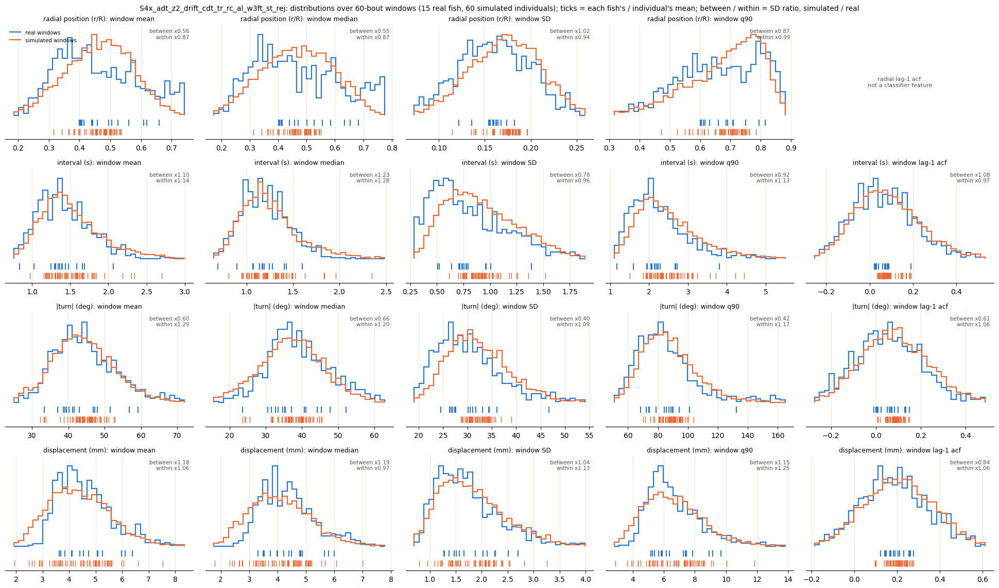

In [ ]:
# Model 24b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_24b = window_stats_grid("report_ckpts/M24b", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.41     0.94  0.15  0.88   3.0   5.0                  22.3 +/- 0.9  21.7 +/- 1.0
d2s3.5    2.67     2.08  2.64  1.55  11.0   7.0                  17.4 +/- 0.9  20.2 +/- 0.8
d4s3.5    1.03     0.70  4.68  3.06  19.0   7.0                  18.7 +/- 1.

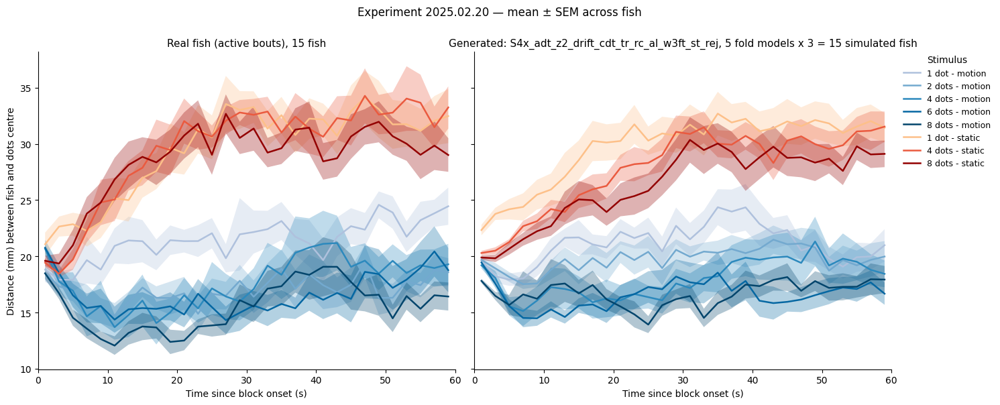

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M24b", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

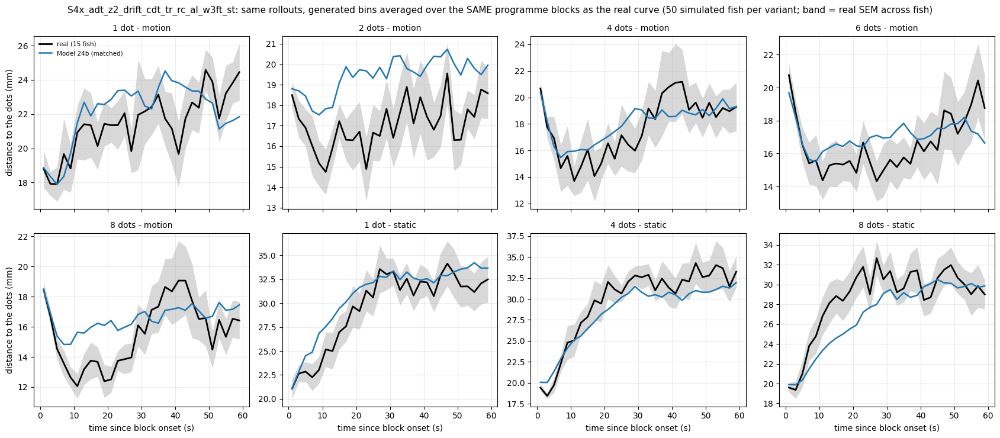

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_24b, _ = profile_variants_matched("report_ckpts/M24b", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 24b": {"arm": "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_24b, _ = attraction_table("report_ckpts/M24b", ["S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                               plateau   null attraction
cond_label                                                                                  
d1s3.5       22.41  23.57       1.16                                 22.63  22.67       0.04
d2s3.5       17.39  23.58       6.19                                 20.13  22.72       2.59
d4s3.5       18.74  23.93       5.19                                 18.92  22.62       3.70
d6s3.5       16.69  23.12       6.43                                 17.67  22.76       5.09
d8s3.5       16.41  23.36       6.94                                 16.85  22.72       5.86


In [ ]:
# Model 24b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_24b = toward_by_n("report_ckpts/M24b", ["S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_24b.round(2).to_string())

           real  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                              
0-20 s 1   9.09                                   9.73
       2  13.90                                  11.67
       4  15.73                                  13.59
       6  14.50                                  13.83
       8  16.00                                  16.66
4-20 s 1   6.25                                   8.54
       2  12.27                                  10.97
       4  14.35                                  12.46
       6  12.79                                  12.46
       8  15.11                                  15.18


Model 24b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 24b   real gap Model 24b    real gap Model 24b
cond                                                                  
d1s3.5  25.08         -9.99   6.64          3.45    7.55          1.83
d2s3.5  22.99         -5.22  12.94         -1.71   12.56         -1.52
d4s3.5  27.14         -7.68  15.54         -2.39   12.09          0.23
d6s3.5  32.55        -12.41  13.80          0.32   15.84         -2.28
d8s3.5  34.04        -10.05  14.45          2.04   13.80          1.08
d1s0     6.82         -5.84   4.22         -3.68    1.96         -0.53
d4s0     4.81         -2.15   1.86          0.52    1.74          1.83
d8s0     5.26         -1.96   2.63          0.74    2.39          1.98

turn size |Δθ| (deg): real f

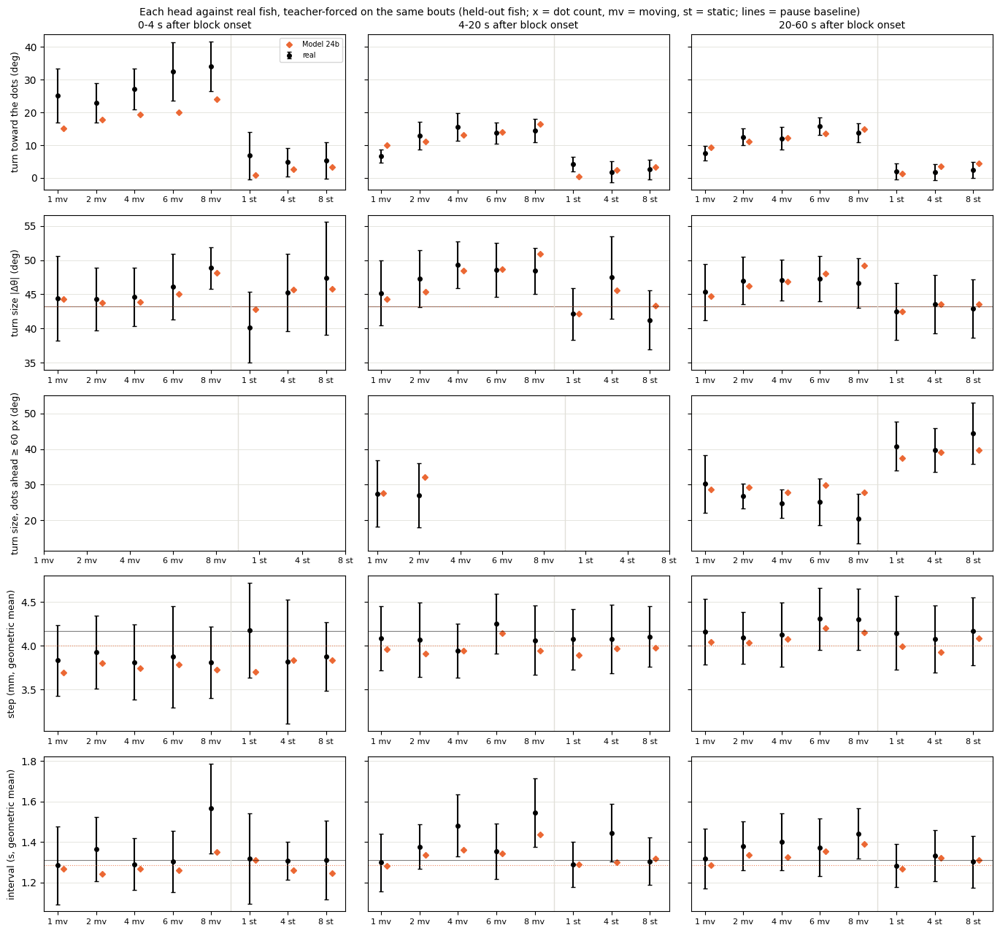

In [ ]:
# Model 24b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_24b, hg_24b = head_gaps({"Model 24b": ("report_ckpts/M24b", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

#### 18a + drift — seed 101 (key `24c`)

In [ ]:
# Model 24c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M24c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_24c = _l[_l.arm == "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_24c.index = ["turn", "displacement", "interval", "joint"]
print(lik_24c.round(3).to_string())

turn             7.629
displacement     4.502
interval         1.217
joint           13.348


In [ ]:
# Model 24c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_24c, c2st_24c = run(ckpt_dir="report_ckpts/M24c", arms="S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 711s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                              8.7466
symbol_js                                                  0.0146
dt_w1                                                      0.3858
dist_w1                                                    3.6137
trans_js                                                   0.0

In [ ]:
# Model 24c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M24c", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_24c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_24c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.673            0.010      0.614         0.010
matched to the real runs (same bouts, 1:1)            0.663            0.011      0.605         0.009



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.474         0.088        0.038          0.434         0.853
                      median           0.449       0.480         0.098        0.044          0.449         0.866
                      SD               0.159       0.177         0.015        0.008          0.523         0.952
                      q90              0.679       0.721         0.074        0.041

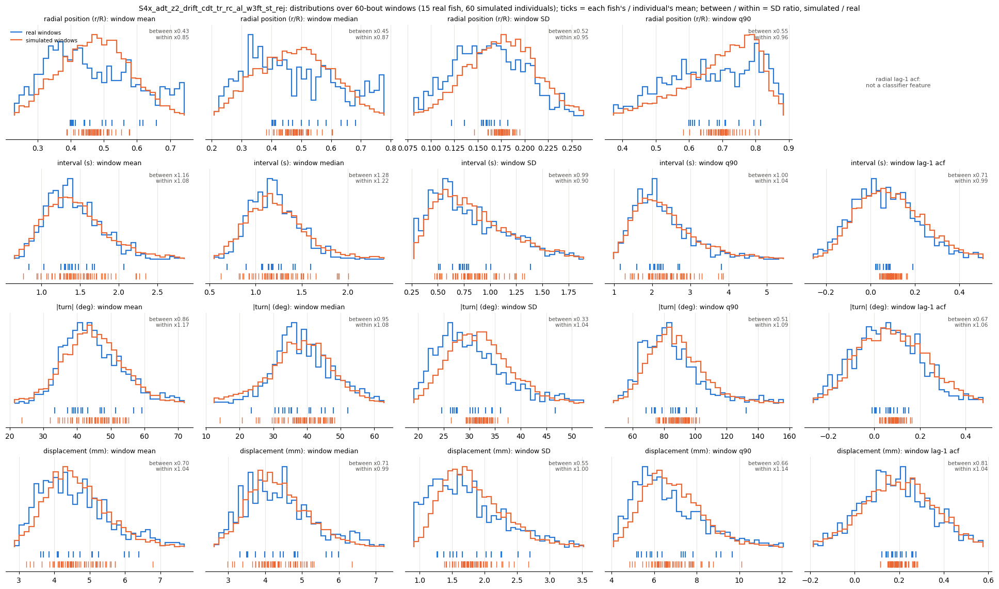

In [ ]:
# Model 24c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_24c = window_stats_grid("report_ckpts/M24c", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 13.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.90     1.27  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  23.3 +/- 1.4
d2s3.5    3.34     2.54  2.64  2.25  11.0   9.0                  17.4 +/- 0.9  21.3 +/- 1.5
d4s3.5    1.82     1.18  4.68  2.52  19.0   7.0                  18.7 +/- 1.

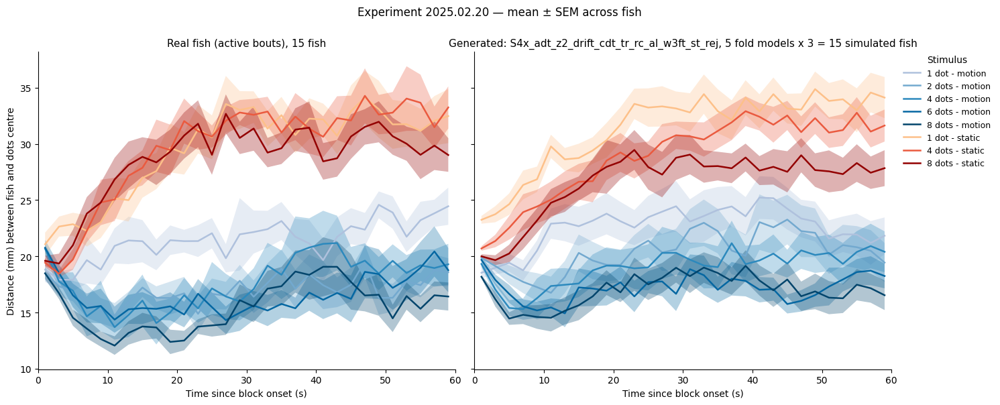

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M24c", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

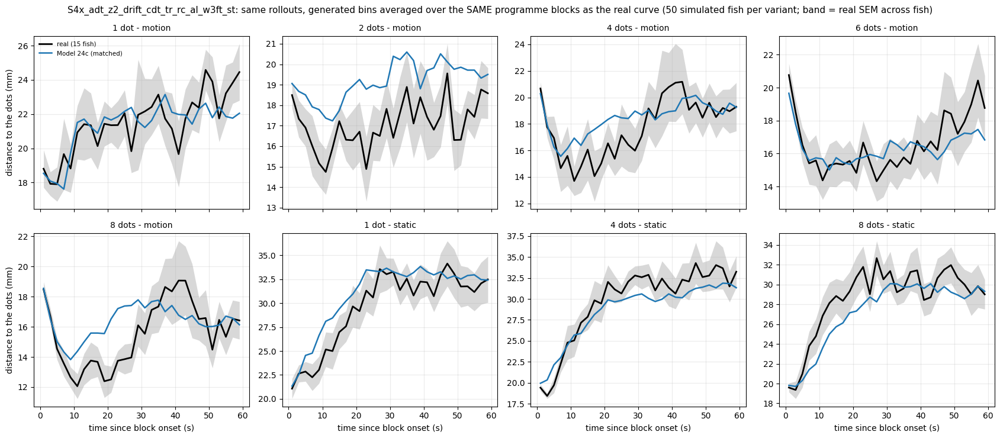

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_24c, _ = profile_variants_matched("report_ckpts/M24c", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 24c": {"arm": "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 24c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_24c, _ = attraction_table("report_ckpts/M24c", ["S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                               plateau   null attraction
cond_label                                                                                  
d1s3.5       22.41  23.57       1.16                                 22.48  23.26       0.78
d2s3.5       17.39  23.58       6.19                                 20.88  22.95       2.06
d4s3.5       18.74  23.93       5.19                                 19.10  23.25       4.15
d6s3.5       16.69  23.12       6.43                                 16.76  23.18       6.42
d8s3.5       16.41  23.36       6.94                                 16.89  22.97       6.08


In [ ]:
# Model 24c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_24c = toward_by_n("report_ckpts/M24c", ["S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_24c.round(2).to_string())

           real  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                              
0-20 s 1   9.09                                  10.43
       2  13.90                                  12.39
       4  15.73                                  14.35
       6  14.50                                  15.15
       8  16.00                                  18.27
4-20 s 1   6.25                                   9.15
       2  12.27                                  11.60
       4  14.35                                  13.08
       6  12.79                                  13.89
       8  15.11                                  16.44


Model 24c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 24c   real gap Model 24c    real gap Model 24c
cond                                                                  
d1s3.5  25.08         -9.07   6.64          4.23    7.55          2.70
d2s3.5  22.99         -5.19  12.94         -0.42   12.56         -0.81
d4s3.5  27.14         -6.33  15.54         -1.53   12.09          1.15
d6s3.5  32.55        -11.54  13.80          1.95   15.84         -1.21
d8s3.5  34.04         -6.91  14.45          3.78   13.80          2.56
d1s0     6.82         -5.11   4.22         -2.77    1.96          0.01
d4s0     4.81         -2.21   1.86          0.68    1.74          2.67
d8s0     5.26         -0.90   2.63          1.27    2.39          2.86

turn size |Δθ| (deg): real f

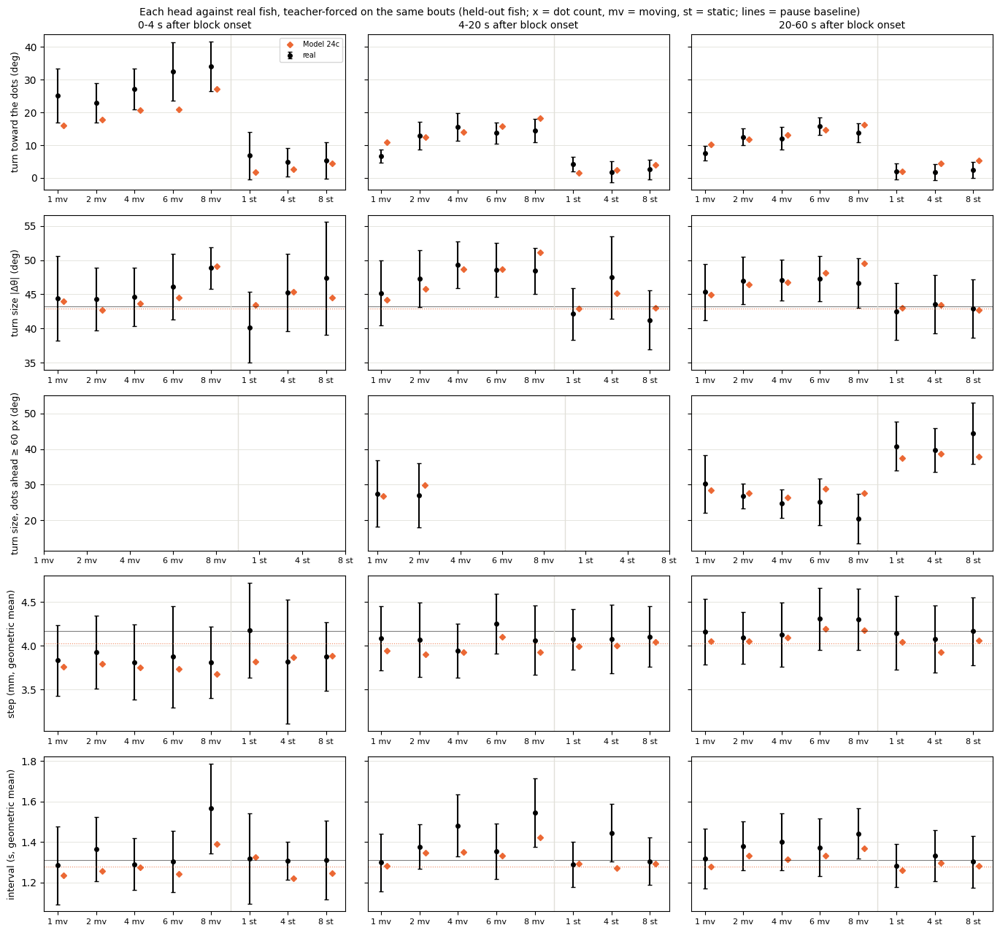

In [ ]:
# Model 24c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_24c, hg_24c = head_gaps({"Model 24c": ("report_ckpts/M24c", "S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

<a id="model-27"></a>
### Model 27

**Change:** the bump code (S4) instead of S4x, no drift

Without the drift, bumps vs S4x depends on the seed (worst at seed 0, best of all at seed 101).

#### Model 27 — seed 0 (key `16e`)

In [ ]:
# Model 16e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M16e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_16e = _l[_l.arm == "S4_adt_z2_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_16e.index = ["turn", "displacement", "interval", "joint"]
print(lik_16e.round(3).to_string())

turn             7.658
displacement     4.513
interval         1.236
joint           13.406


In [ ]:
# Model 16e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_16e, c2st_16e = run(ckpt_dir="report_ckpts/M16e", arms="S4_adt_z2_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 719s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                       7.1648
symbol_js                                           0.0094
dt_w1                                               0.4122
dist_w1                                             4.4254
trans_js                                            0.0115
acf_l2                                              0.0497
runlen_

In [ ]:
# Model 16e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M16e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_16e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_16e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.697            0.014      0.632         0.019
matched to the real runs (same bouts, 1:1)            0.686            0.015      0.623         0.018



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.462         0.088        0.037          0.417         0.902
                      median           0.449       0.461         0.098        0.041          0.414         0.915
                      SD               0.159       0.178         0.015        0.011          0.694         0.984
                      q90              0.679       0.719         0.074        0.045

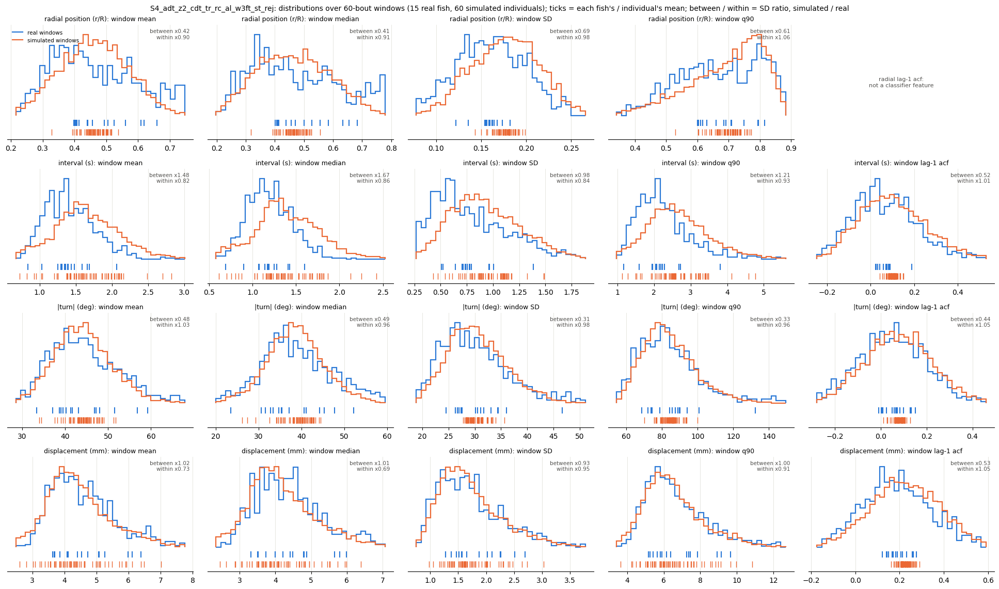

In [ ]:
# Model 16e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_16e = window_stats_grid("report_ckpts/M16e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.30     0.87  0.15  0.81   3.0   7.0                  22.3 +/- 0.9  21.8 +/- 0.8
d2s3.5    1.42     1.17  2.64   2.8  11.0  17.0                  17.4 +/- 0.9  18.3 +/- 1.0
d4s3.5    1.72     0.90  4.68  4.58  19.0  13.0                  18.7 +/- 1.7  16.5 +/- 0.7
d6s3.5    0.98     

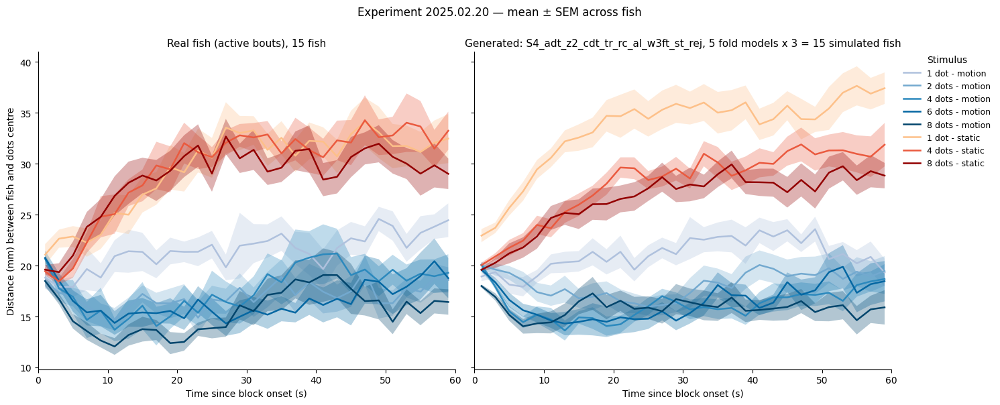

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 16e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M16e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

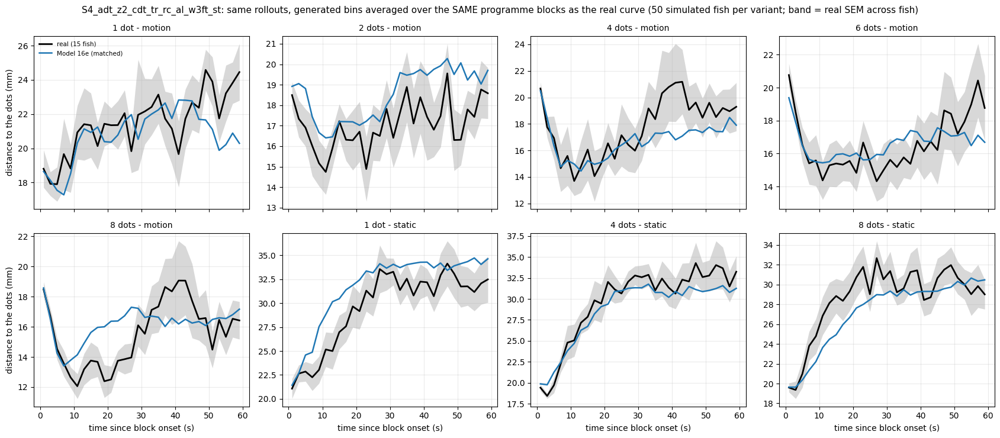

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 16e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_16e, _ = profile_variants_matched("report_ckpts/M16e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st", {"Model 16e": {"arm": "S4_adt_z2_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 16e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_16e, _ = attraction_table("report_ckpts/M16e", ["S4_adt_z2_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          21.97  22.10       0.13
d2s3.5       17.39  23.58       6.19                          18.28  22.34       4.06
d4s3.5       18.74  23.93       5.19                          17.13  22.09       4.96
d6s3.5       16.69  23.12       6.43                          17.34  22.10       4.76
d8s3.5       16.41  23.36       6.94                          16.39  22.63       6.24


In [ ]:
# Model 16e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_16e = toward_by_n("report_ckpts/M16e", ["S4_adt_z2_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_16e.round(2).to_string())

           real  S4_adt_z2_cdt_tr_rc_al_w3ft_st
win    N                                       
0-20 s 1   9.09                            9.92
       2  13.90                           11.87
       4  15.73                           12.99
       6  14.50                           13.94
       8  16.00                           15.94
4-20 s 1   6.25                            8.94
       2  12.27                           11.17
       4  14.35                           11.60
       6  12.79                           12.52
       8  15.11                           14.09


Model 16e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 16e   real gap Model 16e    real gap Model 16e
cond                                                                  
d1s3.5  25.08         -9.07   6.64          4.04    7.55          2.67
d2s3.5  22.99         -5.03  12.94         -1.01   12.56         -1.44
d4s3.5  27.14         -7.05  15.54         -3.28   12.09          0.09
d6s3.5  32.55        -11.17  13.80          0.63   15.84         -2.13
d8s3.5  34.04         -9.35  14.45          1.29   13.80          0.56
d1s0     6.82         -6.10   4.22         -3.31    1.96         -0.25
d4s0     4.81         -2.33   1.86          0.89    1.74          2.40
d8s0     5.26         -0.81   2.63          1.25    2.39          2.93

turn size |Δθ| (deg): real f

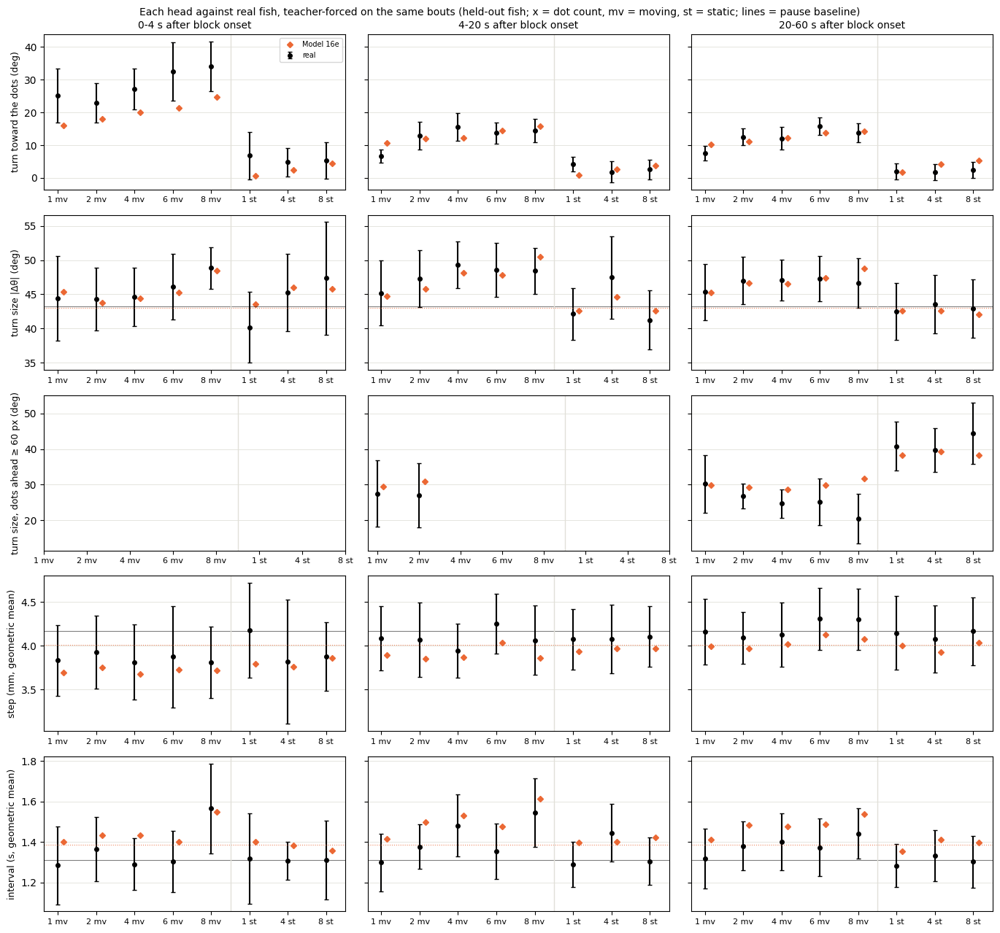

In [ ]:
# Model 16e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_16e, hg_16e = head_gaps({"Model 16e": ("report_ckpts/M16e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

#### Model 27 — seed 101 (key `30e`)

In [ ]:
# Model 30e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M30e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_30e = _l[_l.arm == "S4_adt_z2_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_30e.index = ["turn", "displacement", "interval", "joint"]
print(lik_30e.round(3).to_string())

turn             7.658
displacement     4.501
interval         1.243
joint           13.402


In [ ]:
# Model 30e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_30e, c2st_30e = run(ckpt_dir="report_ckpts/M30e", arms="S4_adt_z2_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 779s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                       8.6466
symbol_js                                           0.0123
dt_w1                                               0.3506
dist_w1                                             4.3401
trans_js                                            0.0137
acf_l2                                              0.0458
runlen_

In [ ]:
# Model 30e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M30e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_30e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_30e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.639            0.020      0.539         0.021
matched to the real runs (same bouts, 1:1)            0.625            0.019      0.528         0.019



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.452         0.088        0.042          0.482         0.906
                      median           0.449       0.448         0.098        0.045          0.465         0.910
                      SD               0.159       0.179         0.015        0.015          0.955         0.989
                      q90              0.679       0.711         0.074        0.057

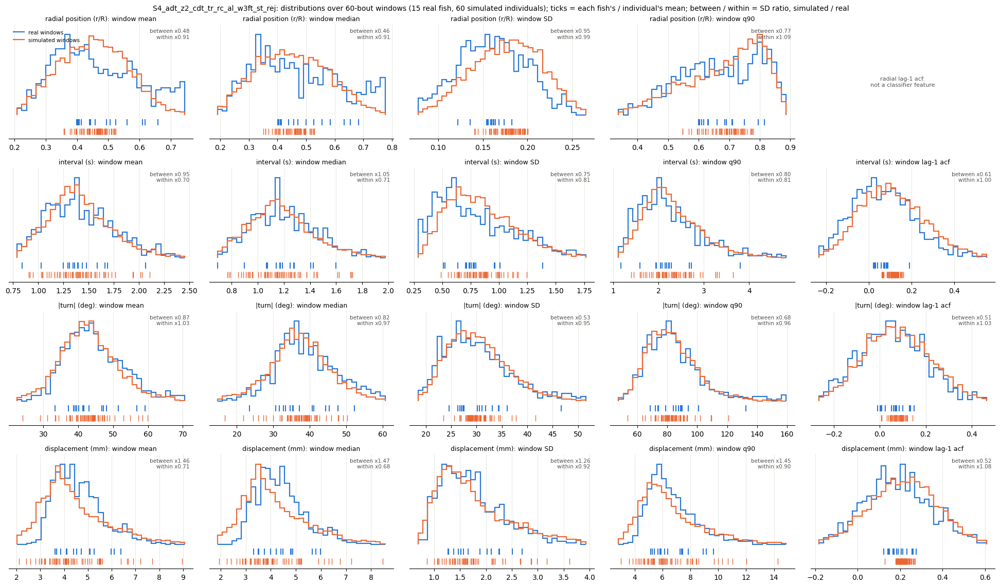

In [ ]:
# Model 30e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_30e = window_stats_grid("report_ckpts/M30e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 9.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.42     1.01  0.15  0.53   3.0   5.0                  22.3 +/- 0.9  21.4 +/- 1.1
d2s3.5    2.22     1.70  2.64  2.28  11.0  13.0                  17.4 +/- 0.9  19.7 +/- 0.9
d4s3.5    1.36     0.72  4.68  4.12  19.0  11.0                  18.7 +/- 1.7  17.4 +/- 0.9
d6s3.5    1.31     0

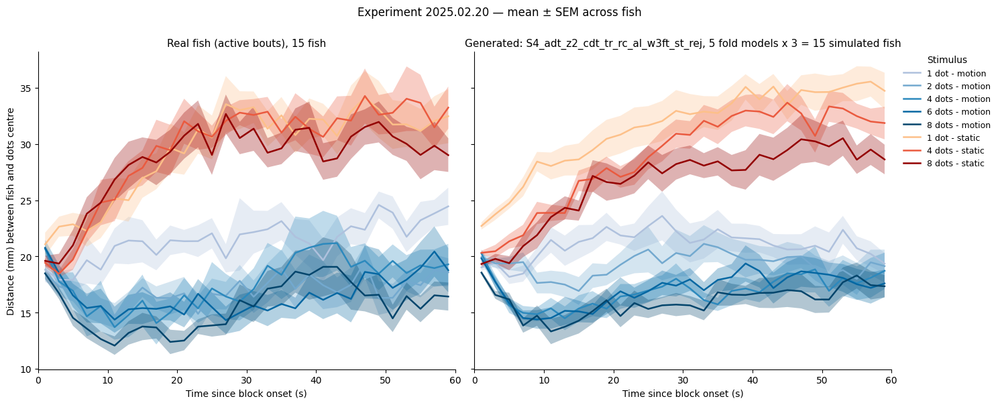

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M30e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

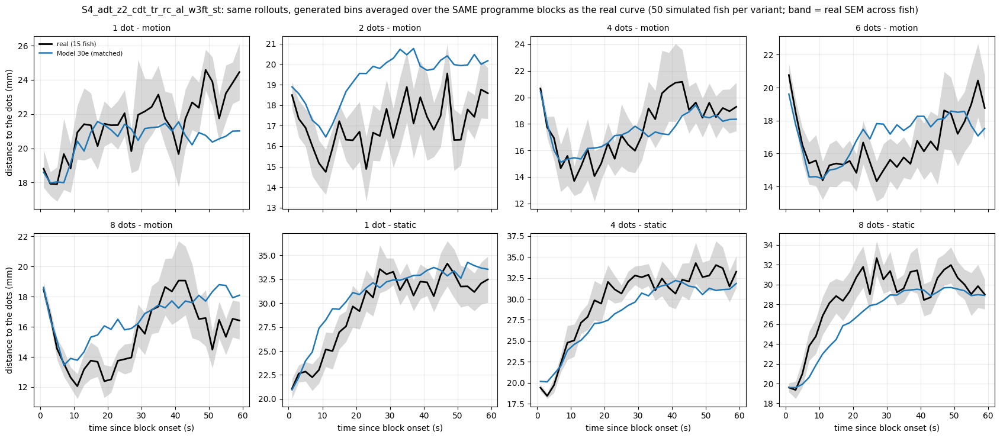

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_30e, _ = profile_variants_matched("report_ckpts/M30e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st", {"Model 30e": {"arm": "S4_adt_z2_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 30e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_30e, _ = attraction_table("report_ckpts/M30e", ["S4_adt_z2_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          20.81  21.98       1.17
d2s3.5       17.39  23.58       6.19                          19.58  21.69       2.11
d4s3.5       18.74  23.93       5.19                          17.42  22.08       4.66
d6s3.5       16.69  23.12       6.43                          18.35  21.75       3.40
d8s3.5       16.41  23.36       6.94                          17.03  21.64       4.61


In [ ]:
# Model 30e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_30e = toward_by_n("report_ckpts/M30e", ["S4_adt_z2_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_30e.round(2).to_string())

           real  S4_adt_z2_cdt_tr_rc_al_w3ft_st
win    N                                       
0-20 s 1   9.09                            9.96
       2  13.90                           12.01
       4  15.73                           13.02
       6  14.50                           14.38
       8  16.00                           16.87
4-20 s 1   6.25                            8.84
       2  12.27                           11.30
       4  14.35                           11.33
       6  12.79                           12.82
       8  15.11                           15.02


Model 30e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 30e   real gap Model 30e    real gap Model 30e
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.91    7.55          2.19
d2s3.5  22.99         -4.56  12.94         -0.91   12.56         -1.67
d4s3.5  27.14         -6.11  15.54         -3.53   12.09         -0.35
d6s3.5  32.55        -10.65  13.80          0.82   15.84         -2.45
d8s3.5  34.04         -9.08  14.45          2.01   13.80          1.01
d1s0     6.82         -6.99   4.22         -3.63    1.96         -0.09
d4s0     4.81         -3.13   1.86          0.53    1.74          2.23
d8s0     5.26         -1.31   2.63          1.02    2.39          2.48

turn size |Δθ| (deg): real f

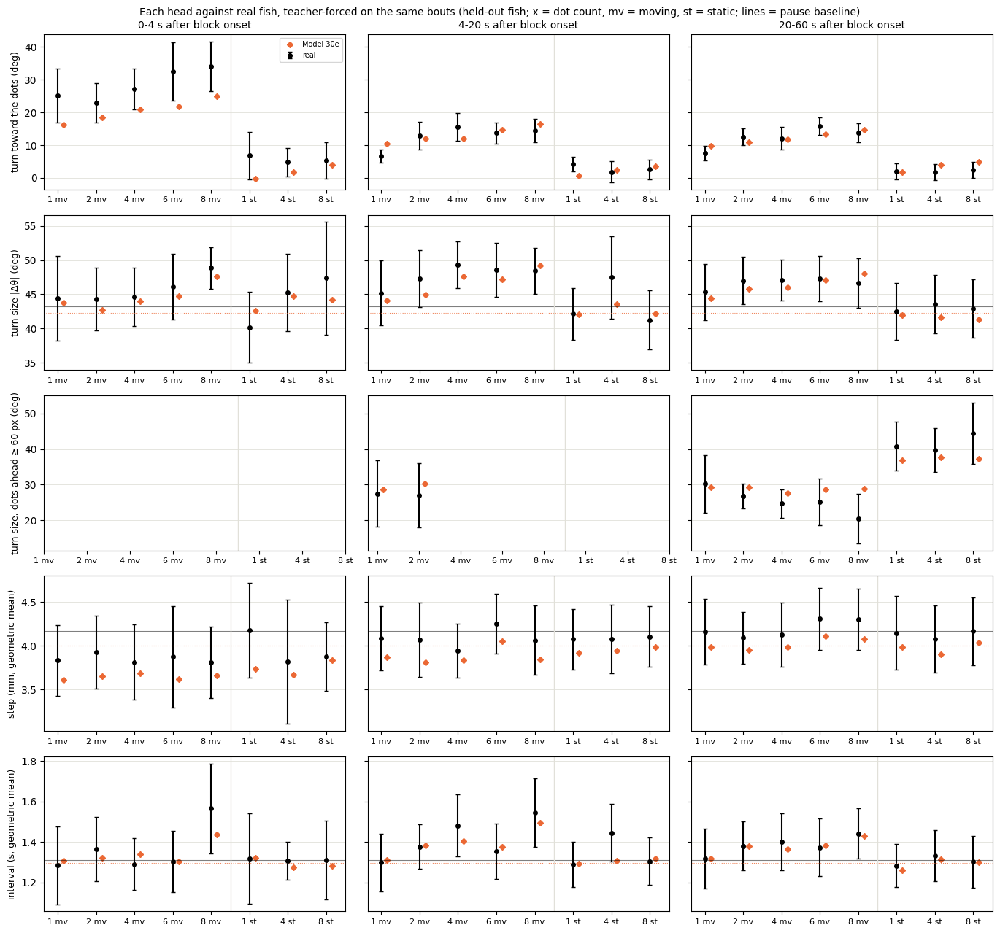

In [ ]:
# Model 30e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_30e, hg_30e = head_gaps({"Model 30e": ("report_ckpts/M30e", "S4_adt_z2_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

<a id="model-17"></a>
### Model 17

**Change:** Model 27 + drift

Best likelihood (−0.062 | −0.046 bits). Both seeds on per-block streams: seed 0 = key 11e (9a / 12a are the same checkpoint on the old stream), seed 101 = key 32a (12b's checkpoints re-evaluated).

#### Model 17 — seed 0 (key `11e`)

In [ ]:
# Model 11e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M11e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_11e = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_11e.index = ["turn", "displacement", "interval", "joint"]
print(lik_11e.round(3).to_string())

turn             7.627
displacement     4.513
interval         1.203
joint           13.344


In [ ]:
# Model 11e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_11e, c2st_11e = run(ckpt_dir="report_ckpts/M11e", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 805s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.7966
symbol_js                                                 0.0133
dt_w1                                                     0.4371
dist_w1                                                   4.6584
trans_js                                                  0.0153
acf_l2

In [ ]:
# Model 11e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M11e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_11e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_11e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.647            0.009      0.570         0.013
matched to the real runs (same bouts, 1:1)            0.634            0.008      0.559         0.013



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.464         0.088        0.044          0.507         0.887
                      median           0.449       0.466         0.098        0.049          0.496         0.888
                      SD               0.159       0.173         0.015        0.014          0.932         0.963
                      q90              0.679       0.711         0.074        0.058

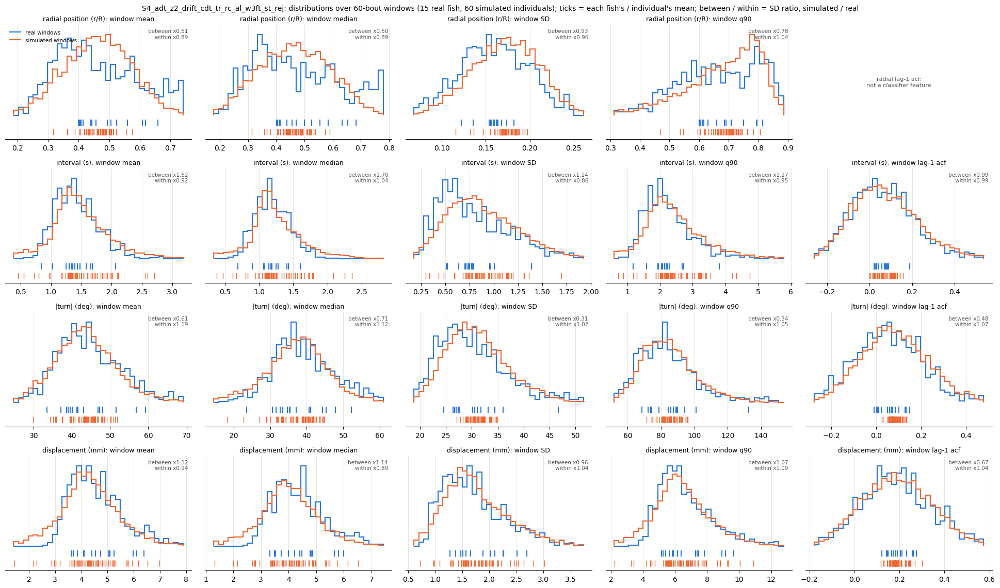

In [ ]:
# Model 11e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_11e = window_stats_grid("report_ckpts/M11e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 9.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.52     1.02  0.15  0.94   3.0   5.0                  22.3 +/- 0.9  20.6 +/- 1.1
d2s3.5    1.65     1.33  2.64  2.48  11.0  11.0                  17.4 +/- 0.9  18.2 +/- 0.9
d4s3.5    1.26     0.70  4.68  4.16  19.0   9.0                  18.7 +/- 1.7  17.

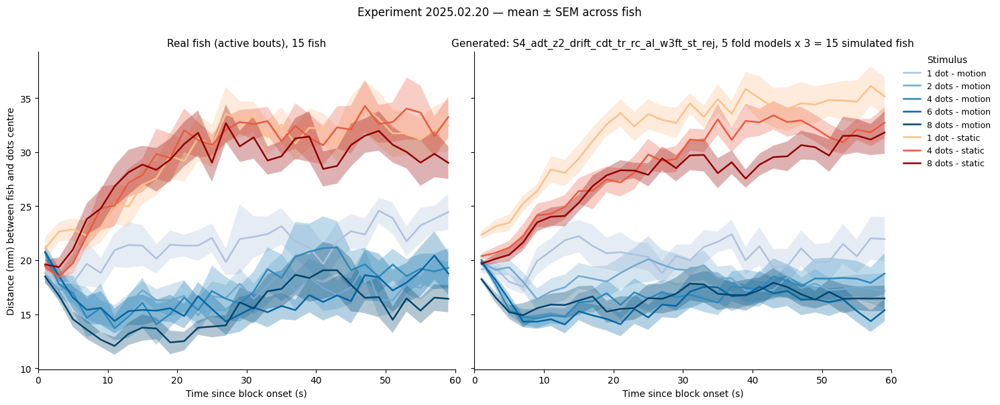

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 11e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M11e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

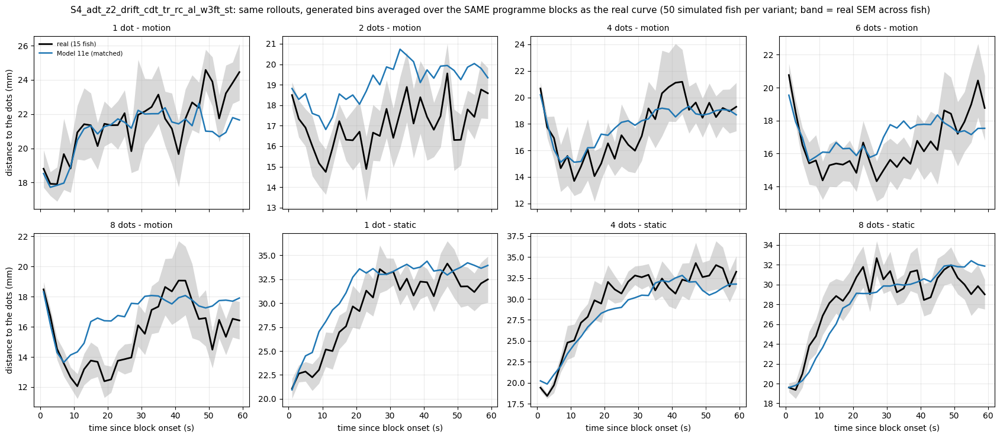

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 11e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_11e, _ = profile_variants_matched("report_ckpts/M11e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 11e": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 11e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_11e, _ = attraction_table("report_ckpts/M11e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                22.03  22.58       0.55
d2s3.5       17.39  23.58       6.19                                18.62  22.48       3.86
d4s3.5       18.74  23.93       5.19                                18.67  22.32       3.65
d6s3.5       16.69  23.12       6.43                                17.25  22.52       5.28
d8s3.5       16.41  23.36       6.94                                17.29  22.24       4.96


In [ ]:
# Model 11e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_11e = toward_by_n("report_ckpts/M11e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_11e.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                             
0-20 s 1   9.09                                  9.59
       2  13.90                                 11.44
       4  15.73                                 12.80
       6  14.50                                 13.38
       8  16.00                                 15.57
4-20 s 1   6.25                                  8.44
       2  12.27                                 10.47
       4  14.35                                 11.33
       6  12.79                                 11.79
       8  15.11                                 13.53


Model 11e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 11e   real gap Model 11e    real gap Model 11e
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.93    7.55          1.91
d2s3.5  22.99         -4.88  12.94         -1.98   12.56         -2.17
d4s3.5  27.14         -6.92  15.54         -3.59   12.09         -0.72
d6s3.5  32.55         -9.65  13.80         -0.30   15.84         -3.07
d8s3.5  34.04         -8.25  14.45          0.41   13.80         -0.08
d1s0     6.82         -6.47   4.22         -3.10    1.96          0.12
d4s0     4.81         -2.04   1.86          0.95    1.74          1.96
d8s0     5.26         -0.72   2.63          1.08    2.39          2.55

turn size |Δθ| (deg): real f

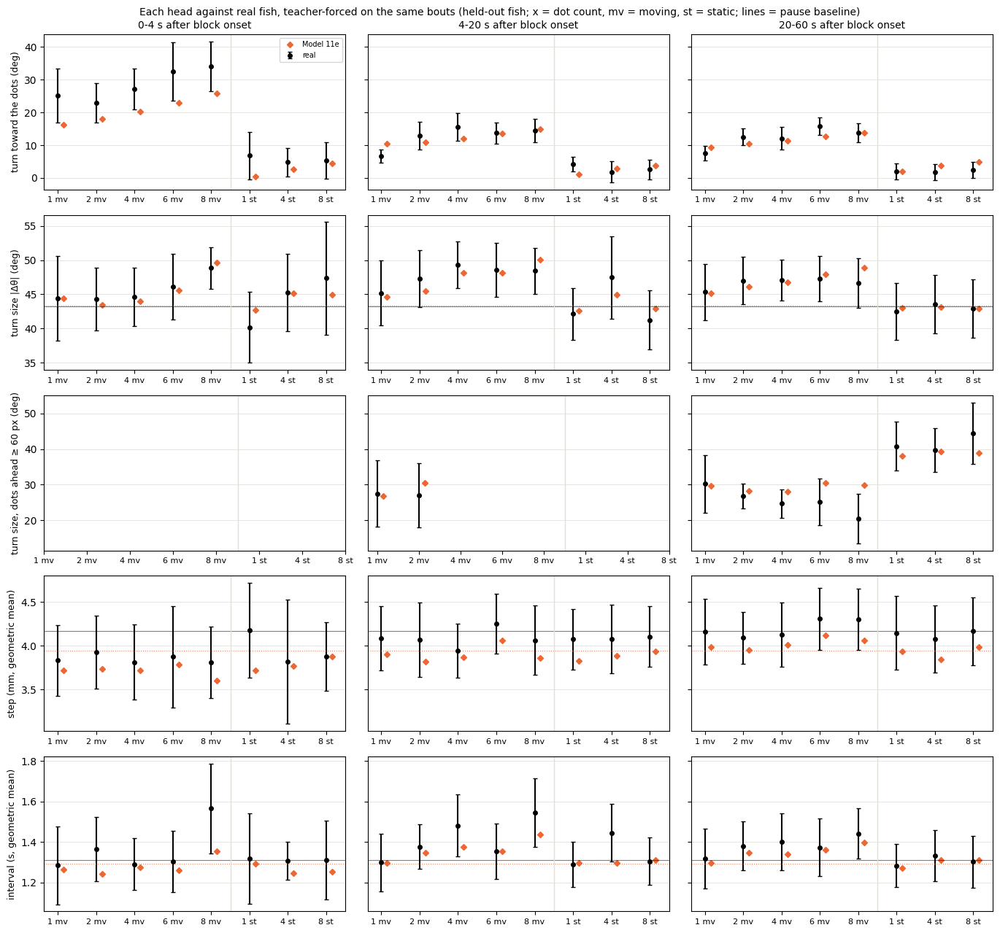

In [ ]:
# Model 11e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_11e, hg_11e = head_gaps({"Model 11e": ("report_ckpts/M11e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

#### Model 17 — seed 101 (key `32a`)

In [ ]:
# Model 32a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M32a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_32a = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_32a.index = ["turn", "displacement", "interval", "joint"]
print(lik_32a.round(3).to_string())

turn             7.630
displacement     4.520
interval         1.207
joint           13.356


In [ ]:
# Model 32a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_32a, c2st_32a = run(ckpt_dir="report_ckpts/M32a", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 486s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.2571
symbol_js                                                 0.0123
dt_w1                                                     0.3781
dist_w1                                                   3.5625
trans_js                                                  0.0137
acf_l2

In [ ]:
# Model 32a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M32a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_32a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_32a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.636            0.022      0.546         0.020
matched to the real runs (same bouts, 1:1)            0.628            0.022      0.538         0.021



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.476         0.088        0.037          0.420         0.851
                      median           0.449       0.481         0.098        0.042          0.425         0.866
                      SD               0.159       0.176         0.015        0.011          0.730         0.921
                      q90              0.679       0.720         0.074        0.044

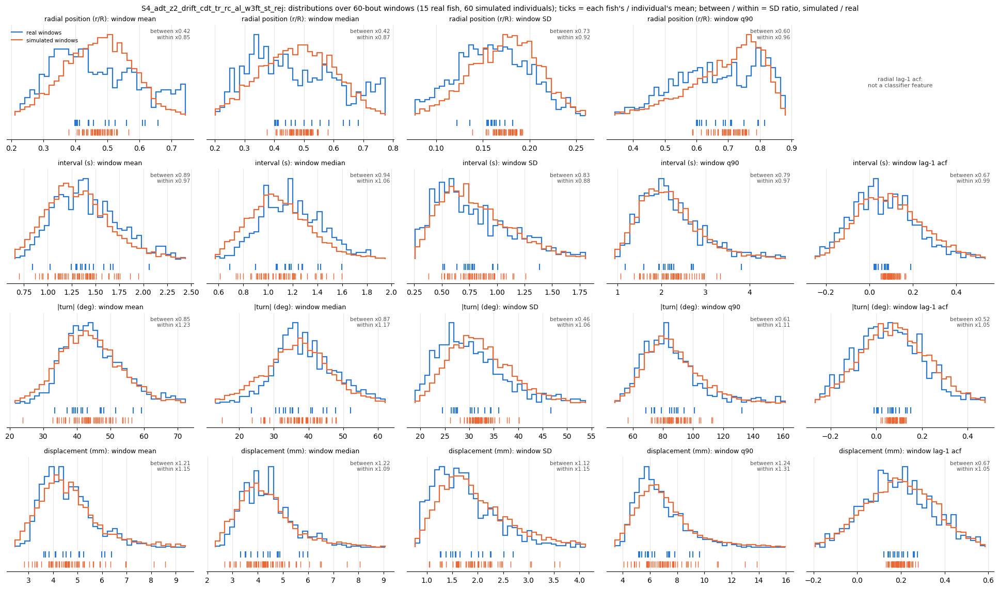

In [ ]:
# Model 32a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_32a = window_stats_grid("report_ckpts/M32a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 11.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.61     1.14  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  21.5 +/- 0.9
d2s3.5    1.86     1.40  2.64  1.97  11.0  11.0                  17.4 +/- 0.9  19.4 +/- 1.0
d4s3.5    1.65     1.03  4.68  3.06  19.0   7.0                  18.7 +/- 1.7  19

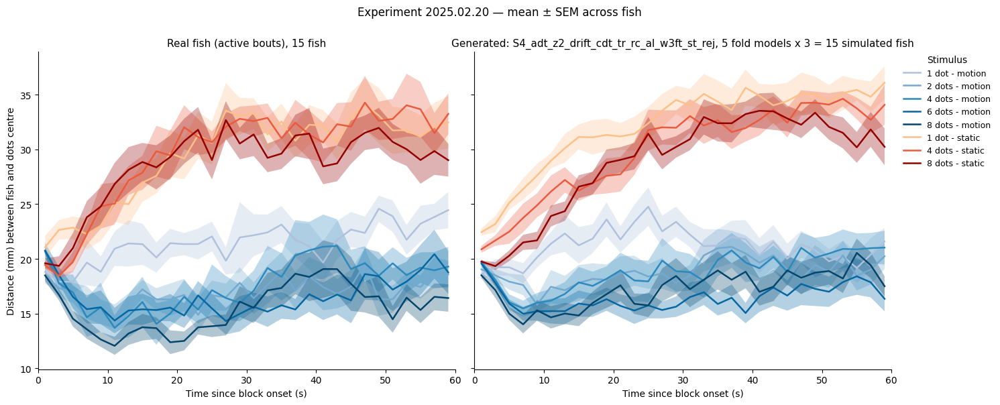

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 32a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M32a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

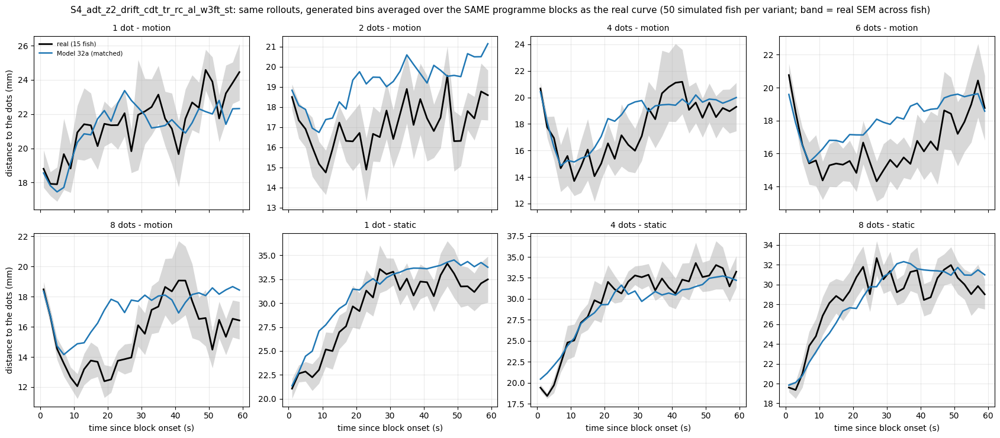

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 32a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_32a, _ = profile_variants_matched("report_ckpts/M32a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 32a": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 32a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_32a, _ = attraction_table("report_ckpts/M32a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.89  22.70       0.81
d2s3.5       17.39  23.58       6.19                                19.63  22.65       3.01
d4s3.5       18.74  23.93       5.19                                19.62  22.57       2.94
d6s3.5       16.69  23.12       6.43                                18.87  22.55       3.68
d8s3.5       16.41  23.36       6.94                                17.77  22.76       4.99


In [ ]:
# Model 32a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_32a = toward_by_n("report_ckpts/M32a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_32a.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                             
0-20 s 1   9.09                                  9.97
       2  13.90                                 11.86
       4  15.73                                 12.79
       6  14.50                                 13.30
       8  16.00                                 16.68
4-20 s 1   6.25                                  8.80
       2  12.27                                 10.94
       4  14.35                                 11.25
       6  12.79                                 11.46
       8  15.11                                 14.89


Model 32a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 32a   real gap Model 32a    real gap Model 32a
cond                                                                  
d1s3.5  25.08         -9.06   6.64          4.12    7.55          2.22
d2s3.5  22.99         -4.49  12.94         -1.00   12.56         -1.60
d4s3.5  27.14         -5.93  15.54         -4.12   12.09         -0.52
d6s3.5  32.55        -10.88  13.80          0.62   15.84         -2.56
d8s3.5  34.04         -7.96  14.45          1.54   13.80          0.79
d1s0     6.82         -5.60   4.22         -2.98    1.96          0.07
d4s0     4.81         -2.53   1.86          0.11    1.74          1.83
d8s0     5.26         -1.37   2.63         -0.19    2.39          1.67

turn size |Δθ| (deg): real f

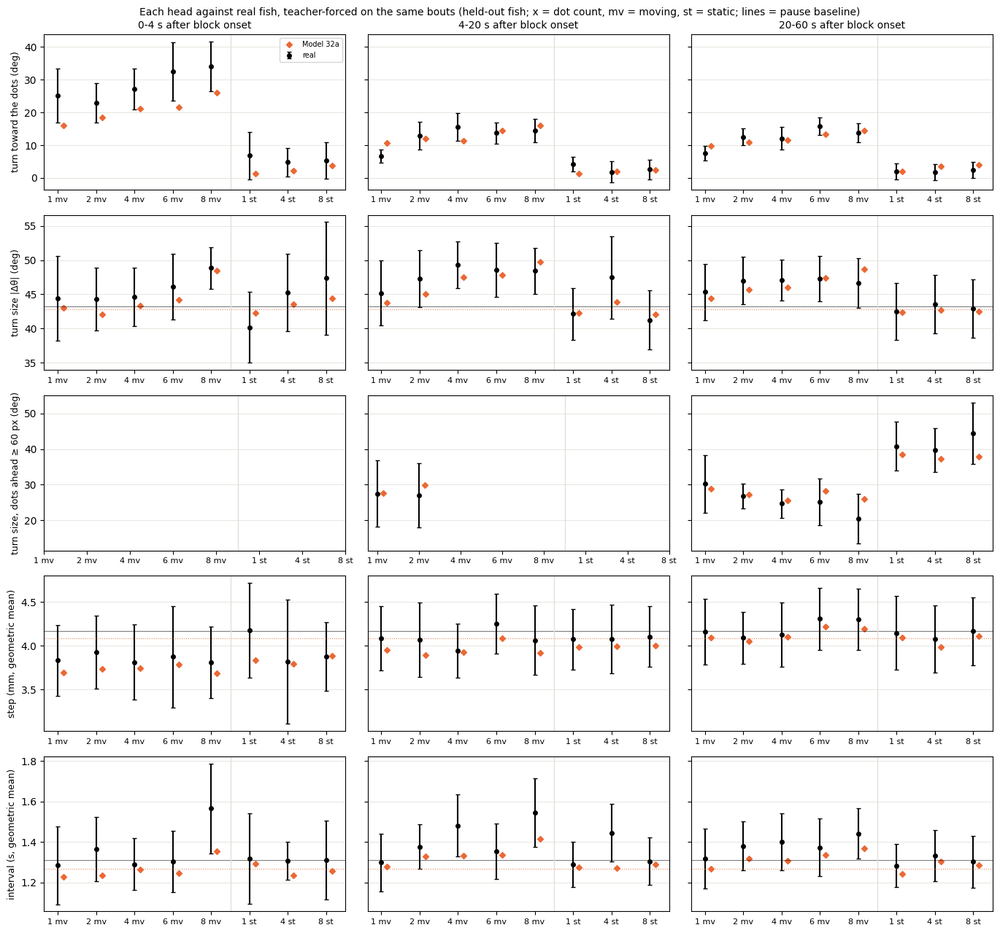

In [ ]:
# Model 32a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_32a, hg_32a = head_gaps({"Model 32a": ("report_ckpts/M32a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

<a id="m14f"></a>
### 14f — the final model

**Change:** Model 17 + profile correction (pf-B, 20 s cut-off, final-step numbers)

Best likelihood and the only model with slow structure, with the profiles restored by the correction (dip +0.8 mm, grading +1.8 mm, moving error −0.3); AUC tied with the no-drift models.

#### 14f — the final model — seed 0 (key `14f`)

In [ ]:
# Model 14f: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M14f/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_14f = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_14f.index = ["turn", "displacement", "interval", "joint"]
print(lik_14f.round(3).to_string())

turn             7.628
displacement     4.513
interval         1.203
joint           13.344


In [ ]:
# Model 14f: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_14f, c2st_14f = run(ckpt_dir="report_ckpts/M14f", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 1141s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                         8.7375
symbol_js                                                             0.0133
dt_w1                                                                 0.4382
dist_w1                                

In [ ]:
# Model 14f: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M14f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_14f = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_14f.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.644            0.010      0.569         0.015
matched to the real runs (same bouts, 1:1)            0.641            0.008      0.561         0.013



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.464         0.088        0.044          0.504         0.897
                      median           0.449       0.466         0.098        0.048          0.496         0.897
                      SD               0.159       0.173         0.015        0.015          0.951         0.947
                      q90              0.679       0.709         0.074        0.059

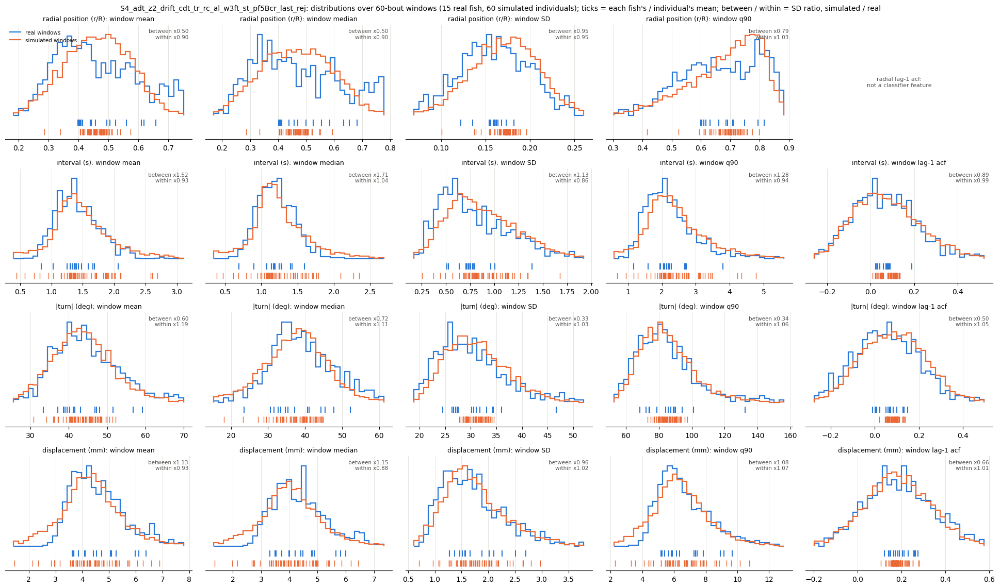

In [ ]:
# Model 14f: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_14f = window_stats_grid("report_ckpts/M14f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 8.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.24     0.83  0.15  0.23   3.0   3.0                  22.3 +/- 0.9  21.2 +/- 0.9
d2s3.5    1.09     0.88  2.64  3.01  11.0  15.0                  17.4 +/- 0.9  18.2 +/- 1.2
d4s3.5    1.33     0.7

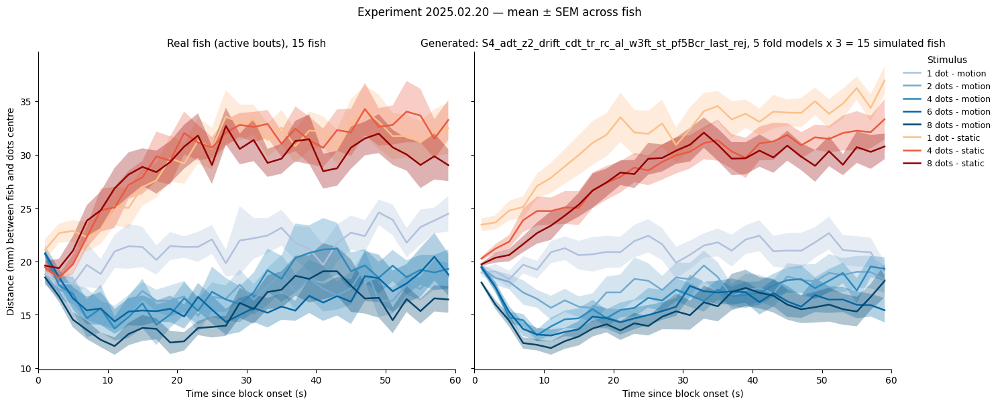

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 14f: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M14f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

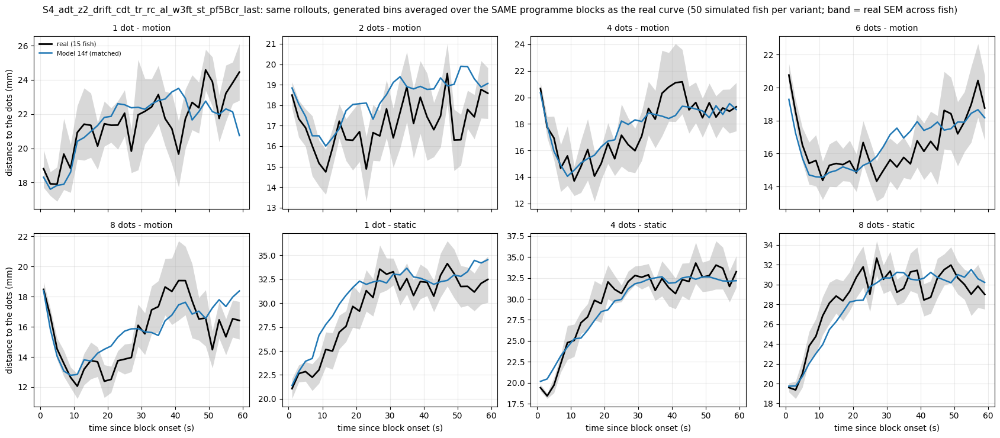

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 14f: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_14f, _ = profile_variants_matched("report_ckpts/M14f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", {"Model 14f": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 14f: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_14f, _ = attraction_table("report_ckpts/M14f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                          plateau   null attraction
cond_label                                                                                             
d1s3.5       22.41  23.57       1.16                                            22.10  22.48       0.38
d2s3.5       17.39  23.58       6.19                                            18.70  22.57       3.87
d4s3.5       18.74  23.93       5.19                                            18.12  22.72       4.60
d6s3.5       16.69  23.12       6.43                                            17.01  22.61       5.60
d8s3.5       16.41  23.36       6.94                                

In [ ]:
# Model 14f: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_14f = toward_by_n("report_ckpts/M14f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_14f.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
win    N                                                         
0-20 s 1   9.09                                              9.59
       2  13.90                                             14.26
       4  15.73                                             16.21
       6  14.50                                             17.00
       8  16.00                                             19.76
4-20 s 1   6.25                                              8.44
       2  12.27                                             13.48
       4  14.35                                             15.06
       6  12.79                                             15.59
       8  15.11                                             18.02


Model 14f: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 14f   real gap Model 14f    real gap Model 14f
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.93    7.55          1.91
d2s3.5  22.99         -2.18  12.94          0.86   12.56         -1.84
d4s3.5  27.14         -4.40  15.54          0.04   12.09         -0.40
d6s3.5  32.55         -7.12  13.80          3.47   15.84         -2.73
d8s3.5  34.04         -5.81  14.45          4.62   13.80          0.45
d1s0     6.82         -6.47   4.22         -3.10    1.96          0.12
d4s0     4.81         -2.04   1.86          0.95    1.74          1.96
d8s0     5.26         -0.72   2.63          1.08    2.39          2.55

turn size |Δθ| (deg): real f

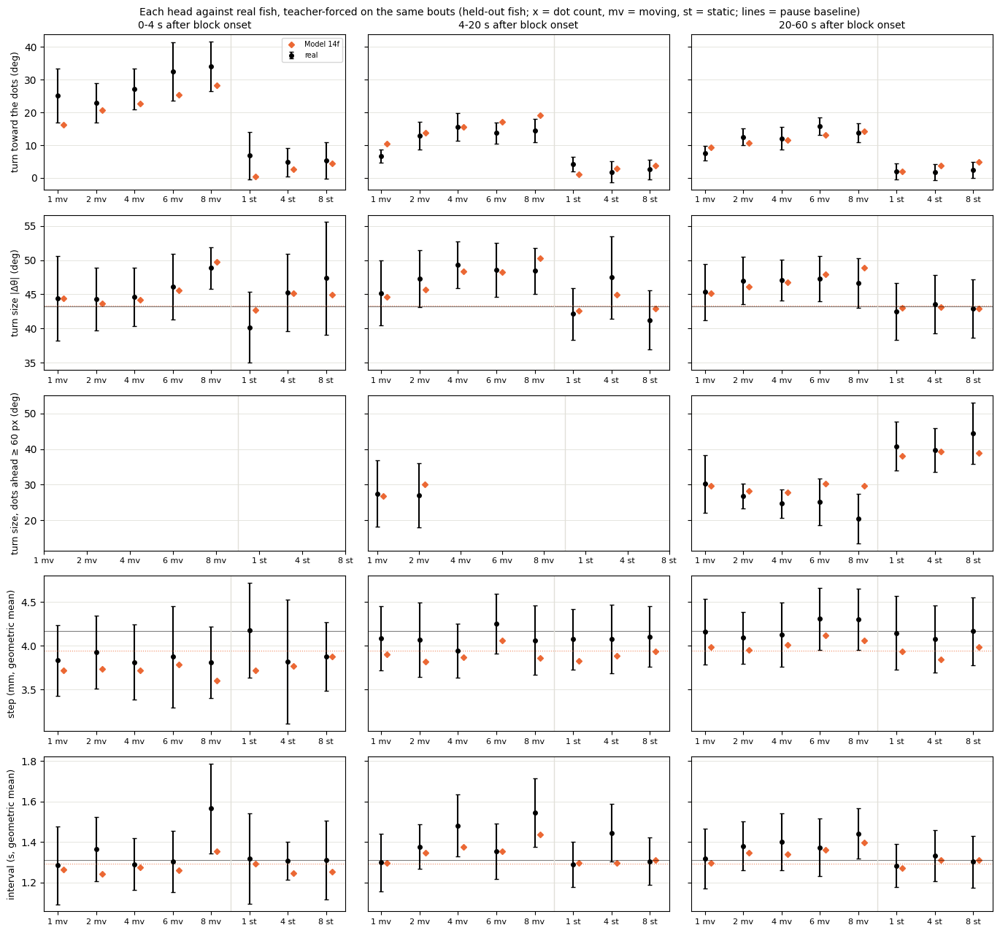

In [ ]:
# Model 14f: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_14f, hg_14f = head_gaps({"Model 14f": ("report_ckpts/M14f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last")}, rej=REJ["wall_reject"])

#### 14f — the final model — seed 101 (key `32b`)

In [ ]:
# Model 32b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M32b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_32b = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_32b.index = ["turn", "displacement", "interval", "joint"]
print(lik_32b.round(3).to_string())

turn             7.630
displacement     4.520
interval         1.207
joint           13.357


In [ ]:
# Model 32b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_32b, c2st_32b = run(ckpt_dir="report_ckpts/M32b", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 498s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                         8.2795
symbol_js                                                             0.0121
dt_w1                                                                 0.3790
dist_w1                                 

In [ ]:
# Model 32b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M32b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_32b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_32b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.640            0.023      0.557         0.021
matched to the real runs (same bouts, 1:1)            0.643            0.021      0.555         0.019



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.478         0.088        0.037          0.416         0.835
                      median           0.449       0.482         0.098        0.042          0.427         0.847
                      SD               0.159       0.176         0.015        0.010          0.617         0.929
                      q90              0.679       0.720         0.074        0.041

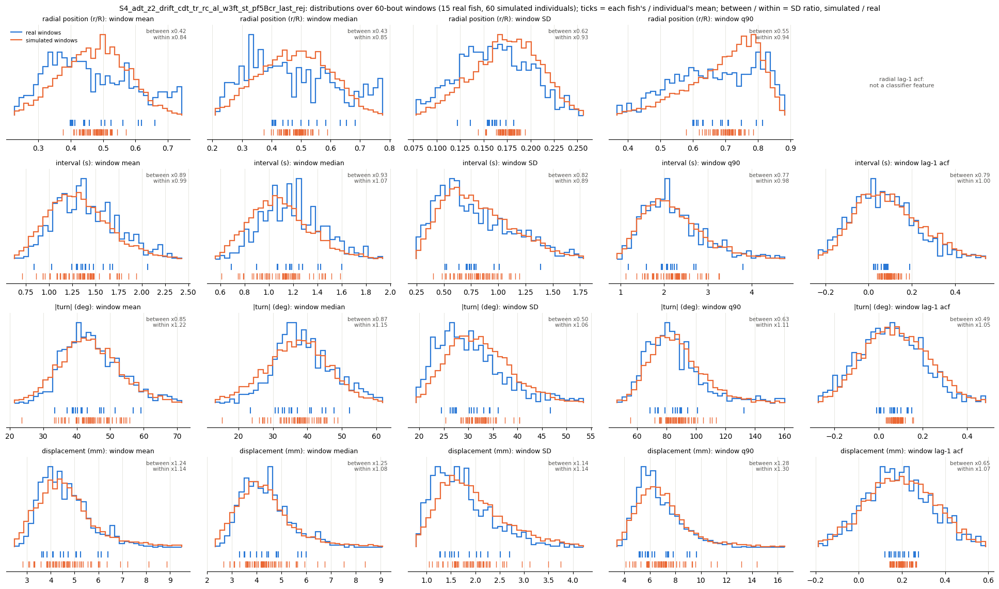

In [ ]:
# Model 32b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_32b = window_stats_grid("report_ckpts/M32b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.44     0.95  0.15  0.62   3.0   5.0                  22.3 +/- 0.9  23.0 +/- 1.0
d2s3.5    1.29     1.05  2.64  2.97  11.0   9.0                  17.4 +/- 0.9  18.6 +/- 0.7
d4s3.5    1.32     0.

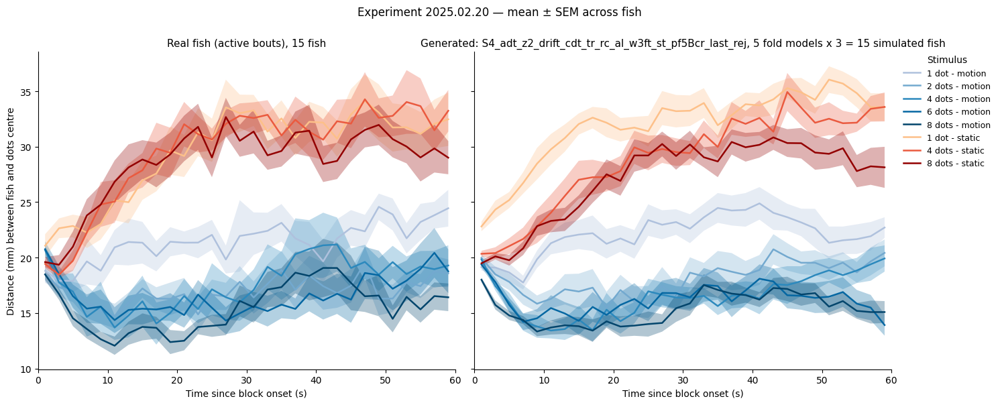

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 32b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M32b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

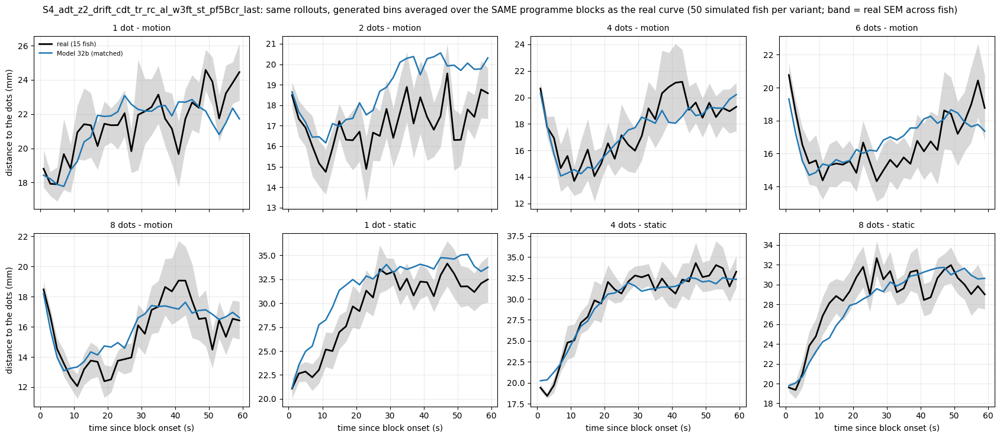

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 32b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_32b, _ = profile_variants_matched("report_ckpts/M32b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", {"Model 32b": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 32b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_32b, _ = attraction_table("report_ckpts/M32b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                          plateau   null attraction
cond_label                                                                                             
d1s3.5       22.41  23.57       1.16                                            23.01  22.39      -0.62
d2s3.5       17.39  23.58       6.19                                            19.47  22.39       2.92
d4s3.5       18.74  23.93       5.19                                            17.95  22.54       4.58
d6s3.5       16.69  23.12       6.43                                            17.20  22.56       5.36
d8s3.5       16.41  23.36       6.94                                

In [ ]:
# Model 32b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_32b = toward_by_n("report_ckpts/M32b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_32b.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
win    N                                                         
0-20 s 1   9.09                                              9.97
       2  13.90                                             14.00
       4  15.73                                             16.21
       6  14.50                                             16.79
       8  16.00                                             21.01
4-20 s 1   6.25                                              8.80
       2  12.27                                             13.25
       4  14.35                                             14.97
       6  12.79                                             15.19
       8  15.11                                             19.45


Model 32b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 32b   real gap Model 32b    real gap Model 32b
cond                                                                  
d1s3.5  25.08         -9.06   6.64          4.12    7.55          2.22
d2s3.5  22.99         -2.29  12.94          1.15   12.56         -1.36
d4s3.5  27.14         -3.32  15.54         -0.45   12.09         -0.22
d6s3.5  32.55         -8.34  13.80          4.30   15.84         -2.19
d8s3.5  34.04         -4.91  14.45          5.91   13.80          1.34
d1s0     6.82         -5.60   4.22         -2.98    1.96          0.07
d4s0     4.81         -2.53   1.86          0.11    1.74          1.83
d8s0     5.26         -1.37   2.63         -0.19    2.39          1.67

turn size |Δθ| (deg): real f

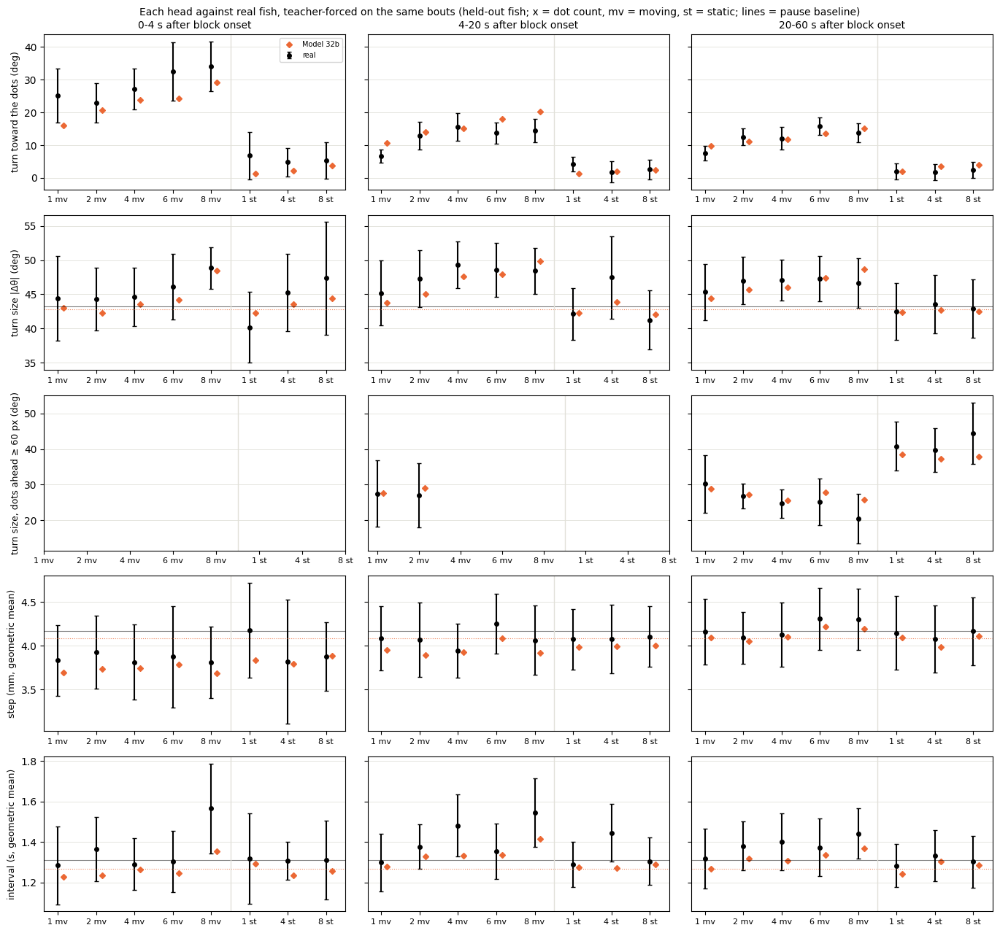

In [ ]:
# Model 32b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_32b, hg_32b = head_gaps({"Model 32b": ("report_ckpts/M32b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="scale"></a>
## 3. Scaling up — three hidden layers instead of one

M6, D4 and F retrained with three
hidden layers of 128 units in the shared body instead of one, everything else unchanged (same recipe, folds and seeds;
F = the three-layer D4 + the same profile correction). If simply making the network bigger helped, these would beat
their one-layer versions at both seeds. The width check (64 / 256 units, Final_report_missingPieces) is the other
direction of the same question.

<a id="m36a"></a>
### M6 (26e), three layers

**Change:** 26e with depth 3



#### M6 (26e), three layers — seed 0 (key `36a`)

In [ ]:
# Model 36a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M36a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_36a = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_36a.index = ["turn", "displacement", "interval", "joint"]
print(lik_36a.round(3).to_string())

turn             7.654
displacement     4.512
interval         1.213
joint           13.380


In [ ]:
# Model 36a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_36a, c2st_36a = run(ckpt_dir="report_ckpts/M36a", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_d3'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv  (15 rows) in 2496s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_rej
abs_dtheta_w1                                        8.2502
symbol_js                                            0.0106
dt_w1                                                0.3791
dist_w1                                              4.4401
trans_js                                             0.0125
acf_l2                                               0.

In [ ]:
# Model 36a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M36a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_36a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_36a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.732            0.014      0.664         0.019
matched to the real runs (same bouts, 1:1)            0.720            0.016      0.648         0.021



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.472         0.088        0.033          0.375         0.883
                      median           0.449       0.471         0.098        0.037          0.373         0.893
                      SD               0.159       0.180         0.015        0.009          0.576         0.938
                      q90              0.679       0.731         0.074        0.040

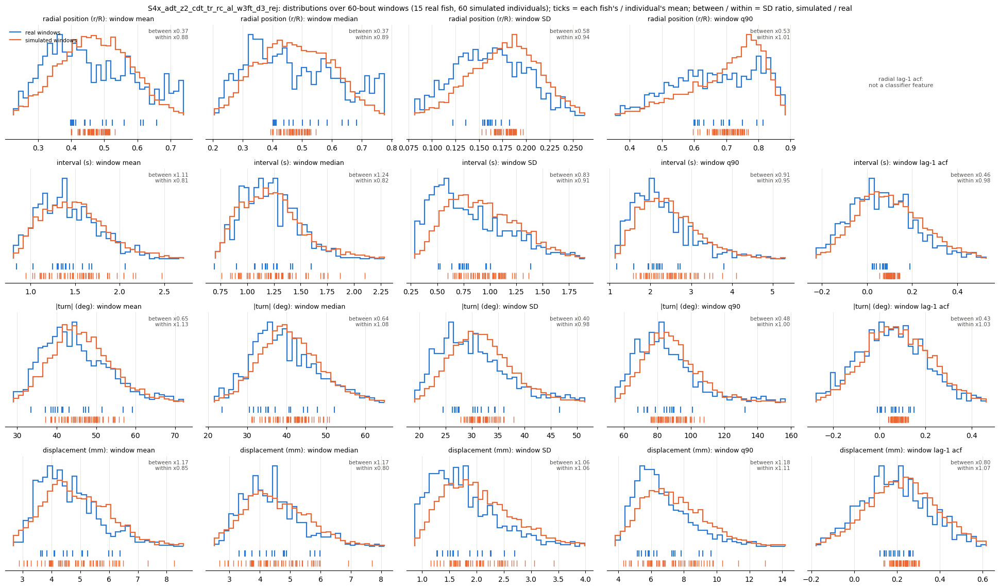

In [ ]:
# Model 36a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_36a = window_stats_grid("report_ckpts/M36a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold4.pt: 3 rollouts
dropped 12.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.47     1.00  0.15  0.14   3.0   3.0                  22.3 +/- 0.9  21.4 +/- 0.9
d2s3.5    1.90     1.57  2.64  1.38  11.0   7.0                  17.4 +/- 0.9  19.1 +/- 0.7
d4s3.5    1.55     0.95  4.68  2.62  19.0   9.0                  18.7 +/- 1.7  19.0 +/- 0.8
d6s3.5    1.85

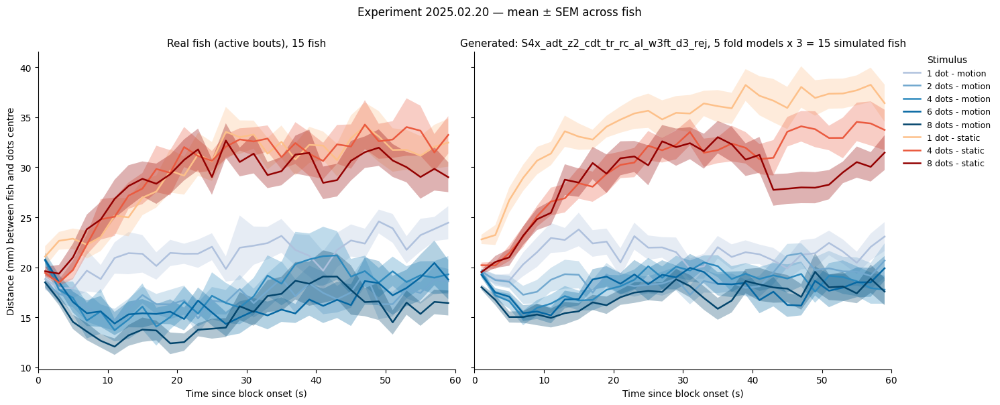

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M36a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

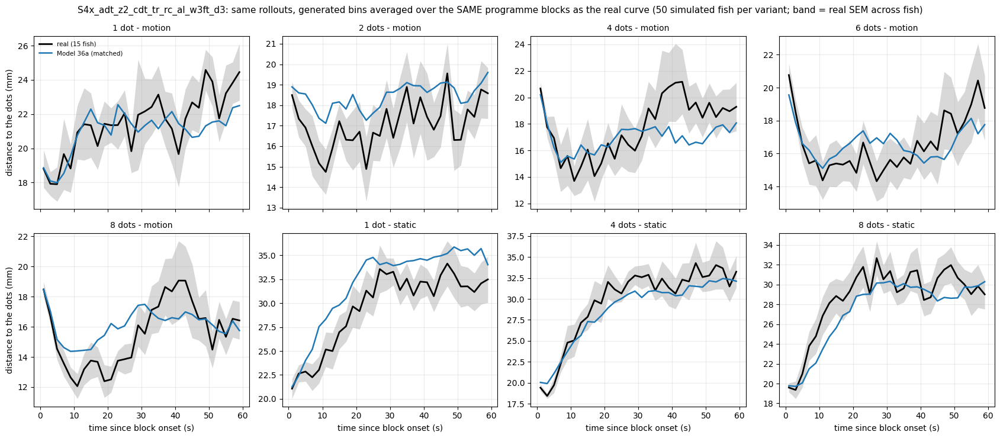

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_36a, _ = profile_variants_matched("report_ckpts/M36a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", {"Model 36a": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_36a, _ = attraction_table("report_ckpts/M36a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_d3"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_d3                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           22.18  23.39       1.21
d2s3.5       17.39  23.58       6.19                           18.64  23.20       4.56
d4s3.5       18.74  23.93       5.19                           17.75  23.29       5.54
d6s3.5       16.69  23.12       6.43                           17.17  23.28       6.10
d8s3.5       16.41  23.36       6.94                           17.26  23.32       6.06


In [ ]:
# Model 36a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_36a = toward_by_n("report_ckpts/M36a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_d3"], rej=REJ["wall_reject"])
print(tow_36a.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3
win    N                                        
0-20 s 1   9.09                            10.81
       2  13.90                            12.73
       4  15.73                            14.48
       6  14.50                            14.82
       8  16.00                            17.67
4-20 s 1   6.25                             9.78
       2  12.27                            12.09
       4  14.35                            13.77
       6  12.79                            13.89
       8  15.11                            16.33


Model 36a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 36a   real gap Model 36a    real gap Model 36a
cond                                                                  
d1s3.5  25.08         -8.94   6.64          4.67    7.55          2.94
d2s3.5  22.99         -5.35  12.94         -0.17   12.56         -0.26
d4s3.5  27.14         -8.42  15.54         -1.23   12.09          1.39
d6s3.5  32.55        -12.90  13.80          1.35   15.84         -0.66
d8s3.5  34.04        -11.08  14.45          3.38   13.80          2.17
d1s0     6.82         -4.18   4.22         -3.02    1.96         -0.20
d4s0     4.81         -0.13   1.86          1.84    1.74          2.69
d8s0     5.26          0.48   2.63          2.21    2.39          3.54

turn size |Δθ| (deg): real f

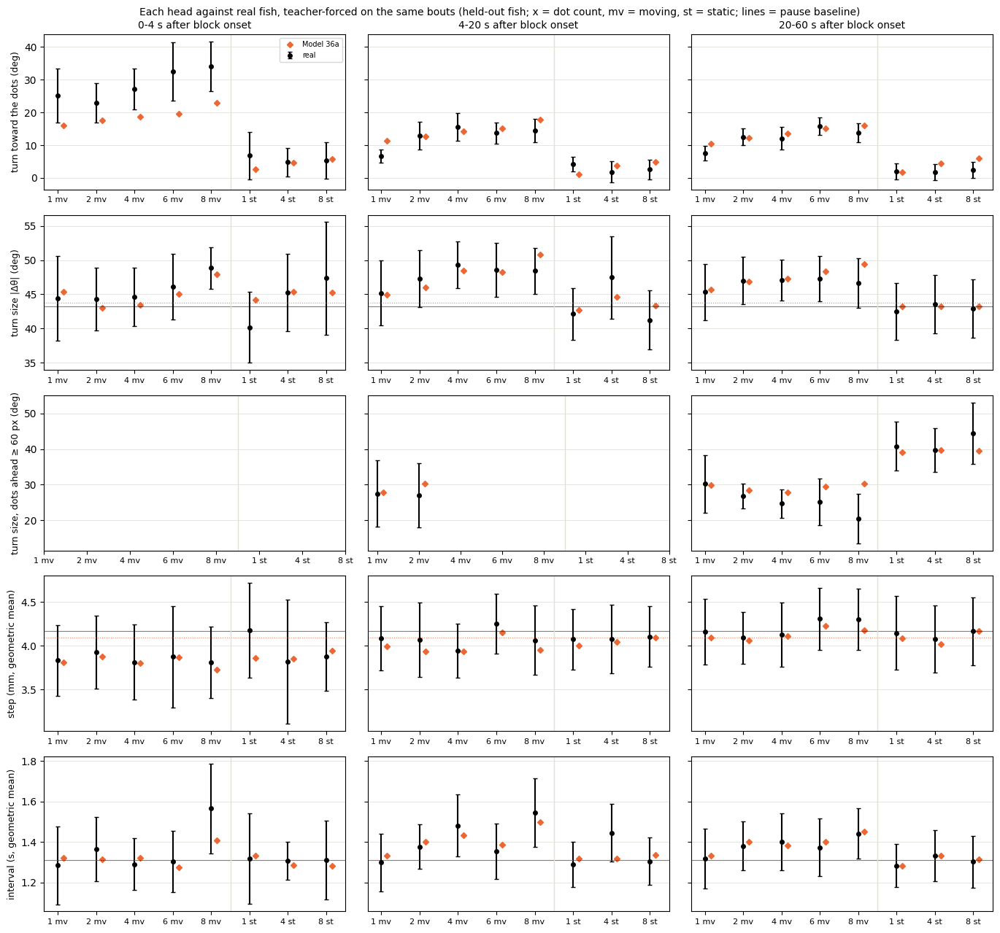

In [ ]:
# Model 36a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_36a, hg_36a = head_gaps({"Model 36a": ("report_ckpts/M36a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3")}, rej=REJ["wall_reject"])

#### M6 (26e), three layers — seed 101 (key `36b`)

In [ ]:
# Model 36b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M36b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_36b = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_36b.index = ["turn", "displacement", "interval", "joint"]
print(lik_36b.round(3).to_string())

turn             7.655
displacement     4.508
interval         1.239
joint           13.402


In [ ]:
# Model 36b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_36b, c2st_36b = run(ckpt_dir="report_ckpts/M36b", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_d3'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_d3.csv  (15 rows) in 2443s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_rej
abs_dtheta_w1                                        7.3954
symbol_js                                            0.0094
dt_w1                                                0.3949
dist_w1                                              3.9364
trans_js                                             0.0111
acf_l2                                               0.

In [ ]:
# Model 36b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M36b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_36b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_36b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.680            0.024      0.590         0.026
matched to the real runs (same bouts, 1:1)            0.668            0.025      0.577         0.027



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.466         0.088        0.031          0.348         0.890
                      median           0.449       0.466         0.098        0.033          0.333         0.903
                      SD               0.159       0.177         0.015        0.009          0.613         0.953
                      q90              0.679       0.718         0.074        0.039

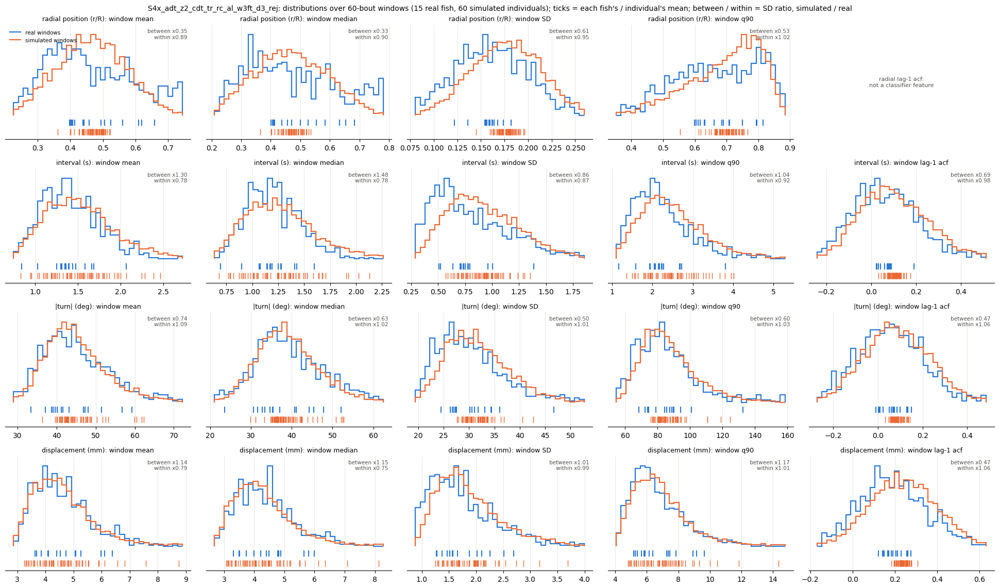

In [ ]:
# Model 36b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_36b = window_stats_grid("report_ckpts/M36b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3_fold4.pt: 3 rollouts
dropped 11.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.48     1.03  0.15  0.04   3.0   5.0                  22.3 +/- 0.9  22.6 +/- 0.9
d2s3.5    1.80     1.38  2.64  2.99  11.0  11.0                  17.4 +/- 0.9  19.5 +/- 0.9
d4s3.5    1.56     0.94  4.68  2.62  19.0  11.0                  18.7 +/- 1.7  17.8 +/- 0.5
d6s3.5    1.11

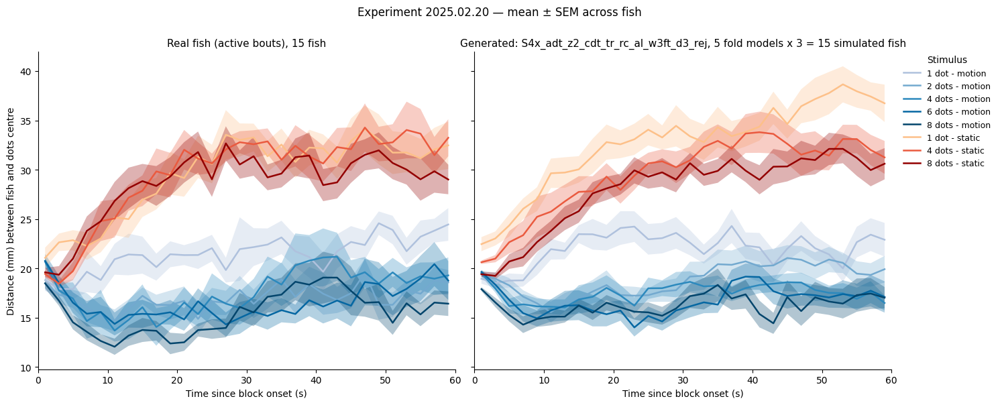

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M36b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

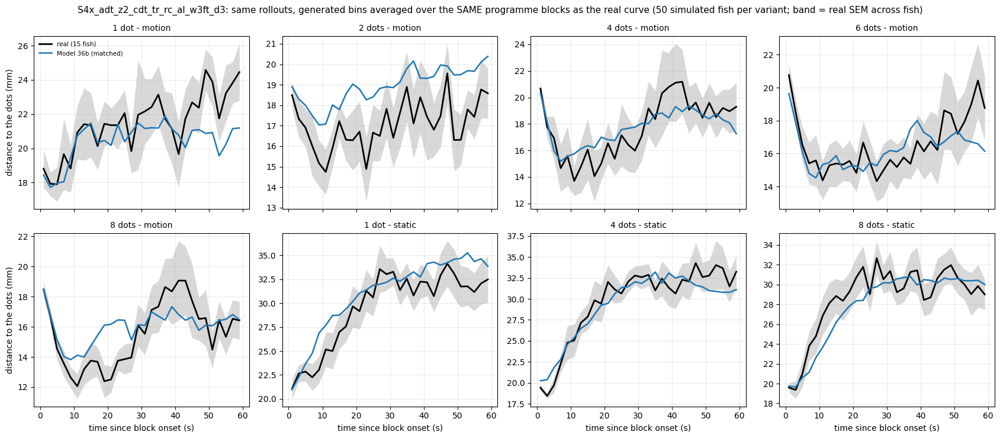

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_36b, _ = profile_variants_matched("report_ckpts/M36b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3", {"Model 36b": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_36b, _ = attraction_table("report_ckpts/M36b", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_d3"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_d3                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.65  22.99       1.34
d2s3.5       17.39  23.58       6.19                           20.00  22.82       2.82
d4s3.5       18.74  23.93       5.19                           19.09  23.23       4.15
d6s3.5       16.69  23.12       6.43                           17.24  23.22       5.98
d8s3.5       16.41  23.36       6.94                           17.01  22.92       5.90


In [ ]:
# Model 36b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_36b = toward_by_n("report_ckpts/M36b", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_d3"], rej=REJ["wall_reject"])
print(tow_36b.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_d3
win    N                                        
0-20 s 1   9.09                            10.24
       2  13.90                            12.31
       4  15.73                            14.53
       6  14.50                            15.08
       8  16.00                            17.57
4-20 s 1   6.25                             9.36
       2  12.27                            11.78
       4  14.35                            13.73
       6  12.79                            13.72
       8  15.11                            16.19


Model 36b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 36b   real gap Model 36b    real gap Model 36b
cond                                                                  
d1s3.5  25.08         -9.56   6.64          3.99    7.55          2.94
d2s3.5  22.99         -5.50  12.94         -0.28   12.56         -0.73
d4s3.5  27.14         -7.74  15.54         -1.72   12.09          1.29
d6s3.5  32.55        -12.03  13.80          1.56   15.84         -0.91
d8s3.5  34.04        -10.67  14.45          3.04   13.80          2.01
d1s0     6.82         -4.49   4.22         -2.96    1.96          0.01
d4s0     4.81         -0.99   1.86          1.73    1.74          3.41
d8s0     5.26          0.28   2.63          2.52    2.39          3.49

turn size |Δθ| (deg): real f

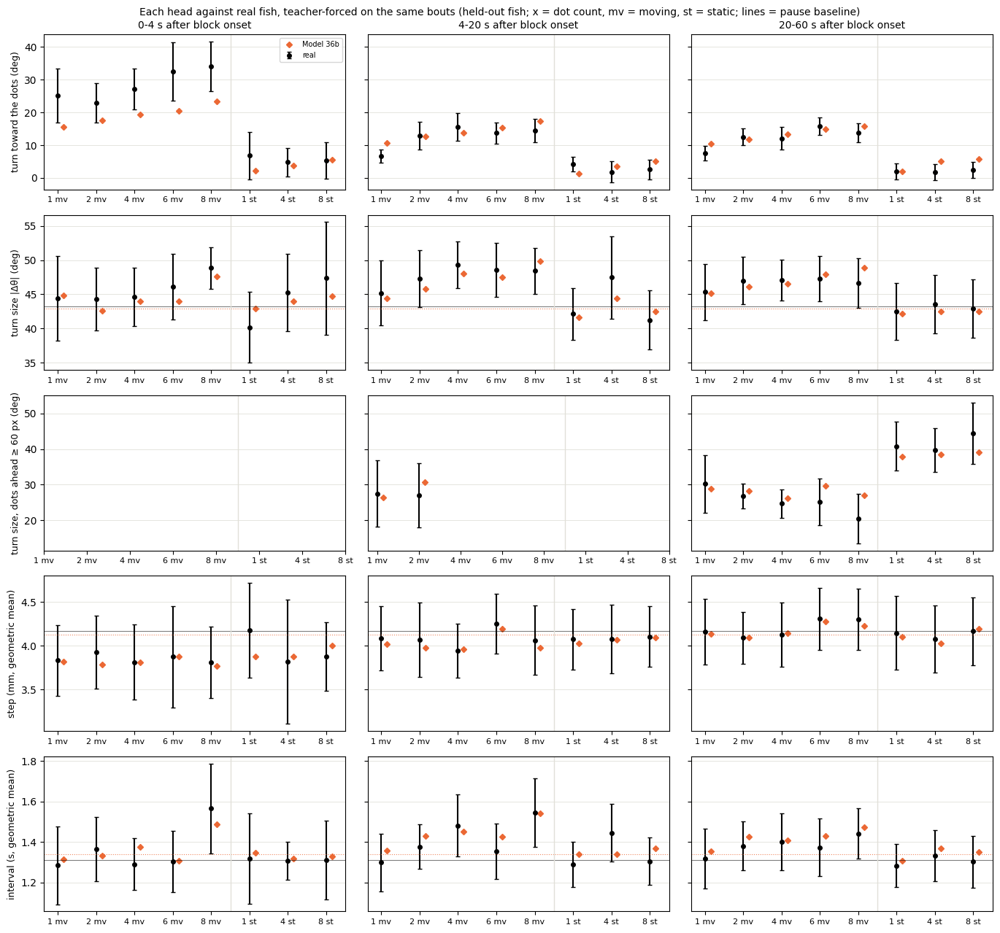

In [ ]:
# Model 36b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_36b, hg_36b = head_gaps({"Model 36b": ("report_ckpts/M36b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_d3")}, rej=REJ["wall_reject"])

<a id="m36c"></a>
### D4 (Model 17), three layers

**Change:** Model 17 with depth 3



#### D4 (Model 17), three layers — seed 0 (key `36c`)

In [ ]:
# Model 36c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M36c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_36c = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_36c.index = ["turn", "displacement", "interval", "joint"]
print(lik_36c.round(3).to_string())

turn             7.647
displacement     4.510
interval         1.204
joint           13.362


In [ ]:
# Model 36c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_36c, c2st_36c = run(ckpt_dir="report_ckpts/M36c", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv  (15 rows) in 1296s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_rej
abs_dtheta_w1                                                6.9386
symbol_js                                                    0.0094
dt_w1                                                        0.3896
dist_w1                                                      3.6998
trans_js                                   

In [ ]:
# Model 36c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M36c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_36c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_36c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.749            0.015      0.702         0.019
matched to the real runs (same bouts, 1:1)            0.742            0.016      0.695         0.020



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.449         0.088        0.047          0.538         0.888
                      median           0.449       0.447         0.098        0.051          0.521         0.888
                      SD               0.159       0.171         0.015        0.015          0.947         0.972
                      q90              0.679       0.693         0.074        0.062

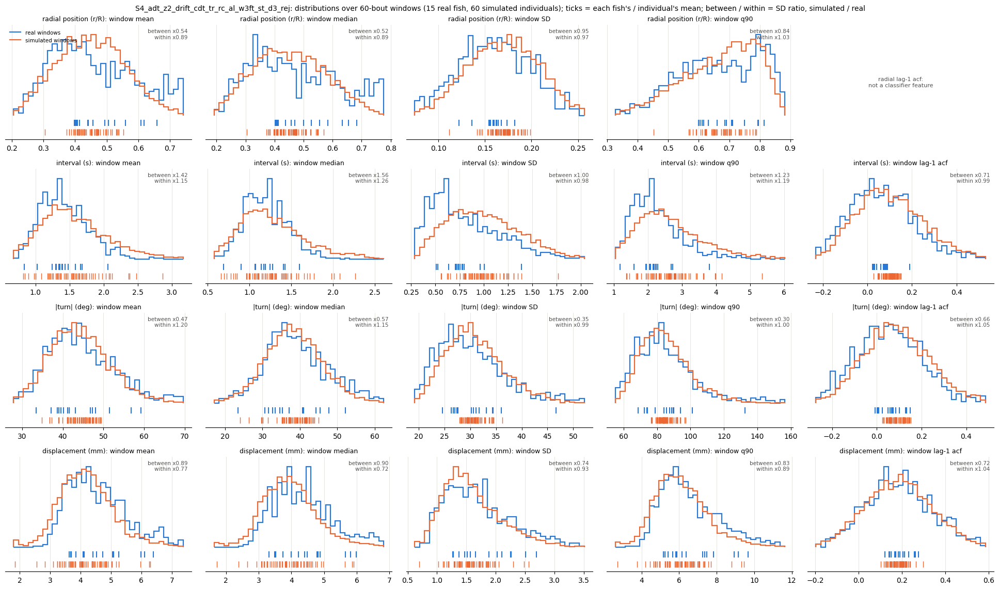

In [ ]:
# Model 36c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_36c = window_stats_grid("report_ckpts/M36c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold4.pt: 3 rollouts
dropped 12.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.36     1.58  0.15   0.3   3.0   3.0                  22.3 +/- 0.9  24.8 +/- 1.1
d2s3.5    3.19     2.51  2.64  0.37  11.0  15.0                  17.4 +/- 0.9  20.6 +/- 0.9
d4s3.5    1.38     0.80  4.68  3.96  19.0   7.0                  1

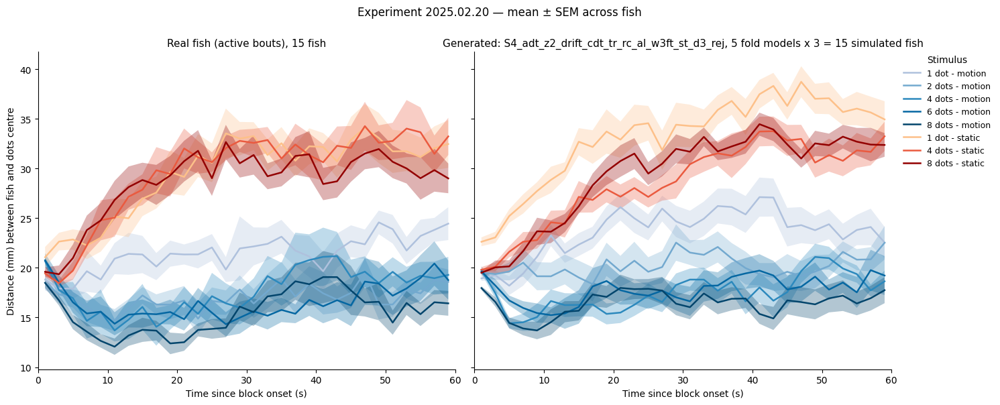

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M36c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

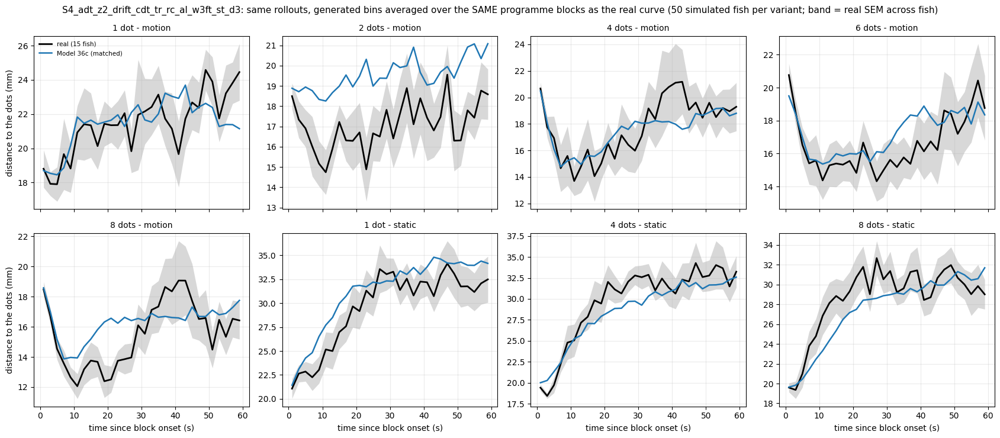

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_36c, _ = profile_variants_matched("report_ckpts/M36c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", {"Model 36c": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_36c, _ = attraction_table("report_ckpts/M36c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   22.85  22.23      -0.61
d2s3.5       17.39  23.58       6.19                                   19.54  21.89       2.35
d4s3.5       18.74  23.93       5.19                                   18.27  22.00       3.73
d6s3.5       16.69  23.12       6.43                                   17.69  22.14       4.44
d8s3.5       16.41  23.36       6.94                                   16.52  21.95       5.43


In [ ]:
# Model 36c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_36c = toward_by_n("report_ckpts/M36c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3"], rej=REJ["wall_reject"])
print(tow_36c.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3
win    N                                                
0-20 s 1   9.09                                     9.72
       2  13.90                                    11.26
       4  15.73                                    12.54
       6  14.50                                    13.76
       8  16.00                                    16.11
4-20 s 1   6.25                                     8.72
       2  12.27                                    10.25
       4  14.35                                    11.22
       6  12.79                                    12.00
       8  15.11                                    14.11


Model 36c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 36c   real gap Model 36c    real gap Model 36c
cond                                                                  
d1s3.5  25.08         -9.74   6.64          3.78    7.55          2.25
d2s3.5  22.99         -5.30  12.94         -1.90   12.56         -2.00
d4s3.5  27.14         -7.98  15.54         -3.59   12.09         -0.41
d6s3.5  32.55        -10.02  13.80         -0.03   15.84         -2.63
d8s3.5  34.04         -9.56  14.45          1.27   13.80          0.34
d1s0     6.82         -5.95   4.22         -3.13    1.96          0.50
d4s0     4.81         -1.96   1.86          1.03    1.74          2.42
d8s0     5.26          0.02   2.63          1.28    2.39          3.00

turn size |Δθ| (deg): real f

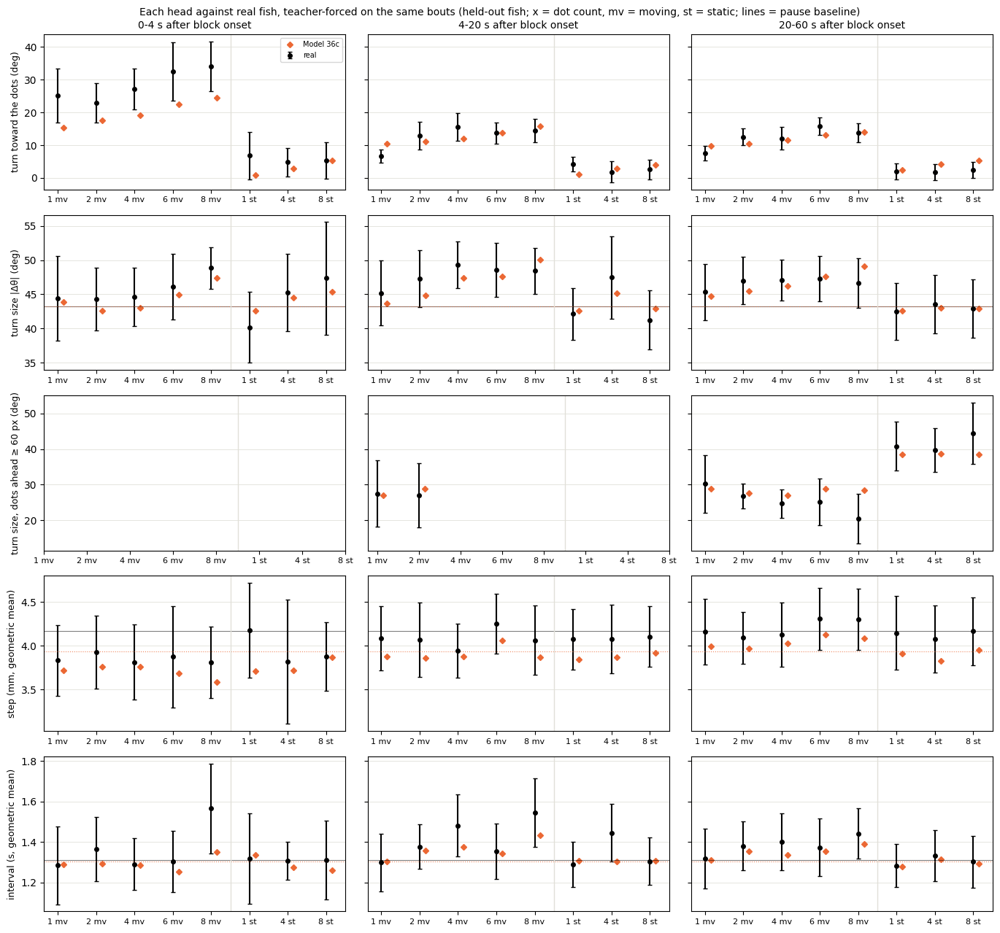

In [ ]:
# Model 36c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_36c, hg_36c = head_gaps({"Model 36c": ("report_ckpts/M36c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3")}, rej=REJ["wall_reject"])

#### D4 (Model 17), three layers — seed 101 (key `36d`)

In [ ]:
# Model 36d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M36d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_36d = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_36d.index = ["turn", "displacement", "interval", "joint"]
print(lik_36d.round(3).to_string())

turn             7.662
displacement     4.500
interval         1.198
joint           13.360


In [ ]:
# Model 36d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_36d, c2st_36d = run(ckpt_dir="report_ckpts/M36d", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3.csv  (15 rows) in 1284s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_rej
abs_dtheta_w1                                                9.0053
symbol_js                                                    0.0137
dt_w1                                                        0.4932
dist_w1                                                      4.6629
trans_js                                   

In [ ]:
# Model 36d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M36d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_36d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_36d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.733            0.017      0.685         0.017
matched to the real runs (same bouts, 1:1)            0.728            0.016      0.683         0.017



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.462         0.088        0.049          0.554         0.930
                      median           0.449       0.466         0.098        0.055          0.560         0.931
                      SD               0.159       0.172         0.015        0.014          0.879         0.997
                      q90              0.679       0.706         0.074        0.058

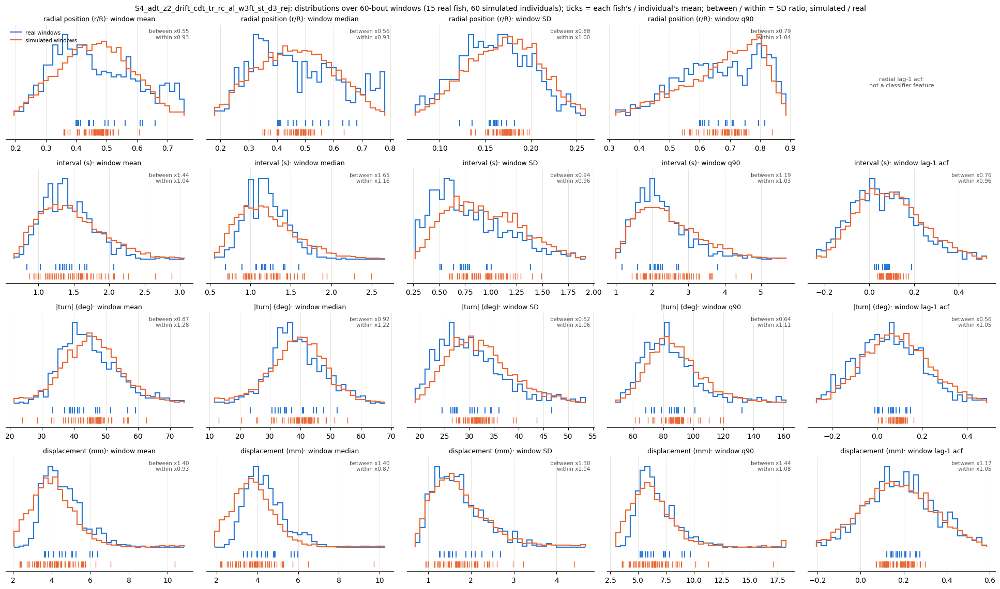

In [ ]:
# Model 36d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_36d = window_stats_grid("report_ckpts/M36d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_fold4.pt: 3 rollouts
dropped 13.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.65     1.12  0.15  0.09   3.0   5.0                  22.3 +/- 0.9  23.0 +/- 1.6
d2s3.5    2.57     2.04  2.64  1.39  11.0  11.0                  17.4 +/- 0.9  20.0 +/- 1.0
d4s3.5    1.27     0.80  4.68  2.98  19.0  11.0                  1

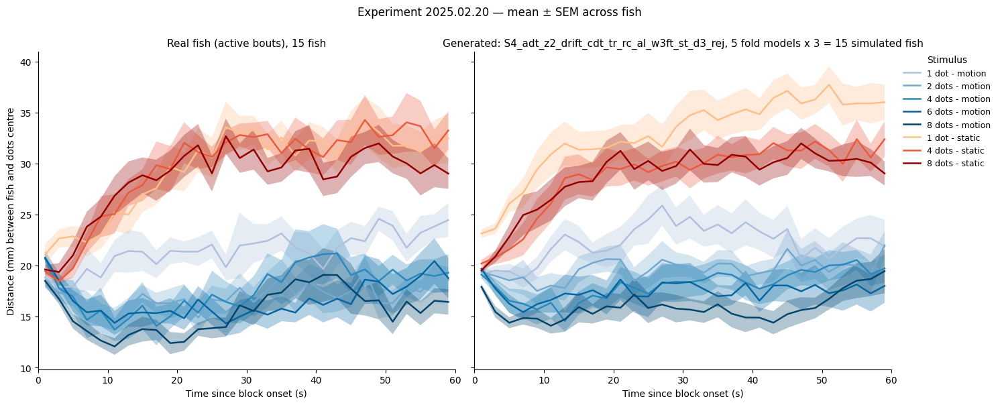

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M36d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

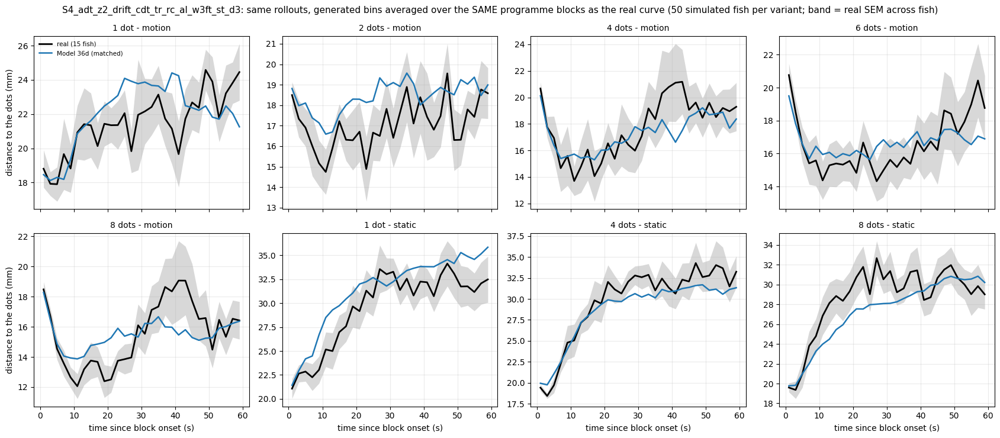

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_36d, _ = profile_variants_matched("report_ckpts/M36d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3", {"Model 36d": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_36d, _ = attraction_table("report_ckpts/M36d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   23.76  23.72      -0.04
d2s3.5       17.39  23.58       6.19                                   19.98  23.29       3.31
d4s3.5       18.74  23.93       5.19                                   19.02  23.32       4.30
d6s3.5       16.69  23.12       6.43                                   17.76  23.73       5.96
d8s3.5       16.41  23.36       6.94                                   16.45  23.60       7.15


In [ ]:
# Model 36d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_36d = toward_by_n("report_ckpts/M36d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3"], rej=REJ["wall_reject"])
print(tow_36d.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3
win    N                                                
0-20 s 1   9.09                                    10.34
       2  13.90                                    12.69
       4  15.73                                    14.29
       6  14.50                                    15.79
       8  16.00                                    18.94
4-20 s 1   6.25                                     8.88
       2  12.27                                    11.57
       4  14.35                                    12.78
       6  12.79                                    13.90
       8  15.11                                    16.97


Model 36d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 36d   real gap Model 36d    real gap Model 36d
cond                                                                  
d1s3.5  25.08         -8.60   6.64          4.40    7.55          2.16
d2s3.5  22.99         -3.49  12.94          0.42   12.56         -1.01
d4s3.5  27.14         -5.88  15.54         -1.98   12.09          0.27
d6s3.5  32.55         -8.93  13.80          2.13   15.84         -0.91
d8s3.5  34.04         -7.38  14.45          3.39   13.80          2.57
d1s0     6.82         -3.37   4.22         -3.24    1.96         -0.05
d4s0     4.81         -1.36   1.86          0.39    1.74          2.42
d8s0     5.26         -0.89   2.63          0.96    2.39          2.14

turn size |Δθ| (deg): real f

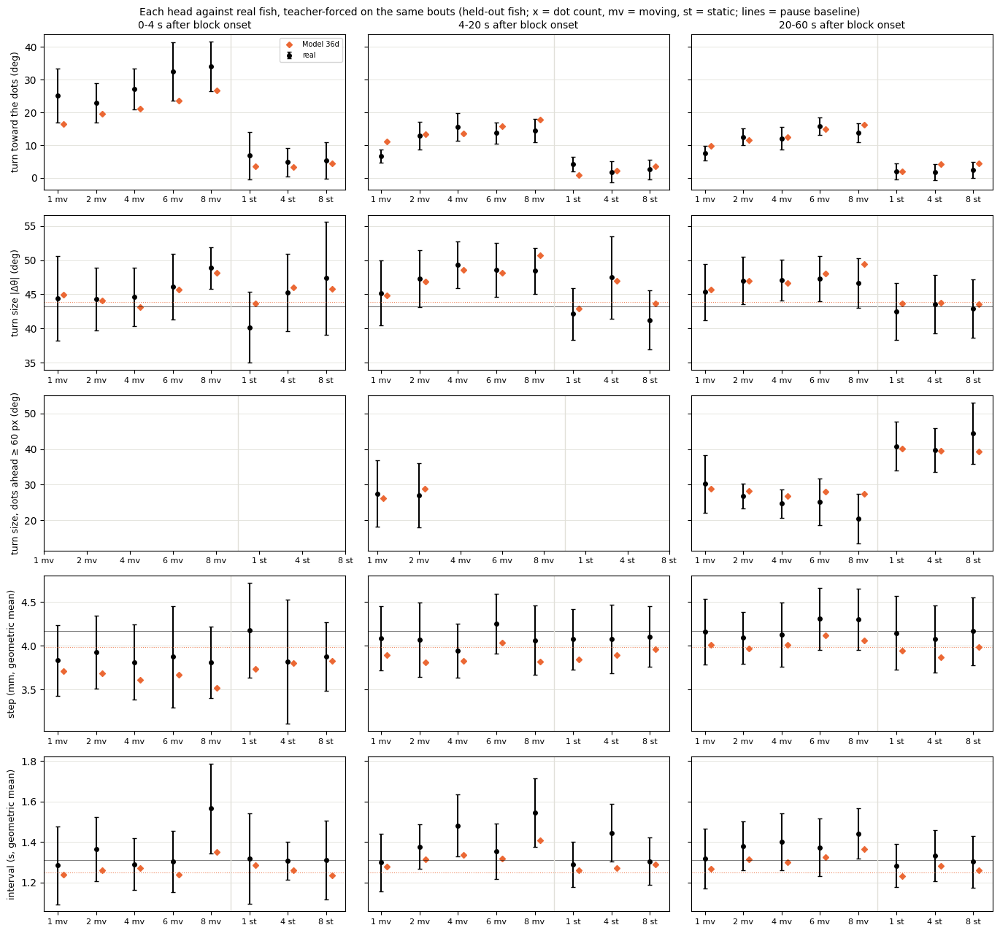

In [ ]:
# Model 36d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_36d, hg_36d = head_gaps({"Model 36d": ("report_ckpts/M36d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3")}, rej=REJ["wall_reject"])

<a id="m36e"></a>
### F (14f), three layers

**Change:** the three-layer D4 + profile correction



#### F (14f), three layers — seed 0 (key `36e`)

In [ ]:
# Model 36e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M36e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_36e = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_36e.index = ["turn", "displacement", "interval", "joint"]
print(lik_36e.round(3).to_string())

turn             7.647
displacement     4.510
interval         1.204
joint           13.362


In [ ]:
# Model 36e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_36e, c2st_36e = run(ckpt_dir="report_ckpts/M36e", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv  (15 rows) in 358s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_rej
abs_dtheta_w1                                                            6.9548
symbol_js                                                                0.0093
dt_w1                                                                    0.3887
dist_w1         

In [ ]:
# Model 36e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M36e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_36e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_36e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.743            0.016      0.707         0.020
matched to the real runs (same bouts, 1:1)            0.741            0.015      0.702         0.017



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.448         0.088        0.048          0.553         0.899
                      median           0.449       0.447         0.098        0.053          0.542         0.899
                      SD               0.159       0.170         0.015        0.014          0.932         0.982
                      q90              0.679       0.694         0.074        0.062

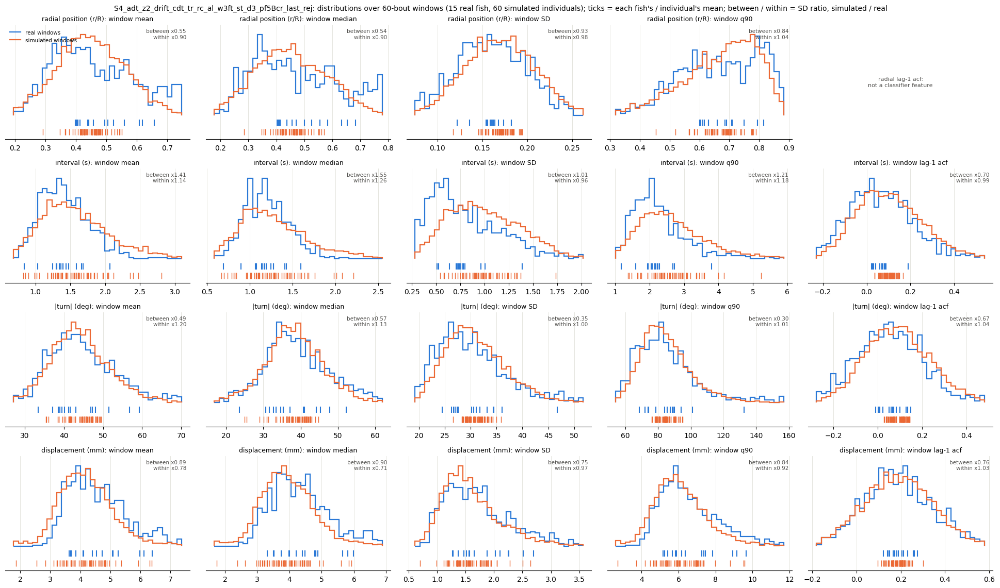

In [ ]:
# Model 36e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_36e = window_stats_grid("report_ckpts/M36e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.87     1.31  0.15  0.45   3.0   5.0                  22.3 +/- 0.9  22.2 +/- 0.8
d2s3.5    2.84     2.26  2.64   1.2  11.0  13.0                  17.4 +/- 0.9  20.3 +/- 1.1
d4s3.5

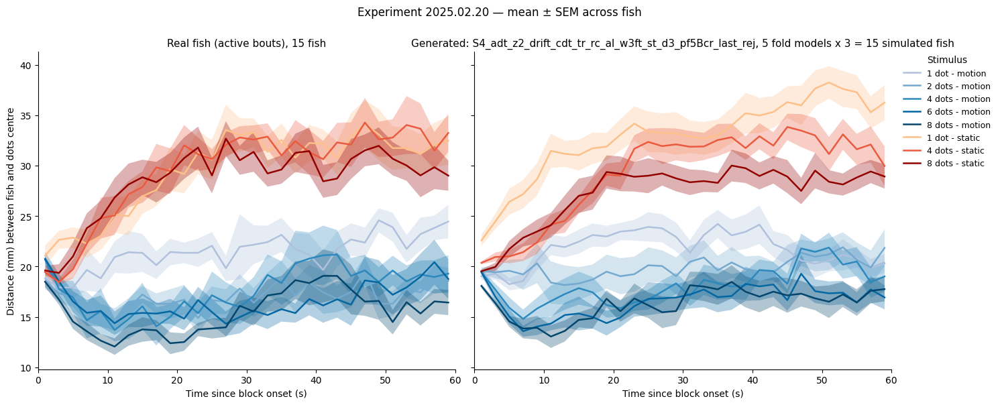

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M36e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

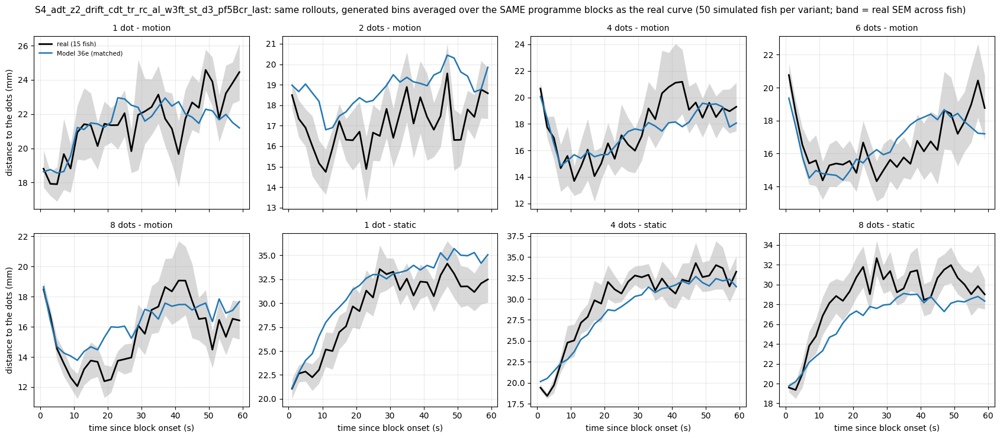

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_36e, _ = profile_variants_matched("report_ckpts/M36e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", {"Model 36e": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_36e, _ = attraction_table("report_ckpts/M36e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               22.61  22.44      -0.17
d2s3.5       17.39  23.58       6.19                                               19.17  22.25       3.08
d4s3.5       18.74  23.93       5.19                                               18.25  22.51       4.26
d6s3.5       16.69  23.12       6.43                                               16.25  22.38       6.13
d8s3.5       16.41  23.36       6.94           

In [ ]:
# Model 36e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_36e = toward_by_n("report_ckpts/M36e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_36e.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last
win    N                                                            
0-20 s 1   9.09                                                 9.72
       2  13.90                                                13.17
       4  15.73                                                14.71
       6  14.50                                                16.19
       8  16.00                                                18.48
4-20 s 1   6.25                                                 8.72
       2  12.27                                                12.24
       4  14.35                                                13.55
       6  12.79                                                14.47
       8  15.11                                                16.62


Model 36e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 36e   real gap Model 36e    real gap Model 36e
cond                                                                  
d1s3.5  25.08         -9.74   6.64          3.78    7.55          2.25
d2s3.5  22.99         -3.53  12.94         -0.07   12.56         -1.76
d4s3.5  27.14         -6.22  15.54         -1.41   12.09         -0.20
d6s3.5  32.55         -8.03  13.80          2.25   15.84         -2.42
d8s3.5  34.04         -8.38  14.45          3.47   13.80          0.64
d1s0     6.82         -5.95   4.22         -3.13    1.96          0.50
d4s0     4.81         -1.96   1.86          1.03    1.74          2.42
d8s0     5.26          0.02   2.63          1.28    2.39          3.00

turn size |Δθ| (deg): real f

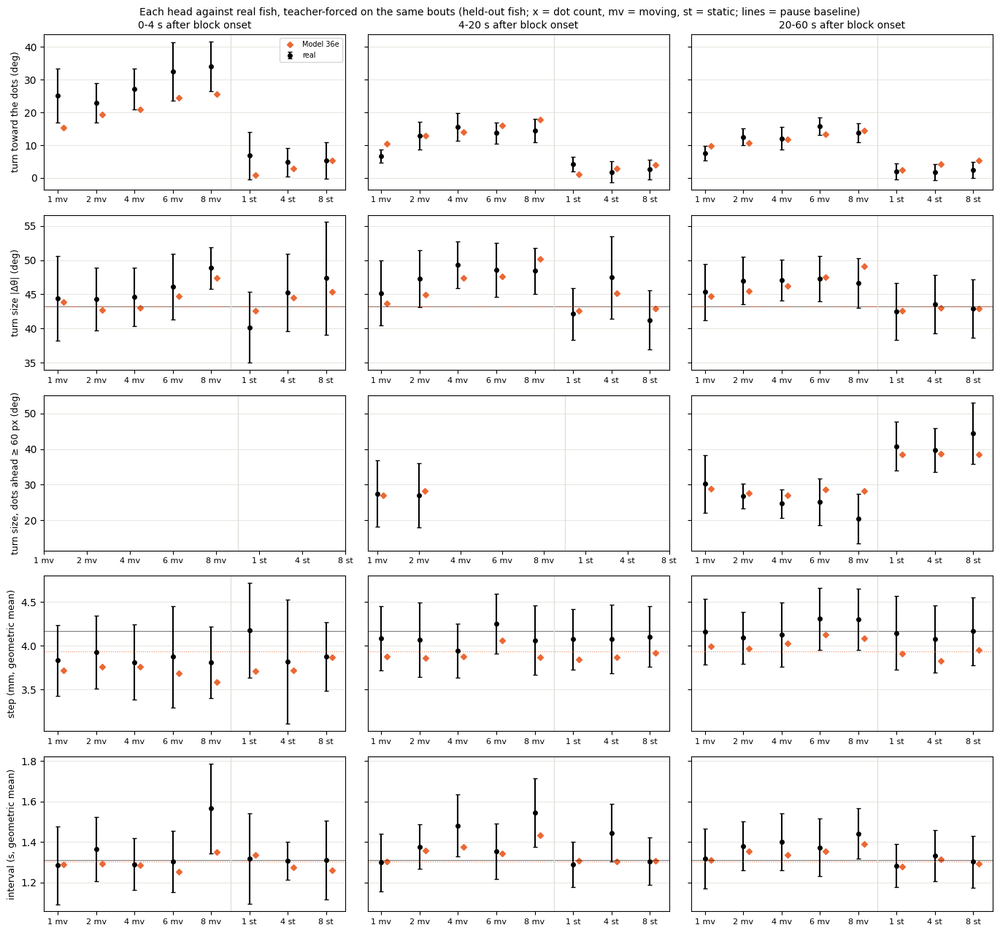

In [ ]:
# Model 36e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_36e, hg_36e = head_gaps({"Model 36e": ("report_ckpts/M36e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last")}, rej=REJ["wall_reject"])

#### F (14f), three layers — seed 101 (key `36f`)

In [ ]:
# Model 36f: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M36f/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_36f = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_36f.index = ["turn", "displacement", "interval", "joint"]
print(lik_36f.round(3).to_string())

turn             7.662
displacement     4.500
interval         1.198
joint           13.360


In [ ]:
# Model 36f: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_36f, c2st_36f = run(ckpt_dir="report_ckpts/M36f", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last.csv  (15 rows) in 352s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_rej
abs_dtheta_w1                                                            9.0525
symbol_js                                                                0.0138
dt_w1                                                                    0.4953
dist_w1         

In [ ]:
# Model 36f: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M36f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_36f = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_36f.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.730            0.014      0.684         0.017
matched to the real runs (same bouts, 1:1)            0.728            0.013      0.682         0.015



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.461         0.088        0.047          0.539         0.952
                      median           0.449       0.463         0.098        0.052          0.531         0.959
                      SD               0.159       0.171         0.015        0.014          0.913         0.981
                      q90              0.679       0.708         0.074        0.059

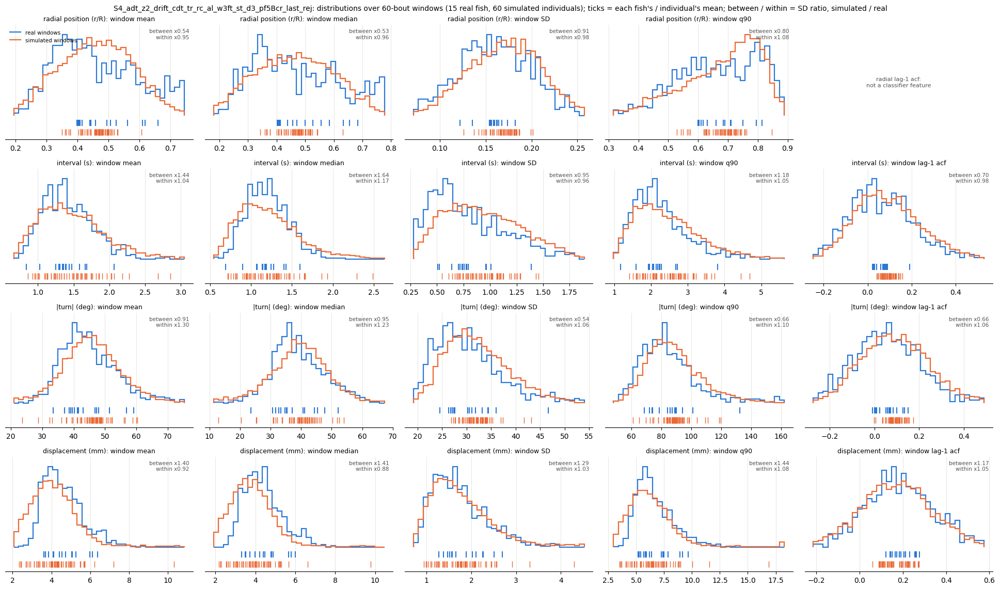

In [ ]:
# Model 36f: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_36f = window_stats_grid("report_ckpts/M36f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 13.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.56     1.10  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  23.5 +/- 1.5
d2s3.5    3.60     2.76  2.64  1.94  11.0   9.0                  17.4 +/- 0.9  21.4 +/- 1.4
d4s3.5

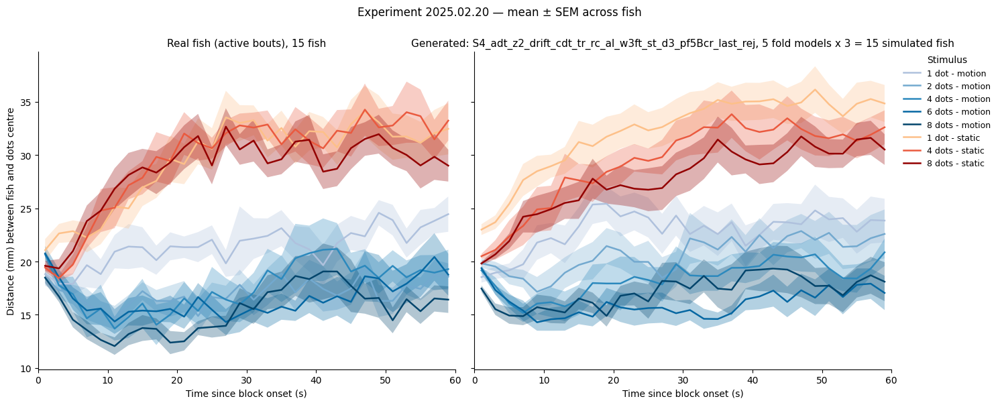

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36f: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M36f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

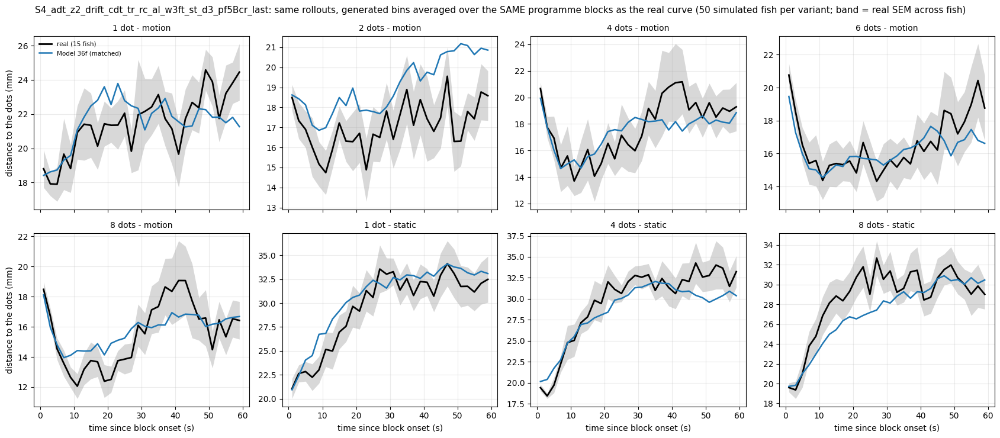

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36f: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_36f, _ = profile_variants_matched("report_ckpts/M36f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last", {"Model 36f": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 36f: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_36f, _ = attraction_table("report_ckpts/M36f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               23.25  23.29       0.04
d2s3.5       17.39  23.58       6.19                                               20.73  22.81       2.08
d4s3.5       18.74  23.93       5.19                                               19.11  22.91       3.80
d6s3.5       16.69  23.12       6.43                                               17.03  23.26       6.23
d8s3.5       16.41  23.36       6.94           

In [ ]:
# Model 36f: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_36f = toward_by_n("report_ckpts/M36f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_36f.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last
win    N                                                            
0-20 s 1   9.09                                                10.34
       2  13.90                                                14.10
       4  15.73                                                15.65
       6  14.50                                                17.18
       8  16.00                                                20.40
4-20 s 1   6.25                                                 8.88
       2  12.27                                                12.96
       4  14.35                                                14.18
       6  12.79                                                15.30
       8  15.11                                                18.57


Model 36f: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 36f   real gap Model 36f    real gap Model 36f
cond                                                                  
d1s3.5  25.08         -8.60   6.64          4.40    7.55          2.16
d2s3.5  22.99         -1.78  12.94          1.83   12.56         -0.87
d4s3.5  27.14         -4.72  15.54         -0.64   12.09          0.40
d6s3.5  32.55         -7.38  13.80          3.42   15.84         -0.78
d8s3.5  34.04         -7.16  14.45          4.99   13.80          2.69
d1s0     6.82         -3.37   4.22         -3.24    1.96         -0.05
d4s0     4.81         -1.36   1.86          0.39    1.74          2.42
d8s0     5.26         -0.89   2.63          0.96    2.39          2.14

turn size |Δθ| (deg): real f

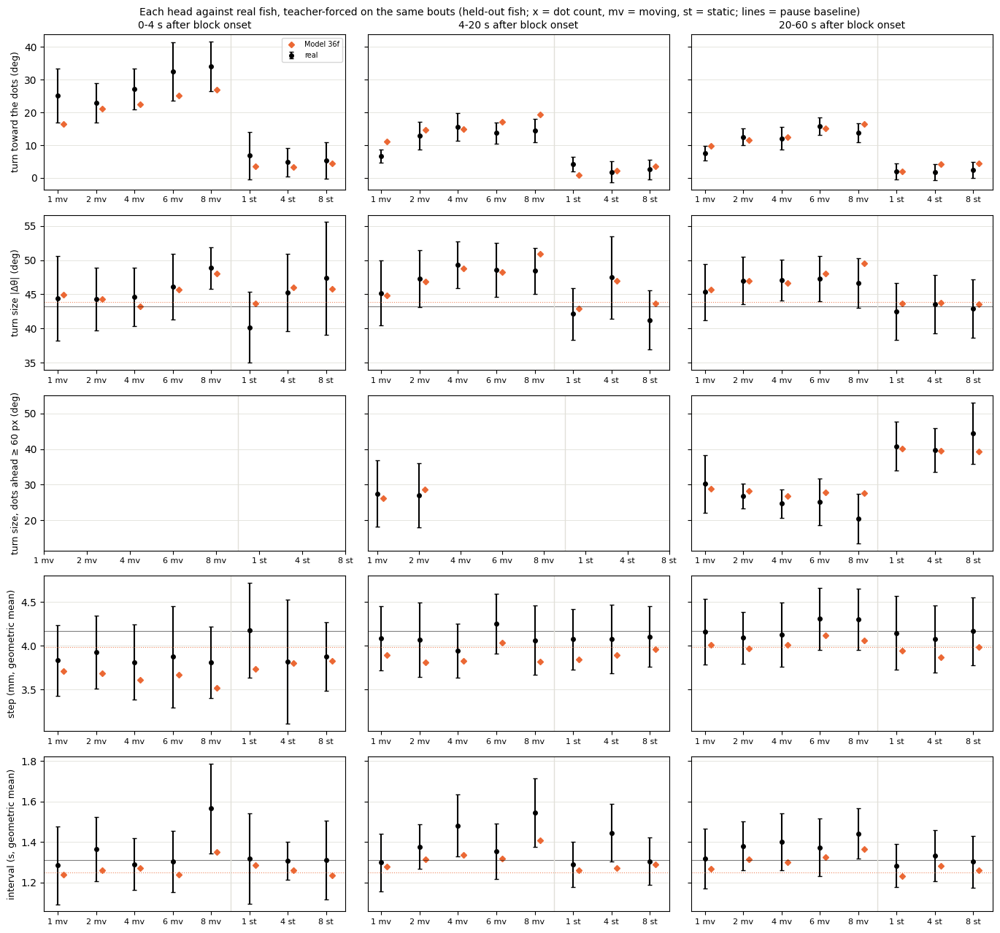

In [ ]:
# Model 36f: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_36f, hg_36f = head_gaps({"Model 36f": ("report_ckpts/M36f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_d3_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="rzlo"></a>
## 4. Lower-clip check — the log range down to 2 px

M6, D4 and F retrained with the
log range rz clipped below at the 2 px floor (log4(2 / 70) = −2.56) instead of −1 (17.5 px, 4.9 mm), everything else
unchanged (same recipe, folds and seeds; F = the lower-clip D4 + the same profile correction). 4.5 % of the bouts with dots
have the centroid closer than 17.5 px, almost all with moving groups. If the clip hid useful information, these would beat
their clipped versions at both seeds.

<a id="m42a"></a>
### M6 (26e), lower clip

**Change:** 26e with rz clipped at 2 px

No effect: likelihood −0.009 | −0.008 bits, matched AUC 0.000 | +0.010, dip −0.11 | 0.00 mm, grading −0.11 | +0.16 mm; the static error +0.41 at seed 0 does not replicate (0.00).

#### M6 (26e), lower clip — seed 0 (key `42a`)

In [ ]:
# Model 42a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M42a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_42a = _l[_l.arm == "S4xlo_adt_z2_cdt_tr_rc_al_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_42a.index = ["turn", "displacement", "interval", "joint"]
print(lik_42a.round(3).to_string())

turn             7.665
displacement     4.498
interval         1.213
joint           13.376


In [ ]:
# Model 42a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_42a, c2st_42a = run(ckpt_dir="report_ckpts/M42a", arms="S4xlo_adt_z2_cdt_tr_rc_al_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xlo_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 1582s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xlo_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                       8.3792
symbol_js                                           0.0116
dt_w1                                               0.4077
dist_w1                                             3.7663
trans_js                                            0.0131
acf_l2                                              0.0467
runlen

In [ ]:
# Model 42a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M42a", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_42a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_42a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.679            0.018      0.609         0.019
matched to the real runs (same bouts, 1:1)            0.671            0.021      0.590         0.022



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.458         0.088        0.036          0.413         0.943
                      median           0.449       0.454         0.098        0.039          0.402         0.948
                      SD               0.159       0.179         0.015        0.011          0.739         1.033
                      q90              0.679       0.719         0.074        0.047

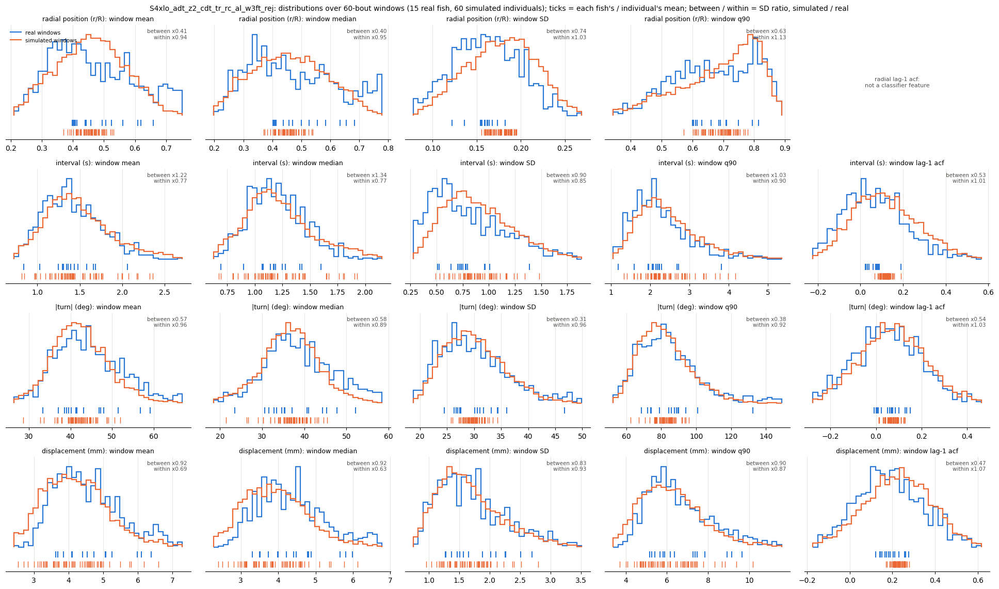

In [ ]:
# Model 42a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_42a = window_stats_grid("report_ckpts/M42a", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], reps=4)


  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold0.pt: 3 rollouts
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold1.pt: 3 rollouts
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold2.pt: 3 rollouts
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold3.pt: 3 rollouts
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.64     1.11  0.15  1.91   3.0   7.0                  22.3 +/- 0.9  20.6 +/- 0.9
d2s3.5    1.42     1.08  2.64  3.63  11.0   9.0                  17.4 +/- 0.9  18.9 +/- 0.8
d4s3.5    1.50     0.86  4.68  4.99  19.0   9.0                  18.7 +/- 1.7  17.6 +/- 0.7
d6s3.5    0.99     

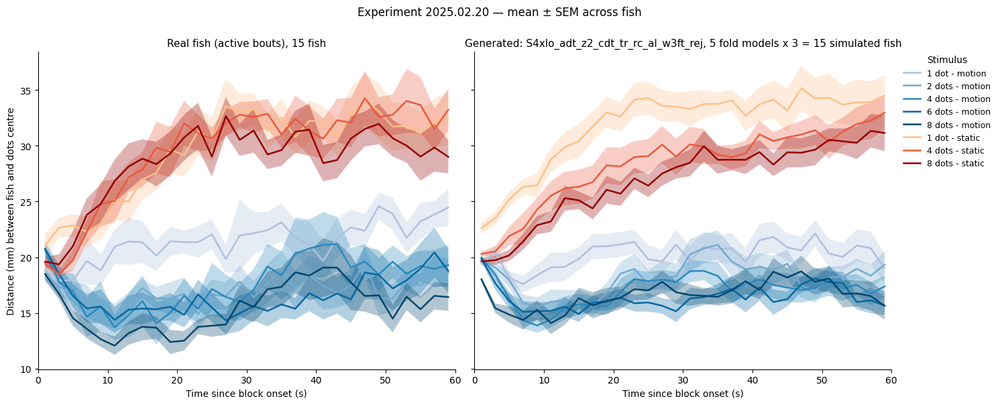

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M42a", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

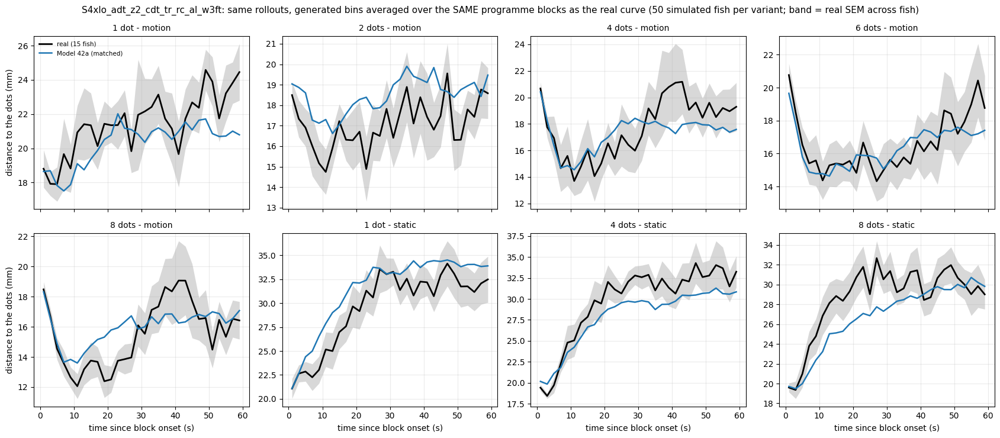

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_42a, _ = profile_variants_matched("report_ckpts/M42a", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft", {"Model 42a": {"arm": "S4xlo_adt_z2_cdt_tr_rc_al_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_42a, _ = attraction_table("report_ckpts/M42a", ["S4xlo_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xlo_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          21.49  22.33       0.84
d2s3.5       17.39  23.58       6.19                          18.54  22.03       3.49
d4s3.5       18.74  23.93       5.19                          17.84  21.99       4.15
d6s3.5       16.69  23.12       6.43                          16.72  22.02       5.30
d8s3.5       16.41  23.36       6.94                          16.66  22.18       5.52


In [ ]:
# Model 42a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_42a = toward_by_n("report_ckpts/M42a", ["S4xlo_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"])
print(tow_42a.round(2).to_string())

           real  S4xlo_adt_z2_cdt_tr_rc_al_w3ft
win    N                                       
0-20 s 1   9.09                           10.33
       2  13.90                           11.62
       4  15.73                           13.89
       6  14.50                           13.72
       8  16.00                           16.82
4-20 s 1   6.25                            9.42
       2  12.27                           11.08
       4  14.35                           12.82
       6  12.79                           12.69
       8  15.11                           15.48


Model 42a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 42a   real gap Model 42a    real gap Model 42a
cond                                                                  
d1s3.5  25.08         -8.90   6.64          3.95    7.55          2.66
d2s3.5  22.99         -5.82  12.94         -1.30   12.56         -0.79
d4s3.5  27.14         -6.79  15.54         -1.97   12.09          0.67
d6s3.5  32.55        -12.91  13.80          0.79   15.84         -1.66
d8s3.5  34.04        -10.30  14.45          2.14   13.80          1.73
d1s0     6.82         -4.93   4.22         -3.36    1.96          0.34
d4s0     4.81         -0.51   1.86          3.08    1.74          2.63
d8s0     5.26         -0.92   2.63          1.69    2.39          3.10

turn size |Δθ| (deg): real f

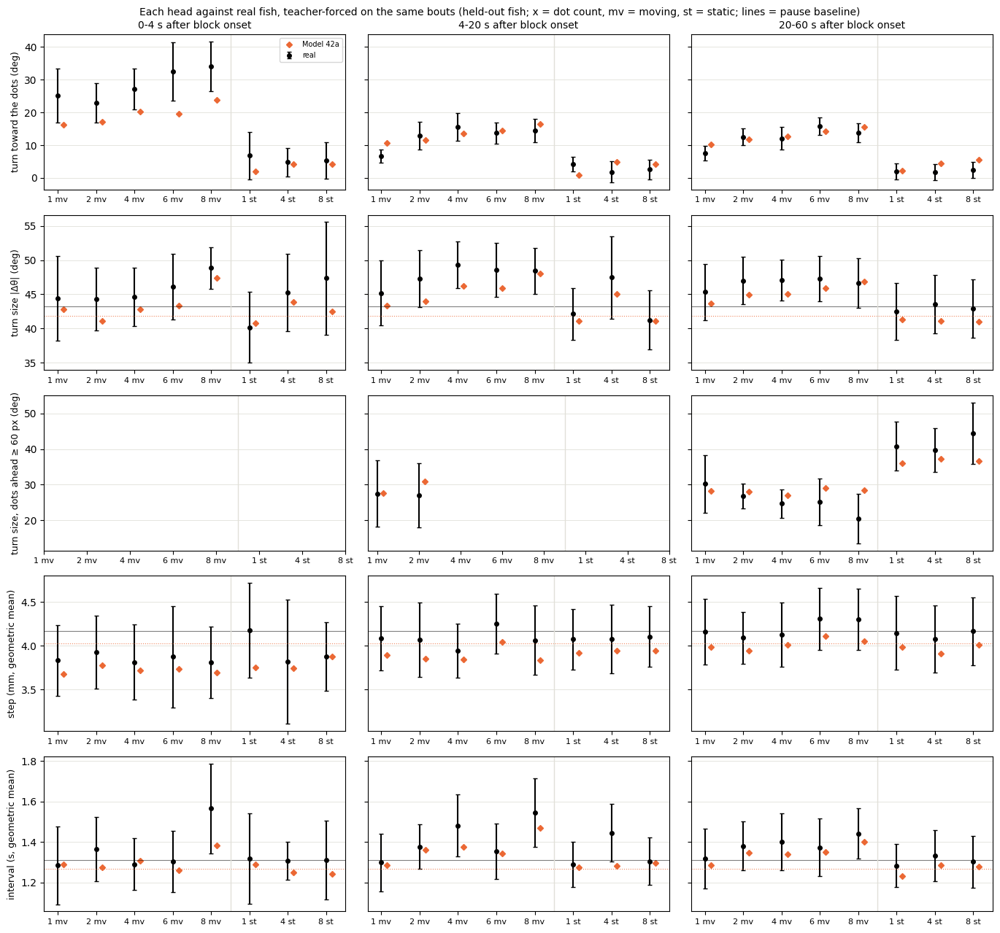

In [ ]:
# Model 42a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_42a, hg_42a = head_gaps({"Model 42a": ("report_ckpts/M42a", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft")}, rej=REJ["wall_reject"])

#### M6 (26e), lower clip — seed 101 (key `42b`)

In [ ]:
# Model 42b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M42b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_42b = _l[_l.arm == "S4xlo_adt_z2_cdt_tr_rc_al_w3ft"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_42b.index = ["turn", "displacement", "interval", "joint"]
print(lik_42b.round(3).to_string())

turn             7.665
displacement     4.496
interval         1.218
joint           13.379


In [ ]:
# Model 42b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_42b, c2st_42b = run(ckpt_dir="report_ckpts/M42b", arms="S4xlo_adt_z2_cdt_tr_rc_al_w3ft", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4xlo_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4xlo_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 1319s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4xlo_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                       8.2723
symbol_js                                           0.0123
dt_w1                                               0.3835
dist_w1                                             3.6673
trans_js                                            0.0143
acf_l2                                              0.0473
runlen

In [ ]:
# Model 42b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M42b", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_42b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_42b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.657            0.028      0.578         0.036
matched to the real runs (same bouts, 1:1)            0.655            0.026      0.567         0.037



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.476         0.088        0.032          0.361         0.880
                      median           0.449       0.476         0.098        0.036          0.373         0.900
                      SD               0.159       0.183         0.015        0.009          0.579         0.961
                      q90              0.679       0.737         0.074        0.037

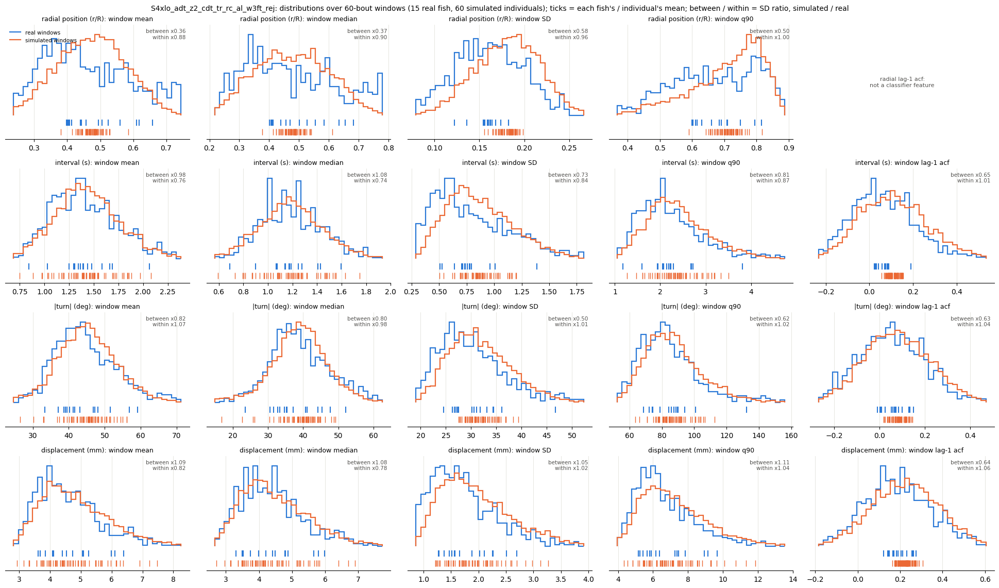

In [ ]:
# Model 42b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_42b = window_stats_grid("report_ckpts/M42b", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"], reps=4)


  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold0.pt: 3 rollouts
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold1.pt: 3 rollouts
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold2.pt: 3 rollouts
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold3.pt: 3 rollouts
  S4xlo_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.73     1.87  0.15  0.63   3.0   5.0                  22.3 +/- 0.9  19.8 +/- 0.6
d2s3.5    1.82     1.39  2.64  1.85  11.0  11.0                  17.4 +/- 0.9  19.2 +/- 1.1
d4s3.5    2.00     1.16  4.68  3.37  19.0   7.0                  18.7 +/- 1.7  16.7 +/- 1.0
d6s3.5    1.14     

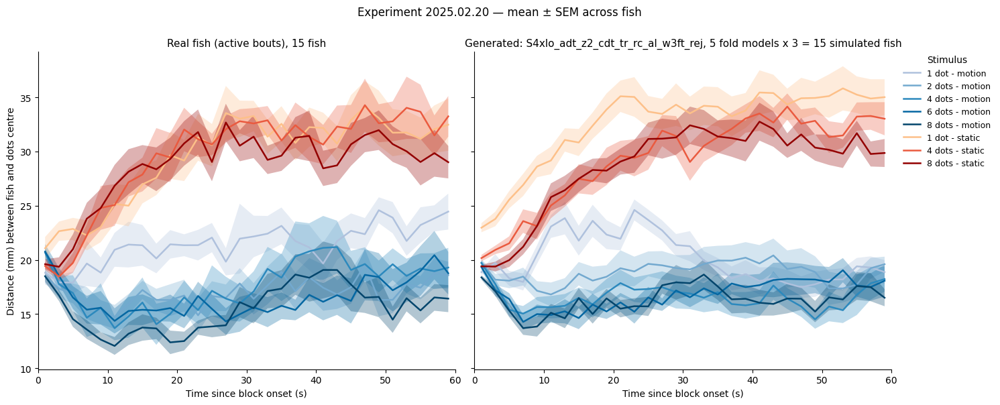

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M42b", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

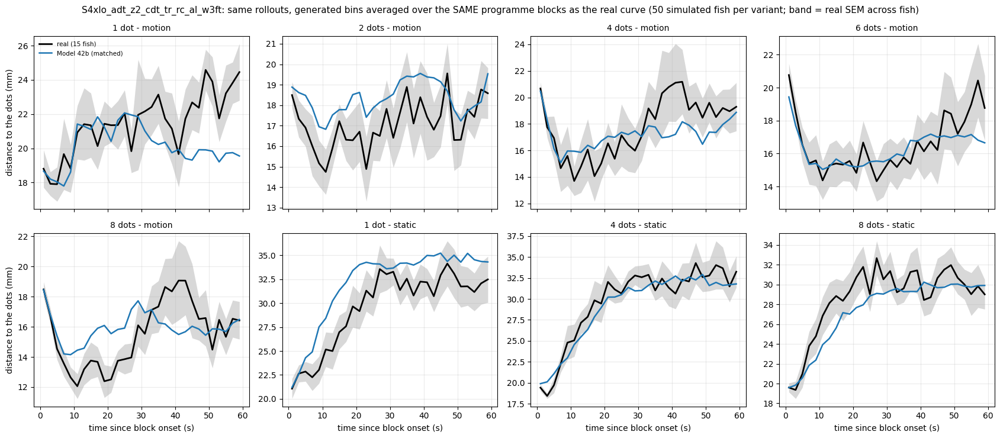

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_42b, _ = profile_variants_matched("report_ckpts/M42b", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft", {"Model 42b": {"arm": "S4xlo_adt_z2_cdt_tr_rc_al_w3ft"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_42b, _ = attraction_table("report_ckpts/M42b", ["S4xlo_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4xlo_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          20.53  22.72       2.19
d2s3.5       17.39  23.58       6.19                          19.11  22.64       3.53
d4s3.5       18.74  23.93       5.19                          17.13  22.56       5.42
d6s3.5       16.69  23.12       6.43                          17.02  22.59       5.56
d8s3.5       16.41  23.36       6.94                          16.46  22.91       6.44


In [ ]:
# Model 42b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_42b = toward_by_n("report_ckpts/M42b", ["S4xlo_adt_z2_cdt_tr_rc_al_w3ft"], rej=REJ["wall_reject"])
print(tow_42b.round(2).to_string())

           real  S4xlo_adt_z2_cdt_tr_rc_al_w3ft
win    N                                       
0-20 s 1   9.09                           10.24
       2  13.90                           12.15
       4  15.73                           14.01
       6  14.50                           14.91
       8  16.00                           16.67
4-20 s 1   6.25                            9.28
       2  12.27                           11.73
       4  14.35                           13.07
       6  12.79                           14.08
       8  15.11                           15.54


Model 42b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 42b   real gap Model 42b    real gap Model 42b
cond                                                                  
d1s3.5  25.08         -9.52   6.64          3.97    7.55          2.64
d2s3.5  22.99         -5.07  12.94         -0.79   12.56         -1.03
d4s3.5  27.14         -7.42  15.54         -2.04   12.09          0.87
d6s3.5  32.55        -12.57  13.80          1.53   15.84         -1.19
d8s3.5  34.04        -10.42  14.45          2.68   13.80          1.64
d1s0     6.82         -5.78   4.22         -4.04    1.96         -1.02
d4s0     4.81         -1.68   1.86          0.65    1.74          2.33
d8s0     5.26         -0.99   2.63          0.98    2.39          2.97

turn size |Δθ| (deg): real f

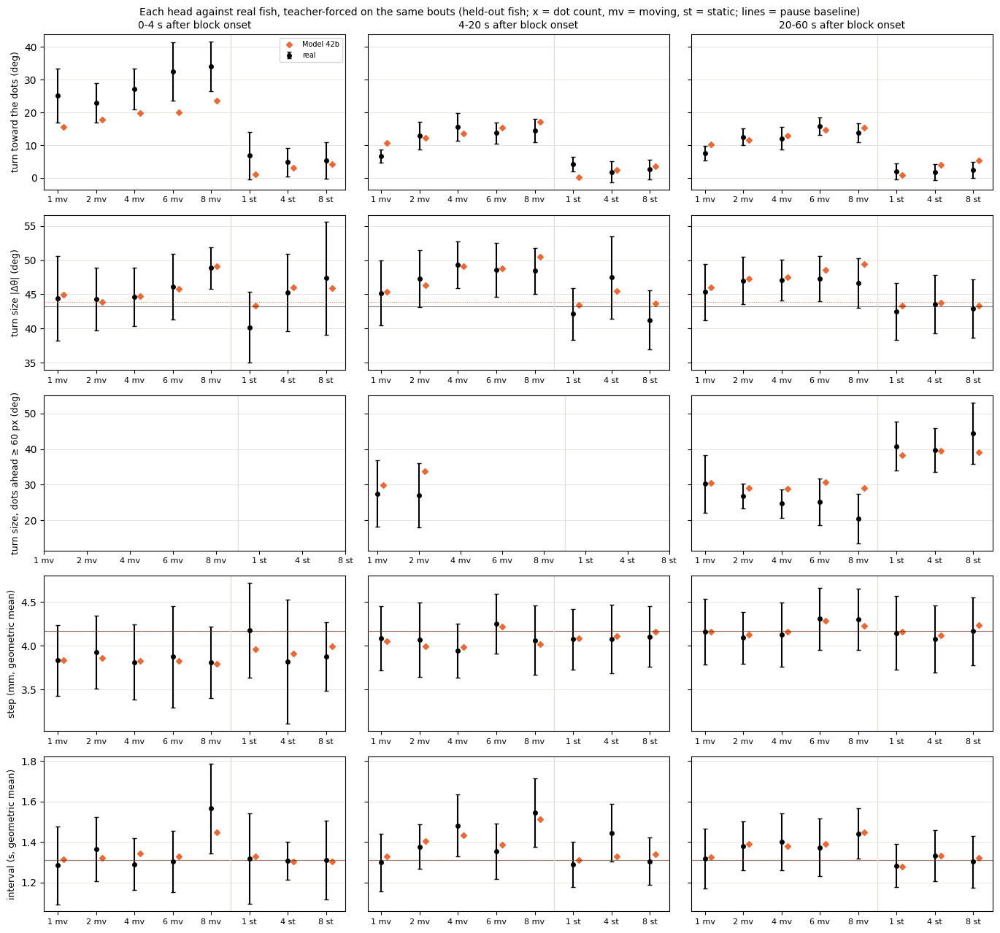

In [ ]:
# Model 42b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_42b, hg_42b = head_gaps({"Model 42b": ("report_ckpts/M42b", "S4xlo_adt_z2_cdt_tr_rc_al_w3ft")}, rej=REJ["wall_reject"])

<a id="m42c"></a>
### D4 (Model 17), lower clip

**Change:** Model 17 with rz clipped at 2 px

No effect beyond noise: likelihood +0.004 | −0.004 bits, matched AUC +0.033 | +0.017 (under the bar; the drift-gain recalibration alone moves it ~0.03), grading +0.94 | +0.79 mm (within ±1 mm), dip −0.01 | −0.21 mm.

#### D4 (Model 17), lower clip — seed 0 (key `42c`)

In [ ]:
# Model 42c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M42c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_42c = _l[_l.arm == "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_42c.index = ["turn", "displacement", "interval", "joint"]
print(lik_42c.round(3).to_string())

turn             7.620
displacement     4.517
interval         1.212
joint           13.348


In [ ]:
# Model 42c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_42c, c2st_42c = run(ckpt_dir="report_ckpts/M42c", arms="S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 411s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                               8.3362
symbol_js                                                   0.0140
dt_w1                                                       0.4124
dist_w1                                                     4.0000
trans_js                                             

In [ ]:
# Model 42c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M42c", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_42c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_42c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.676            0.008      0.611         0.014
matched to the real runs (same bouts, 1:1)            0.667            0.008      0.605         0.015



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.471         0.088        0.042          0.476         0.874
                      median           0.449       0.474         0.098        0.047          0.477         0.883
                      SD               0.159       0.174         0.015        0.011          0.734         0.950
                      q90              0.679       0.715         0.074        0.051

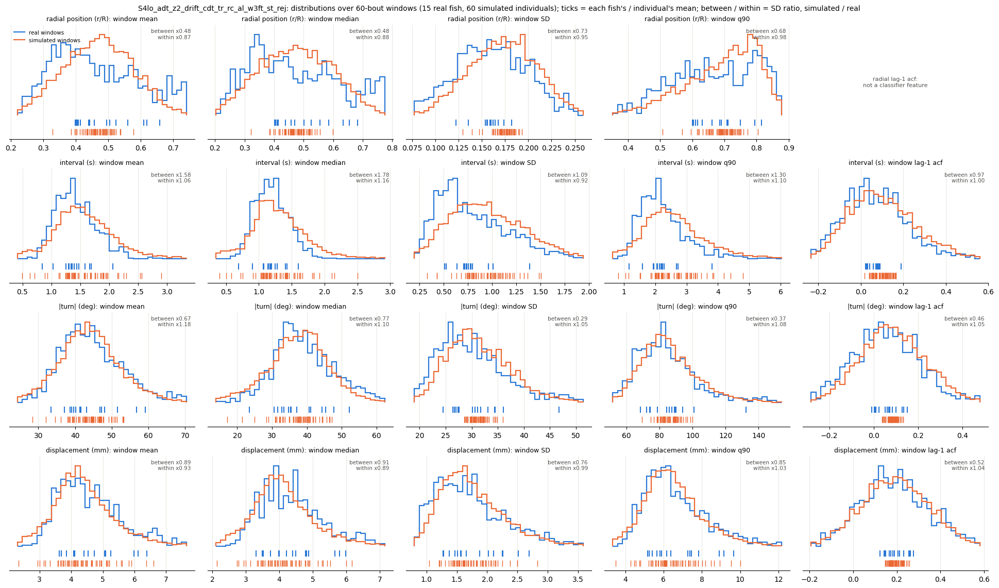

In [ ]:
# Model 42c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_42c = window_stats_grid("report_ckpts/M42c", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.73     1.14  0.15  0.59   3.0   5.0                  22.3 +/- 0.9  20.3 +/- 1.0
d2s3.5    1.10     0.89  2.64  2.39  11.0   9.0                  17.4 +/- 0.9  16.8 +/- 0.6
d4s3.5    1.59     0.90  4.68  4.14  19.0   7.0                  18.7 +

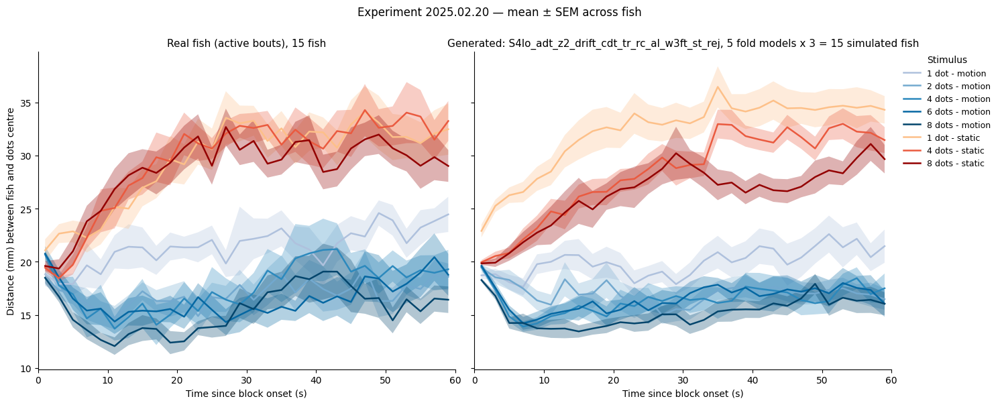

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M42c", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

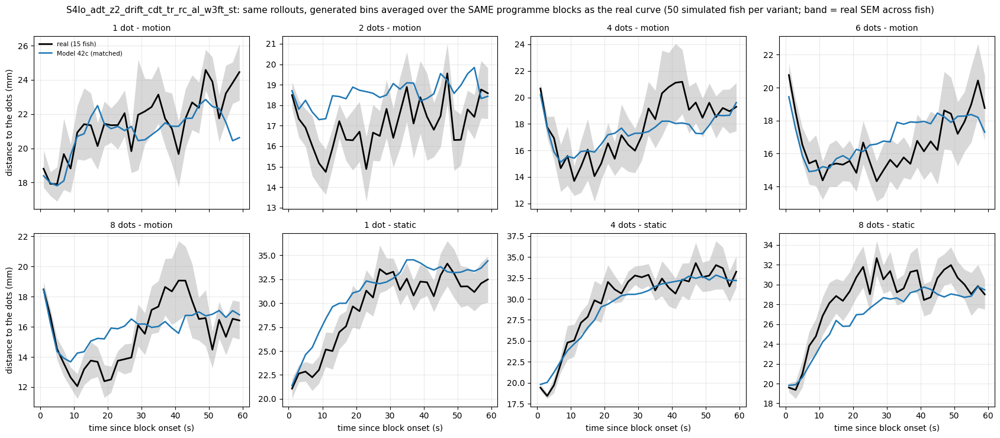

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_42c, _ = profile_variants_matched("report_ckpts/M42c", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 42c": {"arm": "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_42c, _ = attraction_table("report_ckpts/M42c", ["S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                                plateau   null attraction
cond_label                                                                                   
d1s3.5       22.41  23.57       1.16                                  21.49  22.67       1.18
d2s3.5       17.39  23.58       6.19                                  18.49  22.54       4.05
d4s3.5       18.74  23.93       5.19                                  17.87  22.28       4.42
d6s3.5       16.69  23.12       6.43                                  17.81  22.50       4.69
d8s3.5       16.41  23.36       6.94                                  16.17  22.44       6.27


In [ ]:
# Model 42c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_42c = toward_by_n("report_ckpts/M42c", ["S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_42c.round(2).to_string())

           real  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                               
0-20 s 1   9.09                                    9.51
       2  13.90                                   11.85
       4  15.73                                   13.02
       6  14.50                                   14.04
       8  16.00                                   15.58
4-20 s 1   6.25                                    8.24
       2  12.27                                   11.03
       4  14.35                                   11.51
       6  12.79                                   12.54
       8  15.11                                   13.53


Model 42c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 42c   real gap Model 42c    real gap Model 42c
cond                                                                  
d1s3.5  25.08         -8.95   6.64          3.65    7.55          2.23
d2s3.5  22.99         -4.71  12.94         -1.40   12.56         -1.57
d4s3.5  27.14         -6.74  15.54         -3.31   12.09         -0.21
d6s3.5  32.55        -10.07  13.80          0.22   15.84         -2.77
d8s3.5  34.04         -8.00  14.45          0.38   13.80          0.23
d1s0     6.82         -6.91   4.22         -2.91    1.96         -0.10
d4s0     4.81         -2.59   1.86          1.18    1.74          2.13
d8s0     5.26         -1.12   2.63          1.05    2.39          2.77

turn size |Δθ| (deg): real f

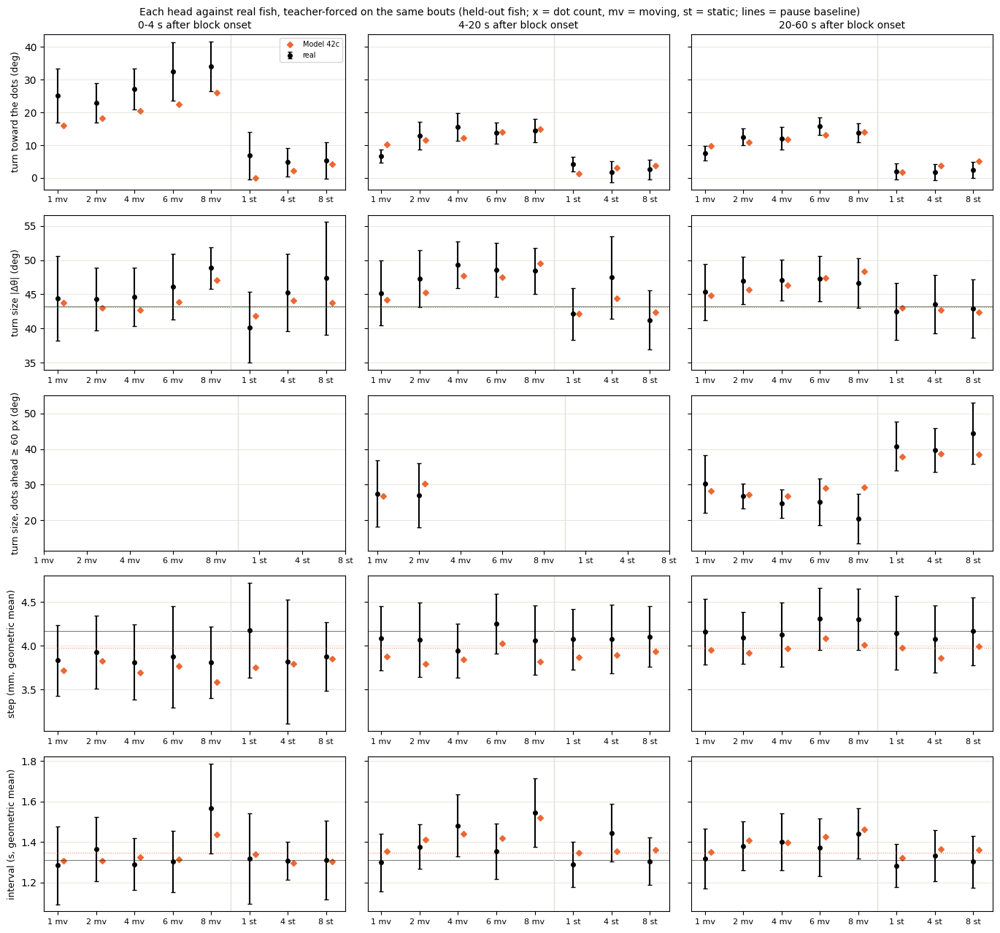

In [ ]:
# Model 42c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_42c, hg_42c = head_gaps({"Model 42c": ("report_ckpts/M42c", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

#### D4 (Model 17), lower clip — seed 101 (key `42d`)

In [ ]:
# Model 42d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M42d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_42d = _l[_l.arm == "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_42d.index = ["turn", "displacement", "interval", "joint"]
print(lik_42d.round(3).to_string())

turn             7.632
displacement     4.515
interval         1.205
joint           13.352


In [ ]:
# Model 42d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_42d, c2st_42d = run(ckpt_dir="report_ckpts/M42d", arms="S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 406s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                               8.5390
symbol_js                                                   0.0137
dt_w1                                                       0.3593
dist_w1                                                     3.4609
trans_js                                             

In [ ]:
# Model 42d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M42d", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_42d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_42d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.655            0.021      0.568         0.018
matched to the real runs (same bouts, 1:1)            0.644            0.020      0.556         0.021



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.479         0.088        0.034          0.386         0.833
                      median           0.449       0.483         0.098        0.038          0.392         0.845
                      SD               0.159       0.176         0.015        0.009          0.590         0.903
                      q90              0.679       0.721         0.074        0.040

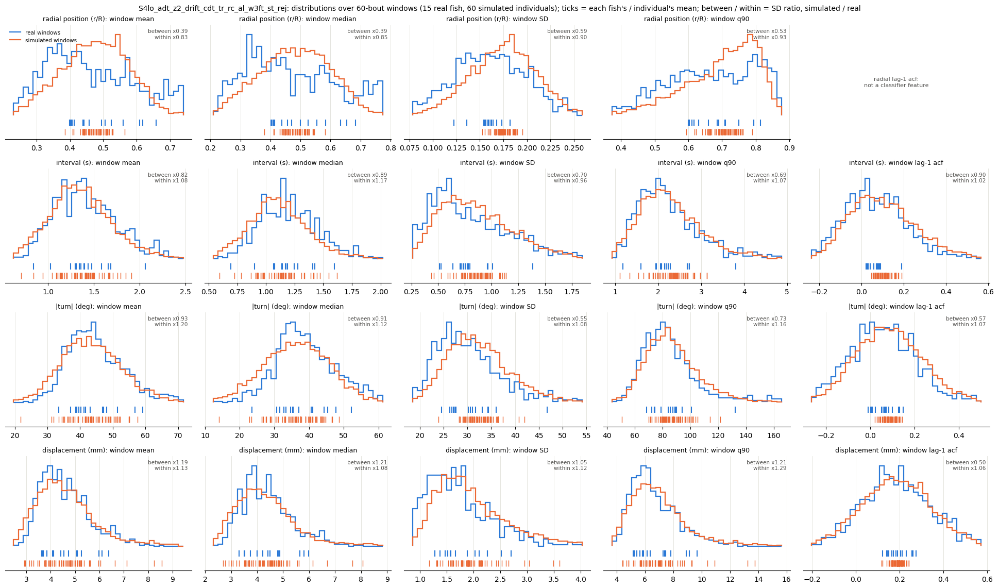

In [ ]:
# Model 42d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_42d = window_stats_grid("report_ckpts/M42d", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 11.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.20     0.81  0.15  0.24   3.0   5.0                  22.3 +/- 0.9  21.9 +/- 1.0
d2s3.5    2.36     1.76  2.64  2.88  11.0   9.0                  17.4 +/- 0.9  20.2 +/- 0.9
d4s3.5    2.00     1.14  4.68  3.23  19.0   9.0                  18.7 +

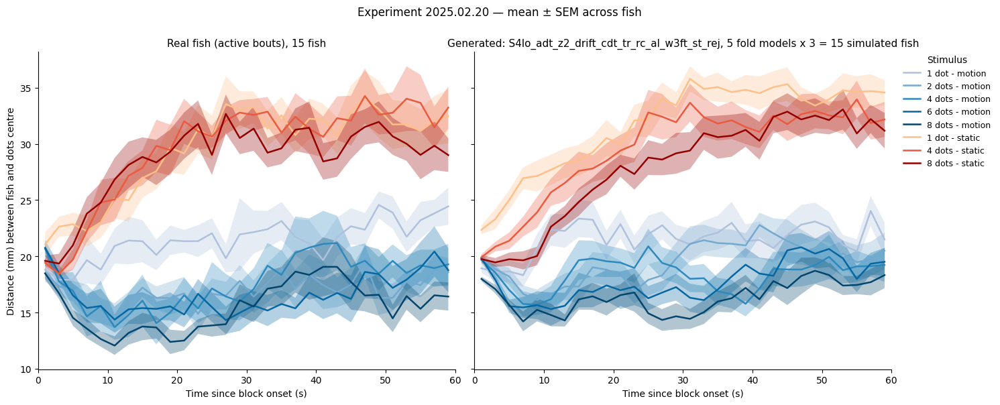

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M42d", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

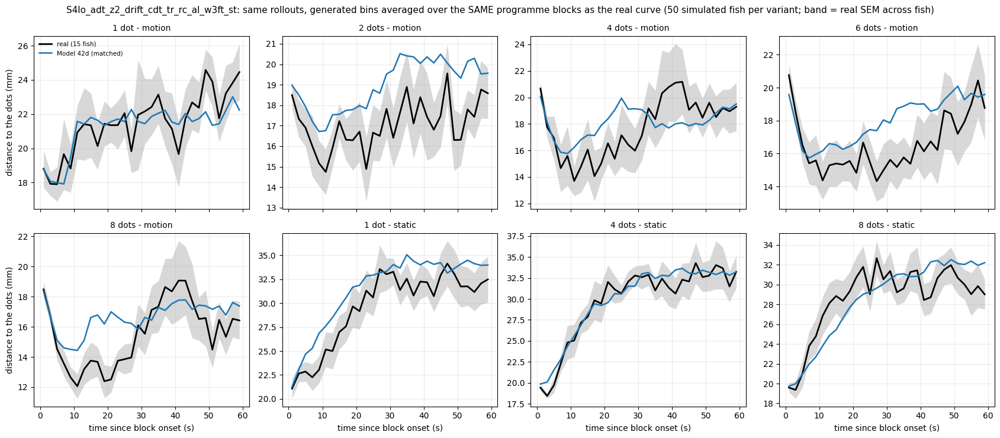

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_42d, _ = profile_variants_matched("report_ckpts/M42d", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 42d": {"arm": "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_42d, _ = attraction_table("report_ckpts/M42d", ["S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                                plateau   null attraction
cond_label                                                                                   
d1s3.5       22.41  23.57       1.16                                  21.51  23.32       1.81
d2s3.5       17.39  23.58       6.19                                  19.54  22.88       3.35
d4s3.5       18.74  23.93       5.19                                  19.30  22.79       3.49
d6s3.5       16.69  23.12       6.43                                  18.19  23.22       5.03
d8s3.5       16.41  23.36       6.94                                  17.27  22.65       5.37


In [ ]:
# Model 42d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_42d = toward_by_n("report_ckpts/M42d", ["S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_42d.round(2).to_string())

           real  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                               
0-20 s 1   9.09                                    9.75
       2  13.90                                   11.53
       4  15.73                                   12.45
       6  14.50                                   14.09
       8  16.00                                   16.33
4-20 s 1   6.25                                    8.68
       2  12.27                                   10.48
       4  14.35                                   10.80
       6  12.79                                   12.59
       8  15.11                                   14.61


Model 42d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 42d   real gap Model 42d    real gap Model 42d
cond                                                                  
d1s3.5  25.08         -9.27   6.64          3.71    7.55          2.08
d2s3.5  22.99         -4.25  12.94         -1.56   12.56         -2.10
d4s3.5  27.14         -6.33  15.54         -4.67   12.09         -0.68
d6s3.5  32.55        -10.60  13.80          0.03   15.84         -2.75
d8s3.5  34.04         -8.74  14.45          0.97   13.80          0.42
d1s0     6.82         -6.85   4.22         -3.54    1.96         -0.87
d4s0     4.81         -2.50   1.86         -0.22    1.74          1.19
d8s0     5.26         -1.41   2.63         -0.56    2.39          1.31

turn size |Δθ| (deg): real f

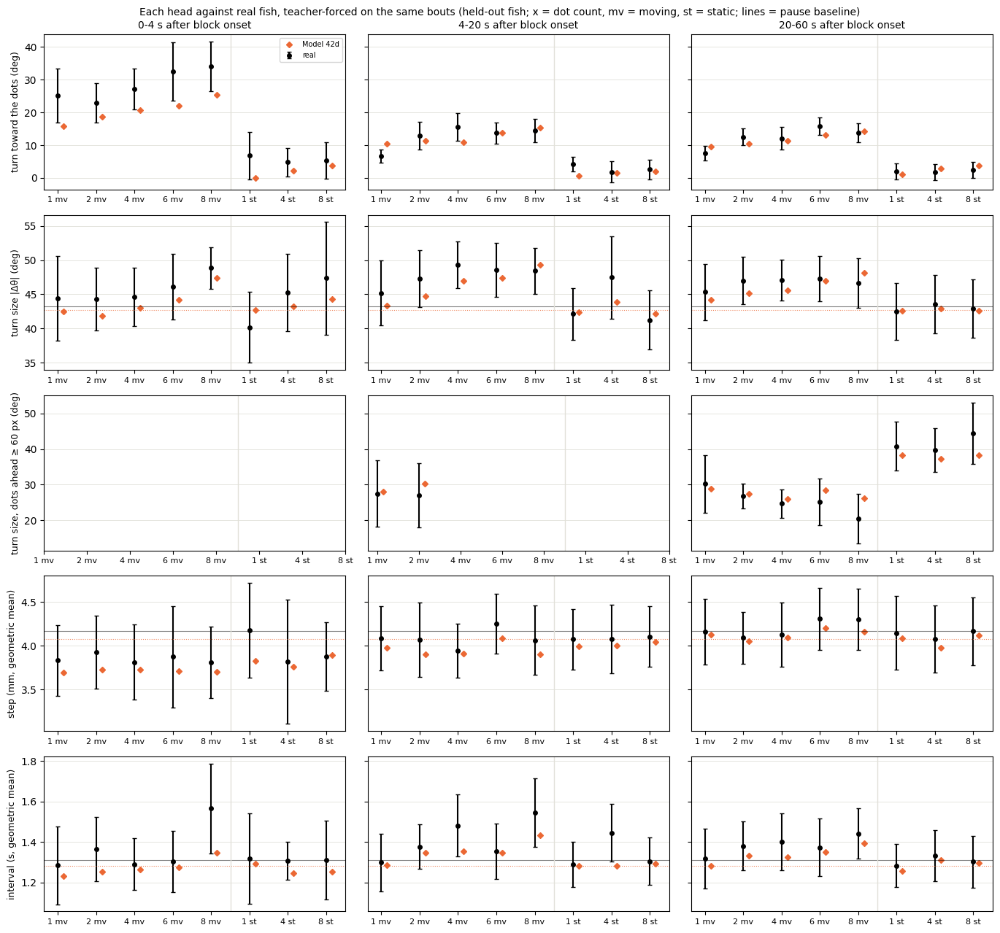

In [ ]:
# Model 42d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_42d, hg_42d = head_gaps({"Model 42d": ("report_ckpts/M42d", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

<a id="m42e"></a>
### F (14f), lower clip

**Change:** the lower-clip D4 + profile correction

No effect: likelihood +0.005 | −0.005 bits, matched AUC +0.020 | −0.013, dip +0.18 | +0.12 mm, grading −0.28 | +0.07 mm, moving error 0.00 | +0.14, static error +0.15 | +0.07.

#### F (14f), lower clip — seed 0 (key `42e`)

In [ ]:
# Model 42e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M42e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_42e = _l[_l.arm == "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_42e.index = ["turn", "displacement", "interval", "joint"]
print(lik_42e.round(3).to_string())

turn             7.620
displacement     4.517
interval         1.212
joint           13.349


In [ ]:
# Model 42e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_42e, c2st_42e = run(ckpt_dir="report_ckpts/M42e", arms="S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 1188s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                           8.3552
symbol_js                                                               0.0143
dt_w1                                                                   0.4115
dist_w1                

In [ ]:
# Model 42e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M42e", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_42e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_42e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.667            0.007      0.609         0.013
matched to the real runs (same bouts, 1:1)            0.661            0.008      0.596         0.016



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.473         0.088        0.041          0.468         0.889
                      median           0.449       0.476         0.098        0.045          0.465         0.895
                      SD               0.159       0.172         0.015        0.012          0.753         0.974
                      q90              0.679       0.714         0.074        0.051

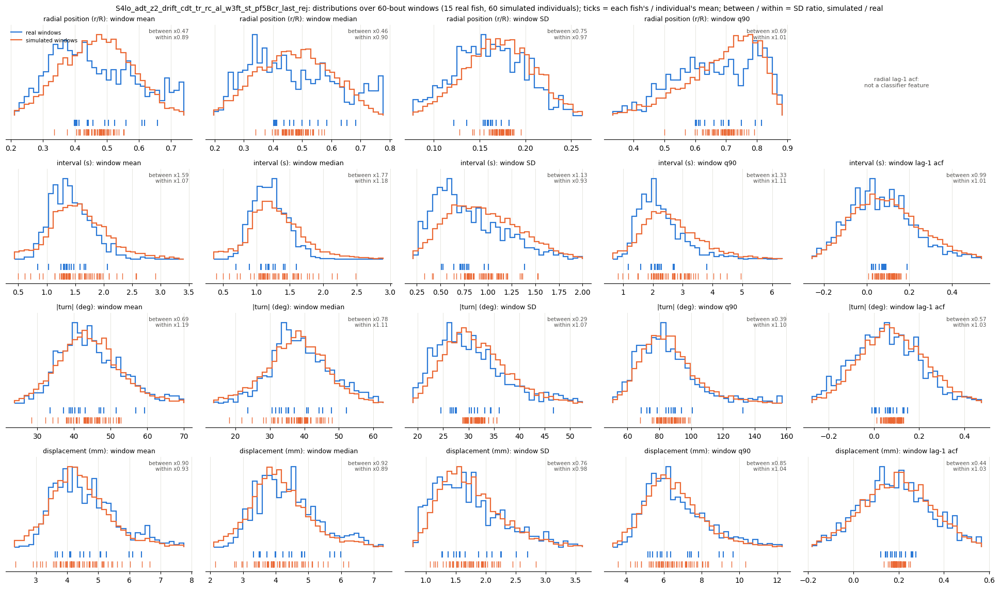

In [ ]:
# Model 42e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_42e = window_stats_grid("report_ckpts/M42e", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold0.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold1.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold2.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold3.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.59     1.03  0.15  0.54   3.0   5.0                  22.3 +/- 0.9  21.2 +/- 1.0
d2s3.5    1.09     0.88  2.64  3.45  11.0  19.0                  17.4 +/- 0.9  18.1 +/- 0.9
d4s3.5    2

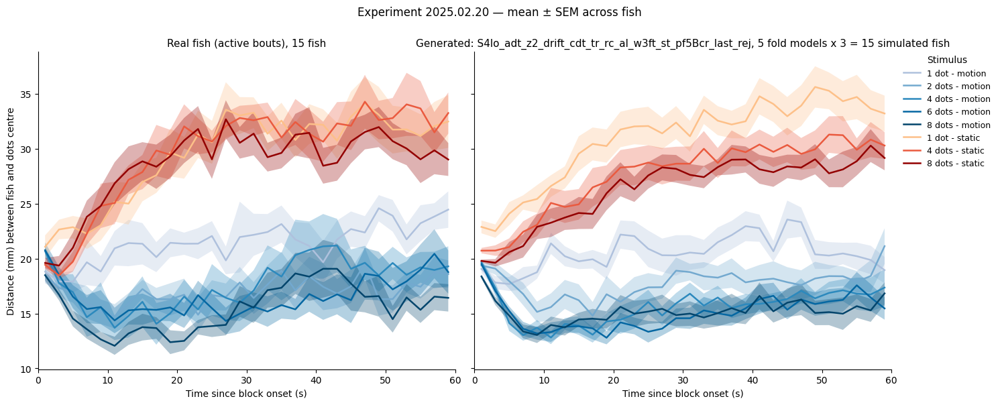

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M42e", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

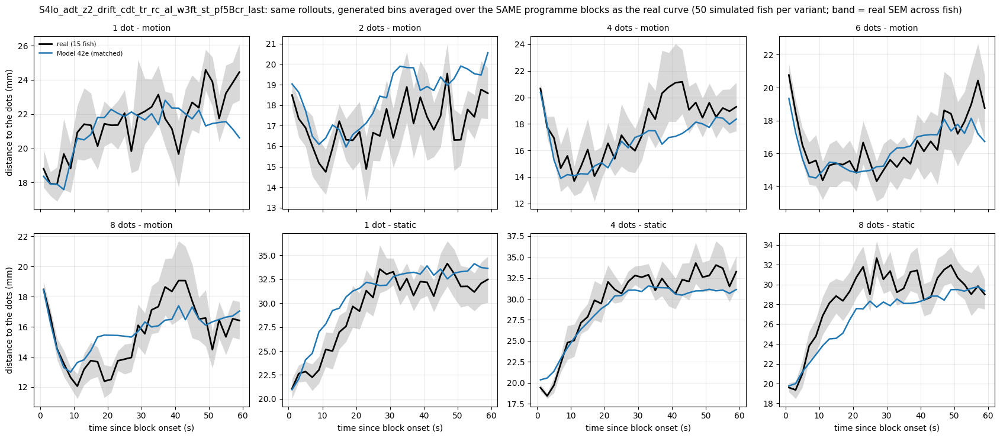

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_42e, _ = profile_variants_matched("report_ckpts/M42e", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", {"Model 42e": {"arm": "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_42e, _ = attraction_table("report_ckpts/M42e", ["S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                            plateau   null attraction
cond_label                                                                                               
d1s3.5       22.41  23.57       1.16                                              21.93  22.57       0.64
d2s3.5       17.39  23.58       6.19                                              18.30  22.58       4.27
d4s3.5       18.74  23.93       5.19                                              16.83  22.41       5.58
d6s3.5       16.69  23.12       6.43                                              16.31  22.33       6.02
d8s3.5       16.41  23.36       6.94                  

In [ ]:
# Model 42e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_42e = toward_by_n("report_ckpts/M42e", ["S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_42e.round(2).to_string())

           real  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
win    N                                                           
0-20 s 1   9.09                                                9.51
       2  13.90                                               13.44
       4  15.73                                               14.54
       6  14.50                                               15.97
       8  16.00                                               17.23
4-20 s 1   6.25                                                8.24
       2  12.27                                               12.73
       4  14.35                                               13.18
       6  12.79                                               14.56
       8  15.11                                               15.29


Model 42e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 42e   real gap Model 42e    real gap Model 42e
cond                                                                  
d1s3.5  25.08         -8.95   6.64          3.65    7.55          2.23
d2s3.5  22.99         -3.25  12.94          0.10   12.56         -1.36
d4s3.5  27.14         -5.41  15.54         -1.81   12.09         -0.05
d6s3.5  32.55         -8.79  13.80          2.05   15.84         -2.57
d8s3.5  34.04         -7.81  14.45          1.87   13.80          0.51
d1s0     6.82         -6.91   4.22         -2.91    1.96         -0.10
d4s0     4.81         -2.59   1.86          1.18    1.74          2.13
d8s0     5.26         -1.12   2.63          1.05    2.39          2.77

turn size |Δθ| (deg): real f

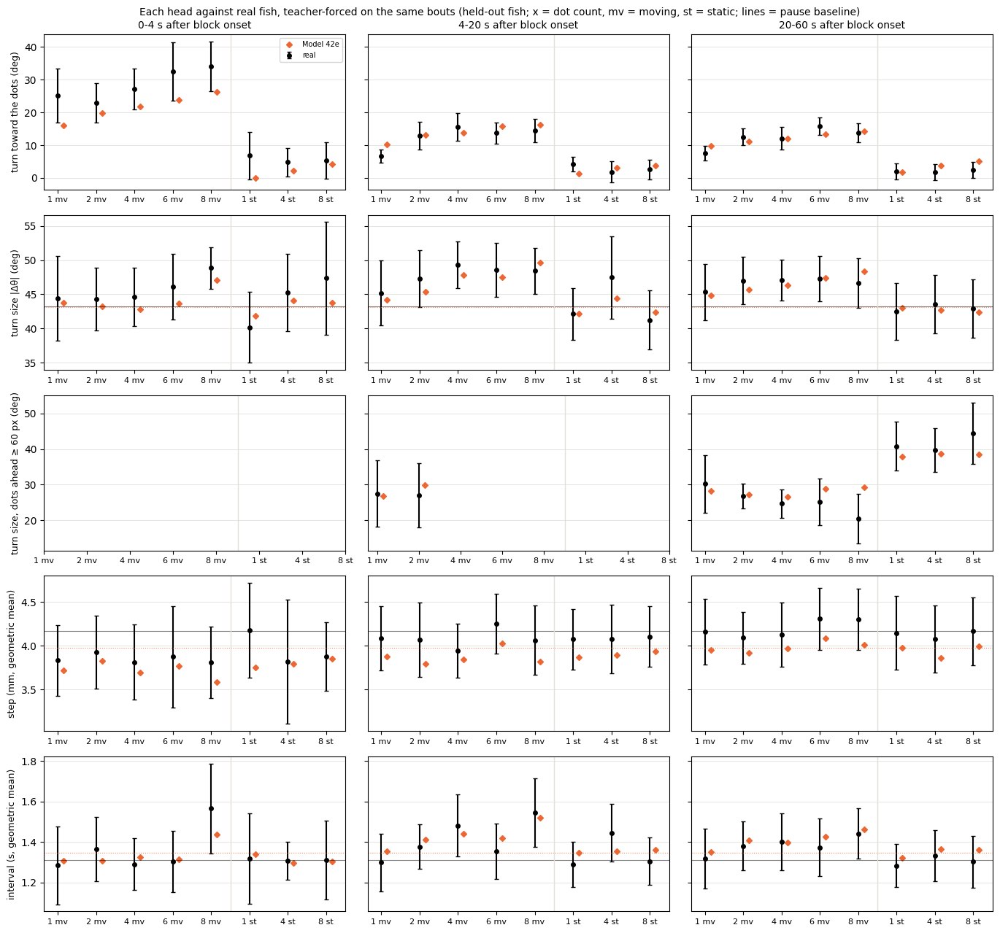

In [ ]:
# Model 42e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_42e, hg_42e = head_gaps({"Model 42e": ("report_ckpts/M42e", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last")}, rej=REJ["wall_reject"])

#### F (14f), lower clip — seed 101 (key `42f`)

In [ ]:
# Model 42f: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M42f/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_42f = _l[_l.arm == "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_42f.index = ["turn", "displacement", "interval", "joint"]
print(lik_42f.round(3).to_string())

turn             7.632
displacement     4.515
interval         1.205
joint           13.352


In [ ]:
# Model 42f: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_42f, c2st_42f = run(ckpt_dir="report_ckpts/M42f", arms="S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 1173s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                           8.5772
symbol_js                                                               0.0137
dt_w1                                                                   0.3601
dist_w1                

In [ ]:
# Model 42f: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M42f", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_42f = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_42f.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.637            0.025      0.558         0.022
matched to the real runs (same bouts, 1:1)            0.630            0.025      0.552         0.022



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.481         0.088        0.034          0.383         0.849
                      median           0.449       0.486         0.098        0.038          0.384         0.856
                      SD               0.159       0.175         0.015        0.009          0.567         0.920
                      q90              0.679       0.723         0.074        0.039

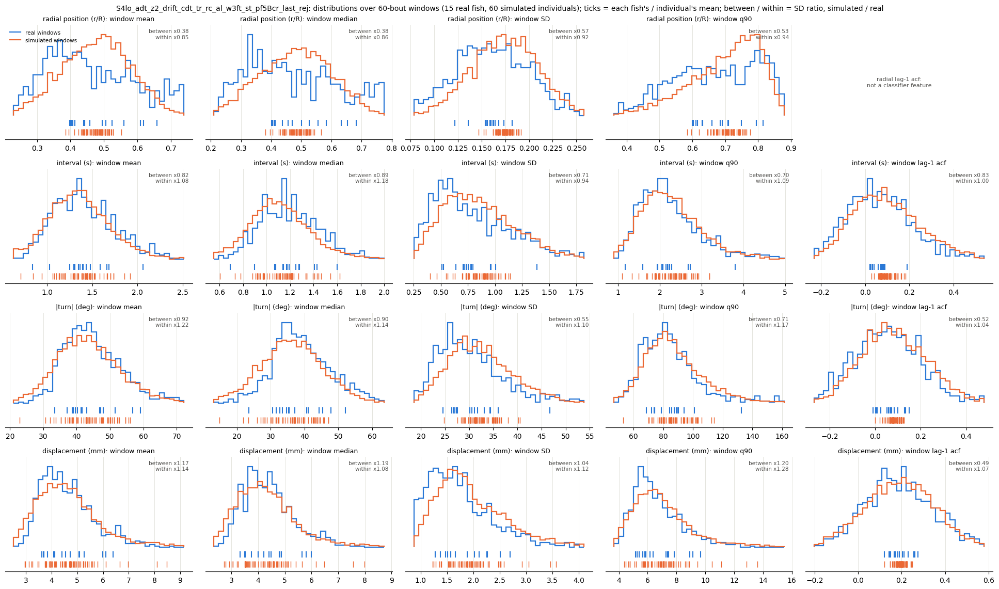

In [ ]:
# Model 42f: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_42f = window_stats_grid("report_ckpts/M42f", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold0.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold1.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold2.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold3.pt: 3 rollouts
  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.67     1.15  0.15  0.83   3.0   5.0                  22.3 +/- 0.9  21.5 +/- 0.7
d2s3.5    2.04     1.60  2.64  3.57  11.0  11.0                  17.4 +/- 0.9  19.6 +/- 1.3
d4s3.5    1

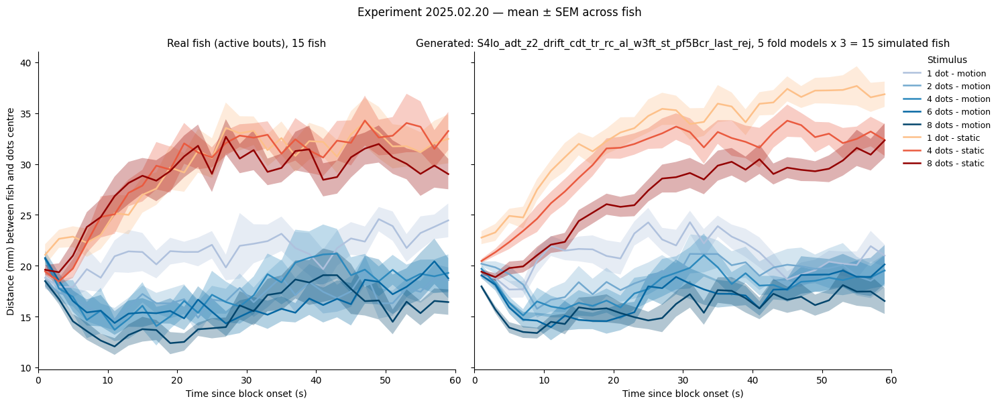

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42f: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M42f", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

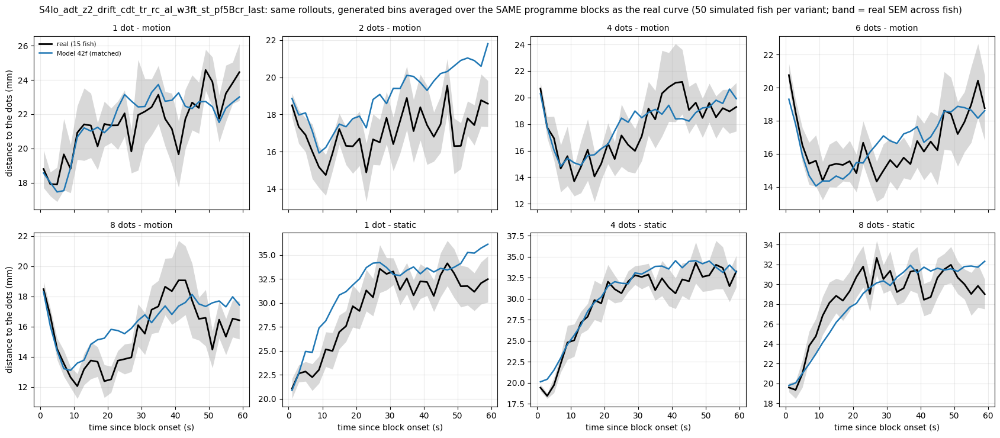

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42f: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_42f, _ = profile_variants_matched("report_ckpts/M42f", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", {"Model 42f": {"arm": "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 42f: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_42f, _ = attraction_table("report_ckpts/M42f", ["S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                            plateau   null attraction
cond_label                                                                                               
d1s3.5       22.41  23.57       1.16                                              22.38  23.01       0.62
d2s3.5       17.39  23.58       6.19                                              20.02  22.99       2.97
d4s3.5       18.74  23.93       5.19                                              18.60  23.01       4.41
d6s3.5       16.69  23.12       6.43                                              17.30  23.15       5.85
d8s3.5       16.41  23.36       6.94                  

In [ ]:
# Model 42f: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_42f = toward_by_n("report_ckpts/M42f", ["S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_42f.round(2).to_string())

           real  S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
win    N                                                           
0-20 s 1   9.09                                                9.75
       2  13.90                                               13.64
       4  15.73                                               15.72
       6  14.50                                               17.41
       8  16.00                                               20.32
4-20 s 1   6.25                                                8.68
       2  12.27                                               12.71
       4  14.35                                               14.30
       6  12.79                                               16.05
       8  15.11                                               18.77


Model 42f: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 42f   real gap Model 42f    real gap Model 42f
cond                                                                  
d1s3.5  25.08         -9.27   6.64          3.71    7.55          2.08
d2s3.5  22.99         -2.36  12.94          0.61   12.56         -1.85
d4s3.5  27.14         -3.71  15.54         -1.21   12.09         -0.37
d6s3.5  32.55         -8.50  13.80          3.40   15.84         -2.36
d8s3.5  34.04         -5.63  14.45          5.03   13.80          0.95
d1s0     6.82         -6.85   4.22         -3.54    1.96         -0.87
d4s0     4.81         -2.50   1.86         -0.22    1.74          1.19
d8s0     5.26         -1.41   2.63         -0.56    2.39          1.31

turn size |Δθ| (deg): real f

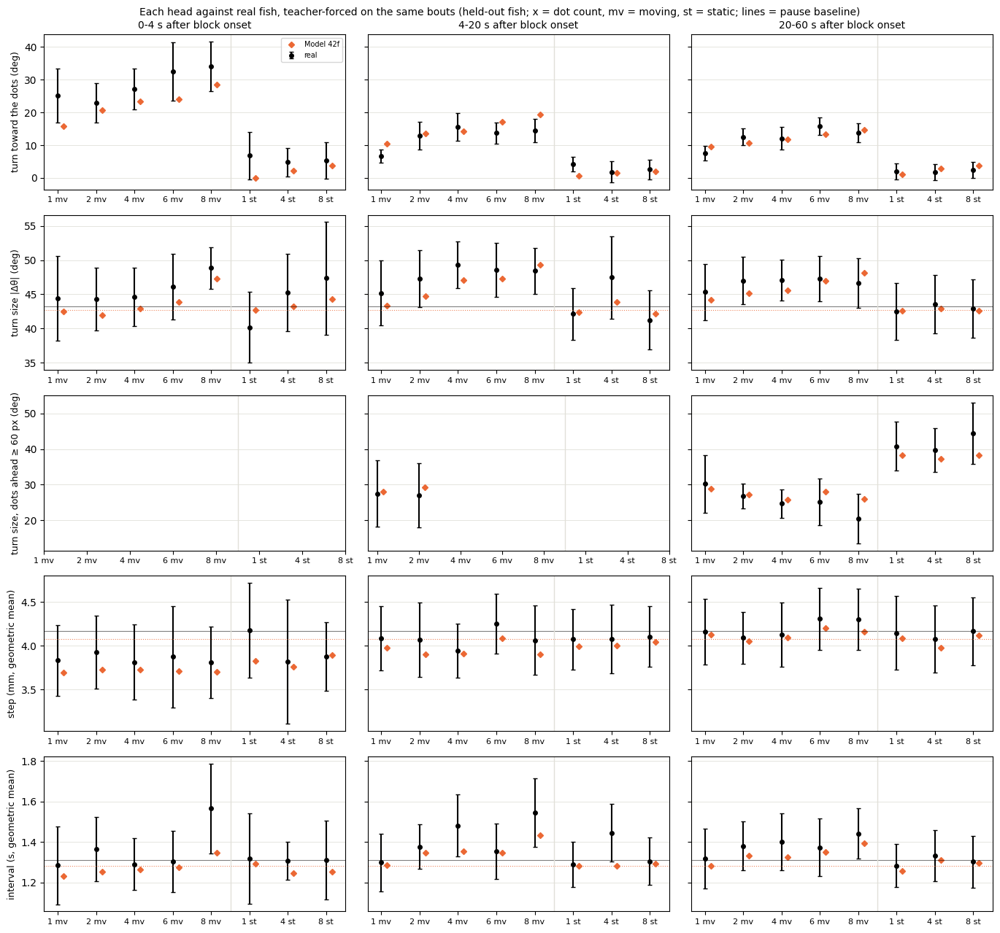

In [ ]:
# Model 42f: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_42f, hg_42f = head_gaps({"Model 42f": ("report_ckpts/M42f", "S4lo_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="tau"></a>
## 5. Slow-state time constant — tau = 200 bouts instead of 70

D4 and F retrained
with the AR(1) drift's time constant at 200 bouts instead of 70, everything else unchanged (same recipe, folds and
seeds; F = the tau-200 D4 + the same profile correction). In the real data the correlation between 60-bout window means
falls by a factor of about 0.75 per window for log displacement and 0.7 for radial position (tau ~220 and ~160 bouts;
not determined for the interval), whereas tau = 70 forgets by 0.42 per window. If the shorter time constant limited the
drift, these would beat their tau-70 versions at both seeds.

<a id="m37a"></a>
### D4 (Model 17), tau = 200

**Change:** Model 17 with tau = 200 bouts



#### D4 (Model 17), tau = 200 — seed 0 (key `37a`)

In [ ]:
# Model 37a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M37a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_37a = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_37a.index = ["turn", "displacement", "interval", "joint"]
print(lik_37a.round(3).to_string())

turn             7.626
displacement     4.515
interval         1.205
joint           13.347


In [ ]:
# Model 37a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_37a, c2st_37a = run(ckpt_dir="report_ckpts/M37a", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 1233s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  9.1021
symbol_js                                                      0.0147
dt_w1                                                          0.4290
dist_w1                                                        4.7815
trans_js                 

In [ ]:
# Model 37a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M37a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_37a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_37a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.673            0.021      0.619         0.026
matched to the real runs (same bouts, 1:1)            0.659            0.025      0.610         0.030



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.473         0.088        0.044          0.507         0.879
                      median           0.449       0.479         0.098        0.051          0.517         0.883
                      SD               0.159       0.174         0.015        0.012          0.779         0.959
                      q90              0.679       0.716         0.074        0.051

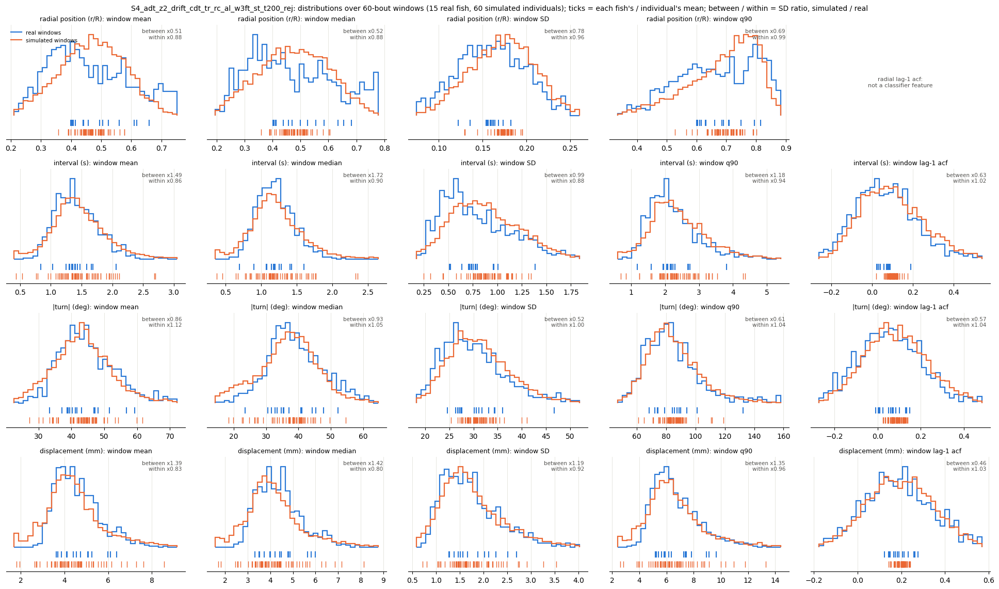

In [ ]:
# Model 37a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_37a = window_stats_grid("report_ckpts/M37a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.76     1.16  0.15  1.28   3.0   5.0                  22.3 +/- 0.9  20.3 +/- 1.1
d2s3.5    1.17     0.97  2.64  3.18  11.0  13.0                  17.4 +/- 0.9  18.4 +/- 1.3
d4s3.5    1.62     0.93  4.68  3.79  19.0   7.0         

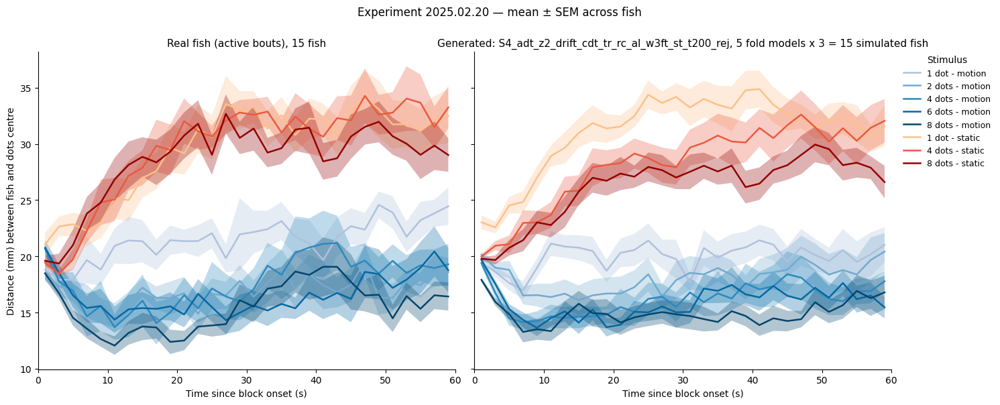

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M37a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

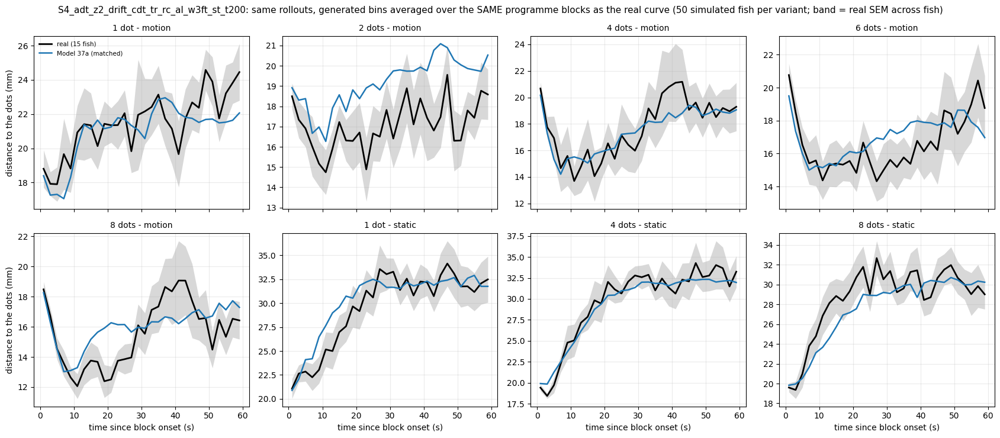

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_37a, _ = profile_variants_matched("report_ckpts/M37a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", {"Model 37a": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_37a, _ = attraction_table("report_ckpts/M37a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     21.94  22.67       0.73
d2s3.5       17.39  23.58       6.19                                     19.07  22.56       3.49
d4s3.5       18.74  23.93       5.19                                     17.88  22.80       4.93
d6s3.5       16.69  23.12       6.43                                     17.70  22.55       4.85
d8s3.5       16.41  23.36       6.94                                     16.40  22.84       6.45


In [ ]:
# Model 37a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_37a = toward_by_n("report_ckpts/M37a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"])
print(tow_37a.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
win    N                                                  
0-20 s 1   9.09                                       9.32
       2  13.90                                      11.25
       4  15.73                                      12.88
       6  14.50                                      13.48
       8  16.00                                      15.42
4-20 s 1   6.25                                       7.94
       2  12.27                                      10.20
       4  14.35                                      11.36
       6  12.79                                      12.04
       8  15.11                                      13.24


Model 37a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 37a   real gap Model 37a    real gap Model 37a
cond                                                                  
d1s3.5  25.08         -8.56   6.64          3.43    7.55          1.57
d2s3.5  22.99         -4.51  12.94         -2.08   12.56         -2.20
d4s3.5  27.14         -6.33  15.54         -3.45   12.09         -0.86
d6s3.5  32.55        -10.24  13.80         -0.20   15.84         -3.05
d8s3.5  34.04         -8.28  14.45          0.47   13.80          0.03
d1s0     6.82         -6.80   4.22         -3.01    1.96         -0.27
d4s0     4.81         -2.89   1.86          0.33    1.74          1.80
d8s0     5.26         -1.63   2.63          0.56    2.39          2.12

turn size |Δθ| (deg): real f

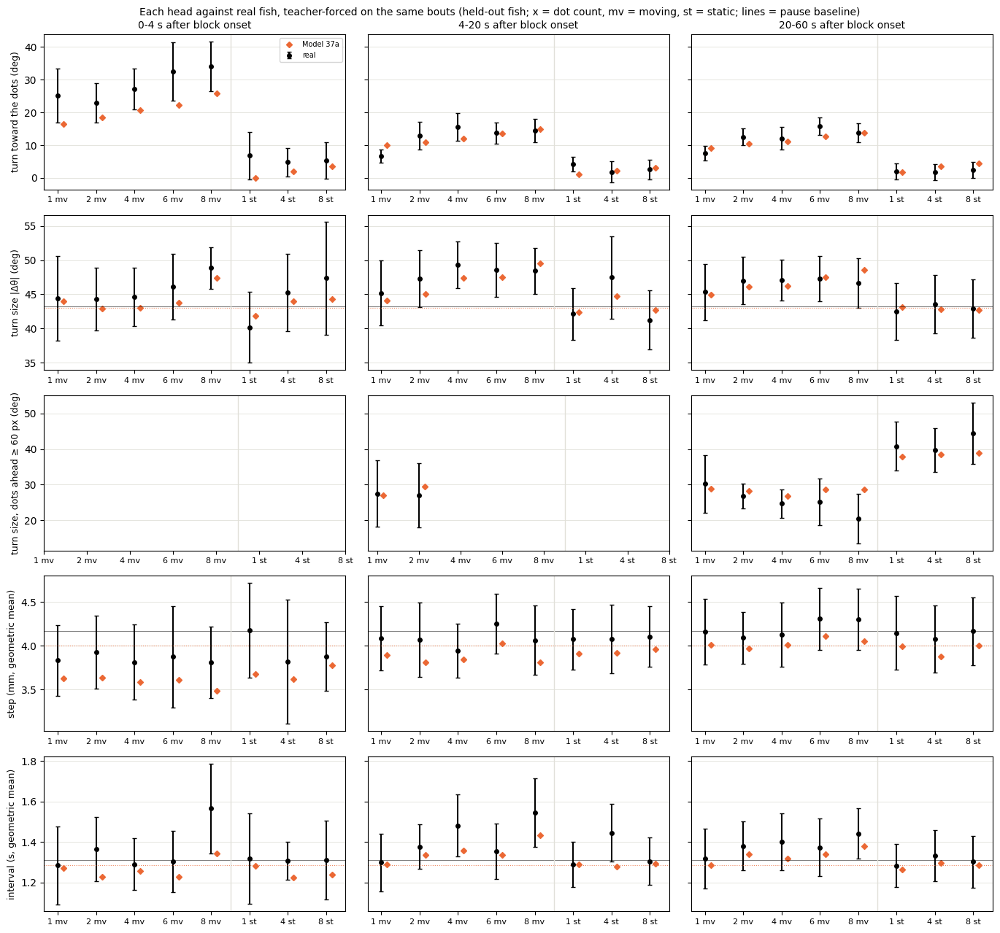

In [ ]:
# Model 37a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_37a, hg_37a = head_gaps({"Model 37a": ("report_ckpts/M37a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200")}, rej=REJ["wall_reject"])

#### D4 (Model 17), tau = 200 — seed 101 (key `37b`)

In [ ]:
# Model 37b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M37b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_37b = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_37b.index = ["turn", "displacement", "interval", "joint"]
print(lik_37b.round(3).to_string())

turn             7.628
displacement     4.503
interval         1.213
joint           13.344


In [ ]:
# Model 37b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_37b, c2st_37b = run(ckpt_dir="report_ckpts/M37b", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 1103s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  8.7585
symbol_js                                                      0.0139
dt_w1                                                          0.3680
dist_w1                                                        3.6330
trans_js                 

In [ ]:
# Model 37b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M37b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_37b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_37b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.571            0.034      0.493         0.032
matched to the real runs (same bouts, 1:1)            0.565            0.036      0.483         0.033



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.482         0.088        0.041          0.465         0.819
                      median           0.449       0.488         0.098        0.046          0.468         0.833
                      SD               0.159       0.178         0.015        0.009          0.610         0.919
                      q90              0.679       0.728         0.074        0.046

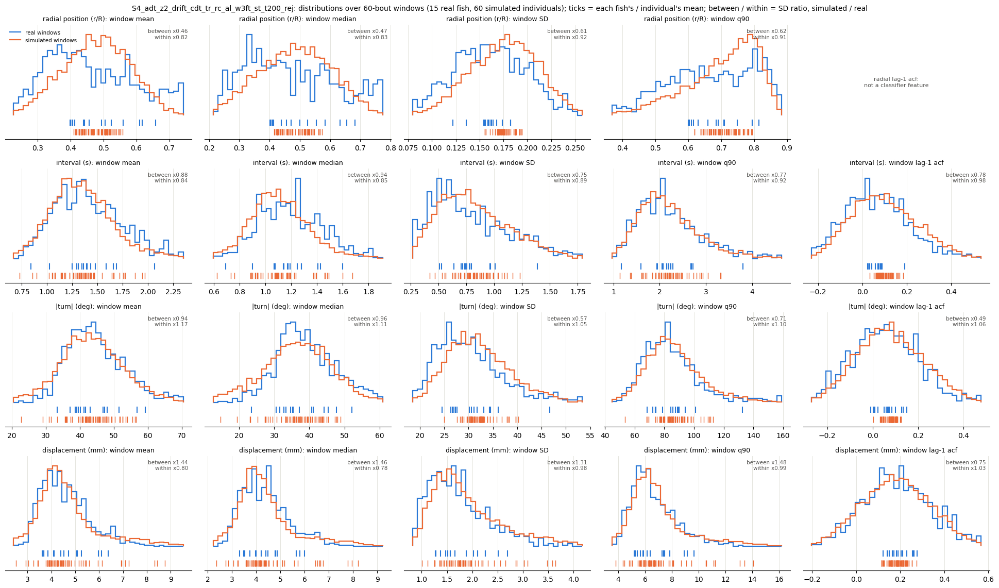

In [ ]:
# Model 37b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_37b = window_stats_grid("report_ckpts/M37b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 11.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.50     1.04  0.15  1.01   3.0   5.0                  22.3 +/- 0.9  20.8 +/- 1.0
d2s3.5    2.03     1.52  2.64  2.68  11.0  17.0                  17.4 +/- 0.9  19.7 +/- 0.9
d4s3.5    1.18     0.72  4.68  3.88  19.0   9.0         

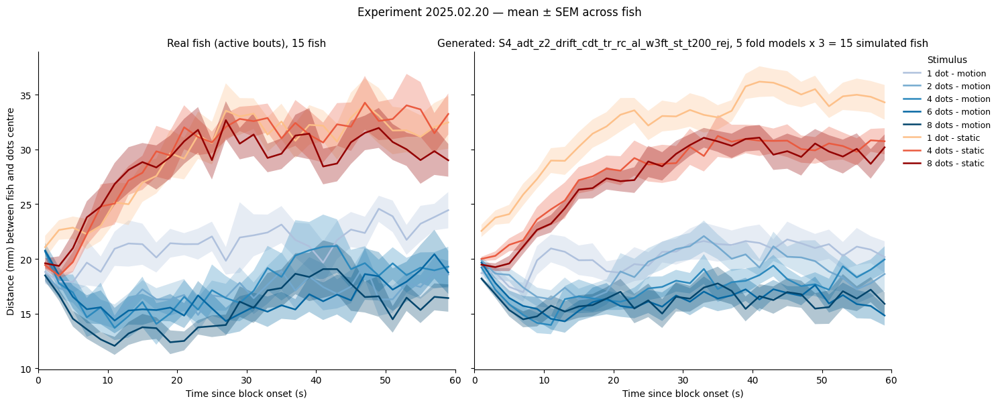

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M37b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

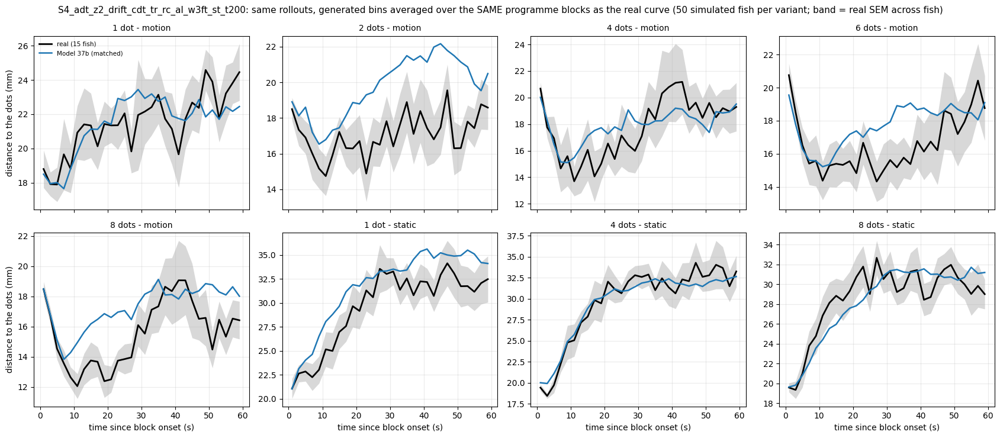

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_37b, _ = profile_variants_matched("report_ckpts/M37b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", {"Model 37b": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_37b, _ = attraction_table("report_ckpts/M37b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     22.64  23.06       0.41
d2s3.5       17.39  23.58       6.19                                     20.87  23.08       2.21
d4s3.5       18.74  23.93       5.19                                     18.97  22.94       3.97
d6s3.5       16.69  23.12       6.43                                     18.10  23.09       5.00
d8s3.5       16.41  23.36       6.94                                     17.88  23.01       5.13


In [ ]:
# Model 37b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_37b = toward_by_n("report_ckpts/M37b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"])
print(tow_37b.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
win    N                                                  
0-20 s 1   9.09                                       9.94
       2  13.90                                      12.08
       4  15.73                                      13.06
       6  14.50                                      14.19
       8  16.00                                      16.67
4-20 s 1   6.25                                       8.72
       2  12.27                                      11.12
       4  14.35                                      11.47
       6  12.79                                      12.45
       8  15.11                                      14.69


Model 37b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 37b   real gap Model 37b    real gap Model 37b
cond                                                                  
d1s3.5  25.08         -9.08   6.64          4.08    7.55          2.06
d2s3.5  22.99         -4.76  12.94         -0.83   12.56         -1.79
d4s3.5  27.14         -5.48  15.54         -3.94   12.09         -0.40
d6s3.5  32.55        -10.89  13.80          1.12   15.84         -2.48
d8s3.5  34.04         -8.86  14.45          1.48   13.80          0.80
d1s0     6.82         -6.08   4.22         -3.18    1.96         -0.12
d4s0     4.81         -1.97   1.86          0.11    1.74          1.77
d8s0     5.26         -0.31   2.63          0.30    2.39          1.95

turn size |Δθ| (deg): real f

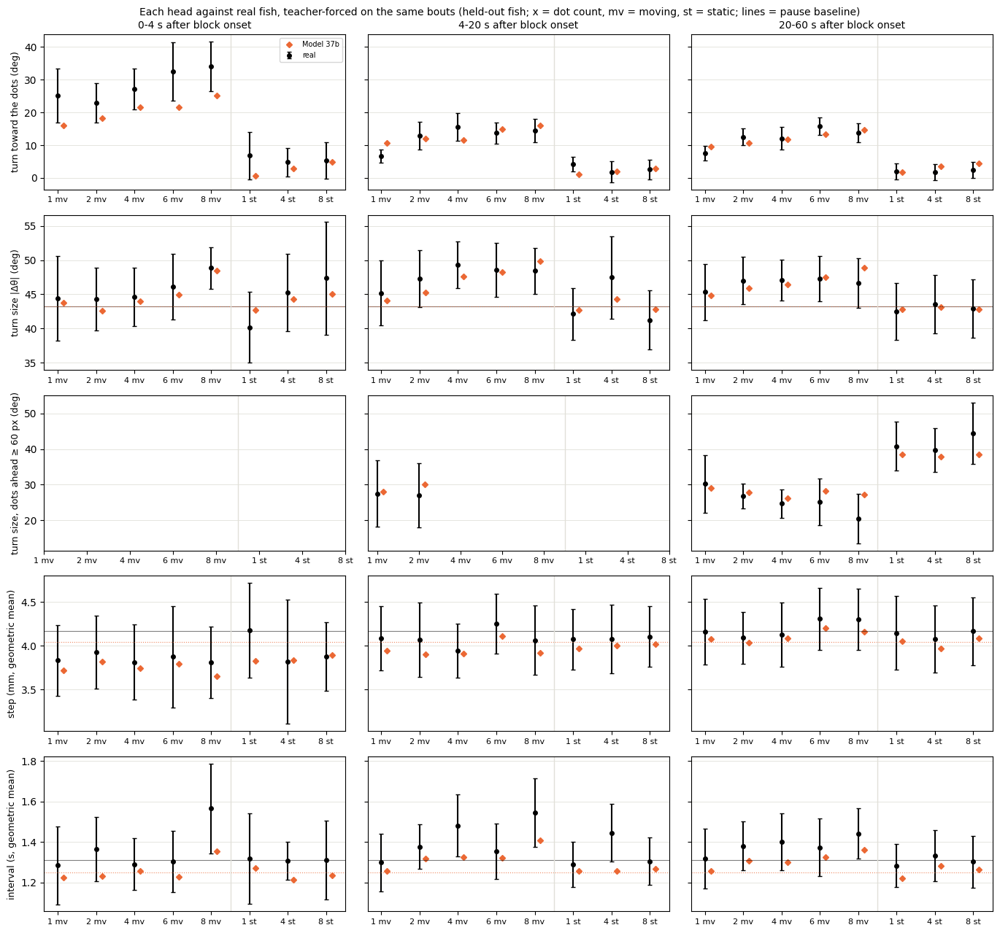

In [ ]:
# Model 37b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_37b, hg_37b = head_gaps({"Model 37b": ("report_ckpts/M37b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200")}, rej=REJ["wall_reject"])

<a id="m37c"></a>
### F (14f), tau = 200

**Change:** the tau-200 D4 + profile correction



#### F (14f), tau = 200 — seed 0 (key `37c`)

In [ ]:
# Model 37c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M37c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_37c = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_37c.index = ["turn", "displacement", "interval", "joint"]
print(lik_37c.round(3).to_string())

turn             7.626
displacement     4.516
interval         1.205
joint           13.347


In [ ]:
# Model 37c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_37c, c2st_37c = run(ckpt_dir="report_ckpts/M37c", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv  (15 rows) in 1010s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_rej
abs_dtheta_w1                                                              8.9465
symbol_js                                                                  0.0147
dt_w1                                                                      0.4285

In [ ]:
# Model 37c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M37c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_37c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_37c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.678            0.020      0.621         0.026
matched to the real runs (same bouts, 1:1)            0.668            0.021      0.605         0.029



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.476         0.088        0.046          0.524         0.874
                      median           0.449       0.482         0.098        0.051          0.521         0.886
                      SD               0.159       0.175         0.015        0.014          0.892         0.949
                      q90              0.679       0.721         0.074        0.055

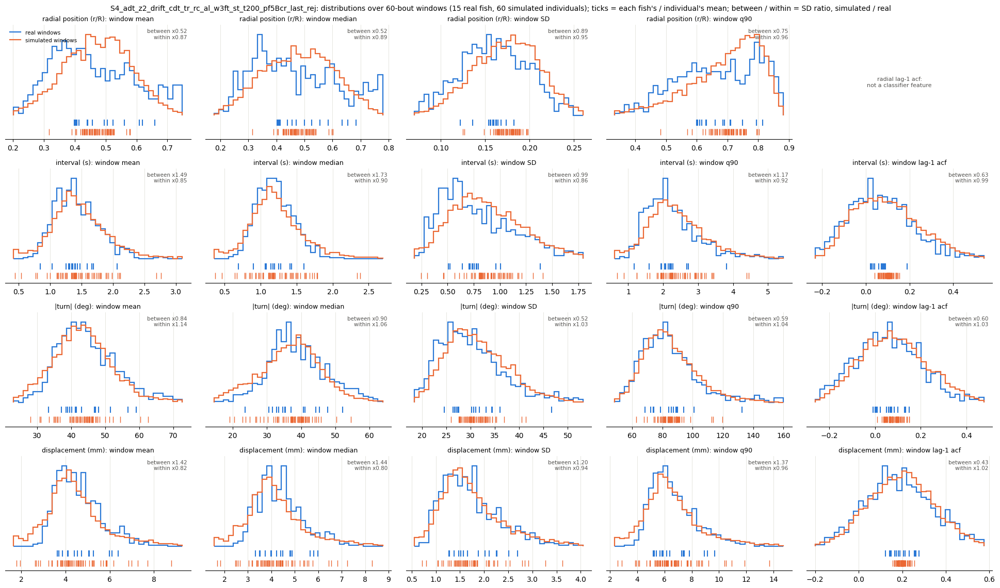

In [ ]:
# Model 37c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_37c = window_stats_grid("report_ckpts/M37c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.68     1.15  0.15  0.91   3.0   5.0                  22.3 +/- 0.9  21.0 +/- 1.1
d2s3.5    0.86     0.70  2.64  3.27  11.0   9.0                  17.4 +/- 0.9  17.3 +/- 

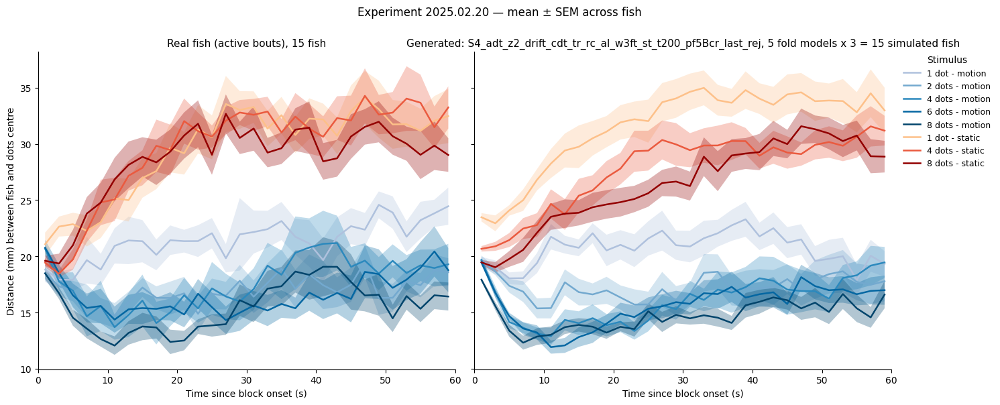

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M37c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

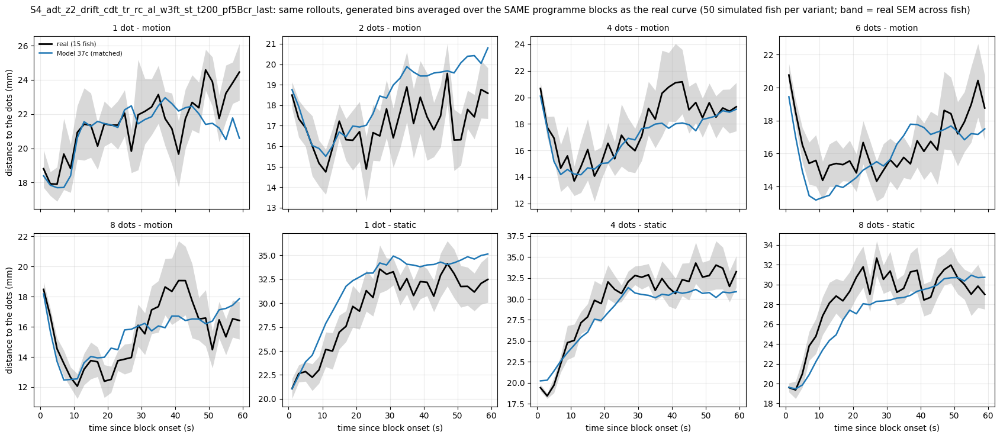

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_37c, _ = profile_variants_matched("report_ckpts/M37c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", {"Model 37c": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_37c, _ = attraction_table("report_ckpts/M37c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last                  
           plateau   null attraction                                               plateau   null attraction
cond_label                                                                                                  
d1s3.5       22.41  23.57       1.16                                                 22.28  22.67       0.39
d2s3.5       17.39  23.58       6.19                                                 18.64  22.74       4.10
d4s3.5       18.74  23.93       5.19                                                 17.58  22.73       5.15
d6s3.5       16.69  23.12       6.43                                                 16.67  22.63       5.97
d8s3.5       16.41  23.36       6

In [ ]:
# Model 37c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_37c = toward_by_n("report_ckpts/M37c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_37c.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last
win    N                                                              
0-20 s 1   9.09                                                   9.32
       2  13.90                                                  13.85
       4  15.73                                                  16.11
       6  14.50                                                  16.75
       8  16.00                                                  19.27
4-20 s 1   6.25                                                   7.94
       2  12.27                                                  13.02
       4  14.35                                                  14.88
       6  12.79                                                  15.51
       8  15.11                                                  17.37


Model 37c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 37c   real gap Model 37c    real gap Model 37c
cond                                                                  
d1s3.5  25.08         -8.56   6.64          3.43    7.55          1.57
d2s3.5  22.99         -2.25  12.94          0.58   12.56         -1.88
d4s3.5  27.14         -4.00  15.54         -0.04   12.09         -0.55
d6s3.5  32.55         -7.90  13.80          3.19   15.84         -2.72
d8s3.5  34.04         -5.78  14.45          4.34   13.80          0.52
d1s0     6.82         -6.80   4.22         -3.01    1.96         -0.27
d4s0     4.81         -2.89   1.86          0.33    1.74          1.80
d8s0     5.26         -1.63   2.63          0.56    2.39          2.12

turn size |Δθ| (deg): real f

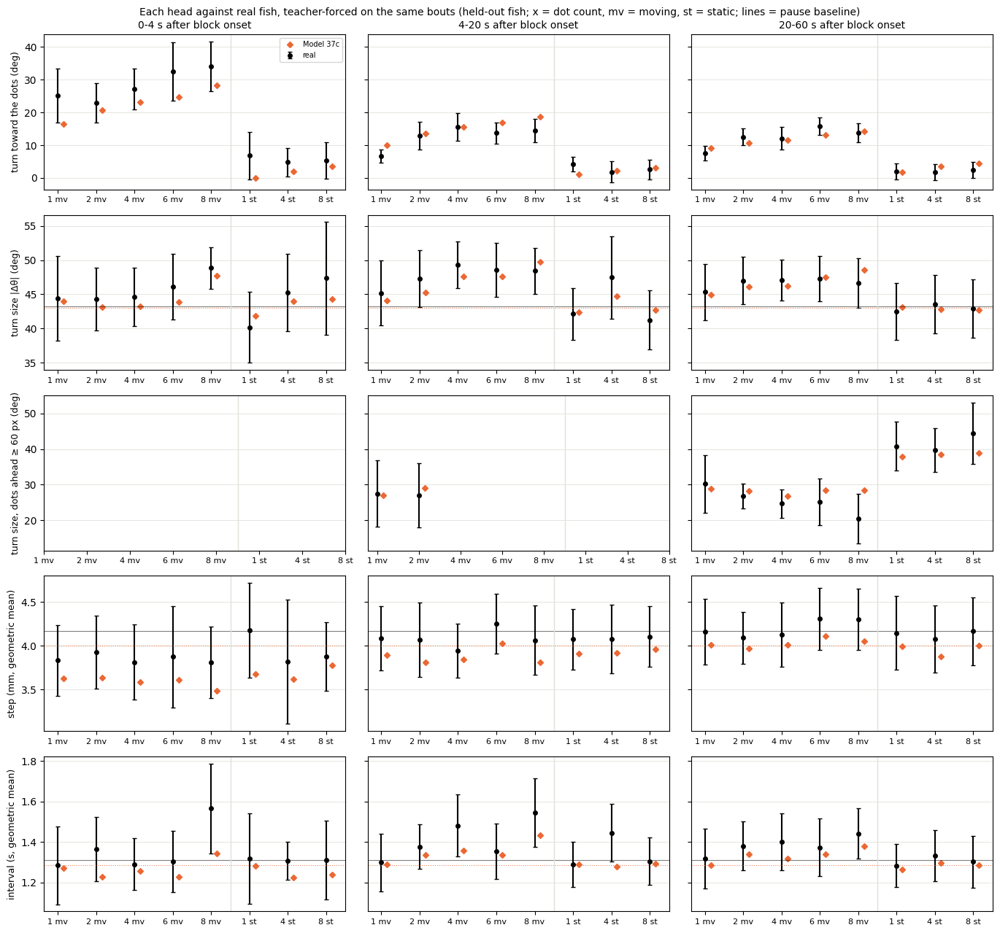

In [ ]:
# Model 37c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_37c, hg_37c = head_gaps({"Model 37c": ("report_ckpts/M37c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last")}, rej=REJ["wall_reject"])

#### F (14f), tau = 200 — seed 101 (key `37d`)

In [ ]:
# Model 37d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M37d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_37d = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_37d.index = ["turn", "displacement", "interval", "joint"]
print(lik_37d.round(3).to_string())

turn             7.628
displacement     4.503
interval         1.213
joint           13.344


In [ ]:
# Model 37d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_37d, c2st_37d = run(ckpt_dir="report_ckpts/M37d", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last.csv  (15 rows) in 673s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_rej
abs_dtheta_w1                                                              8.7888
symbol_js                                                                  0.0139
dt_w1                                                                      0.3674


In [ ]:
# Model 37d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M37d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_37d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_37d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.583            0.033      0.505         0.031
matched to the real runs (same bouts, 1:1)            0.579            0.032      0.496         0.031



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.483         0.088        0.042          0.474         0.822
                      median           0.449       0.490         0.098        0.046          0.475         0.838
                      SD               0.159       0.177         0.015        0.010          0.657         0.918
                      q90              0.679       0.728         0.074        0.047

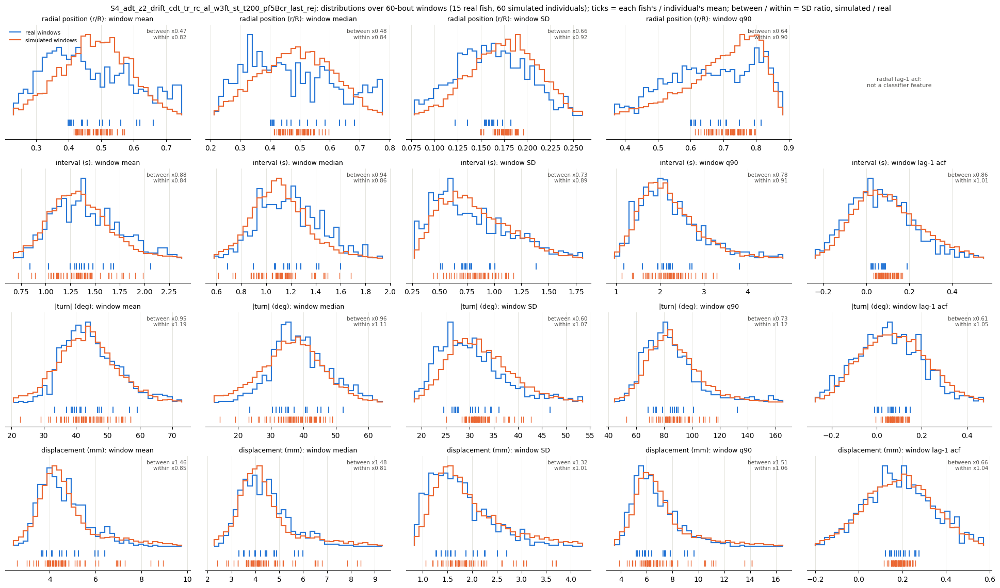

In [ ]:
# Model 37d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_37d = window_stats_grid("report_ckpts/M37d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.20     0.81  0.15  0.08   3.0   3.0                  22.3 +/- 0.9  21.5 +/- 1.0
d2s3.5    1.01     0.84  2.64  4.31  11.0  11.0                  17.4 +/- 0.9  17.8 +/- 

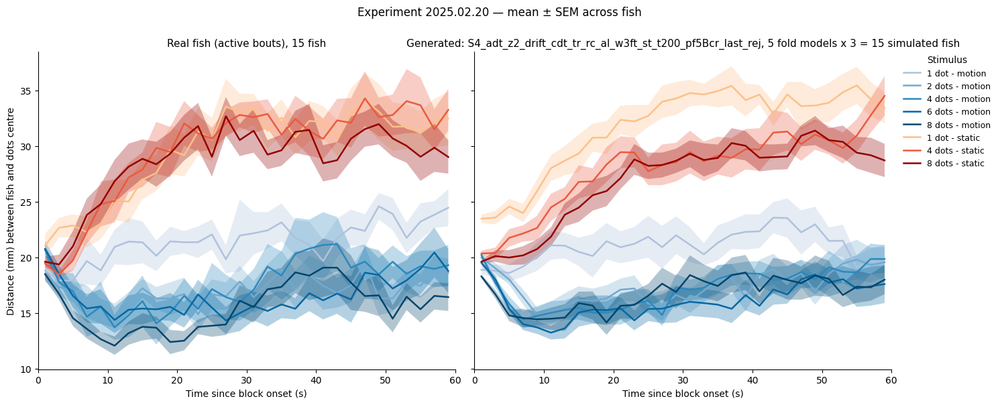

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M37d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

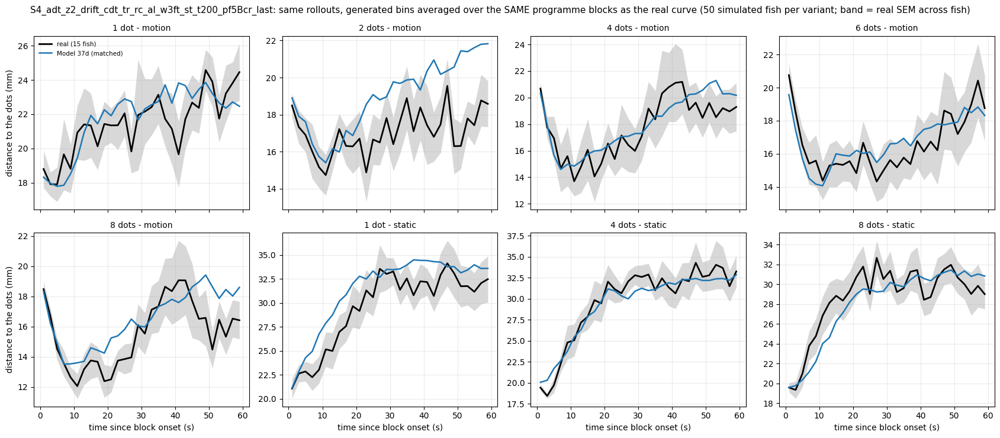

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_37d, _ = profile_variants_matched("report_ckpts/M37d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last", {"Model 37d": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 37d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_37d, _ = attraction_table("report_ckpts/M37d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last                  
           plateau   null attraction                                               plateau   null attraction
cond_label                                                                                                  
d1s3.5       22.41  23.57       1.16                                                 22.71  23.36       0.64
d2s3.5       17.39  23.58       6.19                                                 19.54  23.25       3.72
d4s3.5       18.74  23.93       5.19                                                 19.41  23.06       3.65
d6s3.5       16.69  23.12       6.43                                                 17.60  23.03       5.43
d8s3.5       16.41  23.36       6

In [ ]:
# Model 37d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_37d = toward_by_n("report_ckpts/M37d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_37d.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last
win    N                                                              
0-20 s 1   9.09                                                   9.94
       2  13.90                                                  14.04
       4  15.73                                                  15.76
       6  14.50                                                  16.93
       8  16.00                                                  20.14
4-20 s 1   6.25                                                   8.72
       2  12.27                                                  13.26
       4  14.35                                                  14.41
       6  12.79                                                  15.34
       8  15.11                                                  18.34


Model 37d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 37d   real gap Model 37d    real gap Model 37d
cond                                                                  
d1s3.5  25.08         -9.08   6.64          4.08    7.55          2.06
d2s3.5  22.99         -2.88  12.94          1.16   12.56         -1.55
d4s3.5  27.14         -3.34  15.54         -1.07   12.09         -0.16
d6s3.5  32.55         -8.53  13.80          3.97   15.84         -2.24
d8s3.5  34.04         -6.43  14.45          4.82   13.80          1.27
d1s0     6.82         -6.08   4.22         -3.18    1.96         -0.12
d4s0     4.81         -1.97   1.86          0.11    1.74          1.77
d8s0     5.26         -0.31   2.63          0.30    2.39          1.95

turn size |Δθ| (deg): real f

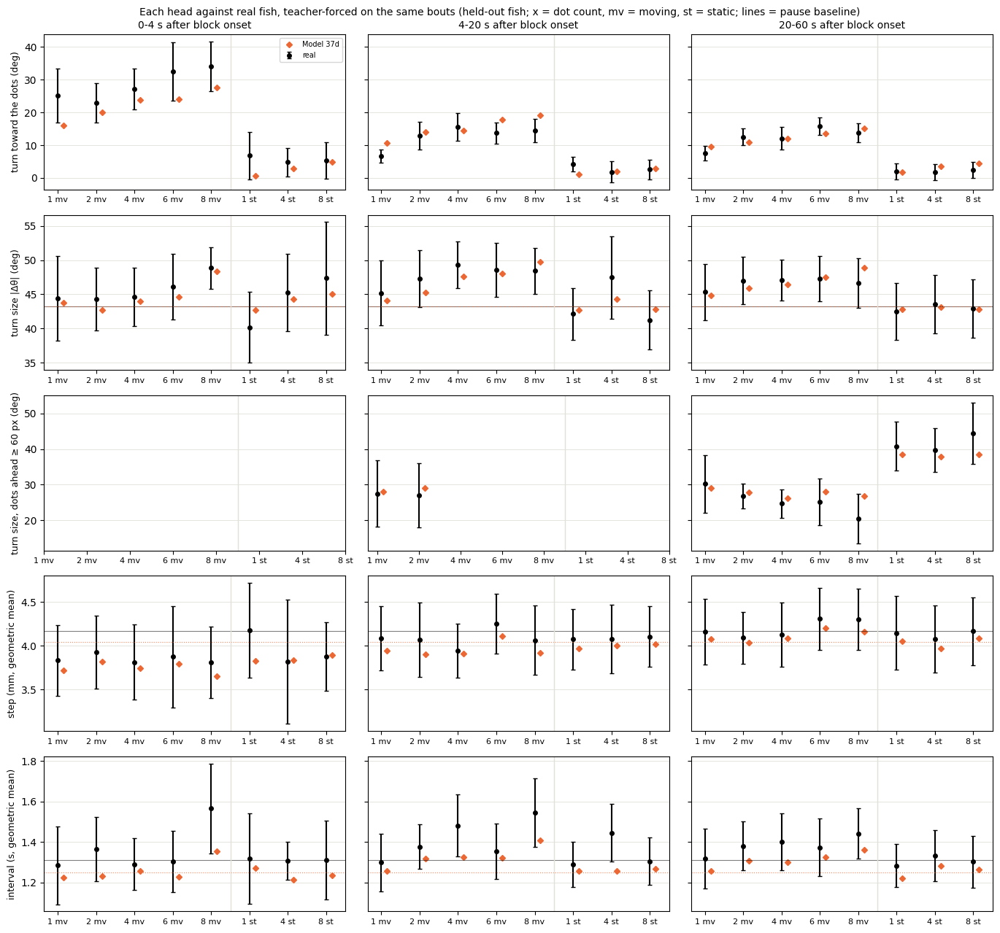

In [ ]:
# Model 37d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_37d, hg_37d = head_gaps({"Model 37d": ("report_ckpts/M37d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="tsize"></a>
## 6. Turn-size individuality — the latent also on the turning scales

M6, D4 and F
retrained with the per-fish latent loading also on the scales of the four turning components (one shared loading), so
how far a fish turns becomes a trait alongside how often it swims straight; everything else unchanged (same recipe,
folds and seeds, and the same initial weights apart from the new loading; F = the turn-size D4 + the same profile
correction). In the data the mean turn size spans 42-64 deg across fish (split-half r = 0.95) and carries most of the
between-fish spread of mean |dtheta|, while the models' between-fish turn spread is 0.70-0.83 of the real one. If the
loading closes that gap, the between-fish turn spread should move toward 1 at both seeds.

<a id="m38a"></a>
### M6 (26e), turn-size latent

**Change:** 26e + turn-size loading



#### M6 (26e), turn-size latent — seed 0 (key `38a`)

In [ ]:
# Model 38a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M38a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_38a = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_38a.index = ["turn", "displacement", "interval", "joint"]
print(lik_38a.round(3).to_string())

turn             7.663
displacement     4.501
interval         1.221
joint           13.385


In [ ]:
# Model 38a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_38a, c2st_38a = run(ckpt_dir="report_ckpts/M38a", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_tz'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv  (15 rows) in 1668s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_rej
abs_dtheta_w1                                        8.5963
symbol_js                                            0.0114
dt_w1                                                0.4041
dist_w1                                              3.5572
trans_js                                             0.0131
acf_l2                                               0.

In [ ]:
# Model 38a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M38a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_38a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_38a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.676            0.011      0.603         0.017
matched to the real runs (same bouts, 1:1)            0.667            0.012      0.603         0.019



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.455         0.088        0.030          0.347         0.923
                      median           0.449       0.451         0.098        0.034          0.345         0.934
                      SD               0.159       0.180         0.015        0.009          0.549         0.996
                      q90              0.679       0.716         0.074        0.037

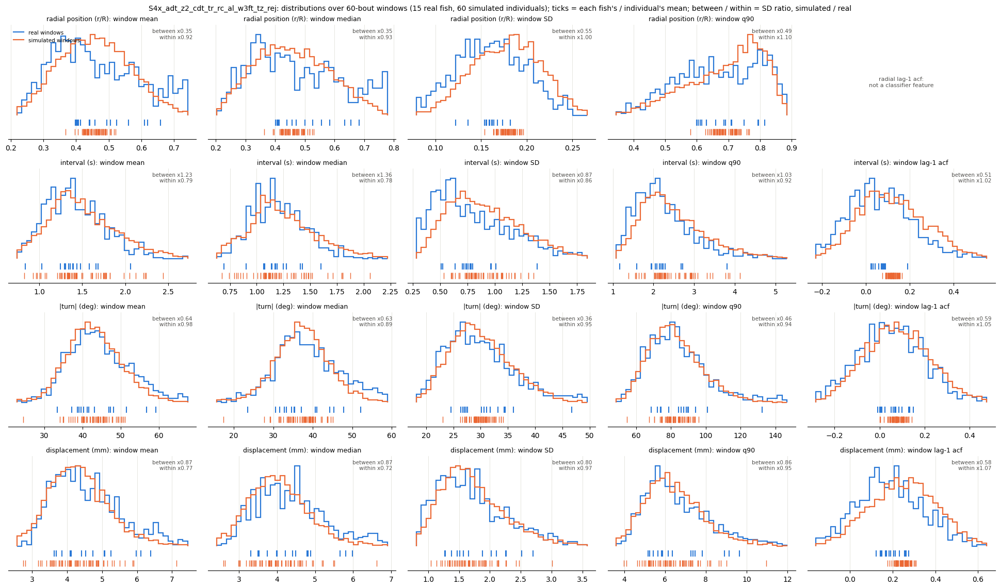

In [ ]:
# Model 38a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_38a = window_stats_grid("report_ckpts/M38a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold4.pt: 3 rollouts
dropped 12.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.22     0.88  0.15  0.49   3.0   5.0                  22.3 +/- 0.9  21.4 +/- 0.8
d2s3.5    1.89     1.45  2.64  2.81  11.0  11.0                  17.4 +/- 0.9  19.5 +/- 0.8
d4s3.5    1.27     0.77  4.68   3.9  19.0   7.0                  18.7 +/- 1.7  18.2 +/- 0.5
d6s3.5    1.50

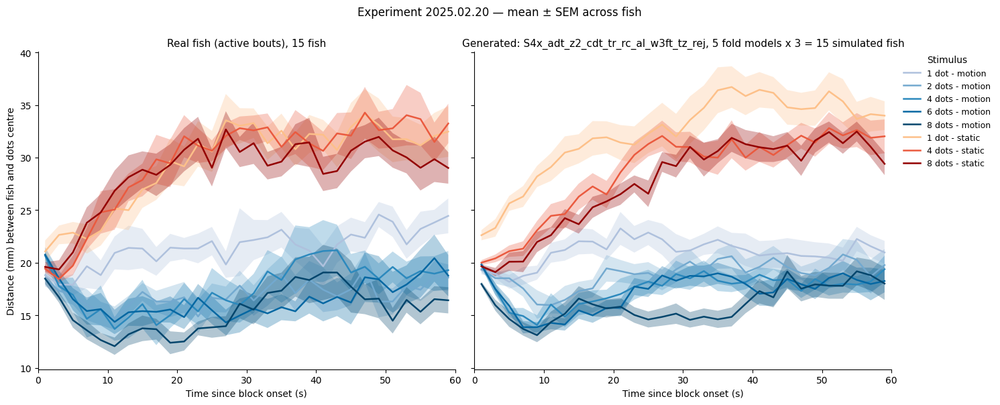

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M38a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

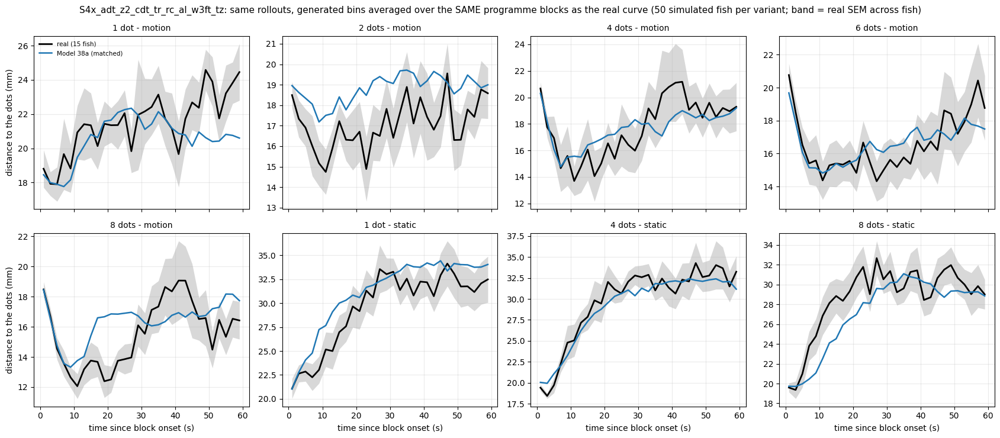

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_38a, _ = profile_variants_matched("report_ckpts/M38a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", {"Model 38a": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_38a, _ = attraction_table("report_ckpts/M38a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_tz"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_tz                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.56  22.66       1.10
d2s3.5       17.39  23.58       6.19                           19.55  22.40       2.85
d4s3.5       18.74  23.93       5.19                           18.28  22.31       4.03
d6s3.5       16.69  23.12       6.43                           17.16  22.31       5.16
d8s3.5       16.41  23.36       6.94                           16.64  22.29       5.65


In [ ]:
# Model 38a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_38a = toward_by_n("report_ckpts/M38a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_tz"], rej=REJ["wall_reject"])
print(tow_38a.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz
win    N                                        
0-20 s 1   9.09                            10.16
       2  13.90                            11.82
       4  15.73                            13.82
       6  14.50                            13.56
       8  16.00                            16.53
4-20 s 1   6.25                             9.17
       2  12.27                            11.35
       4  14.35                            12.76
       6  12.79                            12.44
       8  15.11                            15.18


Model 38a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 38a   real gap Model 38a    real gap Model 38a
cond                                                                  
d1s3.5  25.08         -8.92   6.64          3.83    7.55          2.55
d2s3.5  22.99         -6.06  12.94         -1.05   12.56         -0.98
d4s3.5  27.14         -7.47  15.54         -2.14   12.09          0.47
d6s3.5  32.55        -12.65  13.80          0.66   15.84         -1.91
d8s3.5  34.04        -10.56  14.45          1.60   13.80          1.40
d1s0     6.82         -5.46   4.22         -3.46    1.96          0.23
d4s0     4.81         -1.12   1.86          2.82    1.74          2.40
d8s0     5.26         -1.07   2.63          1.33    2.39          2.84

turn size |Δθ| (deg): real f

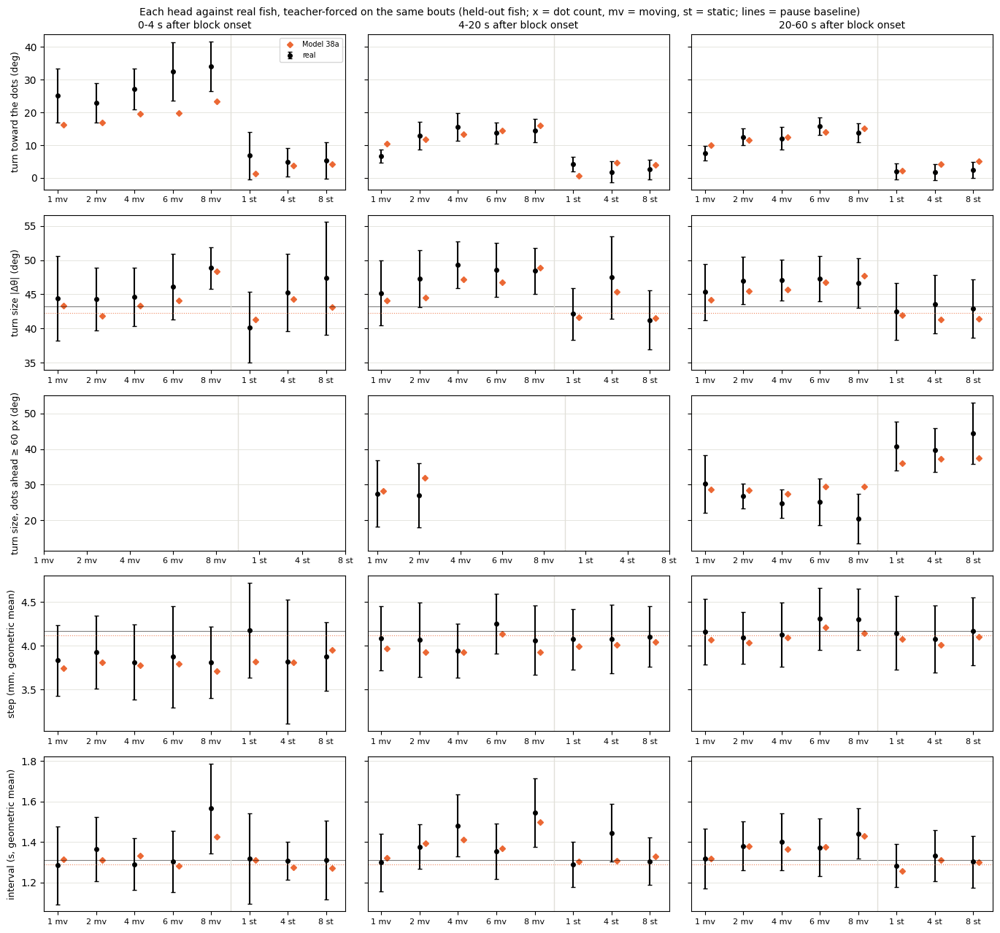

In [ ]:
# Model 38a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_38a, hg_38a = head_gaps({"Model 38a": ("report_ckpts/M38a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz")}, rej=REJ["wall_reject"])

#### M6 (26e), turn-size latent — seed 101 (key `38b`)

In [ ]:
# Model 38b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M38b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_38b = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_38b.index = ["turn", "displacement", "interval", "joint"]
print(lik_38b.round(3).to_string())

turn             7.661
displacement     4.498
interval         1.235
joint           13.395


In [ ]:
# Model 38b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_38b, c2st_38b = run(ckpt_dir="report_ckpts/M38b", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_tz'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_tz.csv  (15 rows) in 1601s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_rej
abs_dtheta_w1                                        7.9085
symbol_js                                            0.0109
dt_w1                                                0.4814
dist_w1                                              3.4252
trans_js                                             0.0128
acf_l2                                               0.

In [ ]:
# Model 38b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M38b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_38b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_38b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.681            0.018      0.607         0.017
matched to the real runs (same bouts, 1:1)            0.673            0.019      0.599         0.021



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.460         0.088        0.028          0.324         0.907
                      median           0.449       0.458         0.098        0.032          0.325         0.925
                      SD               0.159       0.180         0.015        0.009          0.554         0.980
                      q90              0.679       0.717         0.074        0.034

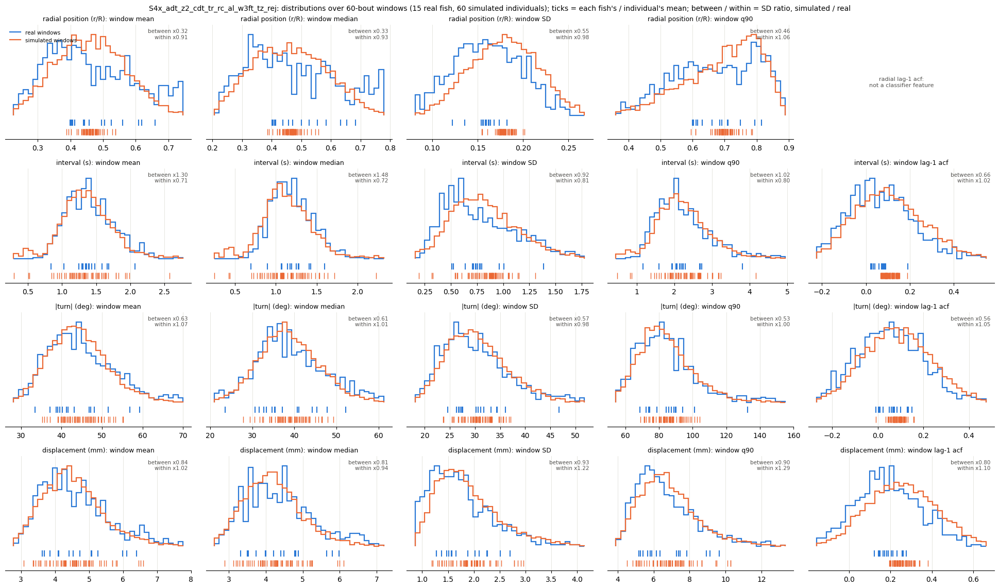

In [ ]:
# Model 38b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_38b = window_stats_grid("report_ckpts/M38b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz_fold4.pt: 3 rollouts
dropped 10.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.73     1.13  0.15  0.42   3.0   5.0                  22.3 +/- 0.9  20.5 +/- 0.6
d2s3.5    1.98     1.64  2.64  1.27  11.0   7.0                  17.4 +/- 0.9  19.3 +/- 0.7
d4s3.5    0.96     0.60  4.68  4.69  19.0  13.0                  18.7 +/- 1.7  18.7 +/- 0.9
d6s3.5    0.95

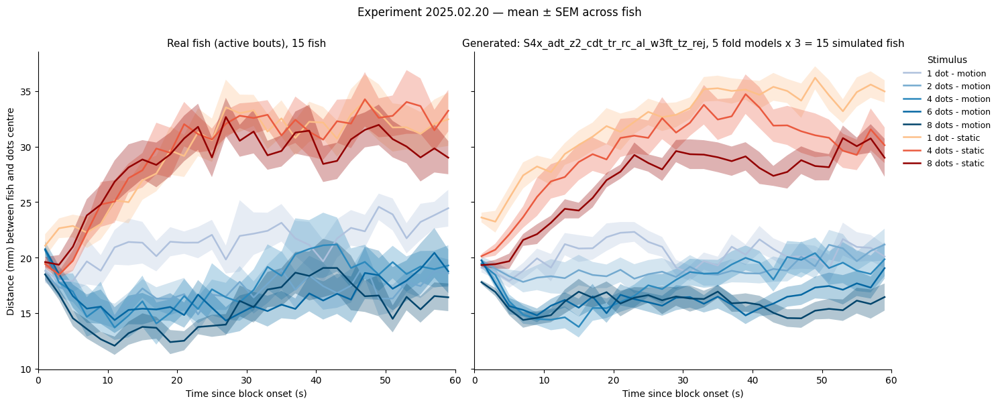

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M38b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

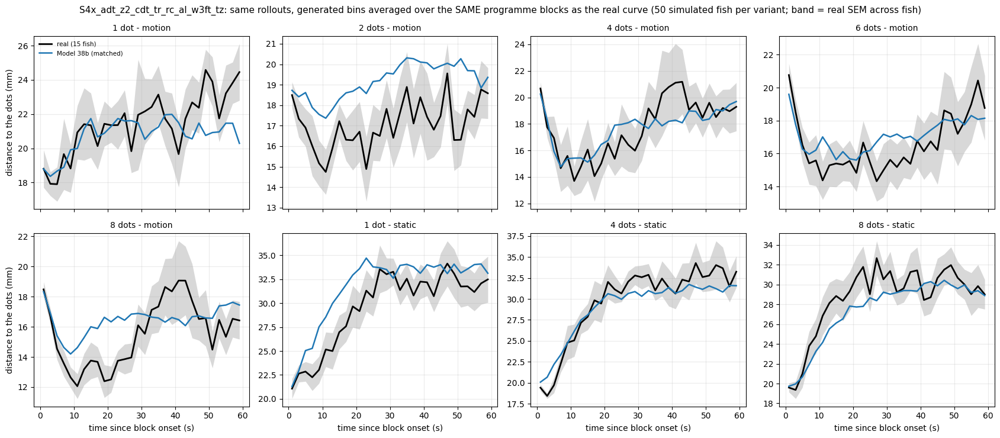

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_38b, _ = profile_variants_matched("report_ckpts/M38b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz", {"Model 38b": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_38b, _ = attraction_table("report_ckpts/M38b", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_tz"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_tz                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           21.68  22.95       1.27
d2s3.5       17.39  23.58       6.19                           19.87  22.68       2.82
d4s3.5       18.74  23.93       5.19                           19.04  23.02       3.97
d6s3.5       16.69  23.12       6.43                           17.86  23.09       5.23
d8s3.5       16.41  23.36       6.94                           16.85  22.73       5.88


In [ ]:
# Model 38b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_38b = toward_by_n("report_ckpts/M38b", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_tz"], rej=REJ["wall_reject"])
print(tow_38b.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_tz
win    N                                        
0-20 s 1   9.09                            10.25
       2  13.90                            12.45
       4  15.73                            14.45
       6  14.50                            15.30
       8  16.00                            17.43
4-20 s 1   6.25                             9.30
       2  12.27                            12.00
       4  14.35                            13.49
       6  12.79                            14.28
       8  15.11                            16.24


Model 38b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 38b   real gap Model 38b    real gap Model 38b
cond                                                                  
d1s3.5  25.08         -9.94   6.64          4.21    7.55          2.80
d2s3.5  22.99         -4.97  12.94         -0.71   12.56         -0.57
d4s3.5  27.14         -6.67  15.54         -1.58   12.09          1.32
d6s3.5  32.55        -11.25  13.80          1.84   15.84         -0.83
d8s3.5  34.04         -9.99  14.45          3.02   13.80          2.15
d1s0     6.82         -5.94   4.22         -3.65    1.96         -0.84
d4s0     4.81         -1.62   1.86          0.92    1.74          2.74
d8s0     5.26         -0.93   2.63          1.61    2.39          3.35

turn size |Δθ| (deg): real f

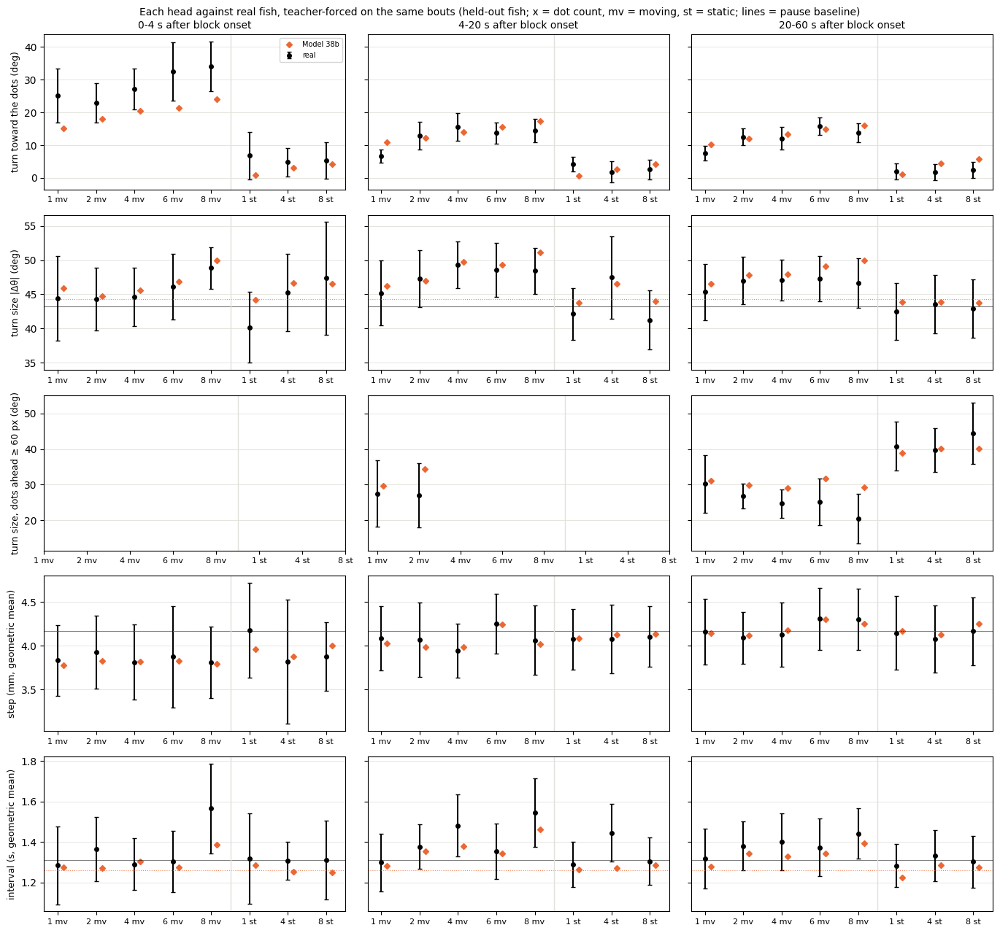

In [ ]:
# Model 38b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_38b, hg_38b = head_gaps({"Model 38b": ("report_ckpts/M38b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_tz")}, rej=REJ["wall_reject"])

<a id="m38c"></a>
### D4 (Model 17), turn-size latent

**Change:** Model 17 + turn-size loading



#### D4 (Model 17), turn-size latent — seed 0 (key `38c`)

In [ ]:
# Model 38c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M38c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_38c = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_38c.index = ["turn", "displacement", "interval", "joint"]
print(lik_38c.round(3).to_string())

turn             7.626
displacement     4.535
interval         1.216
joint           13.377


In [ ]:
# Model 38c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_38c, c2st_38c = run(ckpt_dir="report_ckpts/M38c", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv  (15 rows) in 448s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_rej
abs_dtheta_w1                                               10.4036
symbol_js                                                    0.0171
dt_w1                                                        0.4282
dist_w1                                                      4.4160
trans_js                                    

In [ ]:
# Model 38c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M38c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_38c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_38c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.717            0.021      0.641         0.027
matched to the real runs (same bouts, 1:1)            0.711            0.022      0.634         0.030



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.495         0.088        0.047          0.536         0.833
                      median           0.449       0.505         0.098        0.054          0.552         0.841
                      SD               0.159       0.177         0.015        0.011          0.693         0.924
                      q90              0.679       0.739         0.074        0.051

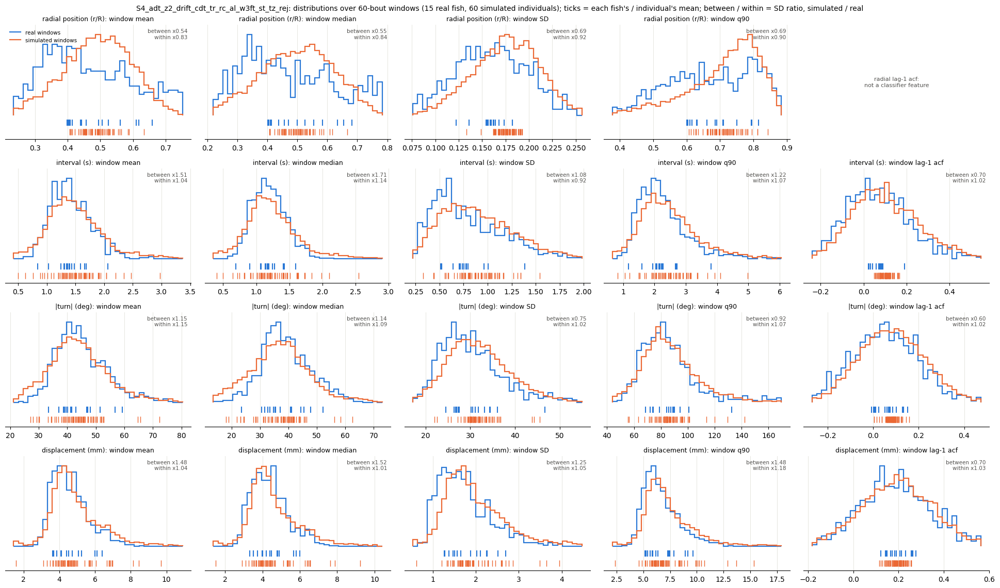

In [ ]:
# Model 38c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_38c = window_stats_grid("report_ckpts/M38c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    0.98     0.66  0.15  0.17   3.0   5.0                  22.3 +/- 0.9  22.2 +/- 1.2
d2s3.5    1.70     1.30  2.64  2.57  11.0  11.0                  17.4 +/- 0.9  19.2 +/- 1.6
d4s3.5    1.34     0.81  4.68  4.19  19.0   9.0                  1

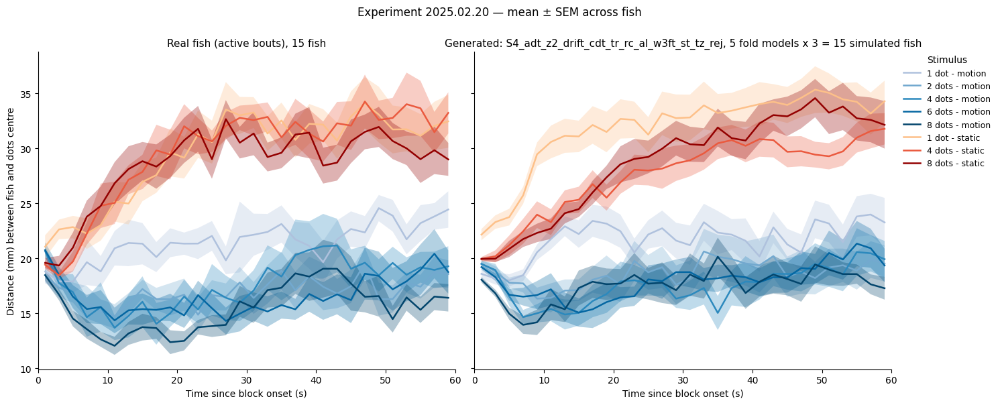

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M38c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

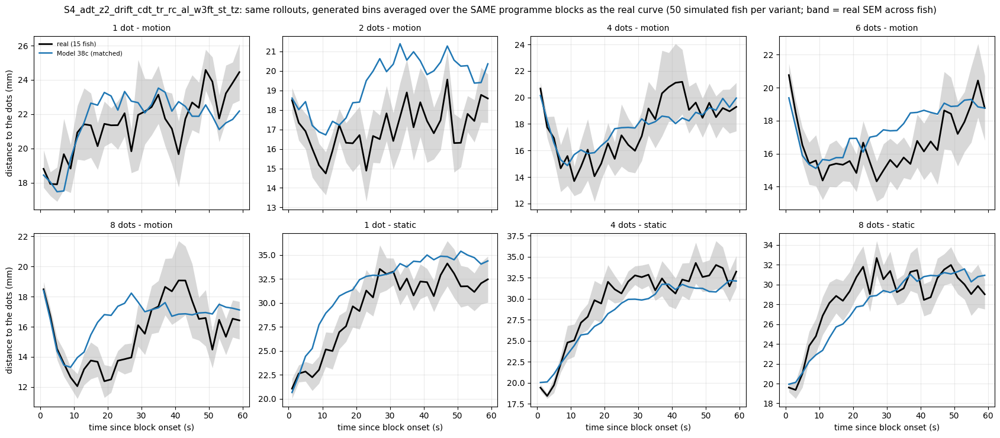

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_38c, _ = profile_variants_matched("report_ckpts/M38c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", {"Model 38c": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_38c, _ = attraction_table("report_ckpts/M38c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   22.97  23.28       0.31
d2s3.5       17.39  23.58       6.19                                   20.56  23.32       2.76
d4s3.5       18.74  23.93       5.19                                   19.51  23.39       3.88
d6s3.5       16.69  23.12       6.43                                   19.25  23.51       4.26
d8s3.5       16.41  23.36       6.94                                   18.61  23.49       4.88


In [ ]:
# Model 38c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_38c = toward_by_n("report_ckpts/M38c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz"], rej=REJ["wall_reject"])
print(tow_38c.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz
win    N                                                
0-20 s 1   9.09                                     9.12
       2  13.90                                    11.31
       4  15.73                                    12.77
       6  14.50                                    13.66
       8  16.00                                    15.68
4-20 s 1   6.25                                     7.70
       2  12.27                                    10.24
       4  14.35                                    11.17
       6  12.79                                    12.07
       8  15.11                                    13.61


Model 38c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 38c   real gap Model 38c    real gap Model 38c
cond                                                                  
d1s3.5  25.08         -8.77   6.64          3.27    7.55          1.48
d2s3.5  22.99         -4.45  12.94         -2.04   12.56         -2.24
d4s3.5  27.14         -6.84  15.54         -3.71   12.09         -0.80
d6s3.5  32.55        -10.21  13.80         -0.02   15.84         -3.02
d8s3.5  34.04         -9.06  14.45          0.70   13.80         -0.05
d1s0     6.82         -7.16   4.22         -3.21    1.96         -0.47
d4s0     4.81         -2.02   1.86          0.41    1.74          1.60
d8s0     5.26         -1.43   2.63          0.54    2.39          2.07

turn size |Δθ| (deg): real f

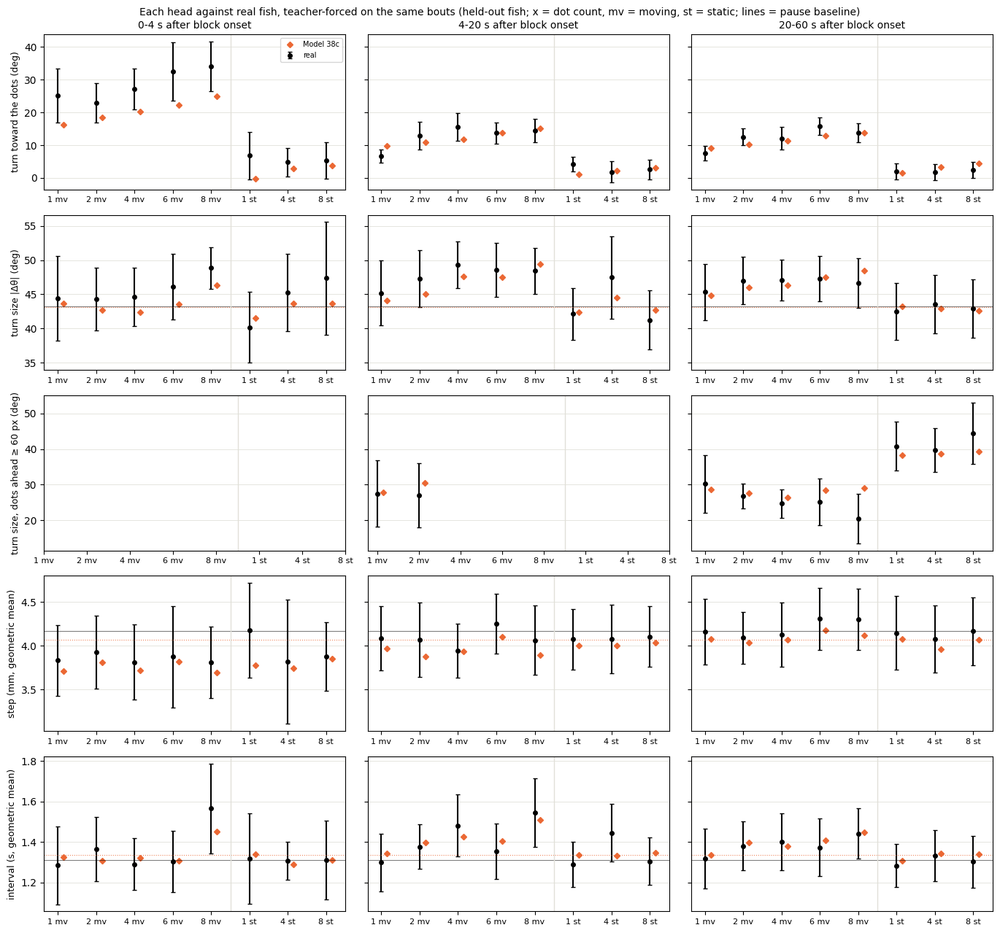

In [ ]:
# Model 38c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_38c, hg_38c = head_gaps({"Model 38c": ("report_ckpts/M38c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz")}, rej=REJ["wall_reject"])

#### D4 (Model 17), turn-size latent — seed 101 (key `38d`)

In [ ]:
# Model 38d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M38d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_38d = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_38d.index = ["turn", "displacement", "interval", "joint"]
print(lik_38d.round(3).to_string())

turn             7.641
displacement     4.524
interval         1.201
joint           13.366


In [ ]:
# Model 38d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_38d, c2st_38d = run(ckpt_dir="report_ckpts/M38d", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz.csv  (15 rows) in 409s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_rej
abs_dtheta_w1                                                8.1784
symbol_js                                                    0.0127
dt_w1                                                        0.3819
dist_w1                                                      3.9373
trans_js                                    

In [ ]:
# Model 38d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M38d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_38d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_38d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.651            0.014      0.550         0.013
matched to the real runs (same bouts, 1:1)            0.637            0.016      0.543         0.014



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.487         0.088        0.038          0.432         0.836
                      median           0.449       0.492         0.098        0.044          0.445         0.849
                      SD               0.159       0.179         0.015        0.009          0.556         0.923
                      q90              0.679       0.732         0.074        0.040

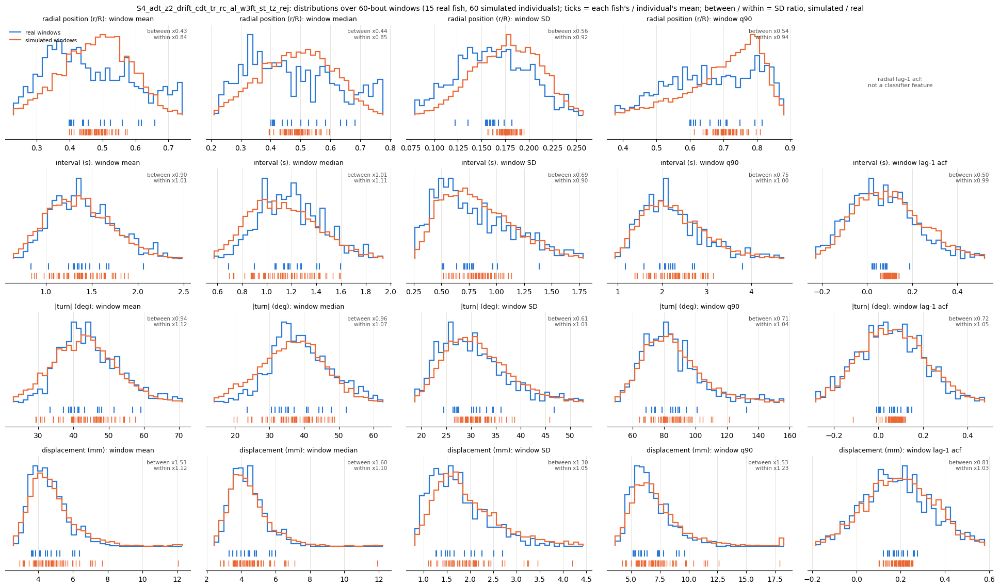

In [ ]:
# Model 38d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_38d = window_stats_grid("report_ckpts/M38d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_fold4.pt: 3 rollouts
dropped 12.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.82     1.22  0.15  0.06   3.0   3.0                  22.3 +/- 0.9  19.9 +/- 0.7
d2s3.5    2.14     1.71  2.64  1.64  11.0   9.0                  17.4 +/- 0.9  19.5 +/- 1.0
d4s3.5    1.62     0.95  4.68  5.05  19.0   9.0                  1

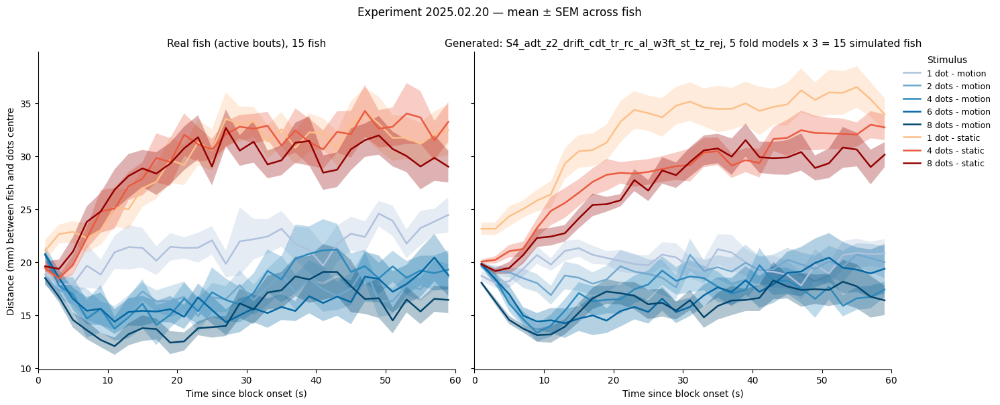

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M38d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

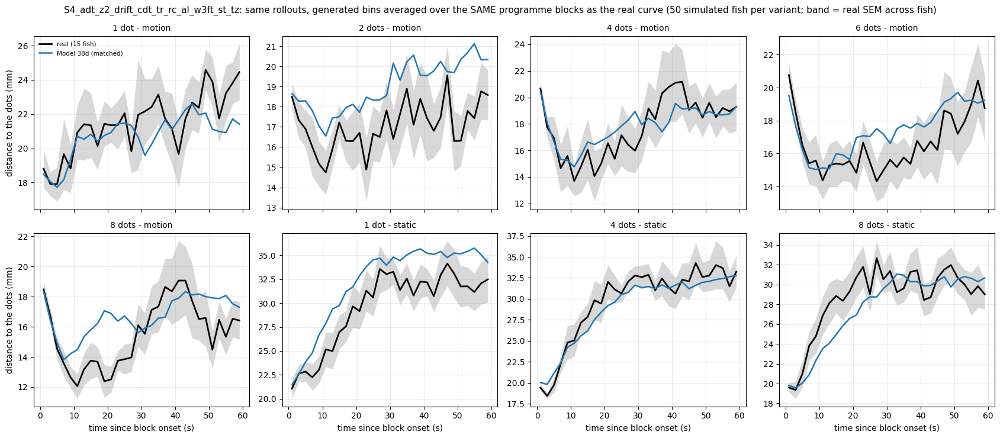

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_38d, _ = profile_variants_matched("report_ckpts/M38d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz", {"Model 38d": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_38d, _ = attraction_table("report_ckpts/M38d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   20.56  22.76       2.20
d2s3.5       17.39  23.58       6.19                                   18.96  22.82       3.85
d4s3.5       18.74  23.93       5.19                                   18.91  22.83       3.91
d6s3.5       16.69  23.12       6.43                                   18.46  22.65       4.19
d8s3.5       16.41  23.36       6.94                                   17.63  22.96       5.34


In [ ]:
# Model 38d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_38d = toward_by_n("report_ckpts/M38d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz"], rej=REJ["wall_reject"])
print(tow_38d.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz
win    N                                                
0-20 s 1   9.09                                    10.22
       2  13.90                                    12.22
       4  15.73                                    13.18
       6  14.50                                    14.41
       8  16.00                                    17.00
4-20 s 1   6.25                                     8.88
       2  12.27                                    11.13
       4  14.35                                    11.54
       6  12.79                                    12.81
       8  15.11                                    14.91


Model 38d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 38d   real gap Model 38d    real gap Model 38d
cond                                                                  
d1s3.5  25.08         -8.41   6.64          4.19    7.55          2.32
d2s3.5  22.99         -3.80  12.94         -0.77   12.56         -1.75
d4s3.5  27.14         -5.40  15.54         -3.74   12.09         -0.27
d6s3.5  32.55        -10.77  13.80          1.08   15.84         -2.29
d8s3.5  34.04         -7.51  14.45          2.02   13.80          0.69
d1s0     6.82         -5.61   4.22         -2.88    1.96          0.14
d4s0     4.81         -1.45   1.86          0.73    1.74          2.21
d8s0     5.26         -0.59   2.63          0.66    2.39          2.17

turn size |Δθ| (deg): real f

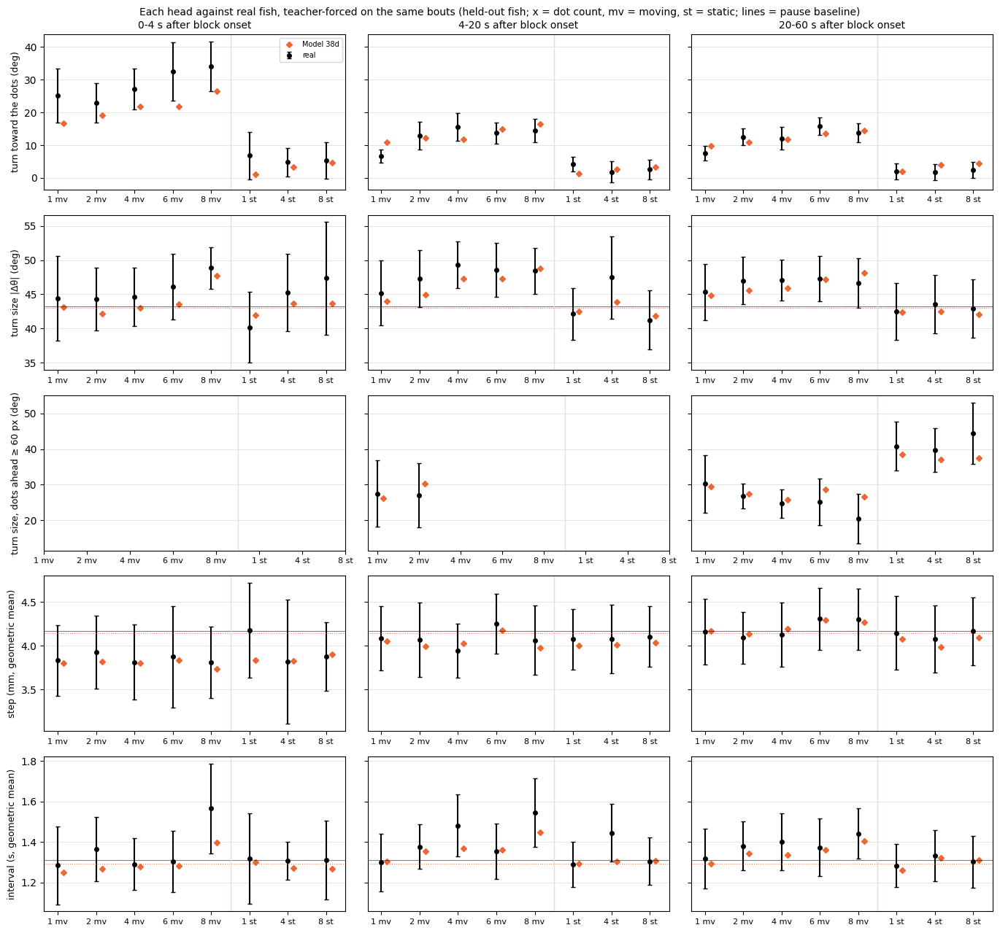

In [ ]:
# Model 38d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_38d, hg_38d = head_gaps({"Model 38d": ("report_ckpts/M38d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz")}, rej=REJ["wall_reject"])

<a id="m38e"></a>
### F (14f), turn-size latent

**Change:** the turn-size D4 + profile correction



#### F (14f), turn-size latent — seed 0 (key `38e`)

In [ ]:
# Model 38e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M38e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_38e = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_38e.index = ["turn", "displacement", "interval", "joint"]
print(lik_38e.round(3).to_string())

turn             7.626
displacement     4.535
interval         1.216
joint           13.377


In [ ]:
# Model 38e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_38e, c2st_38e = run(ckpt_dir="report_ckpts/M38e", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv  (15 rows) in 1161s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_rej
abs_dtheta_w1                                                           10.4278
symbol_js                                                                0.0168
dt_w1                                                                    0.4281
dist_w1        

In [ ]:
# Model 38e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M38e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_38e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_38e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.721             0.02      0.649         0.029
matched to the real runs (same bouts, 1:1)            0.706             0.02      0.636         0.029



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.497         0.088        0.049          0.555         0.839
                      median           0.449       0.503         0.098        0.056          0.572         0.848
                      SD               0.159       0.178         0.015        0.010          0.622         0.925
                      q90              0.679       0.739         0.074        0.051

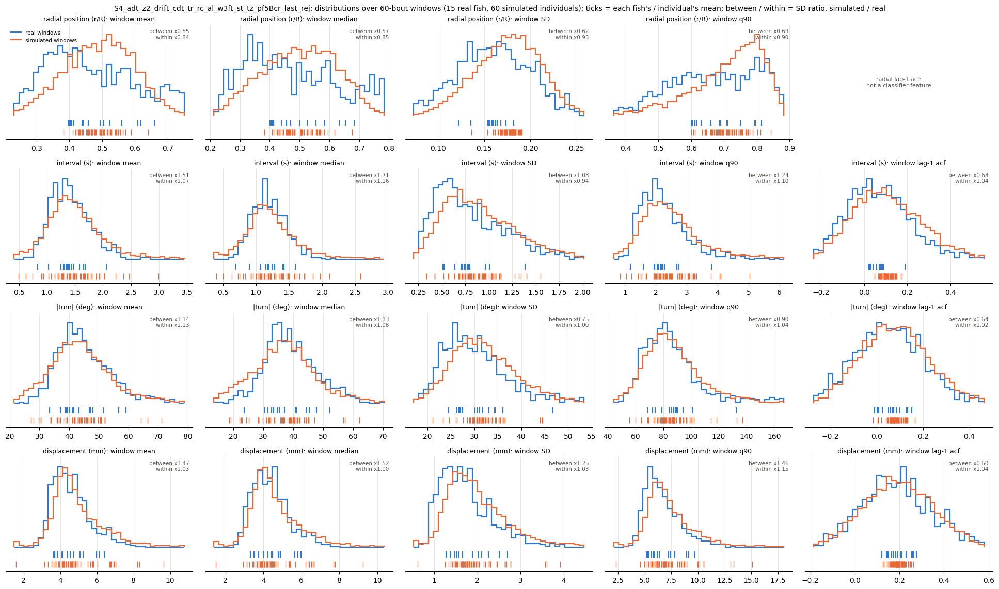

In [ ]:
# Model 38e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_38e = window_stats_grid("report_ckpts/M38e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 12.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.28     0.85  0.15  0.08   3.0   3.0                  22.3 +/- 0.9  22.8 +/- 1.1
d2s3.5    1.70     1.36  2.64  3.54  11.0  11.0                  17.4 +/- 0.9  18.7 +/- 1.2
d4s3.5

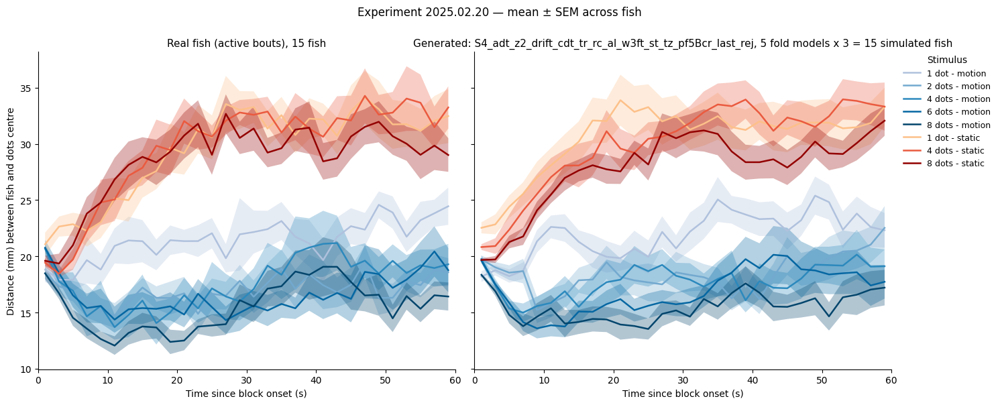

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M38e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

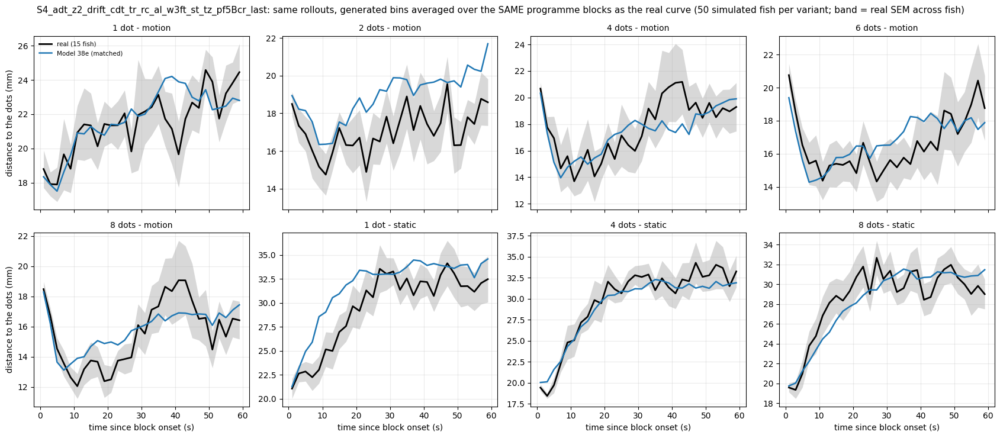

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_38e, _ = profile_variants_matched("report_ckpts/M38e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", {"Model 38e": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_38e, _ = attraction_table("report_ckpts/M38e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               24.40  23.86      -0.54
d2s3.5       17.39  23.58       6.19                                               19.92  23.59       3.68
d4s3.5       18.74  23.93       5.19                                               18.92  23.62       4.70
d6s3.5       16.69  23.12       6.43                                               18.74  23.76       5.01
d8s3.5       16.41  23.36       6.94           

In [ ]:
# Model 38e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_38e = toward_by_n("report_ckpts/M38e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_38e.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last
win    N                                                            
0-20 s 1   9.09                                                 9.12
       2  13.90                                                12.89
       4  15.73                                                14.55
       6  14.50                                                16.00
       8  16.00                                                17.73
4-20 s 1   6.25                                                 7.70
       2  12.27                                                11.91
       4  14.35                                                13.03
       6  12.79                                                14.53
       8  15.11                                                15.60


Model 38e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 38e   real gap Model 38e    real gap Model 38e
cond                                                                  
d1s3.5  25.08         -8.77   6.64          3.27    7.55          1.48
d2s3.5  22.99         -2.96  12.94         -0.56   12.56         -2.01
d4s3.5  27.14         -5.07  15.54         -2.01   12.09         -0.59
d6s3.5  32.55         -8.31  13.80          2.14   15.84         -2.78
d8s3.5  34.04         -7.34  14.45          2.62   13.80          0.23
d1s0     6.82         -7.16   4.22         -3.21    1.96         -0.47
d4s0     4.81         -2.02   1.86          0.41    1.74          1.60
d8s0     5.26         -1.43   2.63          0.54    2.39          2.07

turn size |Δθ| (deg): real f

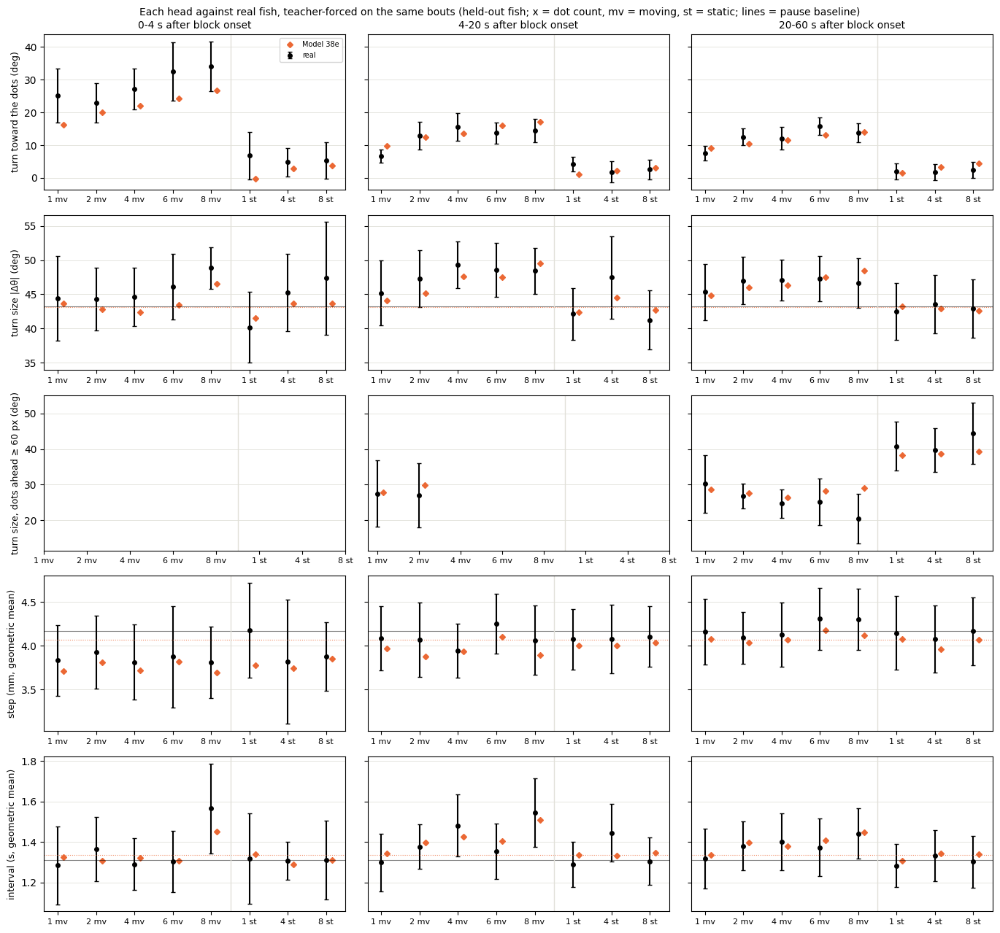

In [ ]:
# Model 38e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_38e, hg_38e = head_gaps({"Model 38e": ("report_ckpts/M38e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last")}, rej=REJ["wall_reject"])

#### F (14f), turn-size latent — seed 101 (key `38f`)

In [ ]:
# Model 38f: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M38f/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_38f = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_38f.index = ["turn", "displacement", "interval", "joint"]
print(lik_38f.round(3).to_string())

turn             7.641
displacement     4.524
interval         1.201
joint           13.366


In [ ]:
# Model 38f: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_38f, c2st_38f = run(ckpt_dir="report_ckpts/M38f", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last.csv  (15 rows) in 1126s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_rej
abs_dtheta_w1                                                            8.2421
symbol_js                                                                0.0129
dt_w1                                                                    0.3828
dist_w1        

In [ ]:
# Model 38f: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M38f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_38f = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_38f.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.660            0.013      0.562         0.015
matched to the real runs (same bouts, 1:1)            0.645            0.015      0.544         0.017



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.487         0.088        0.038          0.429         0.842
                      median           0.449       0.491         0.098        0.043          0.439         0.853
                      SD               0.159       0.179         0.015        0.010          0.635         0.913
                      q90              0.679       0.732         0.074        0.042

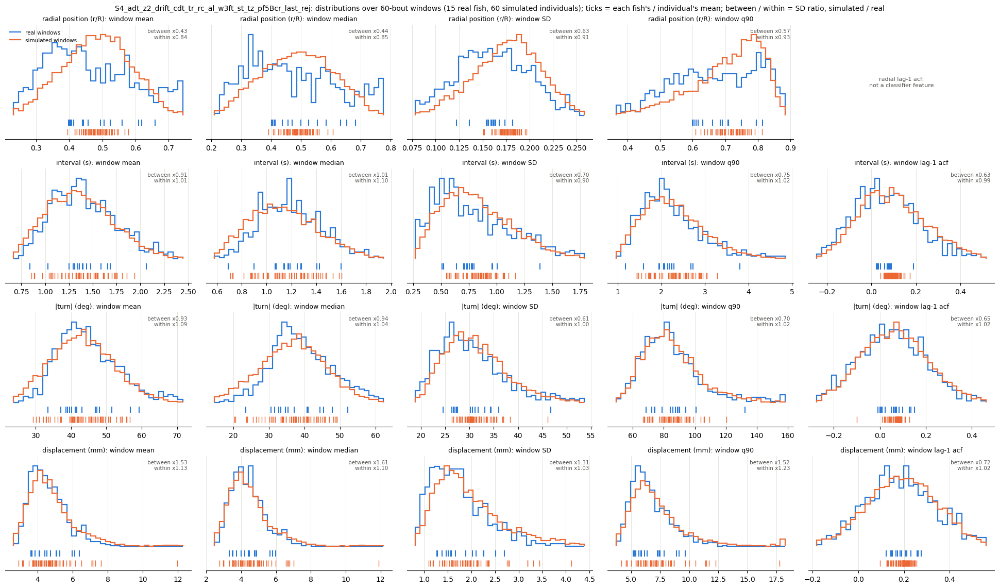

In [ ]:
# Model 38f: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_38f = window_stats_grid("report_ckpts/M38f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.51     1.00  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  21.3 +/- 0.9
d2s3.5    1.43     1.14  2.64  4.46  11.0  11.0                  17.4 +/- 0.9  18.3 +/- 0.7
d4s3.5

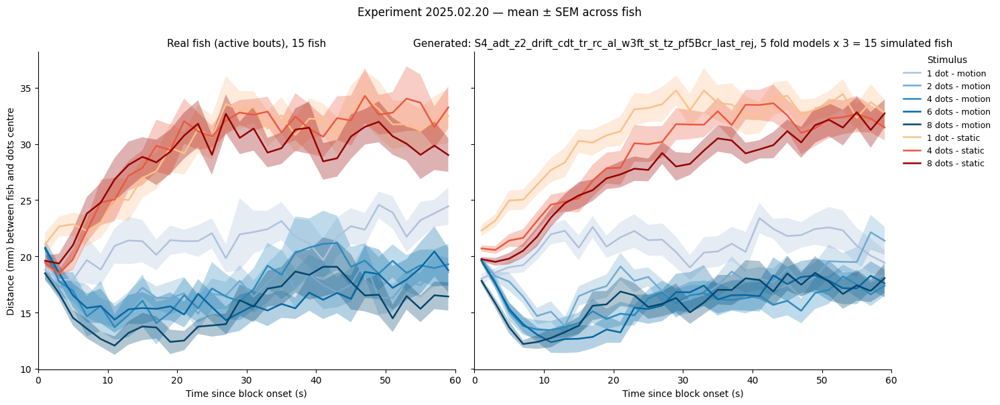

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38f: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M38f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

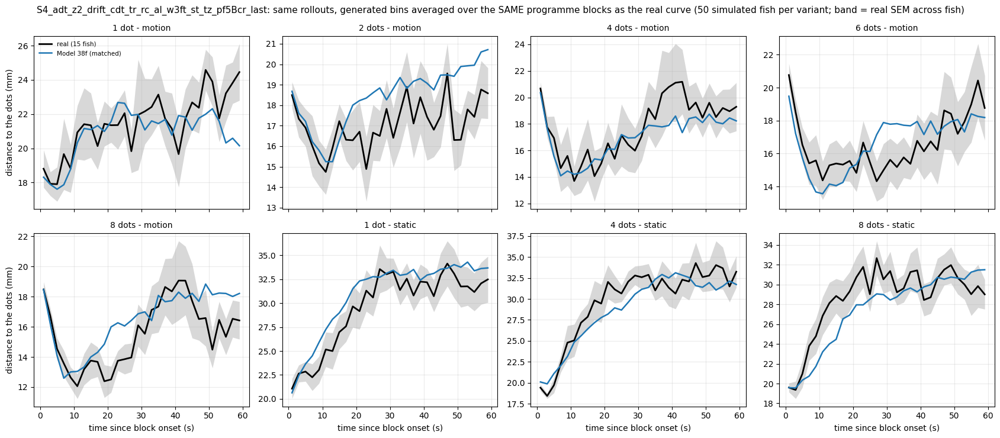

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38f: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_38f, _ = profile_variants_matched("report_ckpts/M38f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last", {"Model 38f": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 38f: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_38f, _ = attraction_table("report_ckpts/M38f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last                  
           plateau   null attraction                                             plateau   null attraction
cond_label                                                                                                
d1s3.5       22.41  23.57       1.16                                               21.32  22.65       1.33
d2s3.5       17.39  23.58       6.19                                               19.07  22.75       3.68
d4s3.5       18.74  23.93       5.19                                               17.77  22.66       4.89
d6s3.5       16.69  23.12       6.43                                               17.54  22.58       5.03
d8s3.5       16.41  23.36       6.94           

In [ ]:
# Model 38f: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_38f = toward_by_n("report_ckpts/M38f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_38f.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last
win    N                                                            
0-20 s 1   9.09                                                10.22
       2  13.90                                                14.05
       4  15.73                                                15.82
       6  14.50                                                17.16
       8  16.00                                                20.25
4-20 s 1   6.25                                                 8.88
       2  12.27                                                13.11
       4  14.35                                                14.43
       6  12.79                                                15.77
       8  15.11                                                18.41


Model 38f: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 38f   real gap Model 38f    real gap Model 38f
cond                                                                  
d1s3.5  25.08         -8.41   6.64          4.19    7.55          2.32
d2s3.5  22.99         -2.20  12.94          1.07   12.56         -1.52
d4s3.5  27.14         -3.45  15.54         -1.00   12.09          0.00
d6s3.5  32.55         -8.73  13.80          3.88   15.84         -1.96
d8s3.5  34.04         -5.62  14.45          5.43   13.80          1.10
d1s0     6.82         -5.61   4.22         -2.88    1.96          0.14
d4s0     4.81         -1.45   1.86          0.73    1.74          2.21
d8s0     5.26         -0.59   2.63          0.66    2.39          2.17

turn size |Δθ| (deg): real f

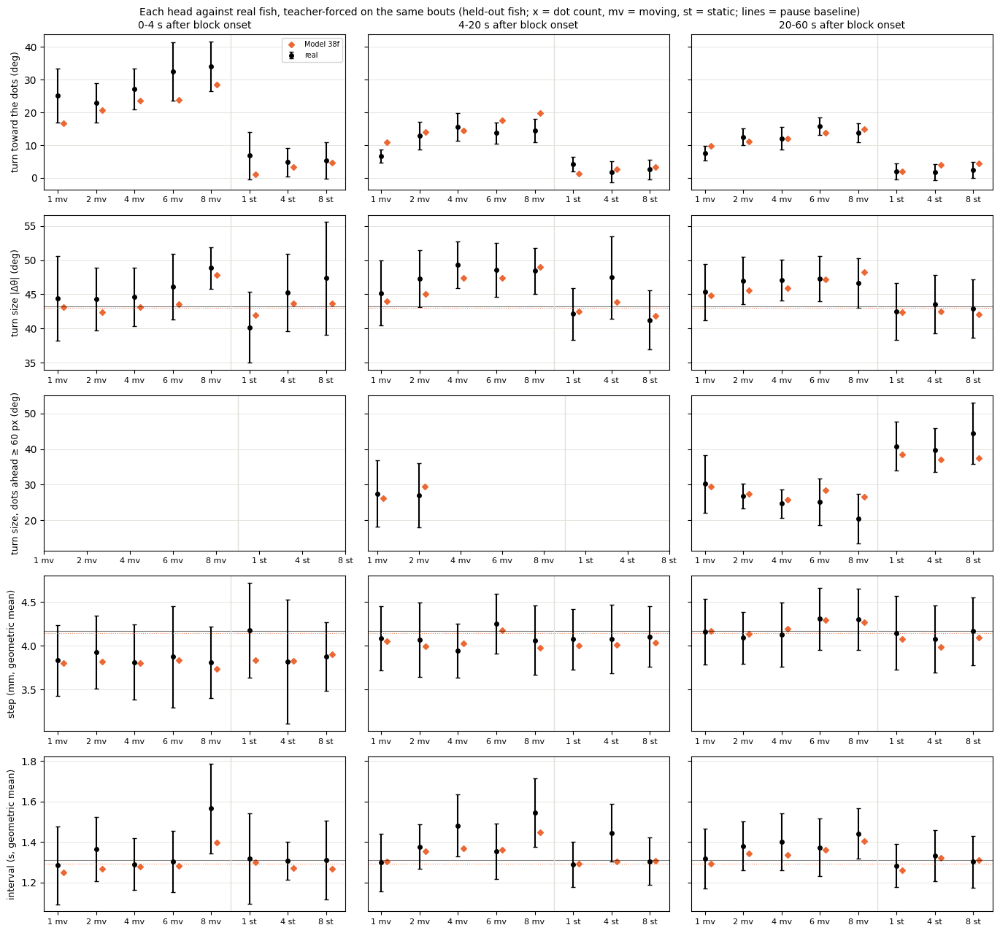

In [ ]:
# Model 38f: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_38f, hg_38f = head_gaps({"Model 38f": ("report_ckpts/M38f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_tz_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="tsz200"></a>
## 7. Turn-size latent with tau = 200 — both changes together

D4 and F
retrained with both changes of sections 5 and 6 at once: the slow state's time constant at 200 bouts and the per-fish
latent also on the scales of the four turning components; everything else unchanged (same recipe, folds and seeds;
F = this D4 + the same profile correction). Compared with Model 17 / 14f (neither change), with the tau-200 units
(37a-d) and with the turn-size units (38c-f) at the same seed.

<a id="m46a"></a>
### D4 (Model 17), turn-size latent + tau = 200

**Change:** Model 17 + turn-size loading + tau = 200



#### D4 (Model 17), turn-size latent + tau = 200 — seed 0 (key `46a`)

In [ ]:
# Model 46a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M46a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_46a = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_46a.index = ["turn", "displacement", "interval", "joint"]
print(lik_46a.round(3).to_string())

turn             7.623
displacement     4.510
interval         1.208
joint           13.340


In [ ]:
# Model 46a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_46a, c2st_46a = run(ckpt_dir="report_ckpts/M46a", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv  (15 rows) in 1207s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_rej
abs_dtheta_w1                                                     9.6770
symbol_js                                                         0.0147
dt_w1                                                             0.3943
dist_w1                                                           3.931

In [ ]:
# Model 46a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M46a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_46a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_46a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.693            0.022      0.627          0.02
matched to the real runs (same bouts, 1:1)            0.685            0.023      0.609          0.02



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.494         0.088        0.043          0.490         0.817
                      median           0.449       0.502         0.098        0.049          0.502         0.833
                      SD               0.159       0.178         0.015        0.010          0.648         0.899
                      q90              0.679       0.736         0.074        0.048

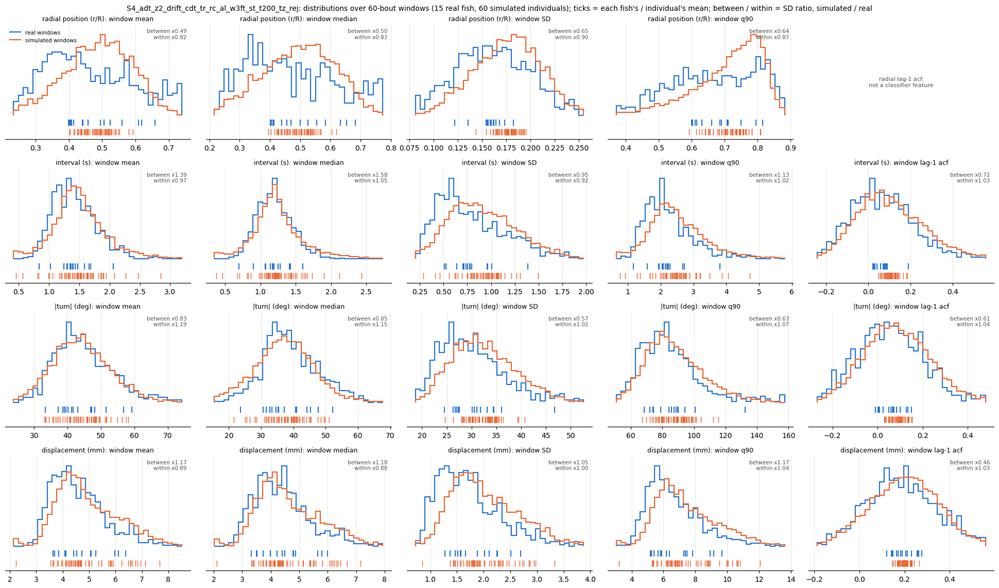

In [ ]:
# Model 46a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_46a = window_stats_grid("report_ckpts/M46a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold4.pt: 3 rollouts
dropped 11.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.55     1.06  0.15  0.73   3.0   5.0                  22.3 +/- 0.9  21.3 +/- 1.0
d2s3.5    2.71     2.11  2.64  3.47  11.0  11.0                  17.4 +/- 0.9  20.5 +/- 1.2
d4s3.5    1.84     1.15  4.68  3.55  19.0

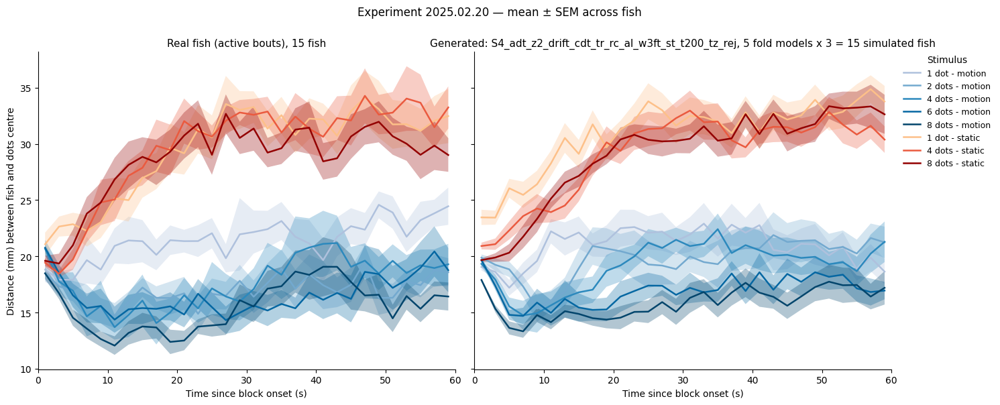

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M46a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

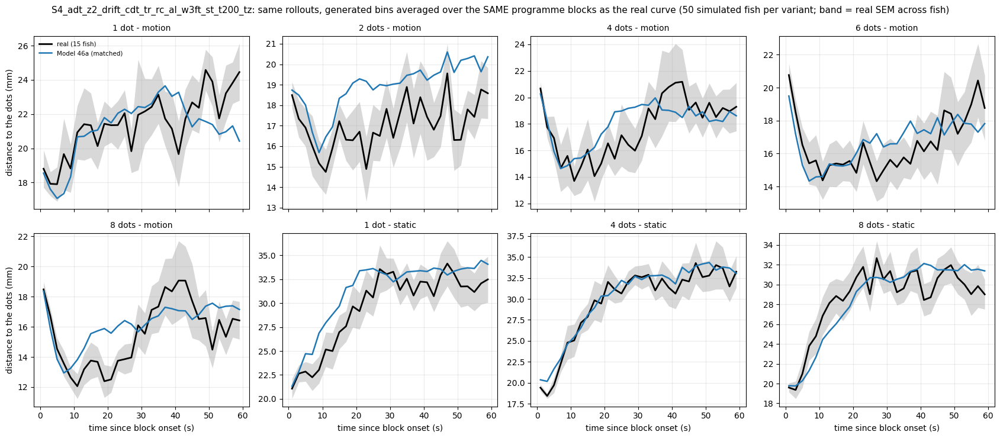

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_46a, _ = profile_variants_matched("report_ckpts/M46a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", {"Model 46a": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_46a, _ = attraction_table("report_ckpts/M46a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz                  
           plateau   null attraction                                      plateau   null attraction
cond_label                                                                                         
d1s3.5       22.41  23.57       1.16                                        22.91  23.49       0.58
d2s3.5       17.39  23.58       6.19                                        20.94  23.43       2.49
d4s3.5       18.74  23.93       5.19                                        20.07  23.45       3.38
d6s3.5       16.69  23.12       6.43                                        17.80  23.29       5.48
d8s3.5       16.41  23.36       6.94                                        17.75  23.66       5

In [ ]:
# Model 46a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_46a = toward_by_n("report_ckpts/M46a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz"], rej=REJ["wall_reject"])
print(tow_46a.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz
win    N                                                     
0-20 s 1   9.09                                          9.63
       2  13.90                                         12.08
       4  15.73                                         13.33
       6  14.50                                         14.38
       8  16.00                                         16.52
4-20 s 1   6.25                                          7.98
       2  12.27                                         10.70
       4  14.35                                         11.50
       6  12.79                                         12.59
       8  15.11                                         14.26


Model 46a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 46a   real gap Model 46a    real gap Model 46a
cond                                                                  
d1s3.5  25.08         -7.24   6.64          3.76    7.55          2.07
d2s3.5  22.99         -2.12  12.94         -1.34   12.56         -1.68
d4s3.5  27.14         -5.21  15.54         -3.23   12.09          0.23
d6s3.5  32.55         -9.52  13.80          0.75   15.84         -2.23
d8s3.5  34.04         -7.99  14.45          1.36   13.80          0.78
d1s0     6.82         -5.63   4.22         -3.26    1.96         -0.48
d4s0     4.81         -1.61   1.86          0.74    1.74          2.00
d8s0     5.26         -1.13   2.63          0.66    2.39          2.35

turn size |Δθ| (deg): real f

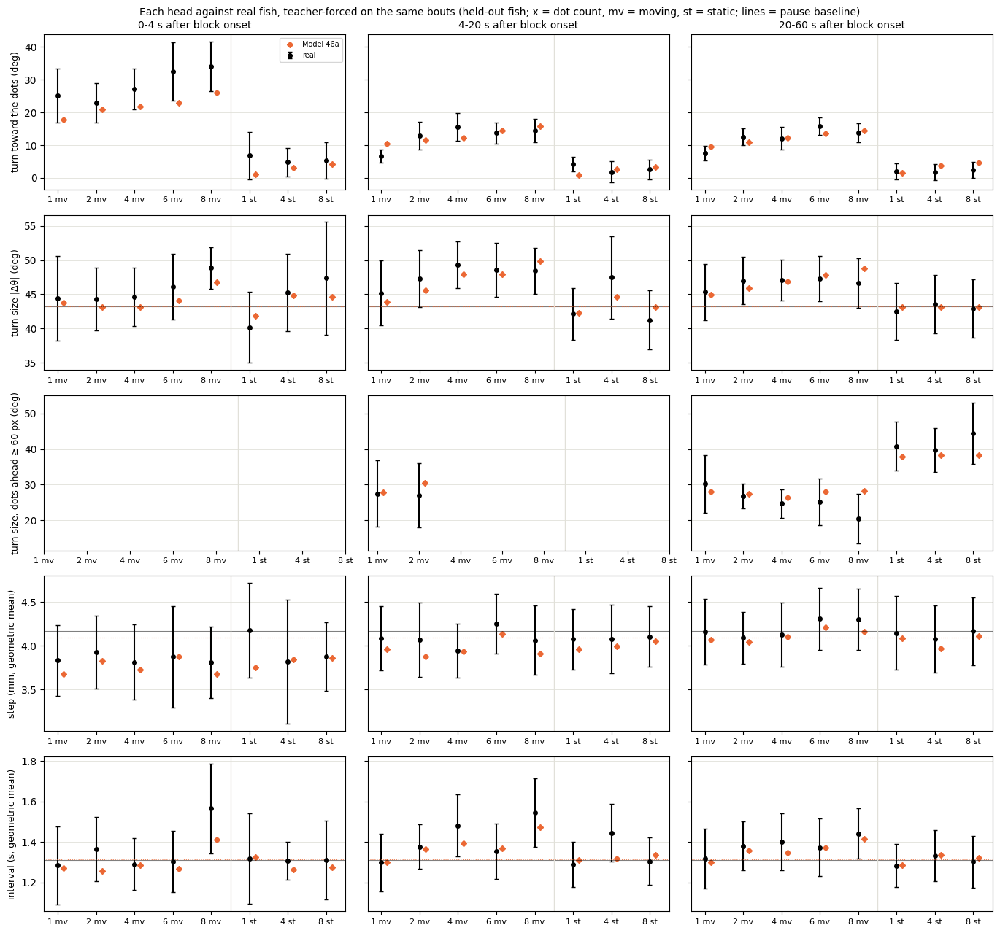

In [ ]:
# Model 46a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_46a, hg_46a = head_gaps({"Model 46a": ("report_ckpts/M46a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz")}, rej=REJ["wall_reject"])

#### D4 (Model 17), turn-size latent + tau = 200 — seed 101 (key `46b`)

In [ ]:
# Model 46b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M46b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_46b = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_46b.index = ["turn", "displacement", "interval", "joint"]
print(lik_46b.round(3).to_string())

turn             7.645
displacement     4.514
interval         1.202
joint           13.362


In [ ]:
# Model 46b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_46b, c2st_46b = run(ckpt_dir="report_ckpts/M46b", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz.csv  (15 rows) in 1174s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_rej
abs_dtheta_w1                                                     8.0720
symbol_js                                                         0.0117
dt_w1                                                             0.3723
dist_w1                                                           3.809

In [ ]:
# Model 46b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M46b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_46b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_46b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.602            0.026      0.506         0.026
matched to the real runs (same bouts, 1:1)            0.591            0.025      0.499         0.026



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.478         0.088        0.036          0.416         0.831
                      median           0.449       0.483         0.098        0.042          0.426         0.857
                      SD               0.159       0.181         0.015        0.009          0.560         0.909
                      q90              0.679       0.729         0.074        0.041

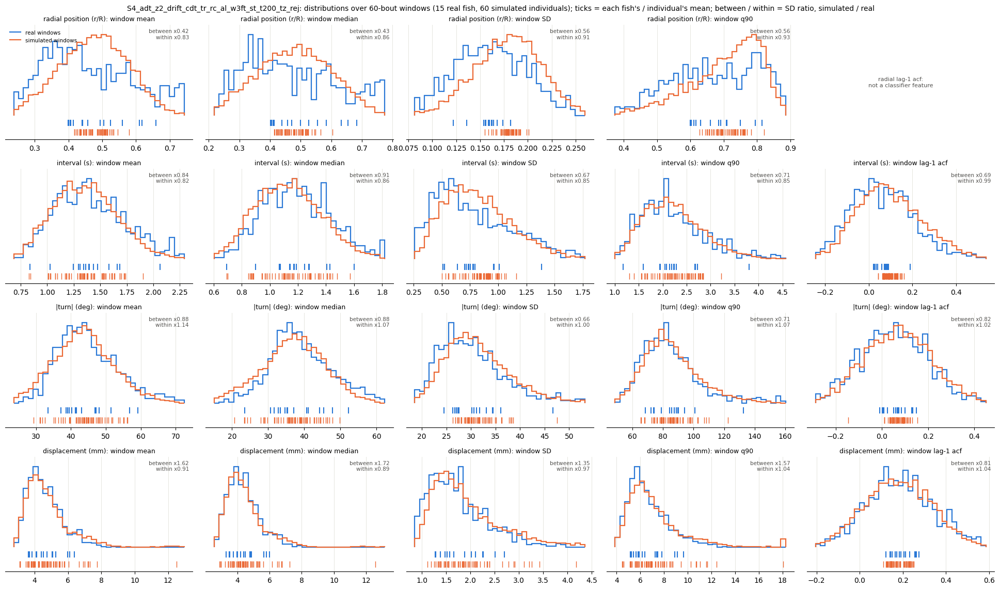

In [ ]:
# Model 46b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_46b = window_stats_grid("report_ckpts/M46b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_fold4.pt: 3 rollouts
dropped 12.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.52     1.04  0.15  0.82   3.0   7.0                  22.3 +/- 0.9  22.5 +/- 1.1
d2s3.5    1.43     1.18  2.64  2.98  11.0   9.0                  17.4 +/- 0.9  18.6 +/- 0.8
d4s3.5    1.11     0.71  4.68  3.88  19.0

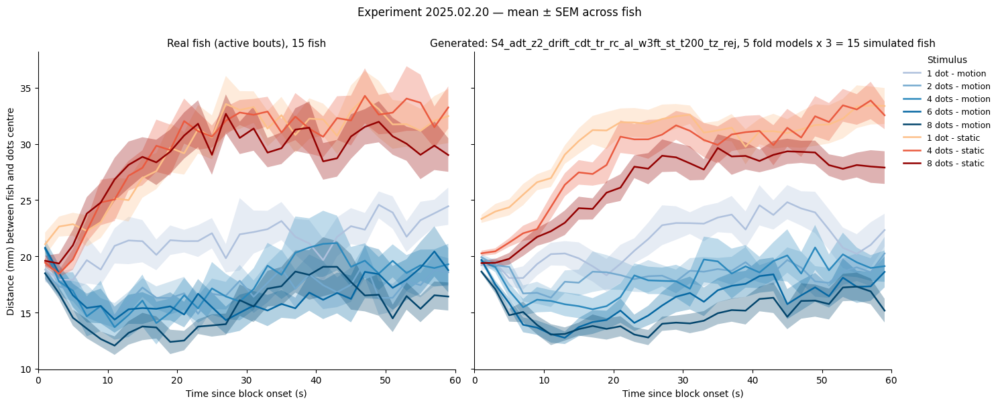

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M46b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

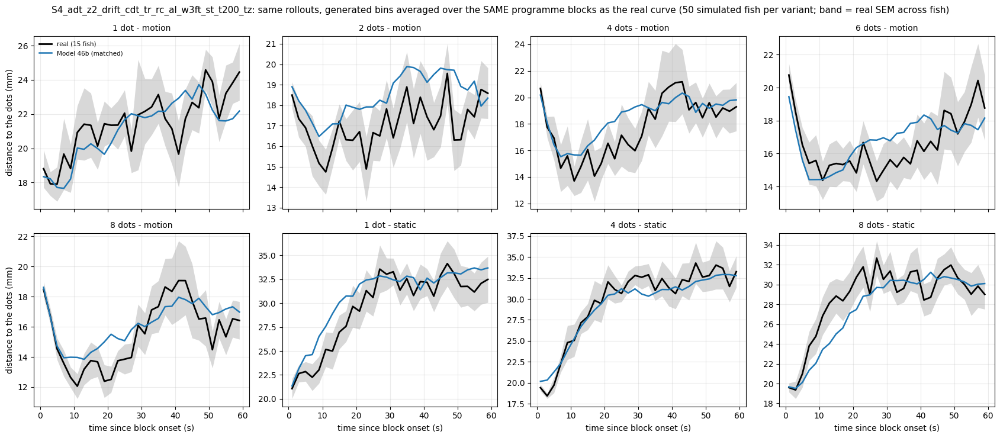

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_46b, _ = profile_variants_matched("report_ckpts/M46b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz", {"Model 46b": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_46b, _ = attraction_table("report_ckpts/M46b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz                  
           plateau   null attraction                                      plateau   null attraction
cond_label                                                                                         
d1s3.5       22.41  23.57       1.16                                        21.94  23.28       1.34
d2s3.5       17.39  23.58       6.19                                        18.77  22.63       3.86
d4s3.5       18.74  23.93       5.19                                        18.69  22.71       4.03
d6s3.5       16.69  23.12       6.43                                        17.60  22.60       5.00
d8s3.5       16.41  23.36       6.94                                        16.88  22.66       5

In [ ]:
# Model 46b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_46b = toward_by_n("report_ckpts/M46b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz"], rej=REJ["wall_reject"])
print(tow_46b.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz
win    N                                                     
0-20 s 1   9.09                                         10.13
       2  13.90                                         11.98
       4  15.73                                         13.04
       6  14.50                                         14.62
       8  16.00                                         16.71
4-20 s 1   6.25                                          8.93
       2  12.27                                         10.98
       4  14.35                                         11.50
       6  12.79                                         13.03
       8  15.11                                         14.75


Model 46b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 46b   real gap Model 46b    real gap Model 46b
cond                                                                  
d1s3.5  25.08         -8.65   6.64          4.11    7.55          2.45
d2s3.5  22.99         -4.55  12.94         -1.08   12.56         -1.84
d4s3.5  27.14         -5.61  15.54         -4.05   12.09         -0.42
d6s3.5  32.55        -11.06  13.80          1.14   15.84         -2.44
d8s3.5  34.04         -7.97  14.45          1.50   13.80          0.56
d1s0     6.82         -6.46   4.22         -3.41    1.96         -0.26
d4s0     4.81         -2.91   1.86          0.34    1.74          1.99
d8s0     5.26         -0.71   2.63          0.60    2.39          2.04

turn size |Δθ| (deg): real f

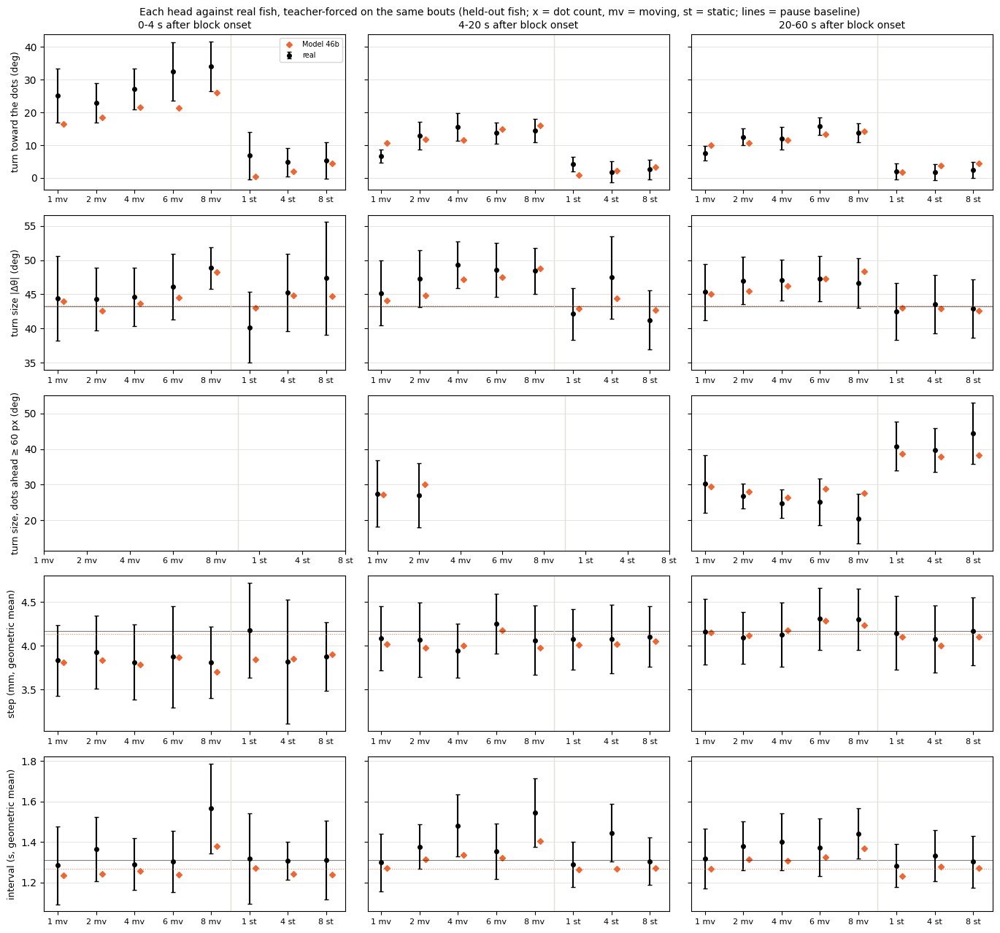

In [ ]:
# Model 46b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_46b, hg_46b = head_gaps({"Model 46b": ("report_ckpts/M46b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz")}, rej=REJ["wall_reject"])

<a id="m46c"></a>
### F (14f), turn-size latent + tau = 200

**Change:** the turn-size tau-200 D4 + profile correction



#### F (14f), turn-size latent + tau = 200 — seed 0 (key `46c`)

In [ ]:
# Model 46c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M46c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_46c = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_46c.index = ["turn", "displacement", "interval", "joint"]
print(lik_46c.round(3).to_string())

turn             7.624
displacement     4.510
interval         1.208
joint           13.341


In [ ]:
# Model 46c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_46c, c2st_46c = run(ckpt_dir="report_ckpts/M46c", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv  (15 rows) in 1184s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_rej
abs_dtheta_w1                                                                 9.5897
symbol_js                                                                     0.0144
dt_w1                                                       

In [ ]:
# Model 46c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M46c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_46c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_46c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.687            0.019      0.622         0.021
matched to the real runs (same bouts, 1:1)            0.682            0.023      0.609         0.023



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.493         0.088        0.043          0.487         0.823
                      median           0.449       0.501         0.098        0.049          0.500         0.843
                      SD               0.159       0.177         0.015        0.009          0.595         0.898
                      q90              0.679       0.737         0.074        0.045

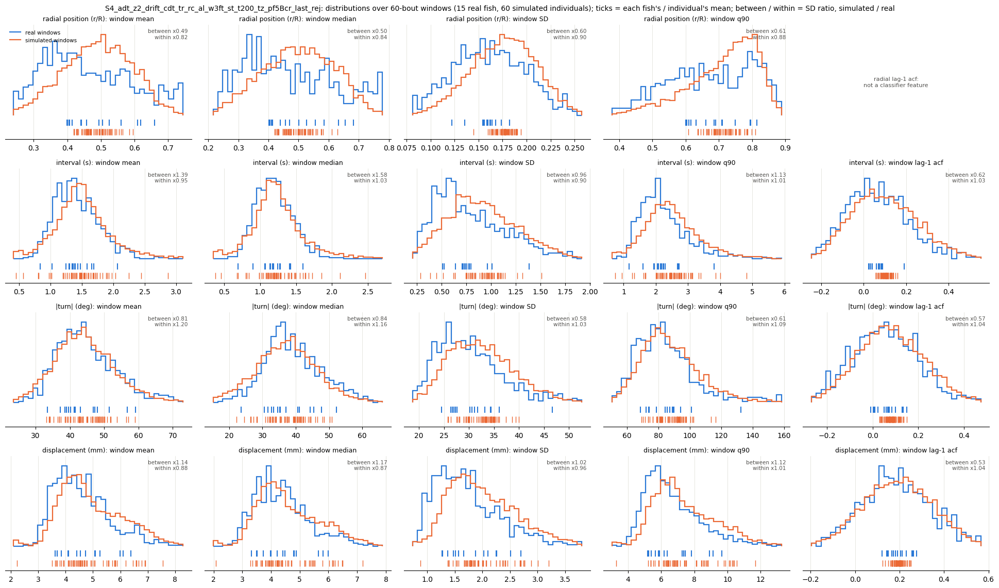

In [ ]:
# Model 46c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_46c = window_stats_grid("report_ckpts/M46c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.22     0.84  0.15  1.48   3.0   5.0                  22.3 +/- 0.9  21.7 +/- 1.2
d2s3.5    2.49     1.87  2.64  1.88  11.0   9.0                  17.4 +/-

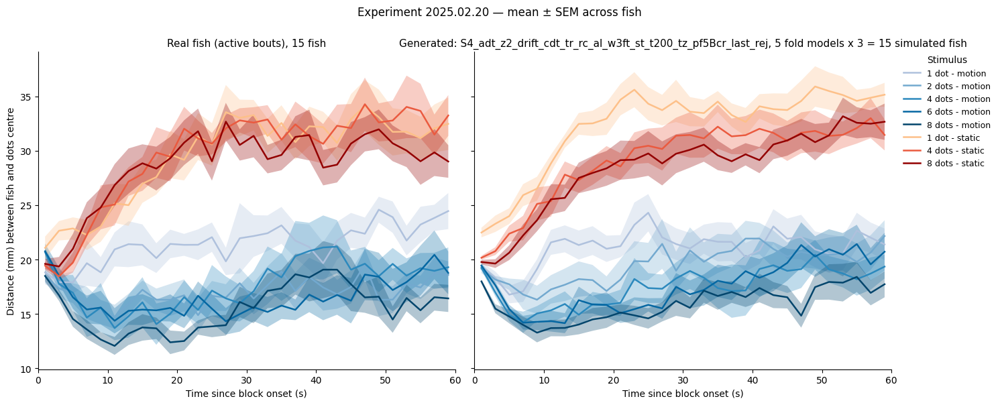

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M46c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

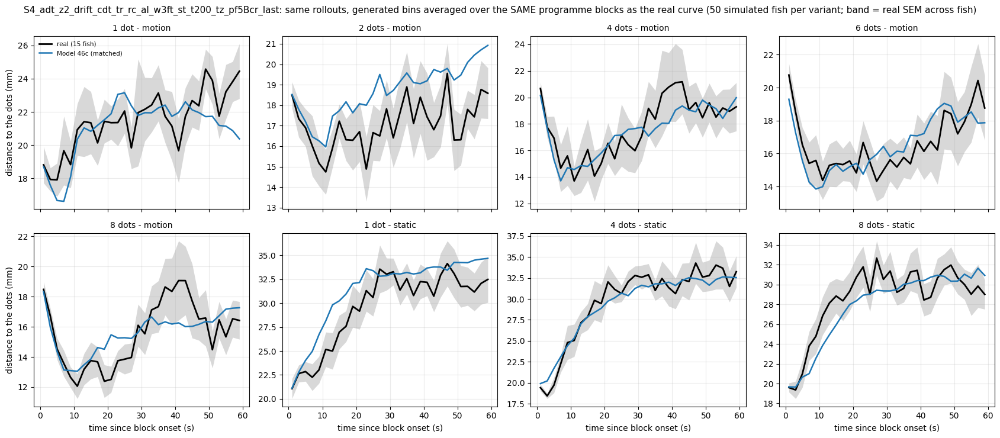

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_46c, _ = profile_variants_matched("report_ckpts/M46c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", {"Model 46c": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_46c, _ = attraction_table("report_ckpts/M46c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last                  
           plateau   null attraction                                                  plateau   null attraction
cond_label                                                                                                     
d1s3.5       22.41  23.57       1.16                                                    22.65  23.59       0.94
d2s3.5       17.39  23.58       6.19                                                    20.46  23.45       2.99
d4s3.5       18.74  23.93       5.19                                                    18.80  23.54       4.74
d6s3.5       16.69  23.12       6.43                                                    18.22  23.70       5.48
d8s3.5      

In [ ]:
# Model 46c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_46c = toward_by_n("report_ckpts/M46c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_46c.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last
win    N                                                                 
0-20 s 1   9.09                                                      9.63
       2  13.90                                                     13.53
       4  15.73                                                     15.05
       6  14.50                                                     16.33
       8  16.00                                                     18.68
4-20 s 1   6.25                                                      7.98
       2  12.27                                                     12.36
       4  14.35                                                     13.46
       6  12.79                                                     14.69
       8  15.11                                                     16.60


Model 46c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 46c   real gap Model 46c    real gap Model 46c
cond                                                                  
d1s3.5  25.08         -7.24   6.64          3.76    7.55          2.07
d2s3.5  22.99         -1.23  12.94          0.06   12.56         -1.46
d4s3.5  27.14         -4.09  15.54         -1.40   12.09          0.42
d6s3.5  32.55         -8.41  13.80          2.73   15.84         -2.02
d8s3.5  34.04         -7.14  14.45          3.56   13.80          1.08
d1s0     6.82         -5.63   4.22         -3.26    1.96         -0.48
d4s0     4.81         -1.61   1.86          0.74    1.74          2.00
d8s0     5.26         -1.13   2.63          0.66    2.39          2.35

turn size |Δθ| (deg): real f

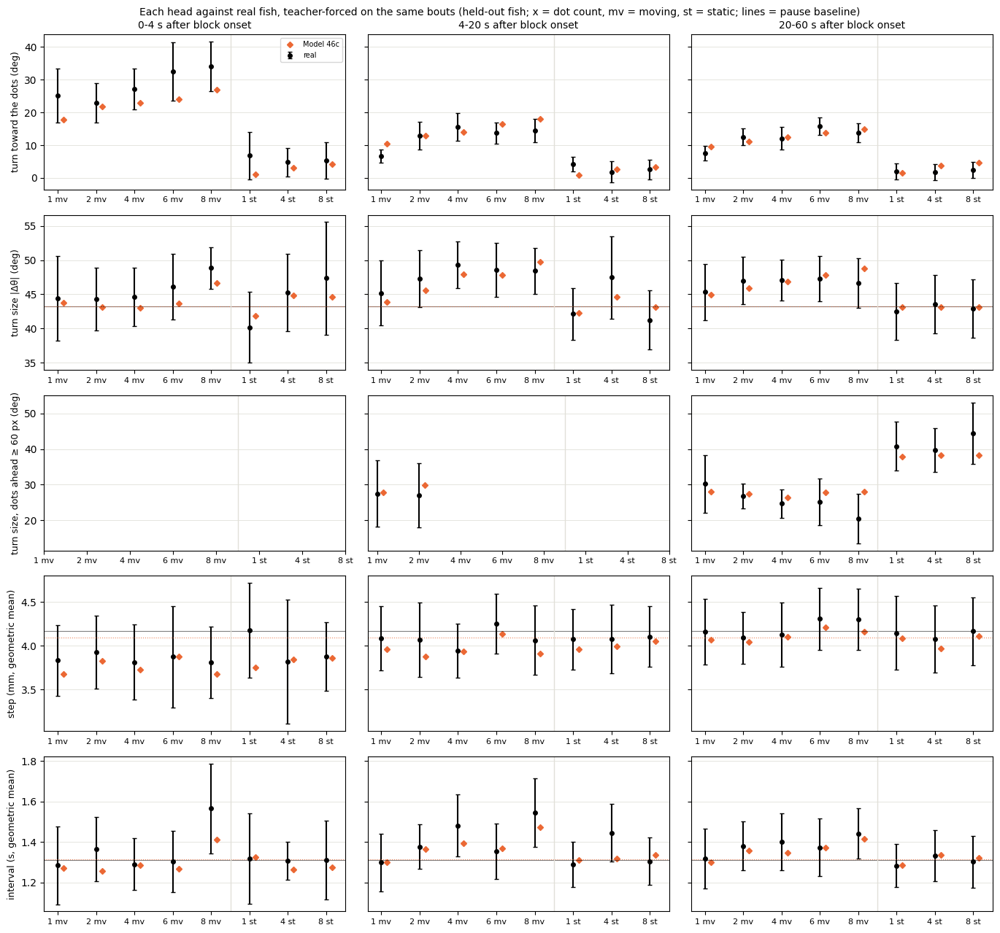

In [ ]:
# Model 46c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_46c, hg_46c = head_gaps({"Model 46c": ("report_ckpts/M46c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last")}, rej=REJ["wall_reject"])

#### F (14f), turn-size latent + tau = 200 — seed 101 (key `46d`)

In [ ]:
# Model 46d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M46d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_46d = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_46d.index = ["turn", "displacement", "interval", "joint"]
print(lik_46d.round(3).to_string())

turn             7.646
displacement     4.514
interval         1.202
joint           13.362


In [ ]:
# Model 46d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_46d, c2st_46d = run(ckpt_dir="report_ckpts/M46d", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last.csv  (15 rows) in 1150s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_rej
abs_dtheta_w1                                                                 8.1091
symbol_js                                                                     0.0118
dt_w1                                                       

In [ ]:
# Model 46d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M46d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_46d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_46d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.612            0.019      0.517         0.024
matched to the real runs (same bouts, 1:1)            0.597            0.022      0.505         0.026



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.479         0.088        0.038          0.429         0.834
                      median           0.449       0.483         0.098        0.044          0.446         0.856
                      SD               0.159       0.180         0.015        0.009          0.565         0.914
                      q90              0.679       0.732         0.074        0.040

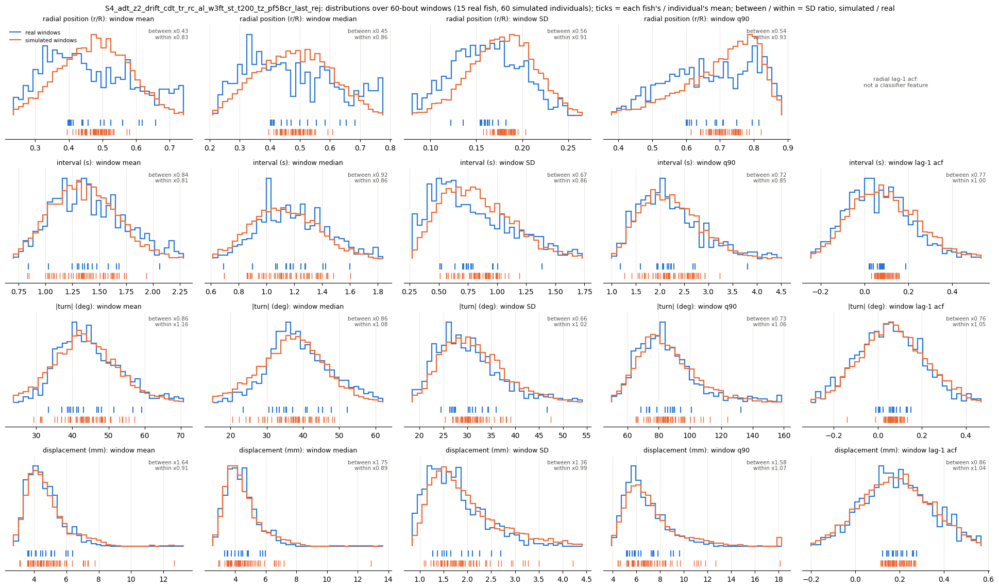

In [ ]:
# Model 46d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_46d = window_stats_grid("report_ckpts/M46d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.53     1.04  0.15  0.71   3.0   7.0                  22.3 +/- 0.9  20.7 +/- 1.0
d2s3.5    1.39     1.12  2.64  3.82  11.0  13.0                  17.4 +/-

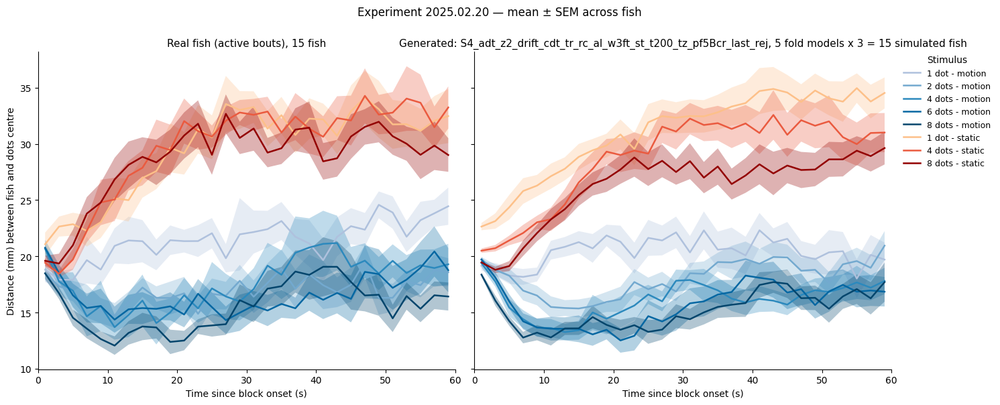

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M46d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

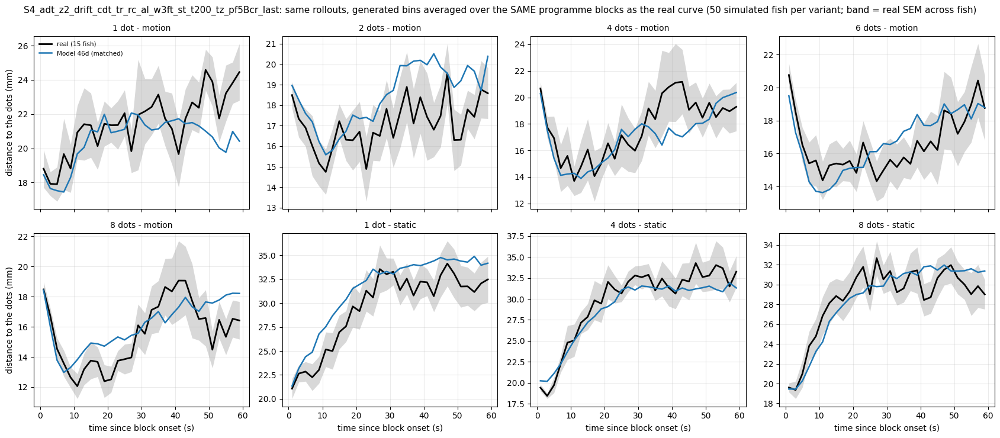

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_46d, _ = profile_variants_matched("report_ckpts/M46d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last", {"Model 46d": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 46d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_46d, _ = attraction_table("report_ckpts/M46d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last                  
           plateau   null attraction                                                  plateau   null attraction
cond_label                                                                                                     
d1s3.5       22.41  23.57       1.16                                                    21.24  22.60       1.35
d2s3.5       17.39  23.58       6.19                                                    19.20  22.86       3.66
d4s3.5       18.74  23.93       5.19                                                    17.68  22.87       5.20
d6s3.5       16.69  23.12       6.43                                                    17.24  22.76       5.52
d8s3.5      

In [ ]:
# Model 46d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_46d = toward_by_n("report_ckpts/M46d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_46d.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last
win    N                                                                 
0-20 s 1   9.09                                                     10.13
       2  13.90                                                     14.00
       4  15.73                                                     15.95
       6  14.50                                                     17.39
       8  16.00                                                     20.10
4-20 s 1   6.25                                                      8.93
       2  12.27                                                     13.26
       4  14.35                                                     14.74
       6  12.79                                                     16.00
       8  15.11                                                     18.40


Model 46d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 46d   real gap Model 46d    real gap Model 46d
cond                                                                  
d1s3.5  25.08         -8.65   6.64          4.11    7.55          2.45
d2s3.5  22.99         -3.05  12.94          1.02   12.56         -1.56
d4s3.5  27.14         -3.49  15.54         -0.93   12.09         -0.12
d6s3.5  32.55         -8.84  13.80          4.08   15.84         -2.10
d8s3.5  34.04         -5.98  14.45          5.04   13.80          1.01
d1s0     6.82         -6.46   4.22         -3.41    1.96         -0.26
d4s0     4.81         -2.91   1.86          0.34    1.74          1.99
d8s0     5.26         -0.71   2.63          0.60    2.39          2.04

turn size |Δθ| (deg): real f

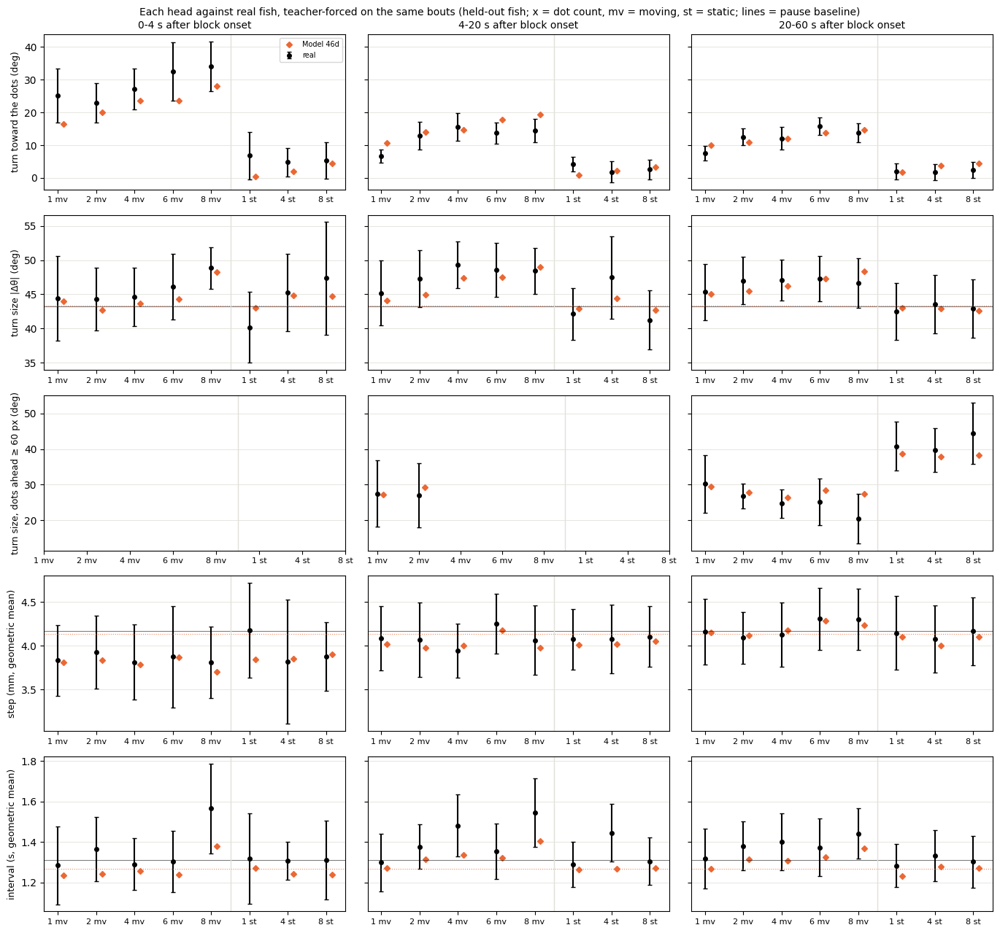

In [ ]:
# Model 46d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_46d, hg_46d = head_gaps({"Model 46d": ("report_ckpts/M46d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_tz_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="driftfix"></a>
## 8. Fixed drift strength — tau 70 against tau 200 at equal strength

D4's drift
with its generation strength FIXED for every fold instead of calibrated per fold (same checkpoints, gains rewritten so
that gain x |loading| is the same in every fold model; no retraining, likelihood unchanged). The per-fold calibration
gives the interval the same effective strength in every fold, but leaves folds whose likelihood learned a near-zero
displacement loading with no displacement drift (two of five in the tau-200 seed-101 unit), which can split the seeds.
Strength 0 (no drift at generation), half and full of the median the tau-70 calibration reached (displacement 0.05,
interval 0.13), at tau 70 and tau 200: at equal strength only the drift's speed differs. Read paired by seed against
each other and against Model 17 | 32a (tau 70, calibrated) and 37a | 37b (tau 200, calibrated).

<a id="m47a"></a>
### D4, no drift at generation

**Change:** Model 17 with drift strength 0



#### D4, no drift at generation — seed 0 (key `47a`)

In [ ]:
# Model 47a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47a = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47a.index = ["turn", "displacement", "interval", "joint"]
print(lik_47a.round(3).to_string())

turn             7.627
displacement     4.513
interval         1.203
joint           13.344


In [ ]:
# Model 47a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47a, c2st_47a = run(ckpt_dir="report_ckpts/M47a", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 848s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.7362
symbol_js                                                 0.0132
dt_w1                                                     0.4372
dist_w1                                                   4.6505
trans_js                                                  0.0153
acf_l2

In [ ]:
# Model 47a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.607            0.008      0.539         0.012
matched to the real runs (same bouts, 1:1)            0.596            0.009      0.531         0.014



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.468         0.088        0.042          0.479         0.874
                      median           0.449       0.469         0.098        0.046          0.474         0.875
                      SD               0.159       0.174         0.015        0.015          0.947         0.956
                      q90              0.679       0.713         0.074        0.056

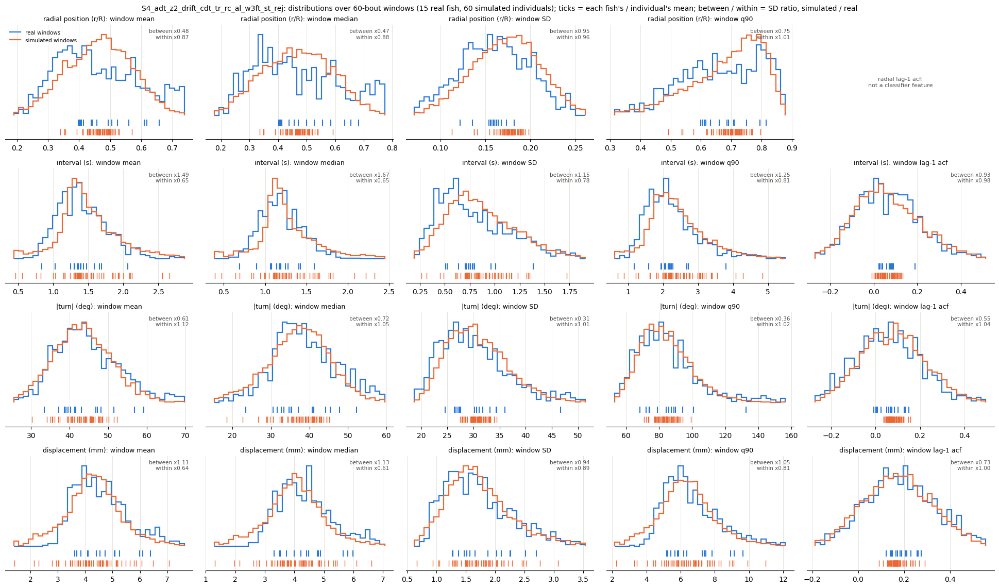

In [ ]:
# Model 47a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47a = window_stats_grid("report_ckpts/M47a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.36     0.91  0.15  0.37   3.0   5.0                  22.3 +/- 0.9  20.7 +/- 1.0
d2s3.5    1.16     0.94  2.64  3.59  11.0  19.0                  17.4 +/- 0.9  18.0 +/- 1.0
d4s3.5    1.25     0.69  4.68  4.38  19.0  19.0                  18.7 +/- 1.7  17

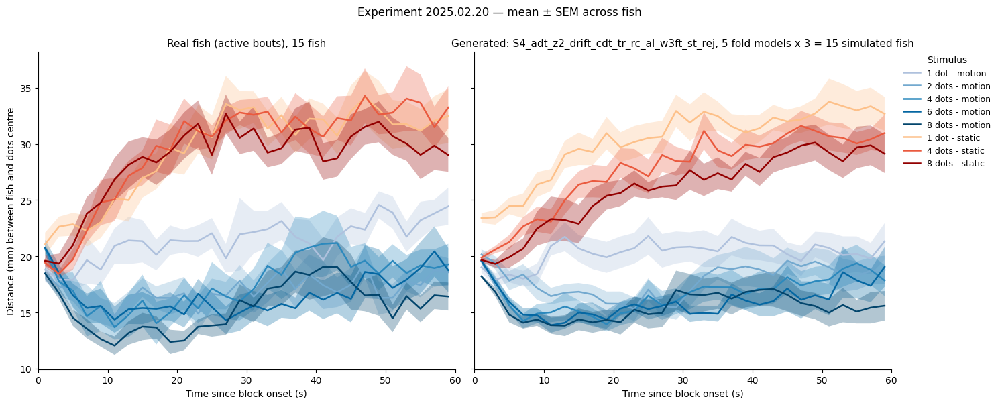

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

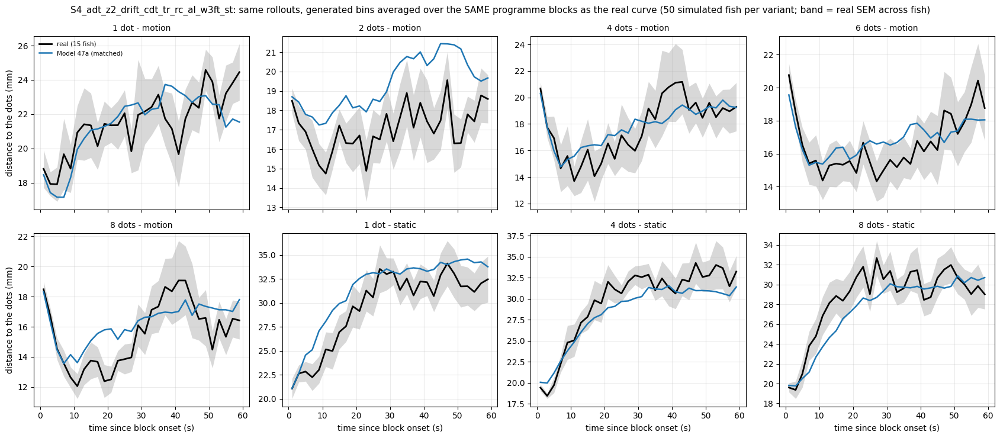

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47a, _ = profile_variants_matched("report_ckpts/M47a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 47a": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47a, _ = attraction_table("report_ckpts/M47a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.98  22.48       0.50
d2s3.5       17.39  23.58       6.19                                19.09  22.28       3.19
d4s3.5       18.74  23.93       5.19                                18.20  22.44       4.24
d6s3.5       16.69  23.12       6.43                                16.99  22.24       5.25
d8s3.5       16.41  23.36       6.94                                16.71  22.36       5.64


In [ ]:
# Model 47a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47a = toward_by_n("report_ckpts/M47a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_47a.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                             
0-20 s 1   9.09                                  9.59
       2  13.90                                 11.44
       4  15.73                                 12.80
       6  14.50                                 13.38
       8  16.00                                 15.57
4-20 s 1   6.25                                  8.44
       2  12.27                                 10.47
       4  14.35                                 11.33
       6  12.79                                 11.79
       8  15.11                                 13.53


Model 47a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47a   real gap Model 47a    real gap Model 47a
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.93    7.55          1.91
d2s3.5  22.99         -4.88  12.94         -1.98   12.56         -2.17
d4s3.5  27.14         -6.92  15.54         -3.59   12.09         -0.72
d6s3.5  32.55         -9.65  13.80         -0.30   15.84         -3.07
d8s3.5  34.04         -8.25  14.45          0.41   13.80         -0.08
d1s0     6.82         -6.47   4.22         -3.10    1.96          0.12
d4s0     4.81         -2.04   1.86          0.95    1.74          1.96
d8s0     5.26         -0.72   2.63          1.08    2.39          2.55

turn size |Δθ| (deg): real f

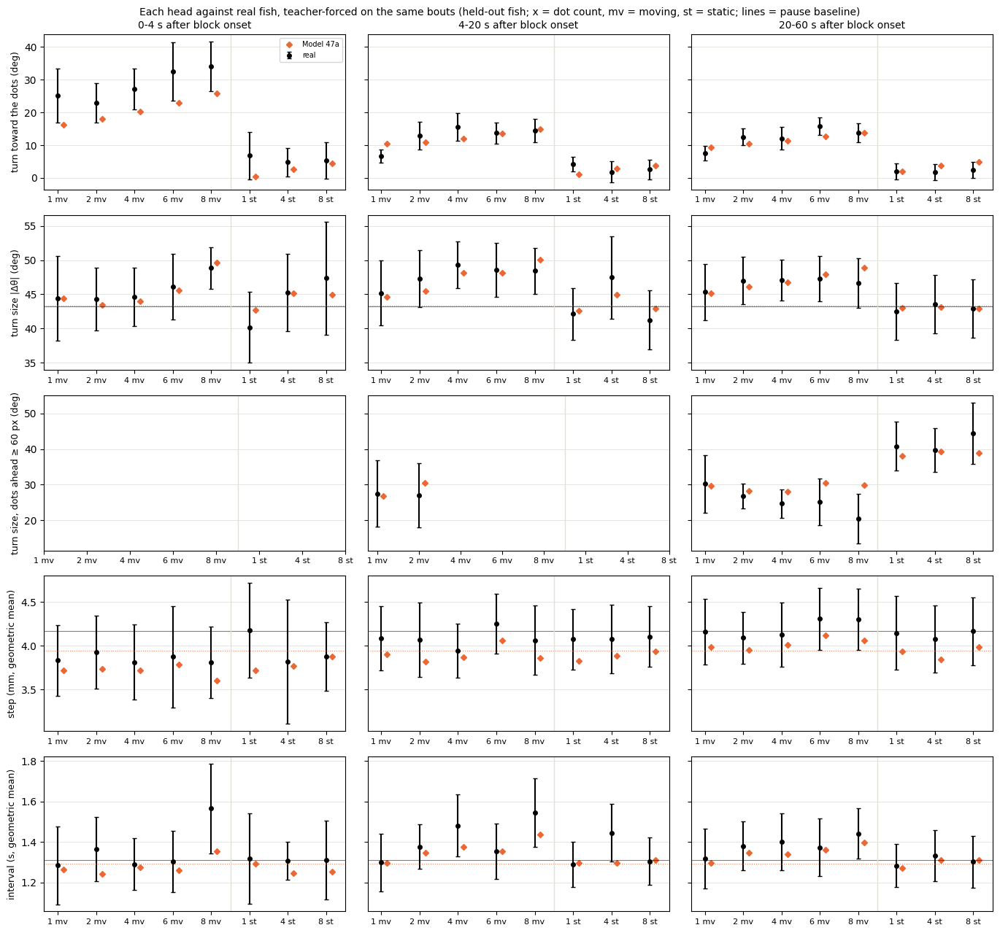

In [ ]:
# Model 47a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47a, hg_47a = head_gaps({"Model 47a": ("report_ckpts/M47a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

#### D4, no drift at generation — seed 101 (key `47f`)

In [ ]:
# Model 47f: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47f/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47f = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47f.index = ["turn", "displacement", "interval", "joint"]
print(lik_47f.round(3).to_string())

turn             7.630
displacement     4.520
interval         1.207
joint           13.356


In [ ]:
# Model 47f: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47f, c2st_47f = run(ckpt_dir="report_ckpts/M47f", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 831s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.2513
symbol_js                                                 0.0124
dt_w1                                                     0.3815
dist_w1                                                   3.5162
trans_js                                                  0.0140
acf_l2

In [ ]:
# Model 47f: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47f = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47f.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.601            0.031      0.533         0.028
matched to the real runs (same bouts, 1:1)            0.597            0.032      0.524         0.031



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.473         0.088        0.035          0.396         0.812
                      median           0.449       0.477         0.098        0.039          0.396         0.827
                      SD               0.159       0.177         0.015        0.010          0.660         0.909
                      q90              0.679       0.716         0.074        0.040

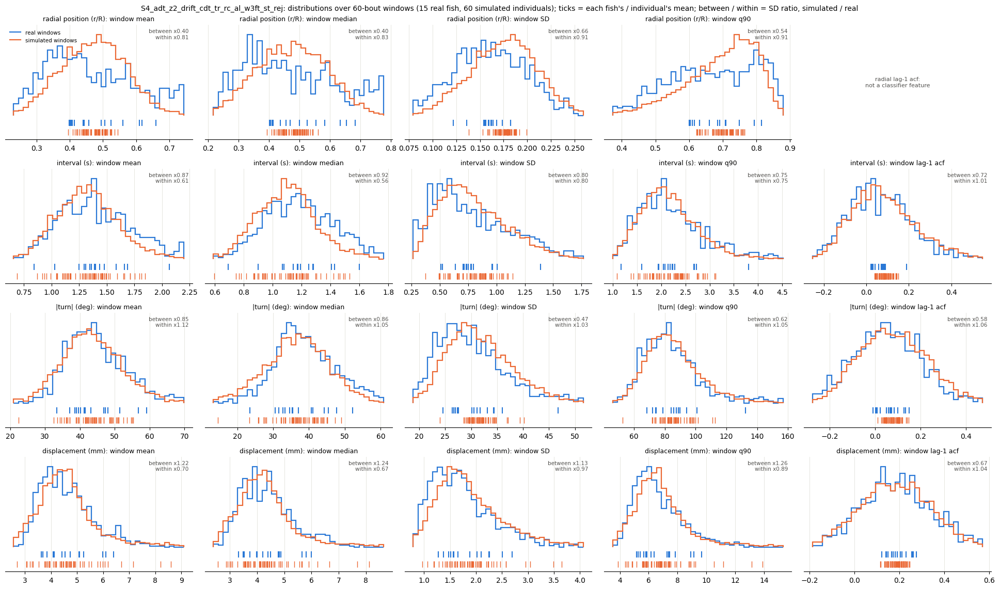

In [ ]:
# Model 47f: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47f = window_stats_grid("report_ckpts/M47f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.15     0.77  0.15  1.49   3.0   7.0                  22.3 +/- 0.9  21.8 +/- 1.2
d2s3.5    1.98     1.50  2.64  3.15  11.0  11.0                  17.4 +/- 0.9  19.8 +/- 1.2
d4s3.5    1.45     0.91  4.68  3.13  19.0   9.0                  18.7 +/- 1.7  18

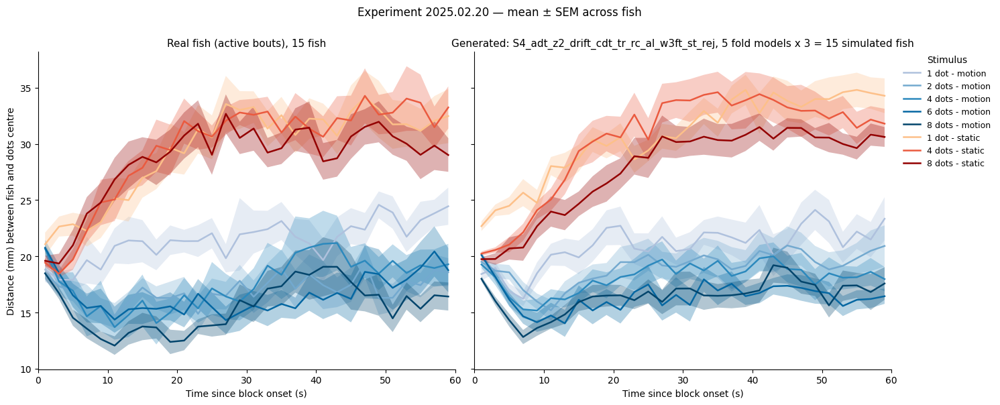

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47f: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

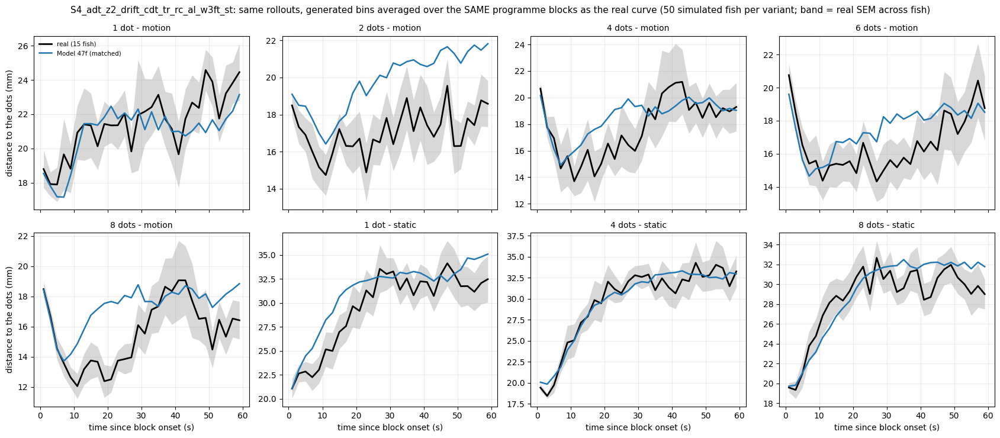

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47f: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47f, _ = profile_variants_matched("report_ckpts/M47f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 47f": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47f: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47f, _ = attraction_table("report_ckpts/M47f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.54  22.64       1.10
d2s3.5       17.39  23.58       6.19                                20.13  22.43       2.31
d4s3.5       18.74  23.93       5.19                                19.47  22.48       3.01
d6s3.5       16.69  23.12       6.43                                17.79  22.68       4.88
d8s3.5       16.41  23.36       6.94                                17.59  22.64       5.05


In [ ]:
# Model 47f: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47f = toward_by_n("report_ckpts/M47f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_47f.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                             
0-20 s 1   9.09                                  9.97
       2  13.90                                 11.86
       4  15.73                                 12.79
       6  14.50                                 13.30
       8  16.00                                 16.68
4-20 s 1   6.25                                  8.80
       2  12.27                                 10.94
       4  14.35                                 11.25
       6  12.79                                 11.46
       8  15.11                                 14.89


Model 47f: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47f   real gap Model 47f    real gap Model 47f
cond                                                                  
d1s3.5  25.08         -9.06   6.64          4.12    7.55          2.22
d2s3.5  22.99         -4.49  12.94         -1.00   12.56         -1.60
d4s3.5  27.14         -5.93  15.54         -4.12   12.09         -0.52
d6s3.5  32.55        -10.88  13.80          0.62   15.84         -2.56
d8s3.5  34.04         -7.96  14.45          1.54   13.80          0.79
d1s0     6.82         -5.60   4.22         -2.98    1.96          0.07
d4s0     4.81         -2.53   1.86          0.11    1.74          1.83
d8s0     5.26         -1.37   2.63         -0.19    2.39          1.67

turn size |Δθ| (deg): real f

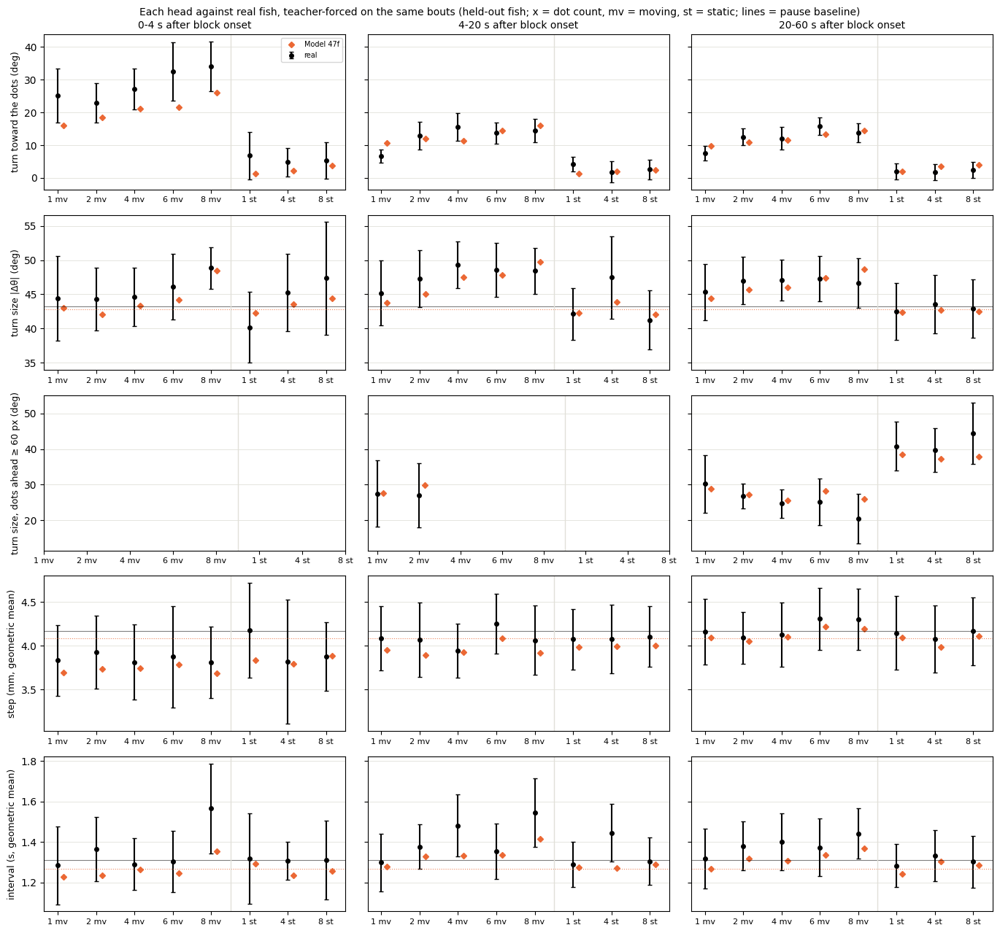

In [ ]:
# Model 47f: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47f, hg_47f = head_gaps({"Model 47f": ("report_ckpts/M47f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

<a id="m47b"></a>
### D4, tau 70, half strength

**Change:** Model 17, fixed half strength



#### D4, tau 70, half strength — seed 0 (key `47b`)

In [ ]:
# Model 47b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47b = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47b.index = ["turn", "displacement", "interval", "joint"]
print(lik_47b.round(3).to_string())

turn             7.627
displacement     4.513
interval         1.203
joint           13.344


In [ ]:
# Model 47b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47b, c2st_47b = run(ckpt_dir="report_ckpts/M47b", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 831s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.7579
symbol_js                                                 0.0132
dt_w1                                                     0.4385
dist_w1                                                   4.6546
trans_js                                                  0.0153
acf_l2

In [ ]:
# Model 47b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.614            0.009      0.543         0.015
matched to the real runs (same bouts, 1:1)            0.615            0.009      0.540         0.018



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.466         0.088        0.042          0.484         0.879
                      median           0.449       0.469         0.098        0.046          0.472         0.876
                      SD               0.159       0.173         0.015        0.015          0.938         0.952
                      q90              0.679       0.711         0.074        0.056

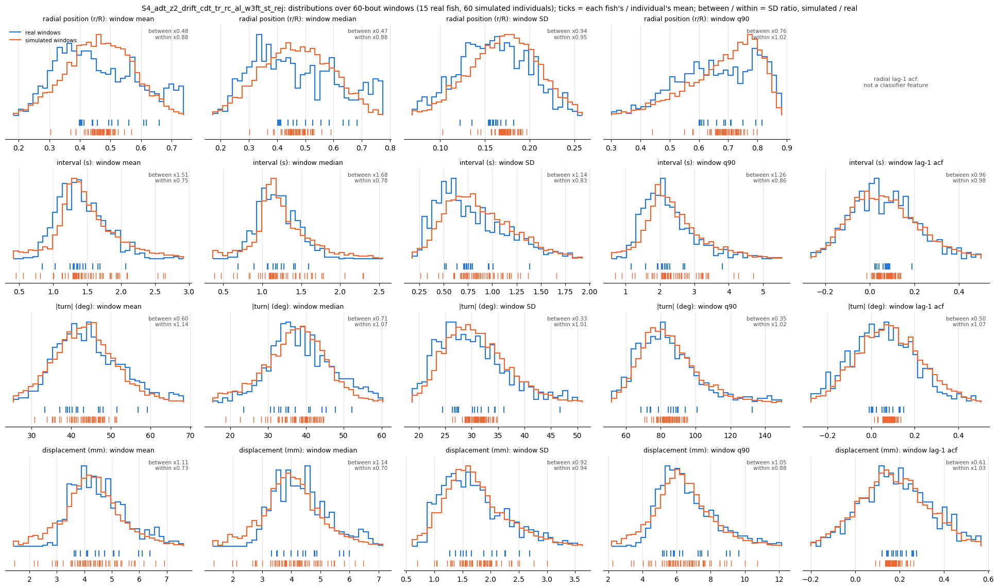

In [ ]:
# Model 47b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47b = window_stats_grid("report_ckpts/M47b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 9.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.15     0.79  0.15  1.06   3.0   5.0                  22.3 +/- 0.9  21.6 +/- 0.9
d2s3.5    1.22     0.96  2.64  2.36  11.0  11.0                  17.4 +/- 0.9  18.1 +/- 0.9
d4s3.5    1.66     0.94  4.68  3.25  19.0   9.0                  18.7 +/- 1.7  17.

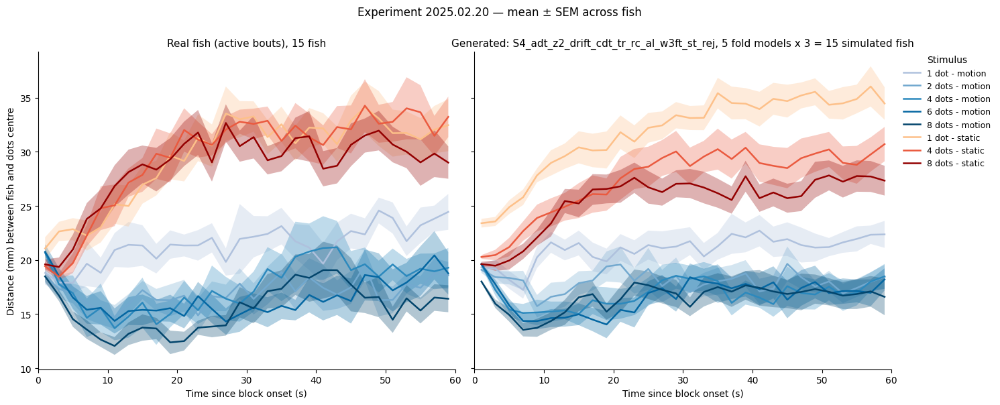

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

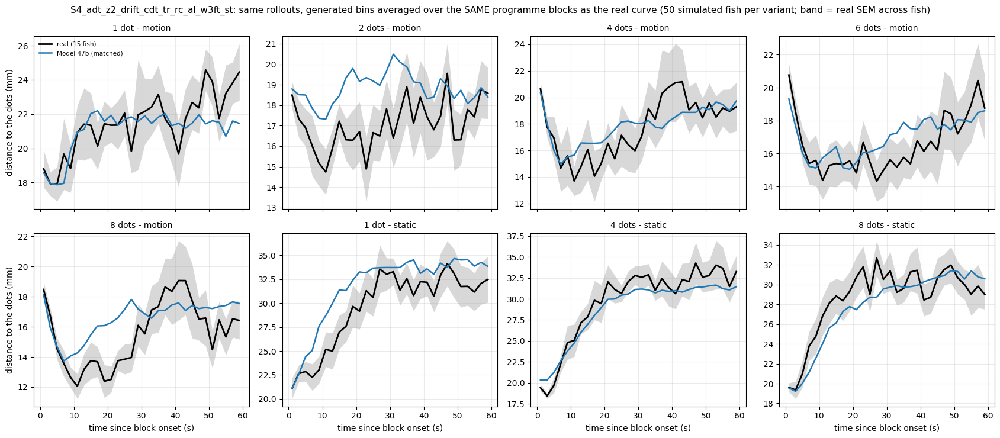

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47b, _ = profile_variants_matched("report_ckpts/M47b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 47b": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47b, _ = attraction_table("report_ckpts/M47b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.48  22.48       1.01
d2s3.5       17.39  23.58       6.19                                19.22  22.54       3.32
d4s3.5       18.74  23.93       5.19                                18.59  22.23       3.65
d6s3.5       16.69  23.12       6.43                                17.14  22.23       5.09
d8s3.5       16.41  23.36       6.94                                17.12  22.22       5.10


In [ ]:
# Model 47b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47b = toward_by_n("report_ckpts/M47b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_47b.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                             
0-20 s 1   9.09                                  9.59
       2  13.90                                 11.44
       4  15.73                                 12.80
       6  14.50                                 13.38
       8  16.00                                 15.57
4-20 s 1   6.25                                  8.44
       2  12.27                                 10.47
       4  14.35                                 11.33
       6  12.79                                 11.79
       8  15.11                                 13.53


Model 47b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47b   real gap Model 47b    real gap Model 47b
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.93    7.55          1.91
d2s3.5  22.99         -4.88  12.94         -1.98   12.56         -2.17
d4s3.5  27.14         -6.92  15.54         -3.59   12.09         -0.72
d6s3.5  32.55         -9.65  13.80         -0.30   15.84         -3.07
d8s3.5  34.04         -8.25  14.45          0.41   13.80         -0.08
d1s0     6.82         -6.47   4.22         -3.10    1.96          0.12
d4s0     4.81         -2.04   1.86          0.95    1.74          1.96
d8s0     5.26         -0.72   2.63          1.08    2.39          2.55

turn size |Δθ| (deg): real f

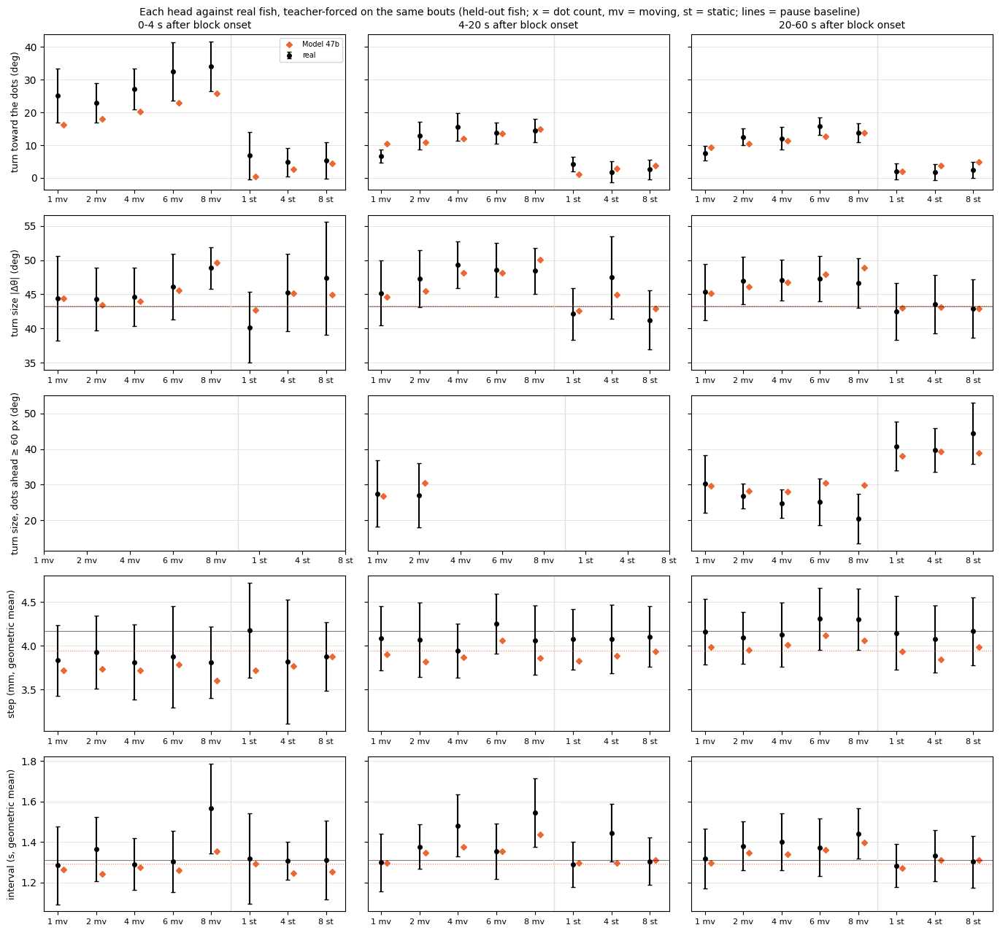

In [ ]:
# Model 47b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47b, hg_47b = head_gaps({"Model 47b": ("report_ckpts/M47b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

#### D4, tau 70, half strength — seed 101 (key `47g`)

In [ ]:
# Model 47g: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47g/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47g = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47g.index = ["turn", "displacement", "interval", "joint"]
print(lik_47g.round(3).to_string())

turn             7.630
displacement     4.520
interval         1.207
joint           13.356


In [ ]:
# Model 47g: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47g, c2st_47g = run(ckpt_dir="report_ckpts/M47g", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 591s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.1677
symbol_js                                                 0.0124
dt_w1                                                     0.3804
dist_w1                                                   3.5071
trans_js                                                  0.0140
acf_l2

In [ ]:
# Model 47g: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47g", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47g = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47g.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.607            0.026      0.532         0.025
matched to the real runs (same bouts, 1:1)            0.595            0.028      0.518         0.027



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.475         0.088        0.034          0.389         0.818
                      median           0.449       0.478         0.098        0.038          0.391         0.829
                      SD               0.159       0.175         0.015        0.010          0.657         0.903
                      q90              0.679       0.722         0.074        0.041

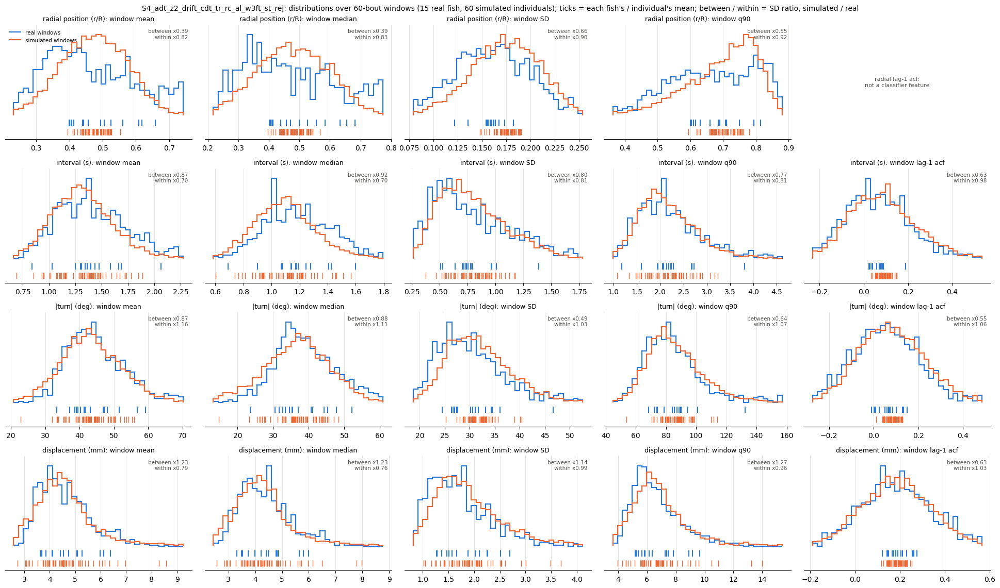

In [ ]:
# Model 47g: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47g = window_stats_grid("report_ckpts/M47g", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 12.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.37     0.90  0.15  0.84   3.0   5.0                  22.3 +/- 0.9  21.4 +/- 1.0
d2s3.5    2.18     1.67  2.64   2.6  11.0  11.0                  17.4 +/- 0.9  19.9 +/- 1.0
d4s3.5    1.57     0.94  4.68  4.08  19.0   9.0                  18.7 +/- 1.7  18

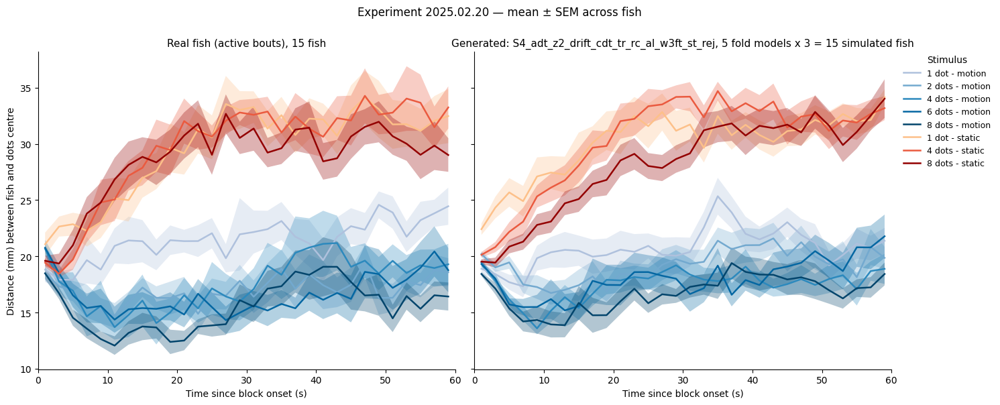

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47g: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47g", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

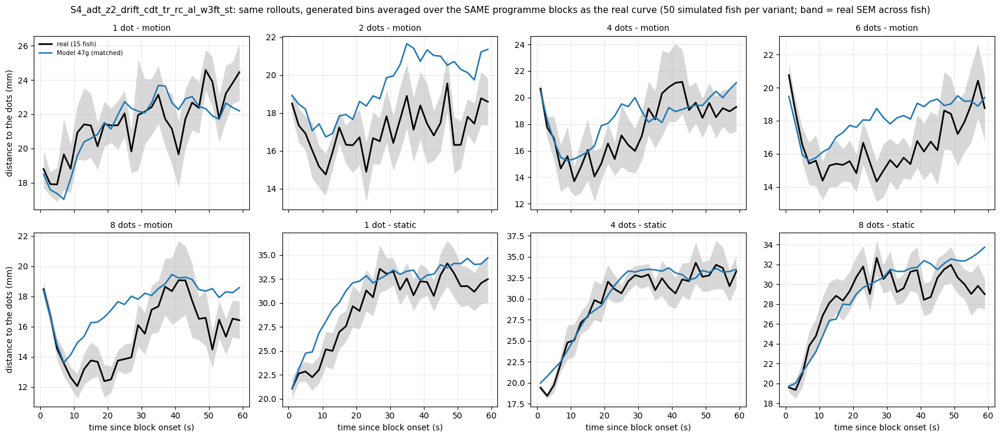

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47g: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47g, _ = profile_variants_matched("report_ckpts/M47g", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 47g": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47g: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47g, _ = attraction_table("report_ckpts/M47g", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                22.17  22.57       0.41
d2s3.5       17.39  23.58       6.19                                19.80  22.71       2.92
d4s3.5       18.74  23.93       5.19                                19.20  22.45       3.25
d6s3.5       16.69  23.12       6.43                                18.53  22.65       4.12
d8s3.5       16.41  23.36       6.94                                17.70  22.69       4.99


In [ ]:
# Model 47g: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47g = toward_by_n("report_ckpts/M47g", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_47g.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                             
0-20 s 1   9.09                                  9.97
       2  13.90                                 11.86
       4  15.73                                 12.79
       6  14.50                                 13.30
       8  16.00                                 16.68
4-20 s 1   6.25                                  8.80
       2  12.27                                 10.94
       4  14.35                                 11.25
       6  12.79                                 11.46
       8  15.11                                 14.89


Model 47g: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47g   real gap Model 47g    real gap Model 47g
cond                                                                  
d1s3.5  25.08         -9.06   6.64          4.12    7.55          2.22
d2s3.5  22.99         -4.49  12.94         -1.00   12.56         -1.60
d4s3.5  27.14         -5.93  15.54         -4.12   12.09         -0.52
d6s3.5  32.55        -10.88  13.80          0.62   15.84         -2.56
d8s3.5  34.04         -7.96  14.45          1.54   13.80          0.79
d1s0     6.82         -5.60   4.22         -2.98    1.96          0.07
d4s0     4.81         -2.53   1.86          0.11    1.74          1.83
d8s0     5.26         -1.37   2.63         -0.19    2.39          1.67

turn size |Δθ| (deg): real f

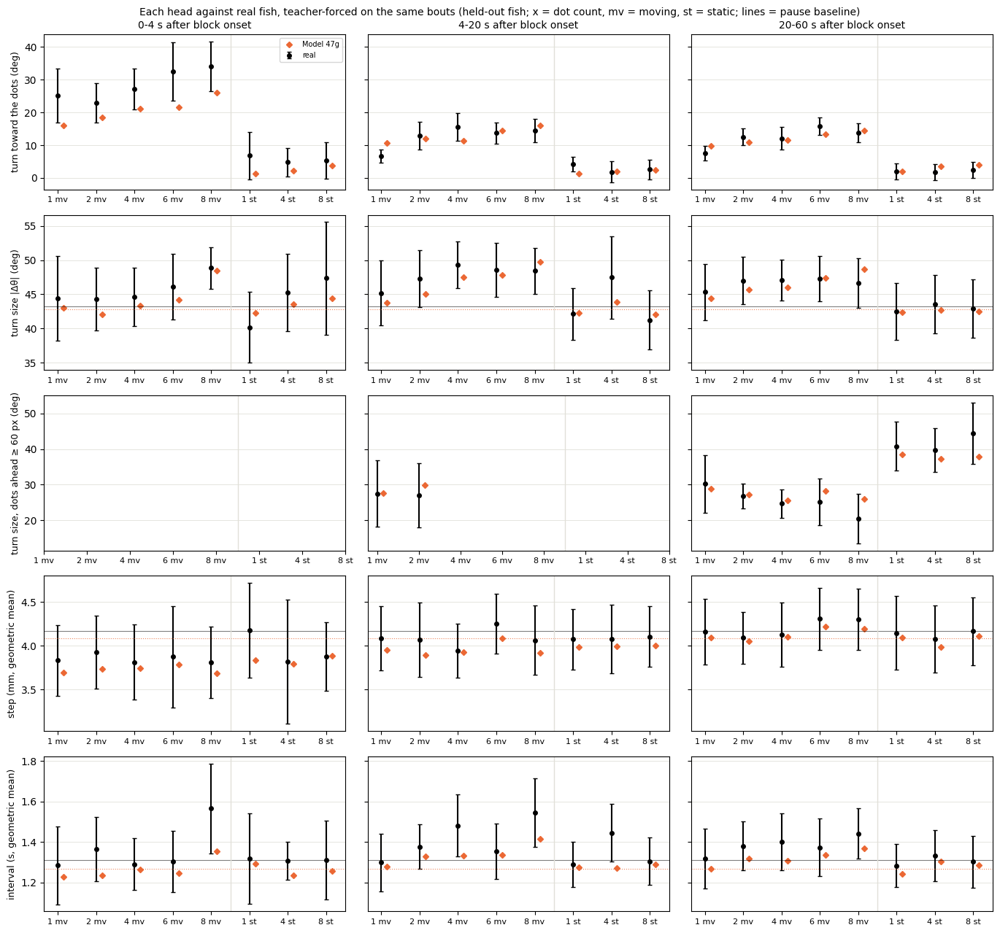

In [ ]:
# Model 47g: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47g, hg_47g = head_gaps({"Model 47g": ("report_ckpts/M47g", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

<a id="m47c"></a>
### D4, tau 70, full strength

**Change:** Model 17, fixed full strength



#### D4, tau 70, full strength — seed 0 (key `47c`)

In [ ]:
# Model 47c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47c = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47c.index = ["turn", "displacement", "interval", "joint"]
print(lik_47c.round(3).to_string())

turn             7.627
displacement     4.513
interval         1.203
joint           13.344


In [ ]:
# Model 47c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47c, c2st_47c = run(ckpt_dir="report_ckpts/M47c", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 820s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.7513
symbol_js                                                 0.0134
dt_w1                                                     0.4377
dist_w1                                                   4.6631
trans_js                                                  0.0152
acf_l2

In [ ]:
# Model 47c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.652            0.008      0.576         0.013
matched to the real runs (same bouts, 1:1)            0.649            0.010      0.567         0.014



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.464         0.088        0.043          0.487         0.896
                      median           0.449       0.467         0.098        0.047          0.479         0.900
                      SD               0.159       0.174         0.015        0.016          1.011         0.957
                      q90              0.679       0.713         0.074        0.058

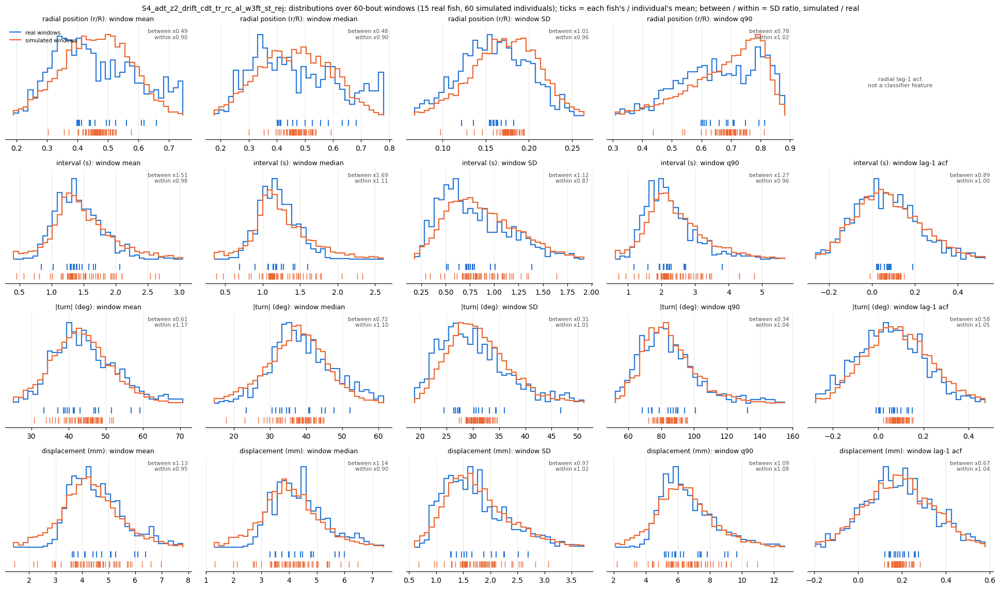

In [ ]:
# Model 47c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47c = window_stats_grid("report_ckpts/M47c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 9.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.54     1.04  0.15  0.83   3.0   5.0                  22.3 +/- 0.9  20.7 +/- 0.8
d2s3.5    1.32     1.05  2.64   2.8  11.0   9.0                  17.4 +/- 0.9  18.4 +/- 0.9
d4s3.5    1.30     0.71  4.68  3.68  19.0   7.0                  18.7 +/- 1.7  17.

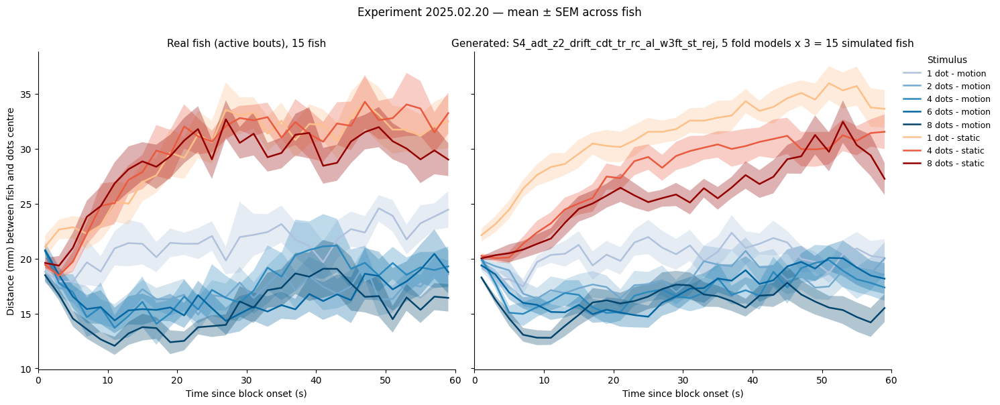

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

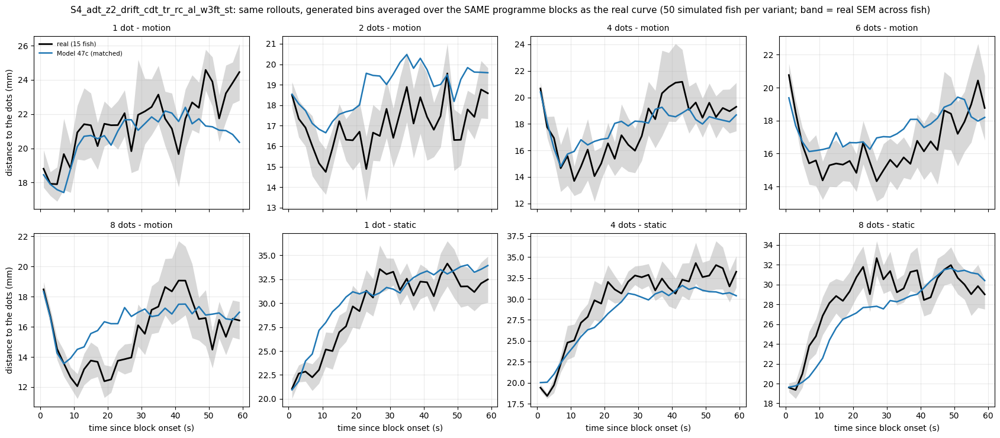

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47c, _ = profile_variants_matched("report_ckpts/M47c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 47c": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47c, _ = attraction_table("report_ckpts/M47c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.42  22.35       0.93
d2s3.5       17.39  23.58       6.19                                19.20  22.45       3.25
d4s3.5       18.74  23.93       5.19                                18.26  22.11       3.85
d6s3.5       16.69  23.12       6.43                                18.01  22.29       4.29
d8s3.5       16.41  23.36       6.94                                16.55  22.10       5.55


In [ ]:
# Model 47c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47c = toward_by_n("report_ckpts/M47c", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_47c.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                             
0-20 s 1   9.09                                  9.59
       2  13.90                                 11.44
       4  15.73                                 12.80
       6  14.50                                 13.38
       8  16.00                                 15.57
4-20 s 1   6.25                                  8.44
       2  12.27                                 10.47
       4  14.35                                 11.33
       6  12.79                                 11.79
       8  15.11                                 13.53


Model 47c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47c   real gap Model 47c    real gap Model 47c
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.93    7.55          1.91
d2s3.5  22.99         -4.88  12.94         -1.98   12.56         -2.17
d4s3.5  27.14         -6.92  15.54         -3.59   12.09         -0.72
d6s3.5  32.55         -9.65  13.80         -0.30   15.84         -3.07
d8s3.5  34.04         -8.25  14.45          0.41   13.80         -0.08
d1s0     6.82         -6.47   4.22         -3.10    1.96          0.12
d4s0     4.81         -2.04   1.86          0.95    1.74          1.96
d8s0     5.26         -0.72   2.63          1.08    2.39          2.55

turn size |Δθ| (deg): real f

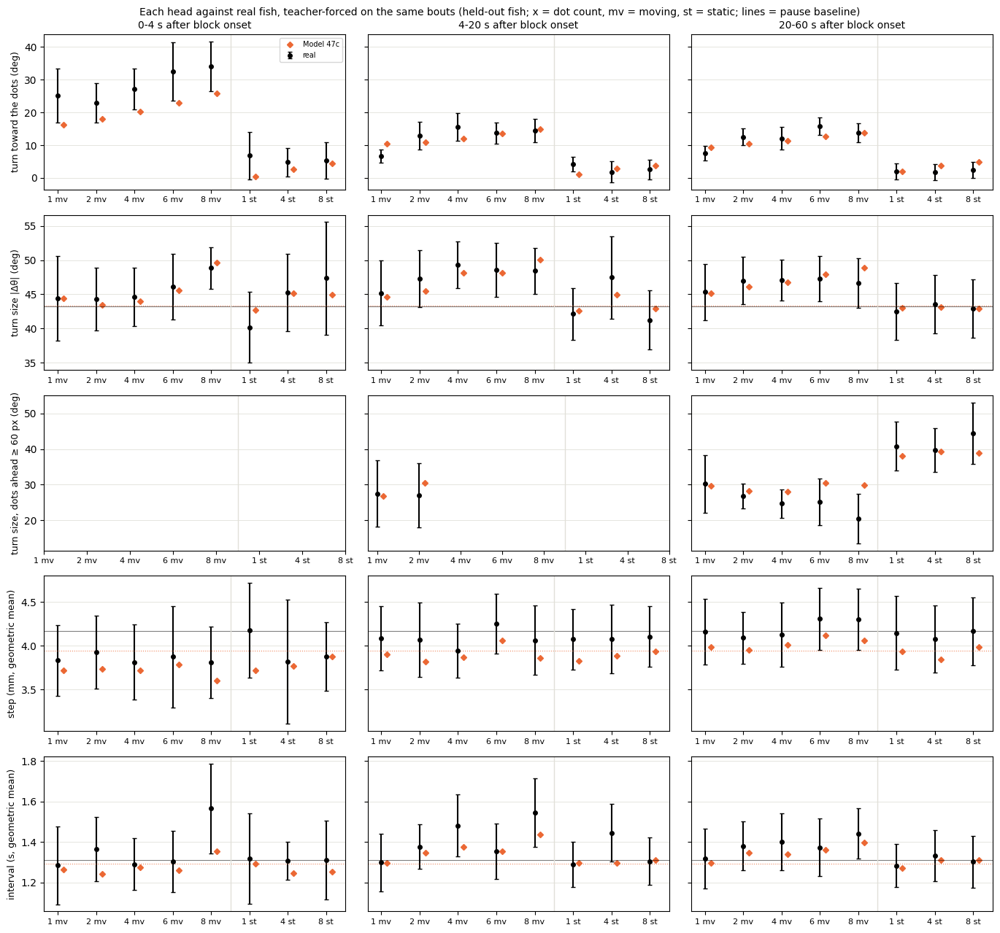

In [ ]:
# Model 47c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47c, hg_47c = head_gaps({"Model 47c": ("report_ckpts/M47c", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

#### D4, tau 70, full strength — seed 101 (key `47h`)

In [ ]:
# Model 47h: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47h/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47h = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47h.index = ["turn", "displacement", "interval", "joint"]
print(lik_47h.round(3).to_string())

turn             7.630
displacement     4.520
interval         1.207
joint           13.356


In [ ]:
# Model 47h: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47h, c2st_47h = run(ckpt_dir="report_ckpts/M47h", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 593s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.2687
symbol_js                                                 0.0125
dt_w1                                                     0.3770
dist_w1                                                   3.5641
trans_js                                                  0.0140
acf_l2

In [ ]:
# Model 47h: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47h", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47h = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47h.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.615            0.026      0.528         0.023
matched to the real runs (same bouts, 1:1)            0.621            0.025      0.526         0.024



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.476         0.088        0.034          0.389         0.861
                      median           0.449       0.482         0.098        0.038          0.392         0.872
                      SD               0.159       0.175         0.015        0.010          0.656         0.904
                      q90              0.679       0.721         0.074        0.040

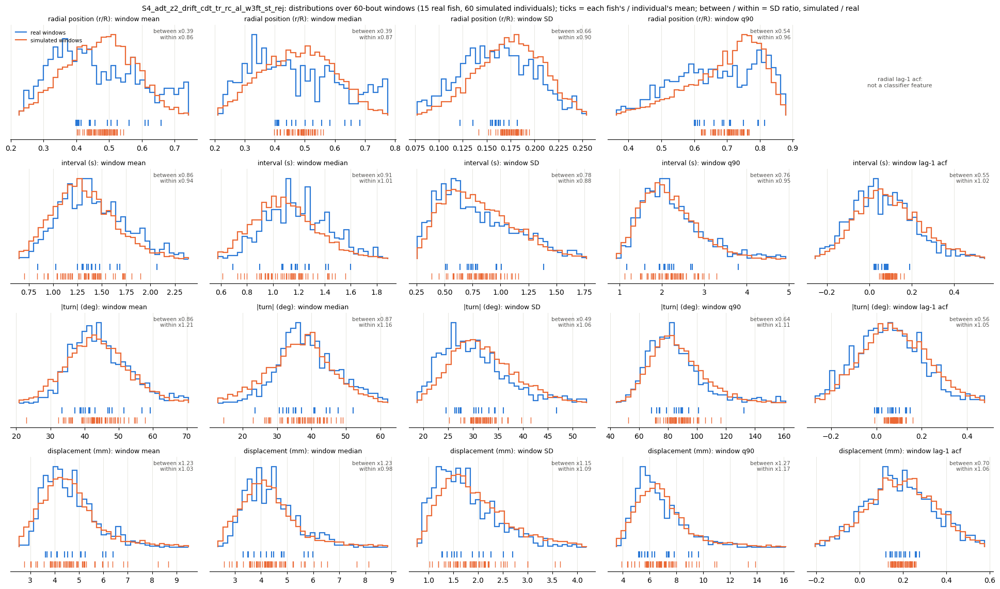

In [ ]:
# Model 47h: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47h = window_stats_grid("report_ckpts/M47h", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.49     0.99  0.15   0.5   3.0   5.0                  22.3 +/- 0.9  23.6 +/- 0.9
d2s3.5    1.56     1.28  2.64  2.52  11.0  11.0                  17.4 +/- 0.9  18.5 +/- 0.9
d4s3.5    1.23     0.71  4.68  4.28  19.0   9.0                  18.7 +/- 1.7  18

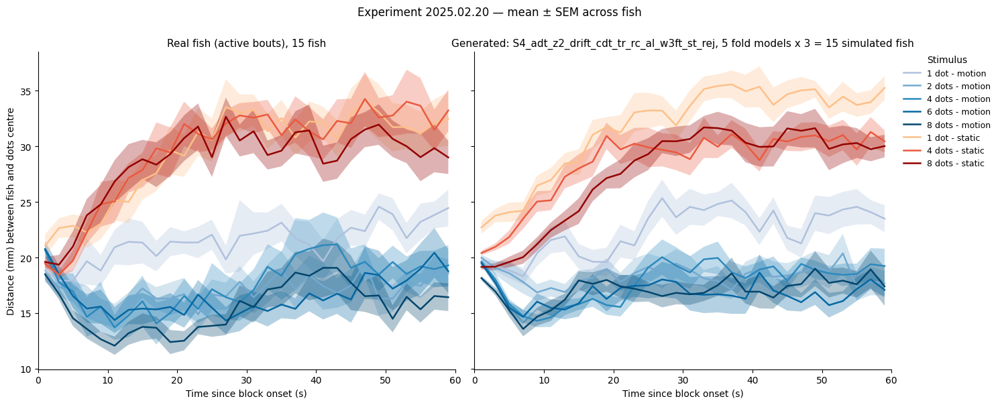

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47h: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47h", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

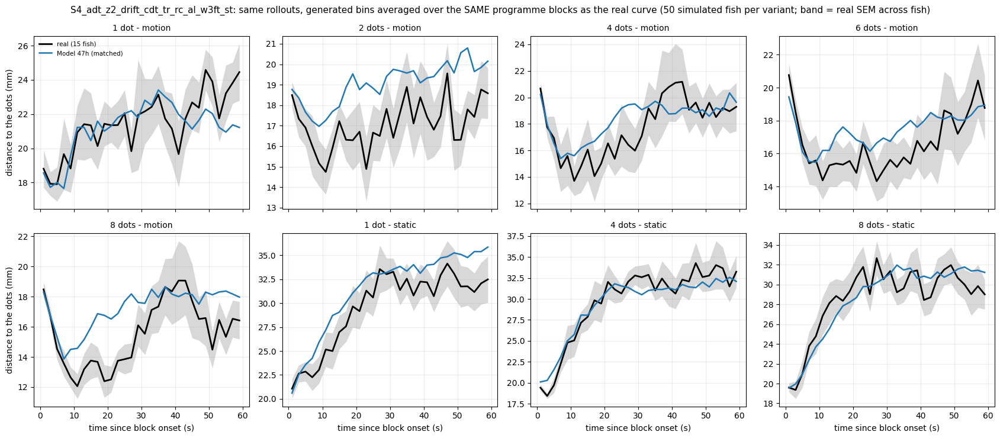

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47h: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47h, _ = profile_variants_matched("report_ckpts/M47h", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st", {"Model 47h": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47h: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47h, _ = attraction_table("report_ckpts/M47h", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                22.56  22.34      -0.23
d2s3.5       17.39  23.58       6.19                                18.88  22.24       3.36
d4s3.5       18.74  23.93       5.19                                19.37  22.57       3.20
d6s3.5       16.69  23.12       6.43                                18.29  22.38       4.09
d8s3.5       16.41  23.36       6.94                                17.84  22.35       4.51


In [ ]:
# Model 47h: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47h = toward_by_n("report_ckpts/M47h", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st"], rej=REJ["wall_reject"])
print(tow_47h.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
win    N                                             
0-20 s 1   9.09                                  9.97
       2  13.90                                 11.86
       4  15.73                                 12.79
       6  14.50                                 13.30
       8  16.00                                 16.68
4-20 s 1   6.25                                  8.80
       2  12.27                                 10.94
       4  14.35                                 11.25
       6  12.79                                 11.46
       8  15.11                                 14.89


Model 47h: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47h   real gap Model 47h    real gap Model 47h
cond                                                                  
d1s3.5  25.08         -9.06   6.64          4.12    7.55          2.22
d2s3.5  22.99         -4.49  12.94         -1.00   12.56         -1.60
d4s3.5  27.14         -5.93  15.54         -4.12   12.09         -0.52
d6s3.5  32.55        -10.88  13.80          0.62   15.84         -2.56
d8s3.5  34.04         -7.96  14.45          1.54   13.80          0.79
d1s0     6.82         -5.60   4.22         -2.98    1.96          0.07
d4s0     4.81         -2.53   1.86          0.11    1.74          1.83
d8s0     5.26         -1.37   2.63         -0.19    2.39          1.67

turn size |Δθ| (deg): real f

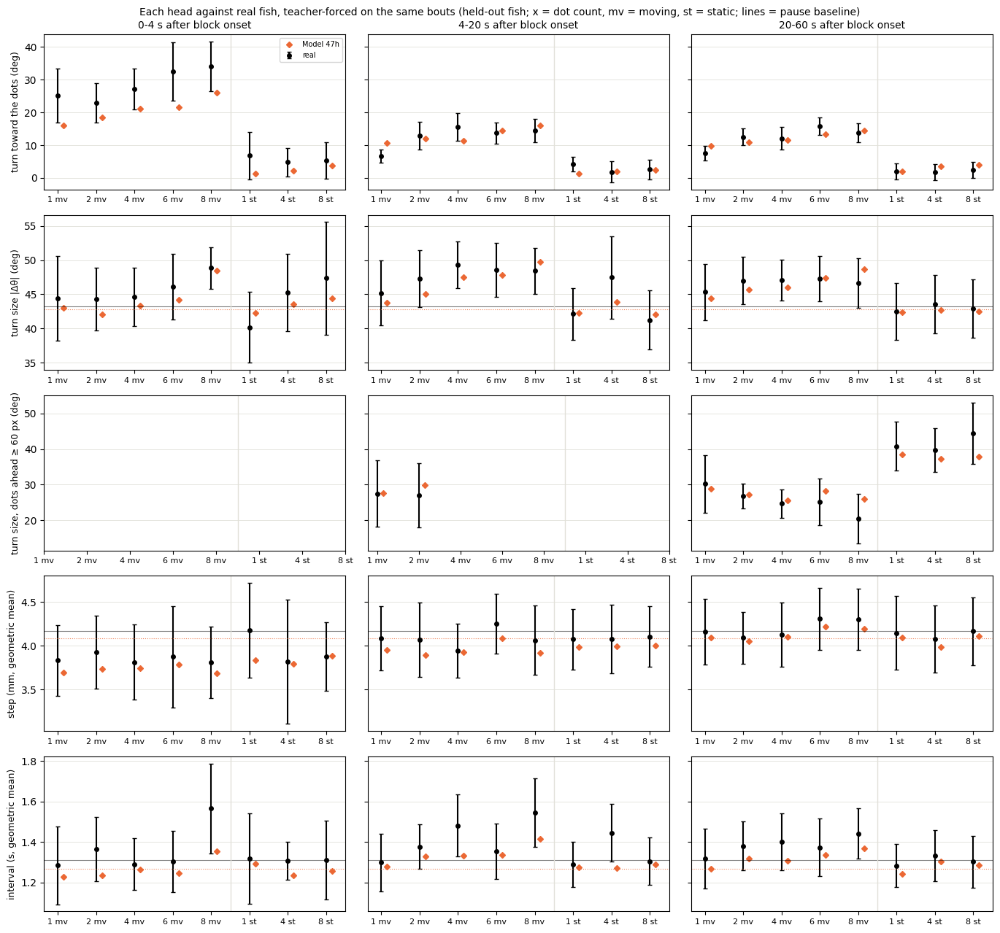

In [ ]:
# Model 47h: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47h, hg_47h = head_gaps({"Model 47h": ("report_ckpts/M47h", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st")}, rej=REJ["wall_reject"])

<a id="m47d"></a>
### D4, tau 200, half strength

**Change:** 37a | 37b, fixed half strength



#### D4, tau 200, half strength — seed 0 (key `47d`)

In [ ]:
# Model 47d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47d = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47d.index = ["turn", "displacement", "interval", "joint"]
print(lik_47d.round(3).to_string())

turn             7.626
displacement     4.515
interval         1.205
joint           13.347


In [ ]:
# Model 47d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47d, c2st_47d = run(ckpt_dir="report_ckpts/M47d", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 860s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  9.0323
symbol_js                                                      0.0144
dt_w1                                                          0.4286
dist_w1                                                        4.7741
trans_js                  

In [ ]:
# Model 47d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.670            0.023      0.615         0.026
matched to the real runs (same bouts, 1:1)            0.663            0.024      0.609         0.027



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.474         0.088        0.041          0.466         0.882
                      median           0.449       0.477         0.098        0.046          0.465         0.890
                      SD               0.159       0.175         0.015        0.013          0.843         0.961
                      q90              0.679       0.718         0.074        0.051

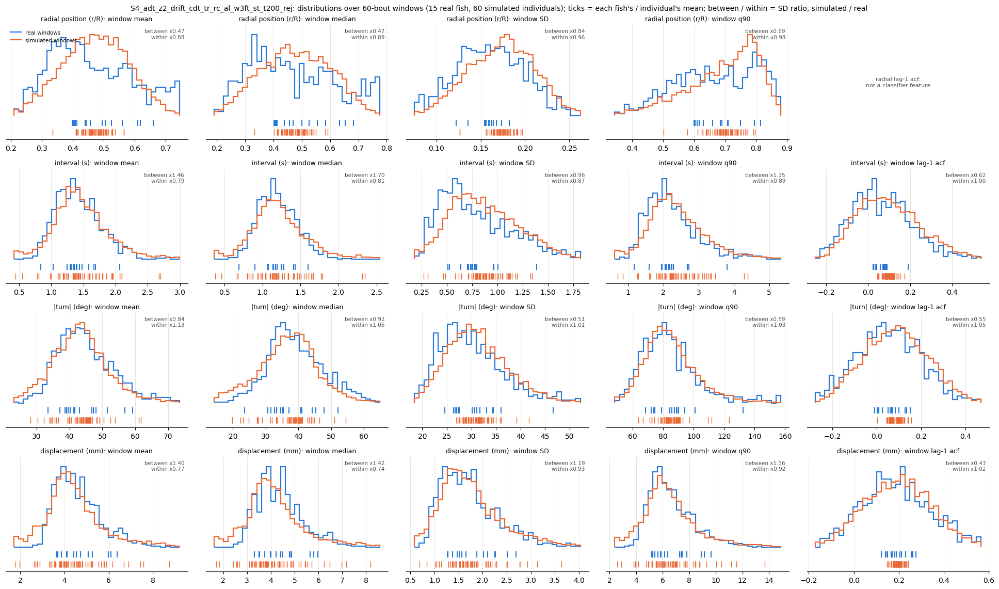

In [ ]:
# Model 47d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47d = window_stats_grid("report_ckpts/M47d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 9.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.22     0.78  0.15  0.89   3.0   5.0                  22.3 +/- 0.9  21.6 +/- 1.1
d2s3.5    0.93     0.76  2.64  3.03  11.0  11.0                  17.4 +/- 0.9  17.8 +/- 0.9
d4s3.5    1.56     0.90  4.68  5.66  19.0  13.0          

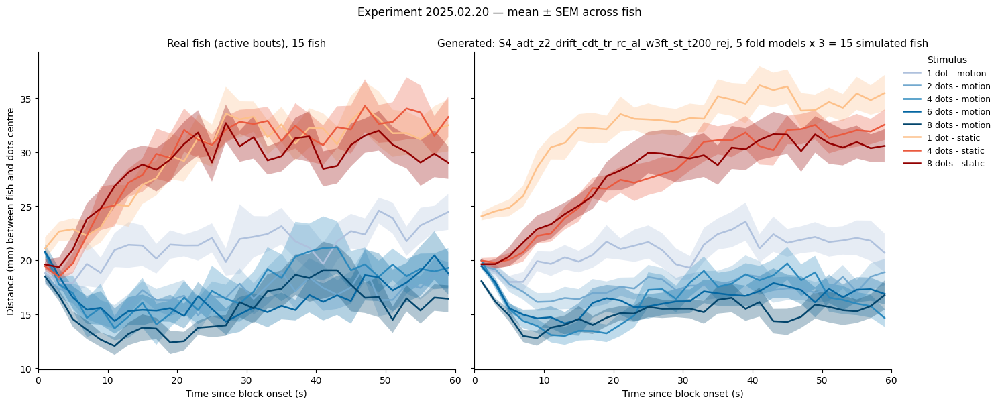

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

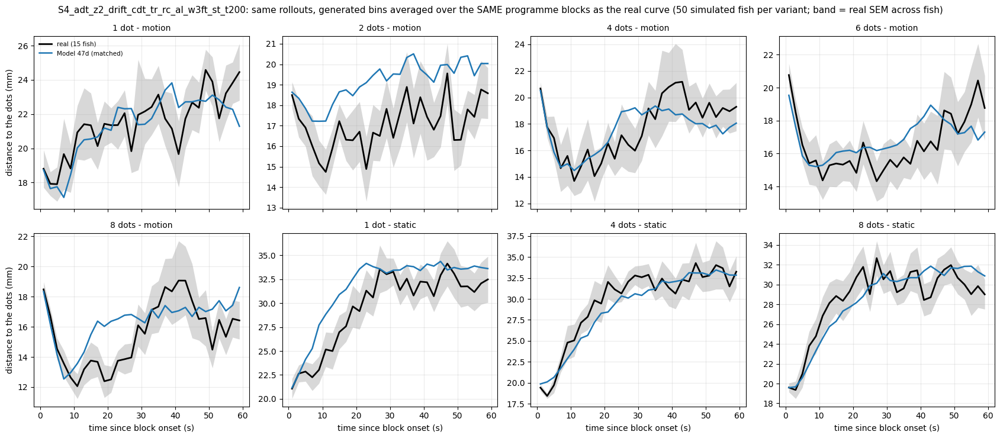

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47d, _ = profile_variants_matched("report_ckpts/M47d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", {"Model 47d": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47d, _ = attraction_table("report_ckpts/M47d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     22.88  22.80      -0.08
d2s3.5       17.39  23.58       6.19                                     19.82  22.65       2.83
d4s3.5       18.74  23.93       5.19                                     18.18  22.76       4.59
d6s3.5       16.69  23.12       6.43                                     17.28  22.59       5.30
d8s3.5       16.41  23.36       6.94                                     17.05  22.76       5.71


In [ ]:
# Model 47d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47d = toward_by_n("report_ckpts/M47d", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"])
print(tow_47d.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
win    N                                                  
0-20 s 1   9.09                                       9.32
       2  13.90                                      11.25
       4  15.73                                      12.88
       6  14.50                                      13.48
       8  16.00                                      15.42
4-20 s 1   6.25                                       7.94
       2  12.27                                      10.20
       4  14.35                                      11.36
       6  12.79                                      12.04
       8  15.11                                      13.24


Model 47d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47d   real gap Model 47d    real gap Model 47d
cond                                                                  
d1s3.5  25.08         -8.56   6.64          3.43    7.55          1.57
d2s3.5  22.99         -4.51  12.94         -2.08   12.56         -2.20
d4s3.5  27.14         -6.33  15.54         -3.45   12.09         -0.86
d6s3.5  32.55        -10.24  13.80         -0.20   15.84         -3.05
d8s3.5  34.04         -8.28  14.45          0.47   13.80          0.03
d1s0     6.82         -6.80   4.22         -3.01    1.96         -0.27
d4s0     4.81         -2.89   1.86          0.33    1.74          1.80
d8s0     5.26         -1.63   2.63          0.56    2.39          2.12

turn size |Δθ| (deg): real f

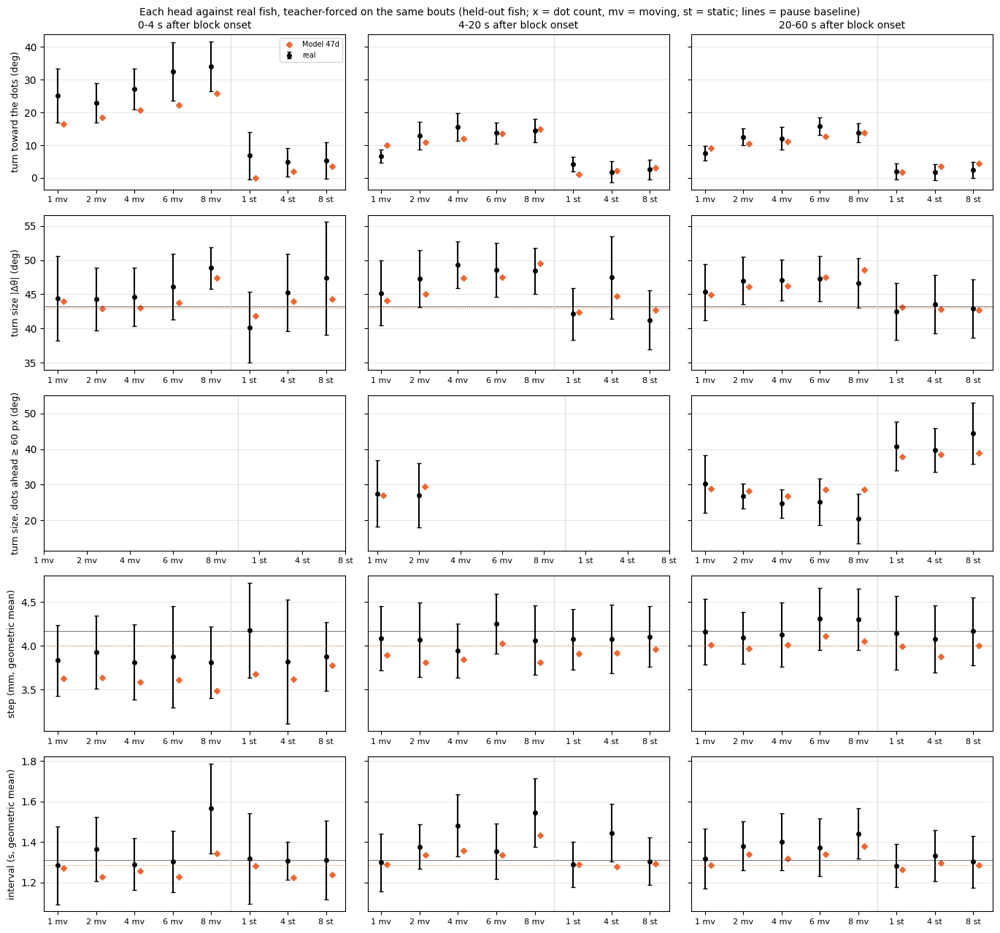

In [ ]:
# Model 47d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47d, hg_47d = head_gaps({"Model 47d": ("report_ckpts/M47d", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200")}, rej=REJ["wall_reject"])

#### D4, tau 200, half strength — seed 101 (key `47i`)

In [ ]:
# Model 47i: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47i/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47i = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47i.index = ["turn", "displacement", "interval", "joint"]
print(lik_47i.round(3).to_string())

turn             7.628
displacement     4.503
interval         1.213
joint           13.344


In [ ]:
# Model 47i: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47i, c2st_47i = run(ckpt_dir="report_ckpts/M47i", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 590s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  8.7686
symbol_js                                                      0.0139
dt_w1                                                          0.3674
dist_w1                                                        3.6197
trans_js                  

In [ ]:
# Model 47i: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47i", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47i = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47i.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.584            0.032      0.508         0.033
matched to the real runs (same bouts, 1:1)            0.572            0.036      0.489         0.038



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.486         0.088        0.041          0.472         0.821
                      median           0.449       0.492         0.098        0.046          0.472         0.831
                      SD               0.159       0.177         0.015        0.010          0.659         0.893
                      q90              0.679       0.728         0.074        0.046

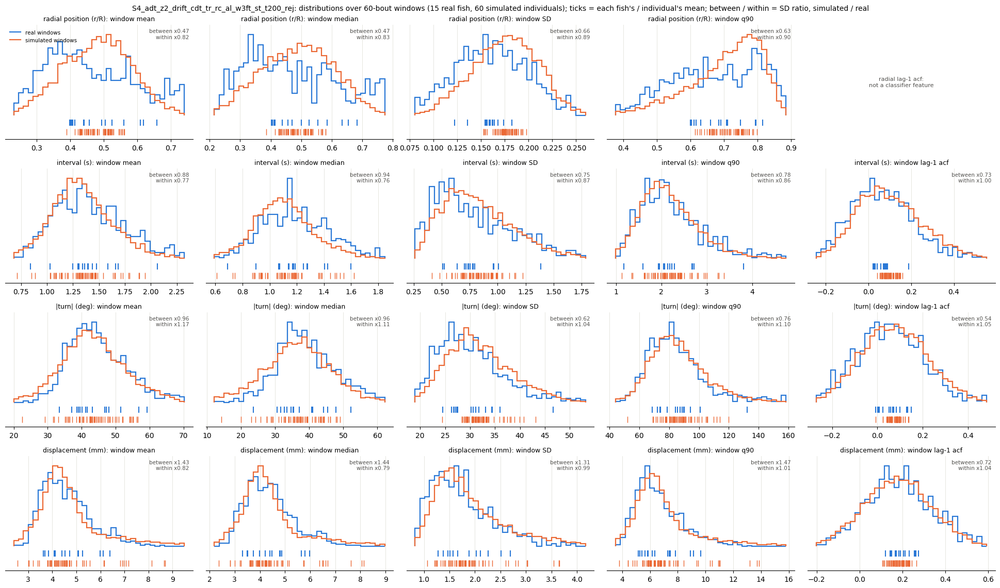

In [ ]:
# Model 47i: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47i = window_stats_grid("report_ckpts/M47i", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 10.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.16     0.74  0.15  0.93   3.0   5.0                  22.3 +/- 0.9  21.4 +/- 1.0
d2s3.5    1.76     1.35  2.64  2.59  11.0  19.0                  17.4 +/- 0.9  19.6 +/- 0.9
d4s3.5    0.96     0.59  4.68  3.93  19.0   9.0         

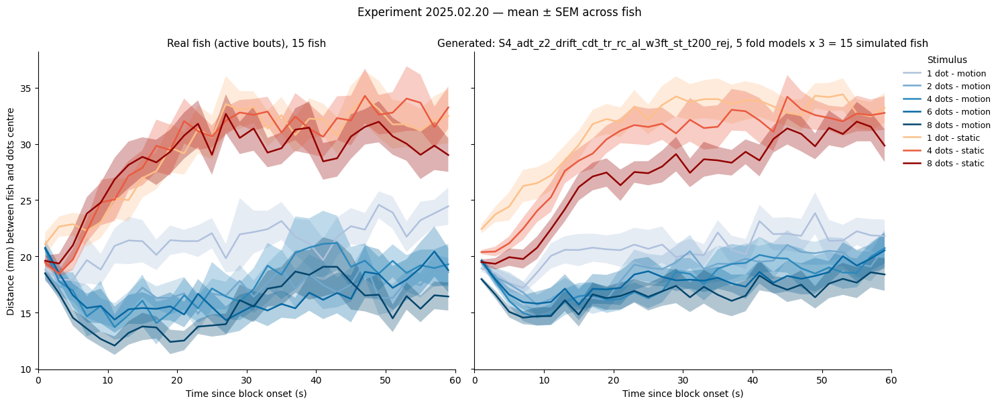

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47i: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47i", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

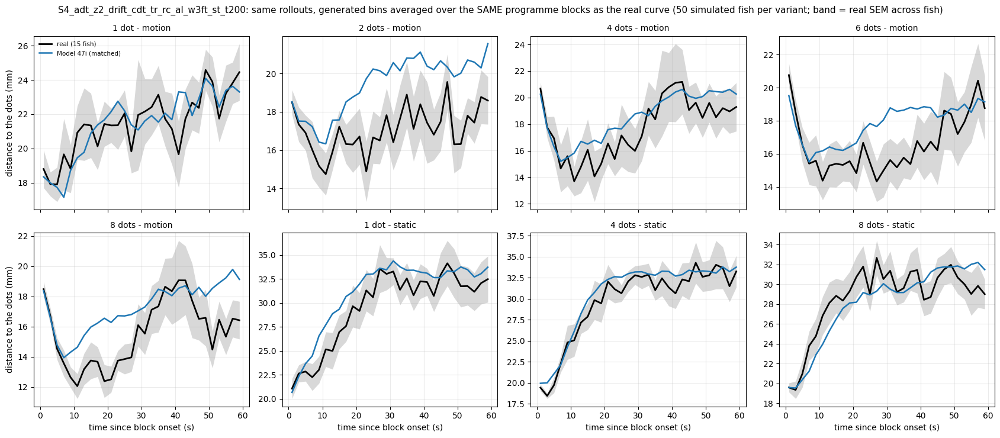

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47i: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47i, _ = profile_variants_matched("report_ckpts/M47i", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", {"Model 47i": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47i: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47i, _ = attraction_table("report_ckpts/M47i", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     21.88  23.27       1.39
d2s3.5       17.39  23.58       6.19                                     20.34  23.04       2.70
d4s3.5       18.74  23.93       5.19                                     20.10  22.93       2.83
d6s3.5       16.69  23.12       6.43                                     18.98  23.08       4.11
d8s3.5       16.41  23.36       6.94                                     17.69  22.97       5.28


In [ ]:
# Model 47i: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47i = toward_by_n("report_ckpts/M47i", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"])
print(tow_47i.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
win    N                                                  
0-20 s 1   9.09                                       9.94
       2  13.90                                      12.08
       4  15.73                                      13.06
       6  14.50                                      14.19
       8  16.00                                      16.67
4-20 s 1   6.25                                       8.72
       2  12.27                                      11.12
       4  14.35                                      11.47
       6  12.79                                      12.45
       8  15.11                                      14.69


Model 47i: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47i   real gap Model 47i    real gap Model 47i
cond                                                                  
d1s3.5  25.08         -9.08   6.64          4.08    7.55          2.06
d2s3.5  22.99         -4.76  12.94         -0.83   12.56         -1.79
d4s3.5  27.14         -5.48  15.54         -3.94   12.09         -0.40
d6s3.5  32.55        -10.89  13.80          1.12   15.84         -2.48
d8s3.5  34.04         -8.86  14.45          1.48   13.80          0.80
d1s0     6.82         -6.08   4.22         -3.18    1.96         -0.12
d4s0     4.81         -1.97   1.86          0.11    1.74          1.77
d8s0     5.26         -0.31   2.63          0.30    2.39          1.95

turn size |Δθ| (deg): real f

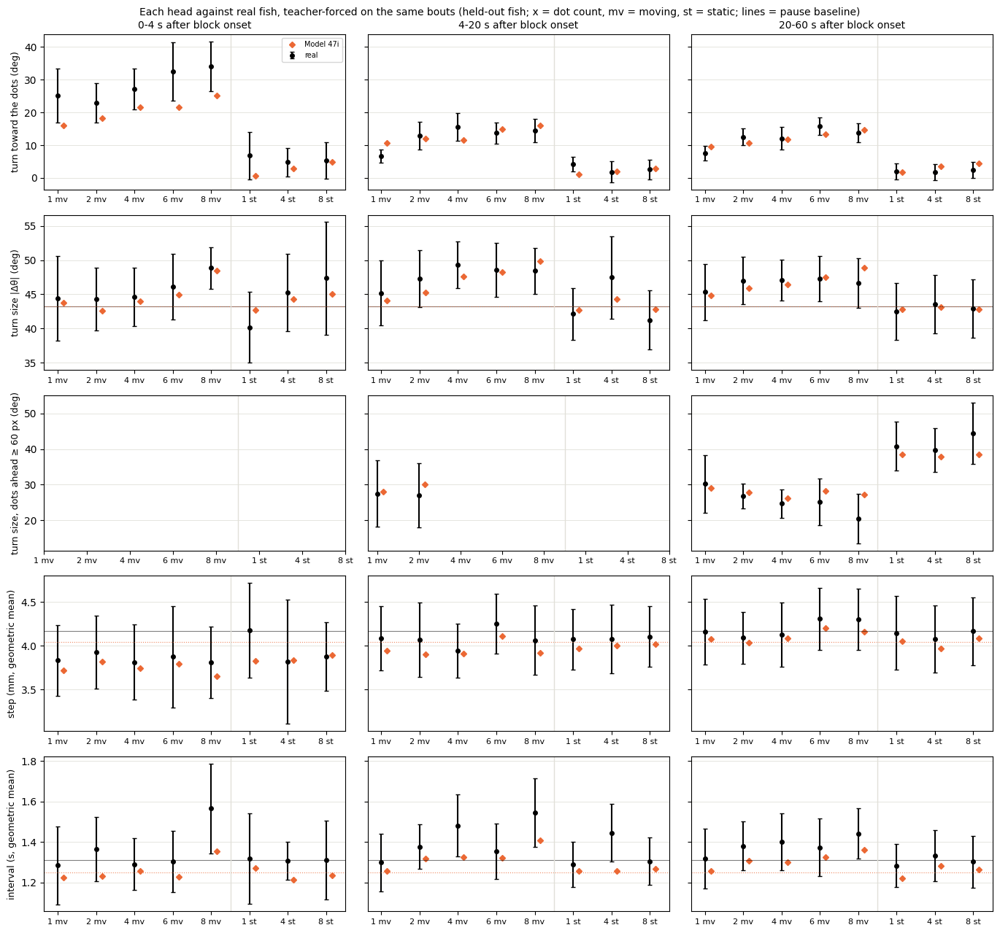

In [ ]:
# Model 47i: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47i, hg_47i = head_gaps({"Model 47i": ("report_ckpts/M47i", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200")}, rej=REJ["wall_reject"])

<a id="m47e"></a>
### D4, tau 200, full strength

**Change:** 37a | 37b, fixed full strength



#### D4, tau 200, full strength — seed 0 (key `47e`)

In [ ]:
# Model 47e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47e = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47e.index = ["turn", "displacement", "interval", "joint"]
print(lik_47e.round(3).to_string())

turn             7.626
displacement     4.515
interval         1.205
joint           13.347


In [ ]:
# Model 47e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47e, c2st_47e = run(ckpt_dir="report_ckpts/M47e", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 835s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  9.0232
symbol_js                                                      0.0145
dt_w1                                                          0.4311
dist_w1                                                        4.8146
trans_js                  

In [ ]:
# Model 47e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.696            0.019      0.629         0.024
matched to the real runs (same bouts, 1:1)            0.690            0.018      0.622         0.025



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.475         0.088        0.046          0.523         0.873
                      median           0.449       0.481         0.098        0.051          0.525         0.877
                      SD               0.159       0.175         0.015        0.013          0.825         0.956
                      q90              0.679       0.719         0.074        0.055

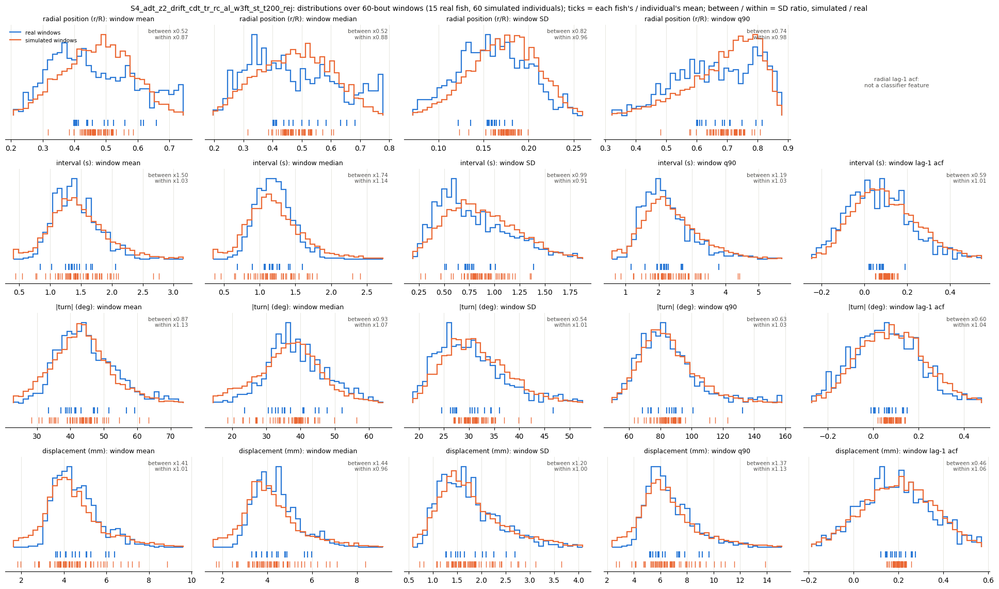

In [ ]:
# Model 47e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47e = window_stats_grid("report_ckpts/M47e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 10.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.16     0.77  0.15  0.71   3.0   5.0                  22.3 +/- 0.9  21.6 +/- 1.6
d2s3.5    0.91     0.73  2.64  3.11  11.0  11.0                  17.4 +/- 0.9  17.6 +/- 1.2
d4s3.5    1.55     0.87  4.68  5.21  19.0   9.0         

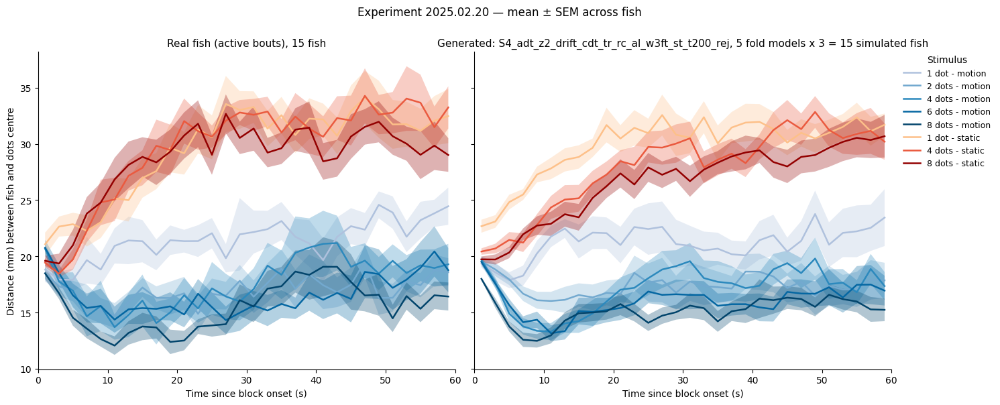

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

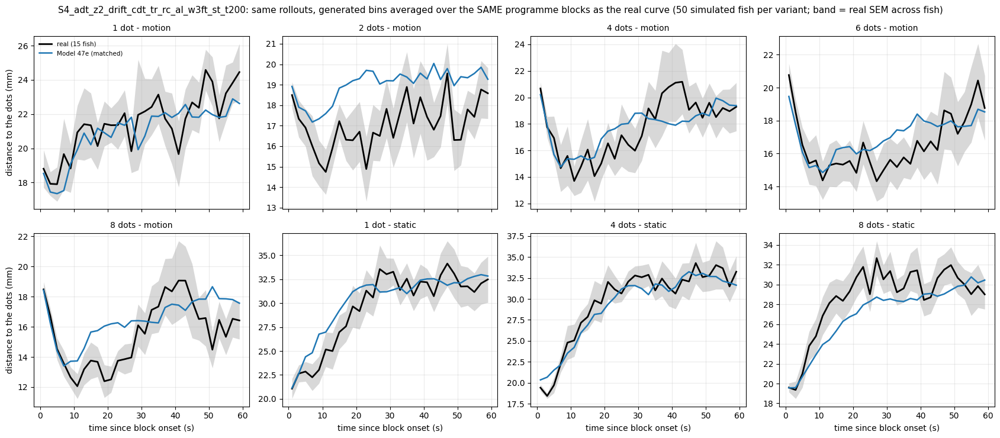

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47e, _ = profile_variants_matched("report_ckpts/M47e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", {"Model 47e": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47e, _ = attraction_table("report_ckpts/M47e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     22.00  22.64       0.63
d2s3.5       17.39  23.58       6.19                                     18.98  22.77       3.79
d4s3.5       18.74  23.93       5.19                                     18.83  22.82       3.99
d6s3.5       16.69  23.12       6.43                                     17.75  22.86       5.11
d8s3.5       16.41  23.36       6.94                                     17.08  22.82       5.74


In [ ]:
# Model 47e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47e = toward_by_n("report_ckpts/M47e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"])
print(tow_47e.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
win    N                                                  
0-20 s 1   9.09                                       9.32
       2  13.90                                      11.25
       4  15.73                                      12.88
       6  14.50                                      13.48
       8  16.00                                      15.42
4-20 s 1   6.25                                       7.94
       2  12.27                                      10.20
       4  14.35                                      11.36
       6  12.79                                      12.04
       8  15.11                                      13.24


Model 47e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47e   real gap Model 47e    real gap Model 47e
cond                                                                  
d1s3.5  25.08         -8.56   6.64          3.43    7.55          1.57
d2s3.5  22.99         -4.51  12.94         -2.08   12.56         -2.20
d4s3.5  27.14         -6.33  15.54         -3.45   12.09         -0.86
d6s3.5  32.55        -10.24  13.80         -0.20   15.84         -3.05
d8s3.5  34.04         -8.28  14.45          0.47   13.80          0.03
d1s0     6.82         -6.80   4.22         -3.01    1.96         -0.27
d4s0     4.81         -2.89   1.86          0.33    1.74          1.80
d8s0     5.26         -1.63   2.63          0.56    2.39          2.12

turn size |Δθ| (deg): real f

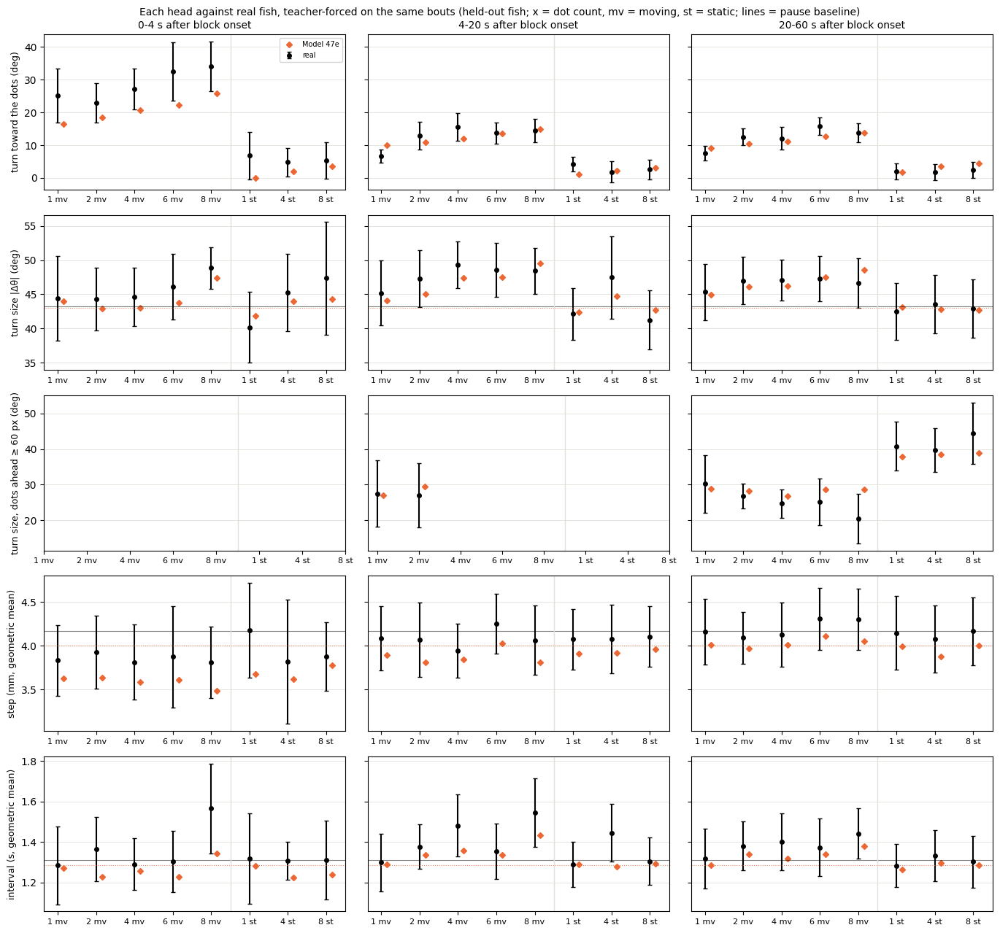

In [ ]:
# Model 47e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47e, hg_47e = head_gaps({"Model 47e": ("report_ckpts/M47e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200")}, rej=REJ["wall_reject"])

#### D4, tau 200, full strength — seed 101 (key `47j`)

In [ ]:
# Model 47j: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M47j/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_47j = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_47j.index = ["turn", "displacement", "interval", "joint"]
print(lik_47j.round(3).to_string())

turn             7.628
displacement     4.503
interval         1.213
joint           13.344


In [ ]:
# Model 47j: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_47j, c2st_47j = run(ckpt_dir="report_ckpts/M47j", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200.csv  (15 rows) in 597s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_rej
abs_dtheta_w1                                                  8.7447
symbol_js                                                      0.0140
dt_w1                                                          0.3664
dist_w1                                                        3.6788
trans_js                  

In [ ]:
# Model 47j: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M47j", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_47j = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_47j.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.604            0.027      0.507         0.022
matched to the real runs (same bouts, 1:1)            0.595            0.029      0.499         0.023



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.485         0.088        0.042          0.476         0.836
                      median           0.449       0.490         0.098        0.047          0.482         0.855
                      SD               0.159       0.176         0.015        0.010          0.623         0.925
                      q90              0.679       0.729         0.074        0.047

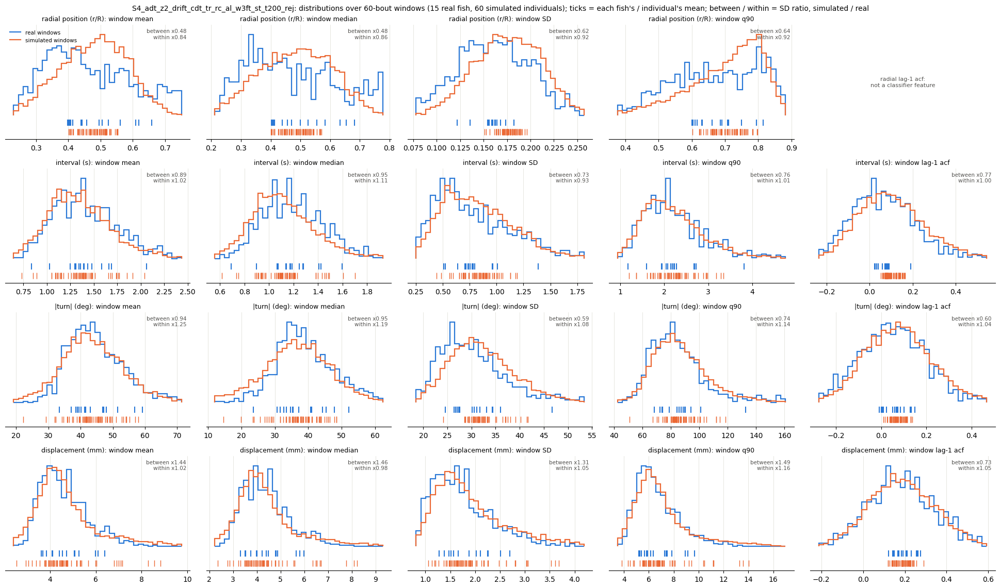

In [ ]:
# Model 47j: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_47j = window_stats_grid("report_ckpts/M47j", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200_fold4.pt: 3 rollouts
dropped 10.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.18     0.78  0.15  0.34   3.0   5.0                  22.3 +/- 0.9  22.9 +/- 0.6
d2s3.5    1.66     1.29  2.64  2.62  11.0  11.0                  17.4 +/- 0.9  18.9 +/- 0.7
d4s3.5    0.95     0.60  4.68  4.03  19.0  19.0         

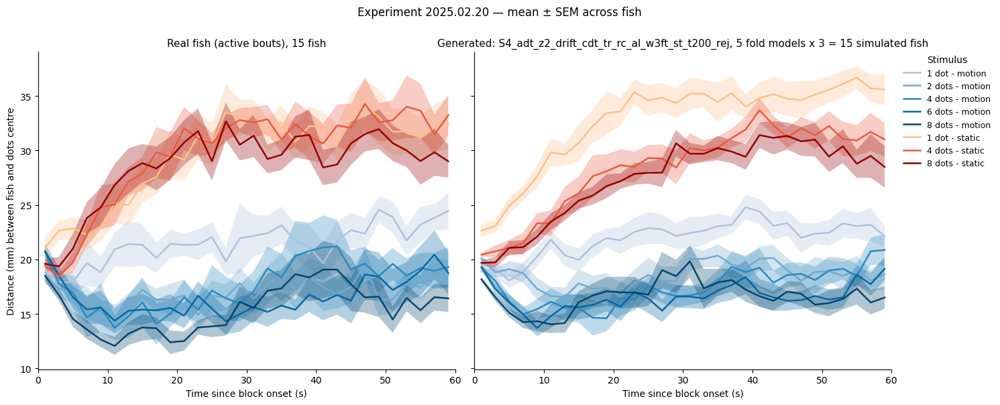

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47j: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M47j", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

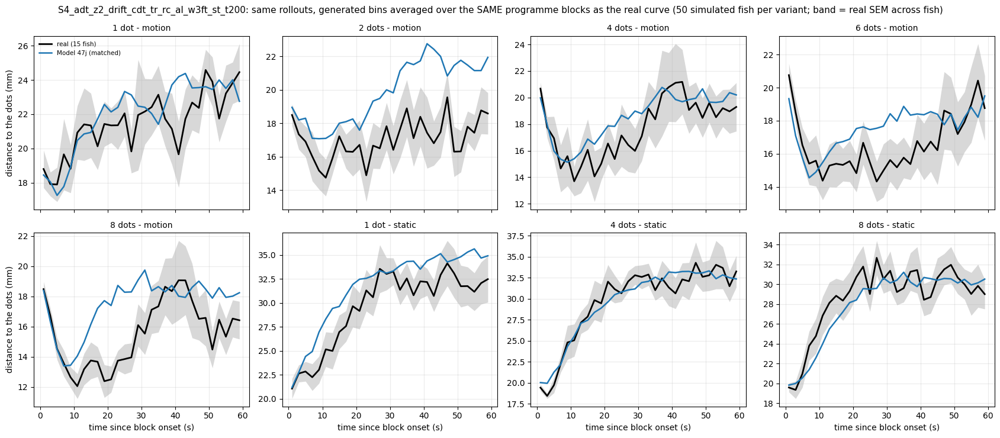

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47j: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_47j, _ = profile_variants_matched("report_ckpts/M47j", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200", {"Model 47j": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 47j: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_47j, _ = attraction_table("report_ckpts/M47j", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200                  
           plateau   null attraction                                   plateau   null attraction
cond_label                                                                                      
d1s3.5       22.41  23.57       1.16                                     22.88  23.10       0.22
d2s3.5       17.39  23.58       6.19                                     19.91  22.72       2.81
d4s3.5       18.74  23.93       5.19                                     19.48  23.06       3.58
d6s3.5       16.69  23.12       6.43                                     18.79  22.83       4.04
d8s3.5       16.41  23.36       6.94                                     19.04  22.96       3.92


In [ ]:
# Model 47j: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_47j = toward_by_n("report_ckpts/M47j", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200"], rej=REJ["wall_reject"])
print(tow_47j.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200
win    N                                                  
0-20 s 1   9.09                                       9.94
       2  13.90                                      12.08
       4  15.73                                      13.06
       6  14.50                                      14.19
       8  16.00                                      16.67
4-20 s 1   6.25                                       8.72
       2  12.27                                      11.12
       4  14.35                                      11.47
       6  12.79                                      12.45
       8  15.11                                      14.69


Model 47j: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 47j   real gap Model 47j    real gap Model 47j
cond                                                                  
d1s3.5  25.08         -9.08   6.64          4.08    7.55          2.06
d2s3.5  22.99         -4.76  12.94         -0.83   12.56         -1.79
d4s3.5  27.14         -5.48  15.54         -3.94   12.09         -0.40
d6s3.5  32.55        -10.89  13.80          1.12   15.84         -2.48
d8s3.5  34.04         -8.86  14.45          1.48   13.80          0.80
d1s0     6.82         -6.08   4.22         -3.18    1.96         -0.12
d4s0     4.81         -1.97   1.86          0.11    1.74          1.77
d8s0     5.26         -0.31   2.63          0.30    2.39          1.95

turn size |Δθ| (deg): real f

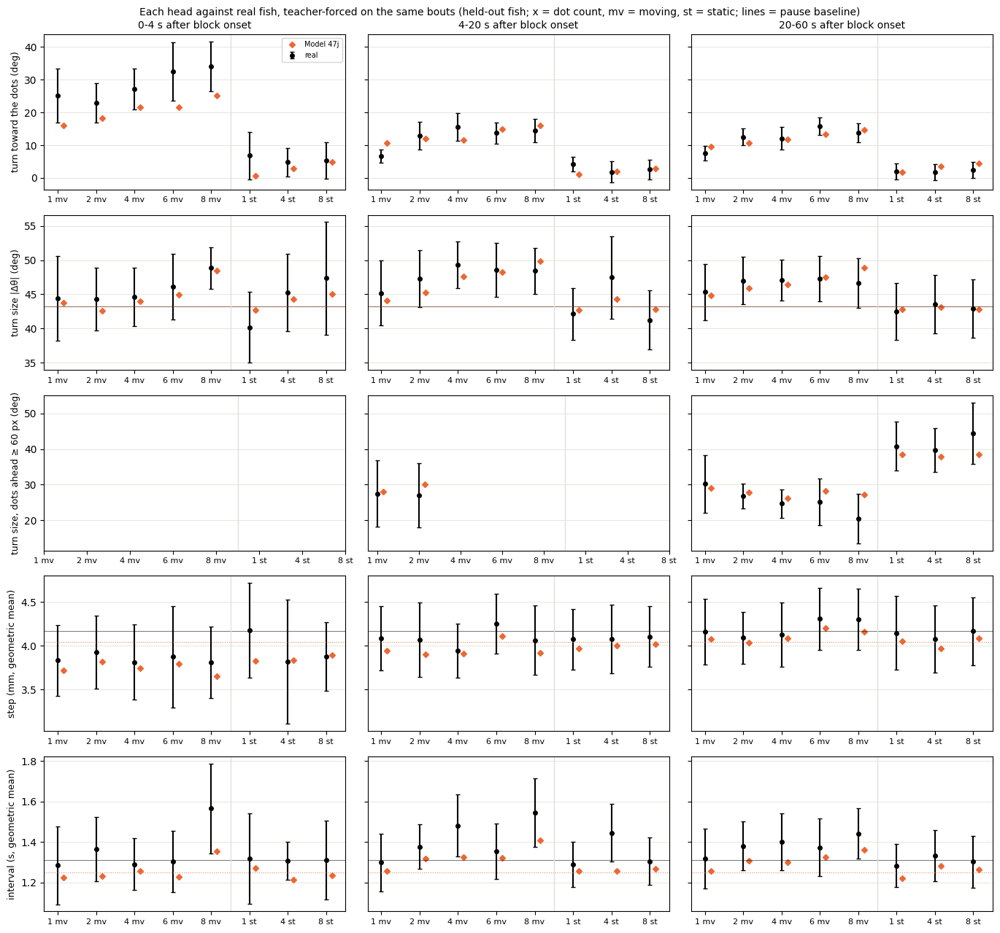

In [ ]:
# Model 47j: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_47j, hg_47j = head_gaps({"Model 47j": ("report_ckpts/M47j", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_t200")}, rej=REJ["wall_reject"])

<a id="m48a"></a>
### F on the strength-0 D4

**Change:** 47a | 47f + the profile correction (fitted without drift)



#### F on the strength-0 D4 — seed 0 (key `48a`)

In [ ]:
# Model 48a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M48a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_48a = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_48a.index = ["turn", "displacement", "interval", "joint"]
print(lik_48a.round(3).to_string())

turn             7.628
displacement     4.513
interval         1.203
joint           13.344


In [ ]:
# Model 48a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_48a, c2st_48a = run(ckpt_dir="report_ckpts/M48a", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 266s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                         8.7359
symbol_js                                                             0.0132
dt_w1                                                                 0.4371
dist_w1                                 

In [ ]:
# Model 48a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M48a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_48a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_48a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.607            0.013      0.532         0.018
matched to the real runs (same bouts, 1:1)            0.599            0.012      0.528         0.018



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.464         0.088        0.040          0.462         0.890
                      median           0.449       0.467         0.098        0.044          0.453         0.891
                      SD               0.159       0.173         0.015        0.014          0.928         0.954
                      q90              0.679       0.710         0.074        0.054

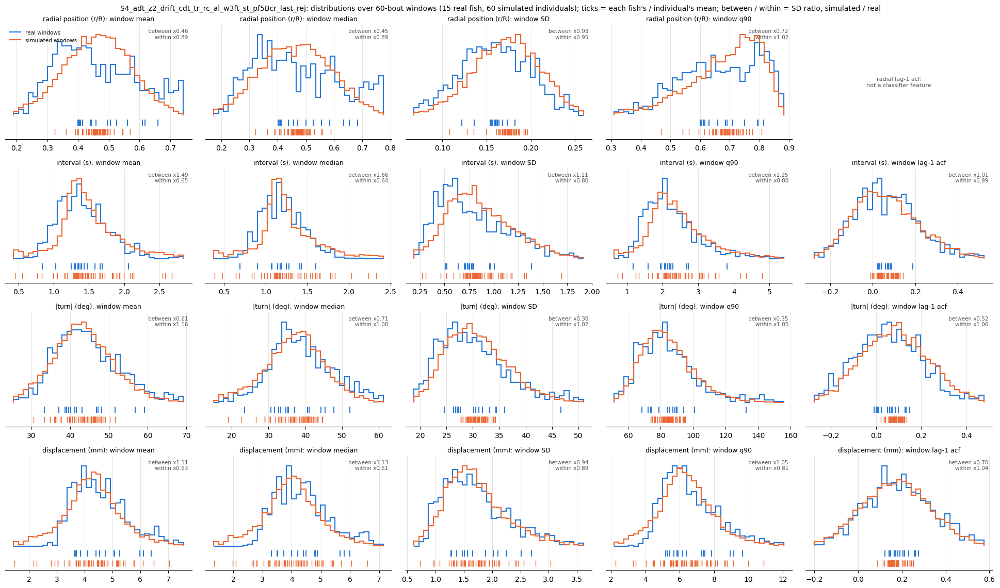

In [ ]:
# Model 48a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_48a = window_stats_grid("report_ckpts/M48a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.09     0.76  0.15  0.19   3.0   5.0                  22.3 +/- 0.9  21.7 +/- 0.9
d2s3.5    1.25     0.96  2.64  3.34  11.0  11.0                  17.4 +/- 0.9  18.5 +/- 1.2
d4s3.5    1.00     0.

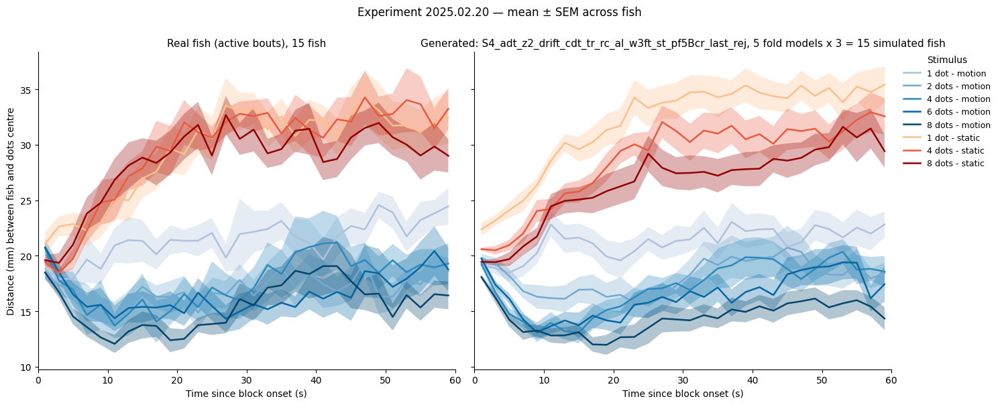

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 48a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M48a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

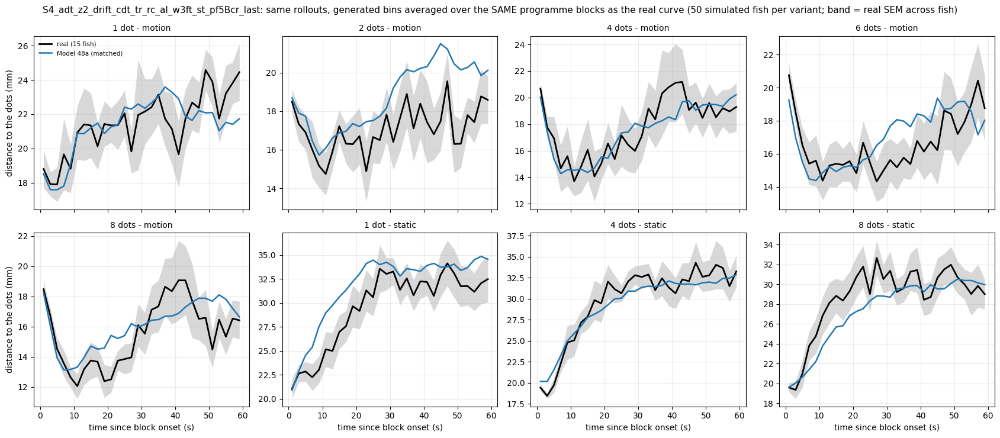

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 48a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_48a, _ = profile_variants_matched("report_ckpts/M48a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", {"Model 48a": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 48a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_48a, _ = attraction_table("report_ckpts/M48a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                          plateau   null attraction
cond_label                                                                                             
d1s3.5       22.41  23.57       1.16                                            22.56  22.56       0.00
d2s3.5       17.39  23.58       6.19                                            19.50  22.44       2.94
d4s3.5       18.74  23.93       5.19                                            18.30  22.41       4.11
d6s3.5       16.69  23.12       6.43                                            17.81  22.85       5.03
d8s3.5       16.41  23.36       6.94                                

In [ ]:
# Model 48a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_48a = toward_by_n("report_ckpts/M48a", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_48a.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
win    N                                                         
0-20 s 1   9.09                                              9.59
       2  13.90                                             13.72
       4  15.73                                             15.56
       6  14.50                                             16.43
       8  16.00                                             19.18
4-20 s 1   6.25                                              8.44
       2  12.27                                             12.87
       4  14.35                                             14.34
       6  12.79                                             14.95
       8  15.11                                             17.38


Model 48a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 48a   real gap Model 48a    real gap Model 48a
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.93    7.55          1.91
d2s3.5  22.99         -2.59  12.94          0.32   12.56         -1.91
d4s3.5  27.14         -4.80  15.54         -0.67   12.09         -0.47
d6s3.5  32.55         -7.49  13.80          2.85   15.84         -2.78
d8s3.5  34.04         -6.28  14.45          4.05   13.80          0.37
d1s0     6.82         -6.47   4.22         -3.10    1.96          0.12
d4s0     4.81         -2.04   1.86          0.95    1.74          1.96
d8s0     5.26         -0.72   2.63          1.08    2.39          2.55

turn size |Δθ| (deg): real f

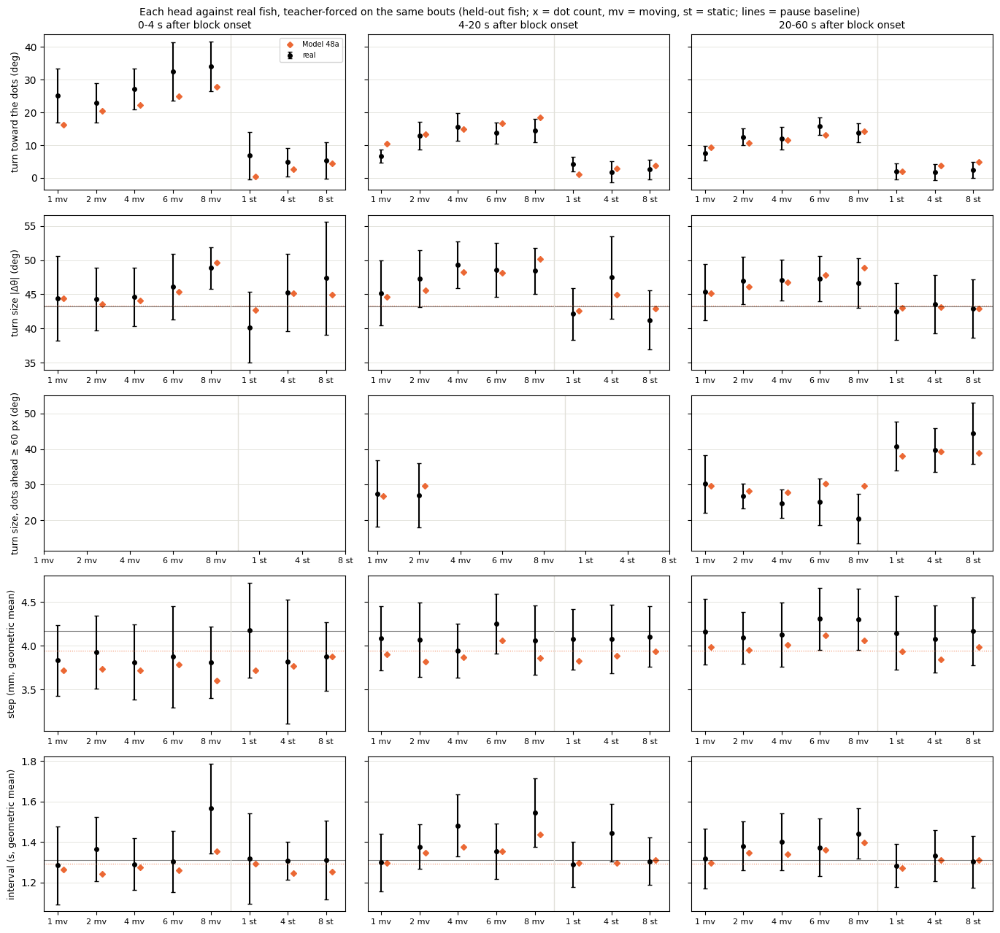

In [ ]:
# Model 48a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_48a, hg_48a = head_gaps({"Model 48a": ("report_ckpts/M48a", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last")}, rej=REJ["wall_reject"])

#### F on the strength-0 D4 — seed 101 (key `48b`)

In [ ]:
# Model 48b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M48b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_48b = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_48b.index = ["turn", "displacement", "interval", "joint"]
print(lik_48b.round(3).to_string())

turn             7.630
displacement     4.520
interval         1.207
joint           13.357


In [ ]:
# Model 48b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_48b, c2st_48b = run(ckpt_dir="report_ckpts/M48b", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 258s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                         8.2673
symbol_js                                                             0.0123
dt_w1                                                                 0.3827
dist_w1                                 

In [ ]:
# Model 48b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M48b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_48b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_48b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.602            0.029      0.535         0.028
matched to the real runs (same bouts, 1:1)            0.593            0.030      0.522         0.030



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.474         0.088        0.035          0.402         0.819
                      median           0.449       0.479         0.098        0.039          0.401         0.838
                      SD               0.159       0.176         0.015        0.010          0.650         0.908
                      q90              0.679       0.721         0.074        0.041

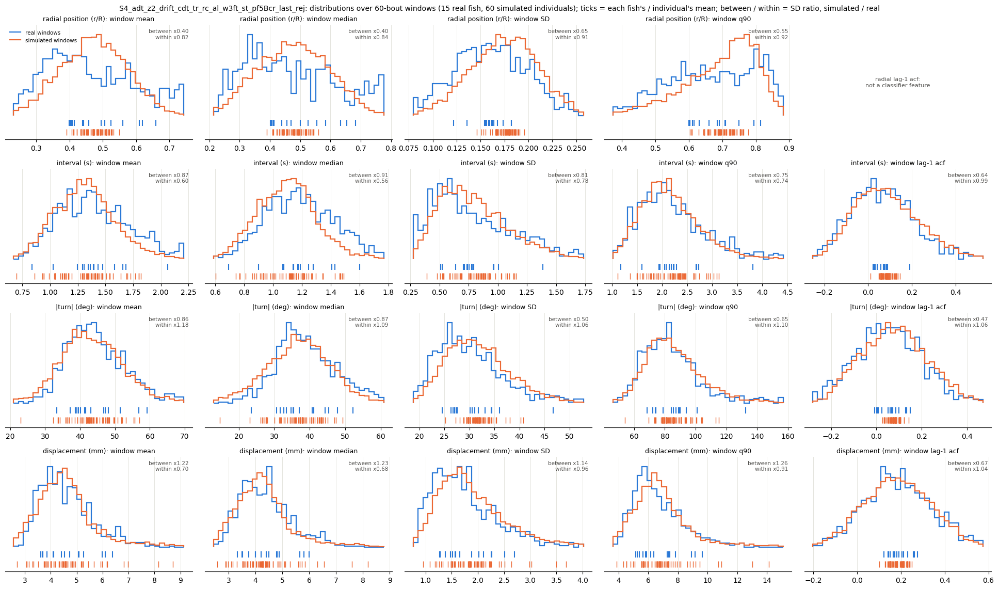

In [ ]:
# Model 48b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_48b = window_stats_grid("report_ckpts/M48b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.56     1.06  0.15  1.18   3.0   7.0                  22.3 +/- 0.9  23.9 +/- 1.0
d2s3.5    1.88     1.45  2.64  3.58  11.0  19.0                  17.4 +/- 0.9  19.7 +/- 1.1
d4s3.5    1.38     0.

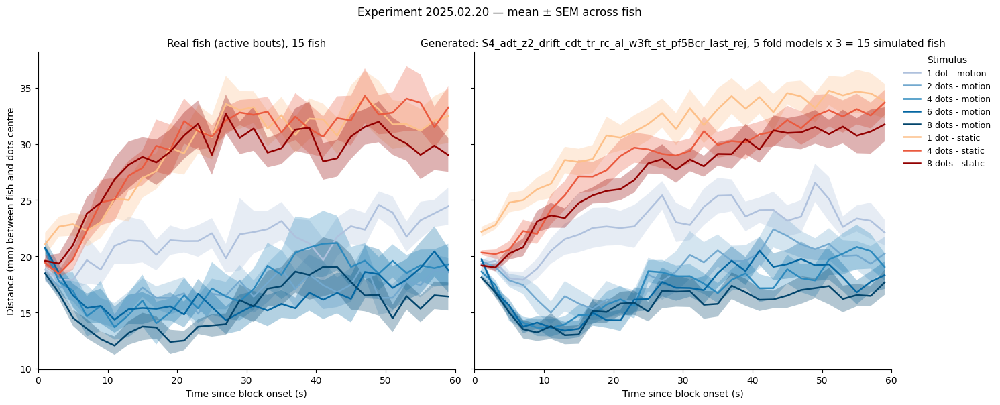

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 48b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M48b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

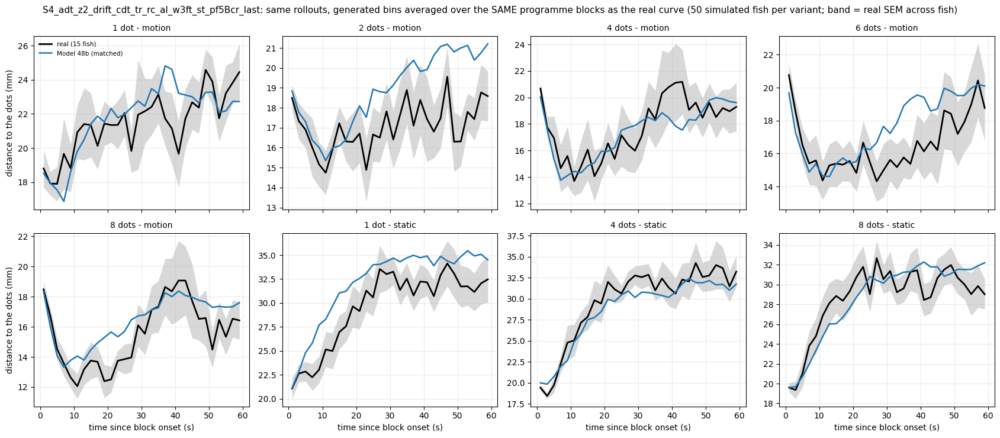

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 48b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_48b, _ = profile_variants_matched("report_ckpts/M48b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", {"Model 48b": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 48b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_48b, _ = attraction_table("report_ckpts/M48b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                          plateau   null attraction
cond_label                                                                                             
d1s3.5       22.41  23.57       1.16                                            23.28  22.62      -0.66
d2s3.5       17.39  23.58       6.19                                            19.36  22.56       3.19
d4s3.5       18.74  23.93       5.19                                            18.14  22.62       4.47
d6s3.5       16.69  23.12       6.43                                            18.36  22.68       4.32
d8s3.5       16.41  23.36       6.94                                

In [ ]:
# Model 48b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_48b = toward_by_n("report_ckpts/M48b", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_48b.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
win    N                                                         
0-20 s 1   9.09                                              9.97
       2  13.90                                             13.68
       4  15.73                                             15.72
       6  14.50                                             16.38
       8  16.00                                             20.62
4-20 s 1   6.25                                              8.80
       2  12.27                                             12.85
       4  14.35                                             14.40
       6  12.79                                             14.71
       8  15.11                                             19.04


Model 48b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 48b   real gap Model 48b    real gap Model 48b
cond                                                                  
d1s3.5  25.08         -9.06   6.64          4.12    7.55          2.22
d2s3.5  22.99         -2.46  12.94          0.82   12.56         -1.41
d4s3.5  27.14         -3.60  15.54         -0.99   12.09         -0.27
d6s3.5  32.55         -8.53  13.80          3.85   15.84         -2.26
d8s3.5  34.04         -5.08  14.45          5.46   13.80          1.30
d1s0     6.82         -5.60   4.22         -2.98    1.96          0.07
d4s0     4.81         -2.53   1.86          0.11    1.74          1.83
d8s0     5.26         -1.37   2.63         -0.19    2.39          1.67

turn size |Δθ| (deg): real f

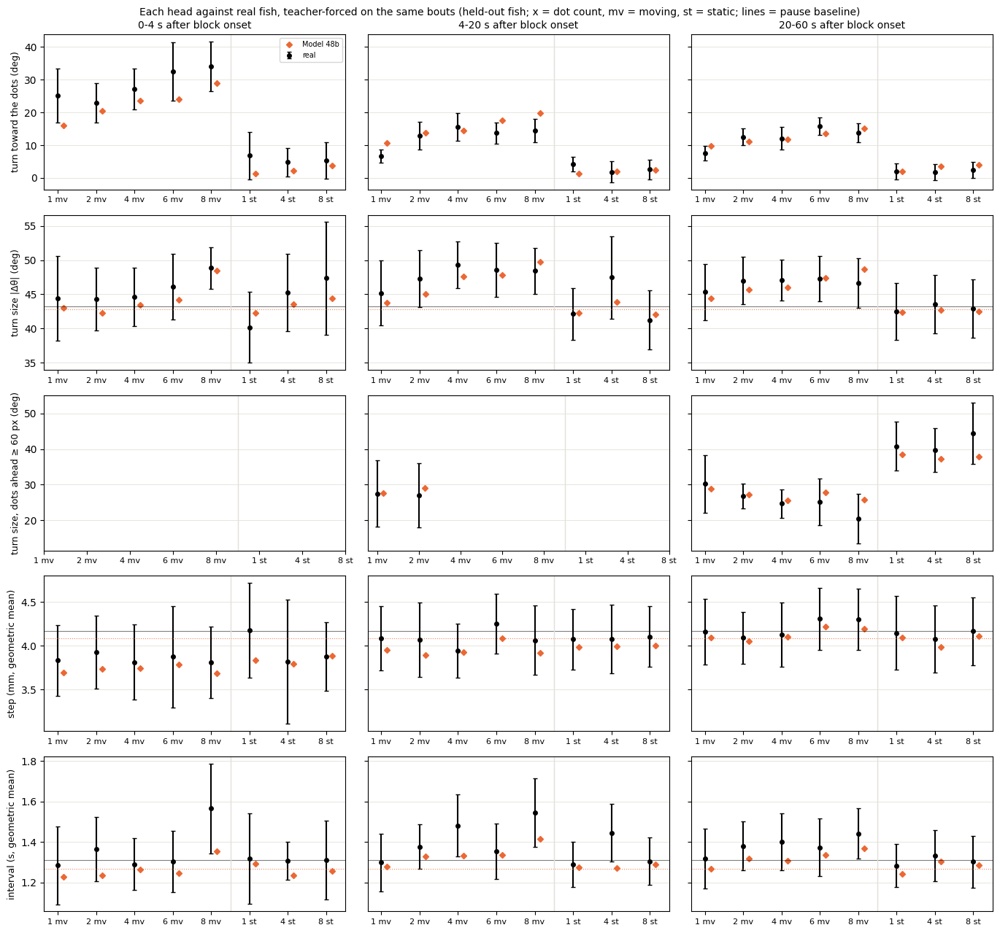

In [ ]:
# Model 48b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_48b, hg_48b = head_gaps({"Model 48b": ("report_ckpts/M48b", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="app"></a>
## Appendix — the correction on other bases

The same correction (pf-B, 8 numbers, 100 steps)
on 26e, on Model 27 and always-on on Model 17 (seed 0). It never changes AUC. On 26e it does nothing measurable and the
static error gets worse, which is why the main line ends at 26e.

<a id="m28b"></a>
### 28a / 28b — 26e + correction, 20 s cut-off

**Change:** keep-best step / final step

Null: dip 3.70 → 3.91 / 3.79, static error 0.80 → 1.02 / 1.22.

#### 28a / 28b — 26e + correction, 20 s cut-off — seed 0 (key `28a`)

In [ ]:
# Model 28a: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M28a/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_28a = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_28a.index = ["turn", "displacement", "interval", "joint"]
print(lik_28a.round(3).to_string())

turn             7.665
displacement     4.505
interval         1.215
joint           13.385


In [ ]:
# Model 28a: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_28a, c2st_28a = run(ckpt_dir="report_ckpts/M28a", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr.csv  (15 rows) in 950s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_rej
abs_dtheta_w1                                            8.5148
symbol_js                                                0.0119
dt_w1                                                    0.4108
dist_w1                                                  3.6998
trans_js                                                 0.0133
acf_l2          

In [ ]:
# Model 28a: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M28a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_28a = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_28a.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.672            0.015      0.609         0.016
matched to the real runs (same bouts, 1:1)            0.669            0.019      0.599         0.018



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.454         0.088        0.032          0.360         0.938
                      median           0.449       0.451         0.098        0.035          0.355         0.955
                      SD               0.159       0.179         0.015        0.012          0.767         1.014
                      q90              0.679       0.718         0.074        0.043

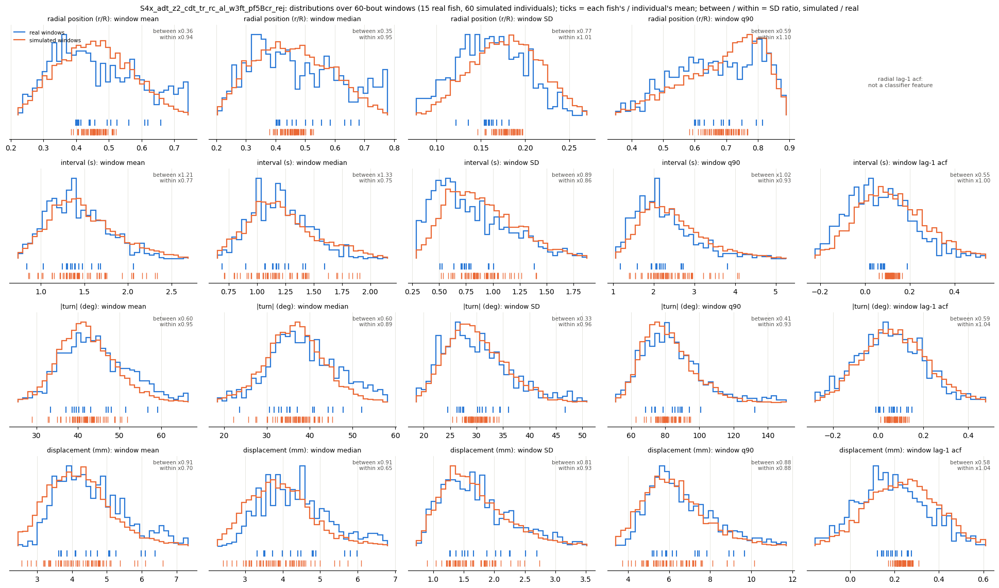

In [ ]:
# Model 28a: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_28a = window_stats_grid("report_ckpts/M28a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_fold4.pt: 3 rollouts
dropped 12.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.44     0.97  0.15   1.3   3.0   7.0                  22.3 +/- 0.9  21.4 +/- 1.1
d2s3.5    1.72     1.34  2.64  3.65  11.0   9.0                  17.4 +/- 0.9  18.9 +/- 0.8
d4s3.5    1.15     0.70  4.68  4.88  19.0  11.0                  18.7 +/- 1.7  17.8 +/

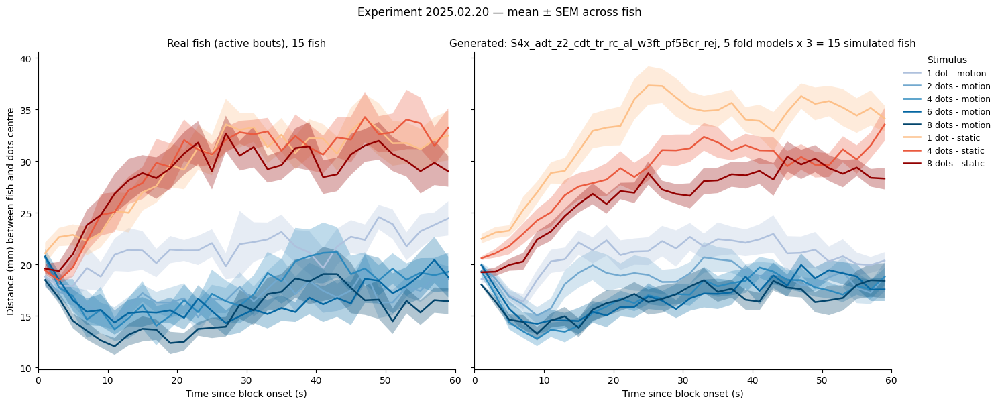

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28a: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M28a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

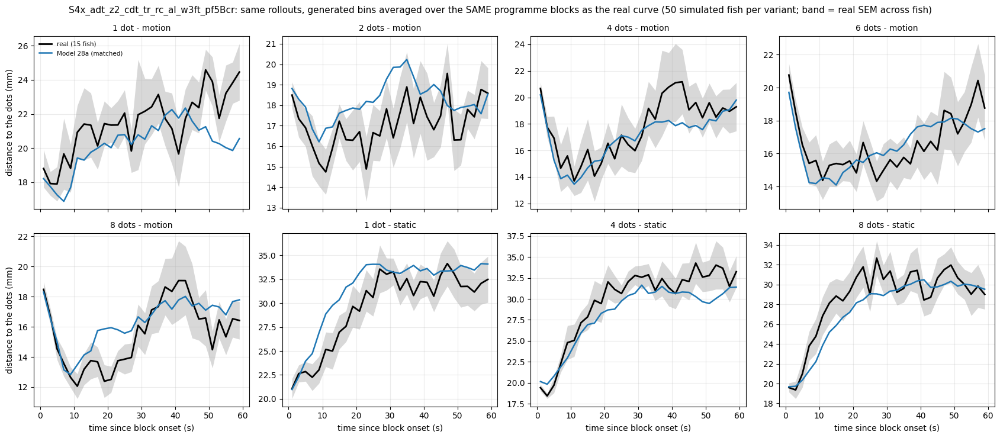

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28a: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_28a, _ = profile_variants_matched("report_ckpts/M28a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr", {"Model 28a": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28a: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_28a, _ = attraction_table("report_ckpts/M28a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr                  
           plateau   null attraction                             plateau   null attraction
cond_label                                                                                
d1s3.5       22.41  23.57       1.16                               20.74  22.04       1.30
d2s3.5       17.39  23.58       6.19                               18.64  22.22       3.58
d4s3.5       18.74  23.93       5.19                               17.63  22.38       4.74
d6s3.5       16.69  23.12       6.43                               16.62  22.07       5.45
d8s3.5       16.41  23.36       6.94                               17.07  22.09       5.02


In [ ]:
# Model 28a: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_28a = toward_by_n("report_ckpts/M28a", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr"], rej=REJ["wall_reject"])
print(tow_28a.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr
win    N                                            
0-20 s 1   9.09                                 9.96
       2  13.90                                12.39
       4  15.73                                15.09
       6  14.50                                15.31
       8  16.00                                18.22
4-20 s 1   6.25                                 9.04
       2  12.27                                11.72
       4  14.35                                13.95
       6  12.79                                14.18
       8  15.11                                16.77


Model 28a: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 28a   real gap Model 28a    real gap Model 28a
cond                                                                  
d1s3.5  25.08         -9.22   6.64          3.63    7.55          2.36
d2s3.5  22.99         -4.63  12.94         -0.60   12.56         -1.10
d4s3.5  27.14         -5.28  15.54         -0.97   12.09          0.50
d6s3.5  32.55        -11.05  13.80          2.23   15.84         -2.00
d8s3.5  34.04         -9.02  14.45          3.27   13.80          1.29
d1s0     6.82         -5.38   4.22         -3.32    1.96          0.42
d4s0     4.81         -0.92   1.86          2.46    1.74          2.45
d8s0     5.26         -1.63   2.63          1.50    2.39          2.81

turn size |Δθ| (deg): real f

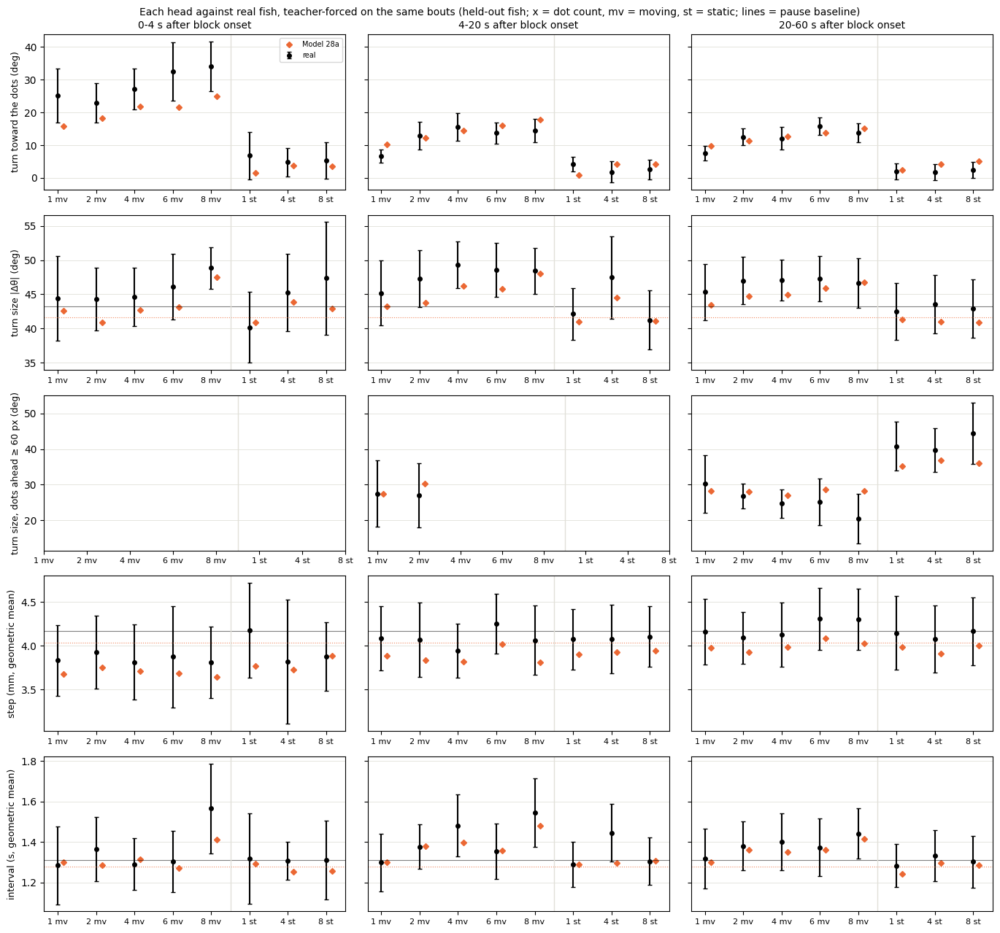

In [ ]:
# Model 28a: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_28a, hg_28a = head_gaps({"Model 28a": ("report_ckpts/M28a", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr")}, rej=REJ["wall_reject"])

#### 28a / 28b — 26e + correction, 20 s cut-off — seed 0 (key `28b`)

In [ ]:
# Model 28b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M28b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_28b = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_28b.index = ["turn", "displacement", "interval", "joint"]
print(lik_28b.round(3).to_string())

turn             7.665
displacement     4.505
interval         1.215
joint           13.385


In [ ]:
# Model 28b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_28b, c2st_28b = run(ckpt_dir="report_ckpts/M28b", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last.csv  (15 rows) in 1010s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last_rej
abs_dtheta_w1                                                 8.5624
symbol_js                                                     0.0118
dt_w1                                                         0.4121
dist_w1                                                       3.6994
trans_js                          

In [ ]:
# Model 28b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M28b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_28b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_28b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.674            0.016      0.608         0.017
matched to the real runs (same bouts, 1:1)            0.672            0.016      0.598         0.017



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.450         0.088        0.034          0.387         0.925
                      median           0.449       0.447         0.098        0.037          0.373         0.932
                      SD               0.159       0.179         0.015        0.011          0.735         1.007
                      q90              0.679       0.714         0.074        0.045

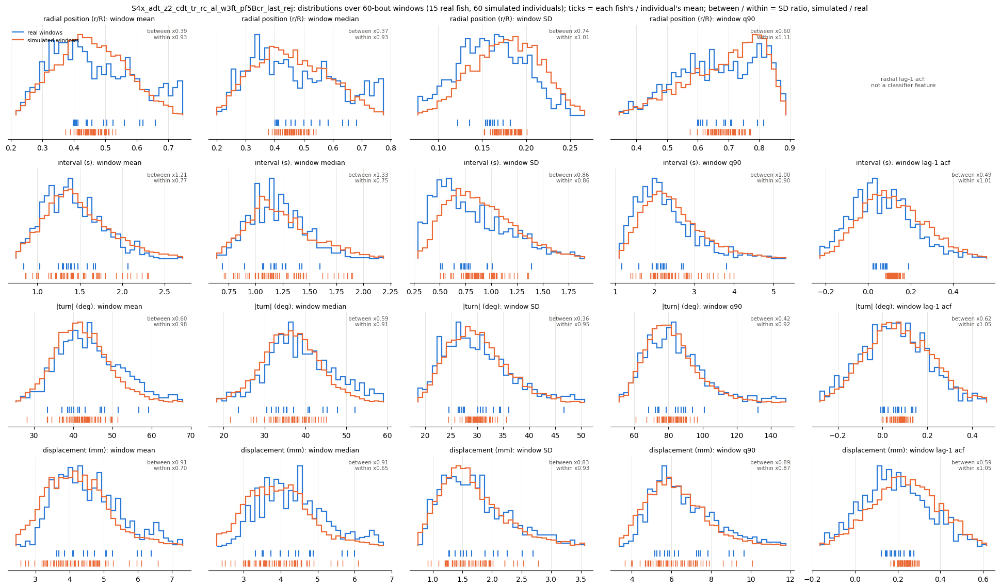

In [ ]:
# Model 28b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_28b = window_stats_grid("report_ckpts/M28b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 11.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.64     1.07  0.15  0.93   3.0   7.0                  22.3 +/- 0.9  22.1 +/- 0.8
d2s3.5    2.20     1.71  2.64  2.98  11.0   9.0                  17.4 +/- 0.9  19.9 +/- 0.8
d4s3.5    1.17     0.70  4.68  3.54  19.0   9.0              

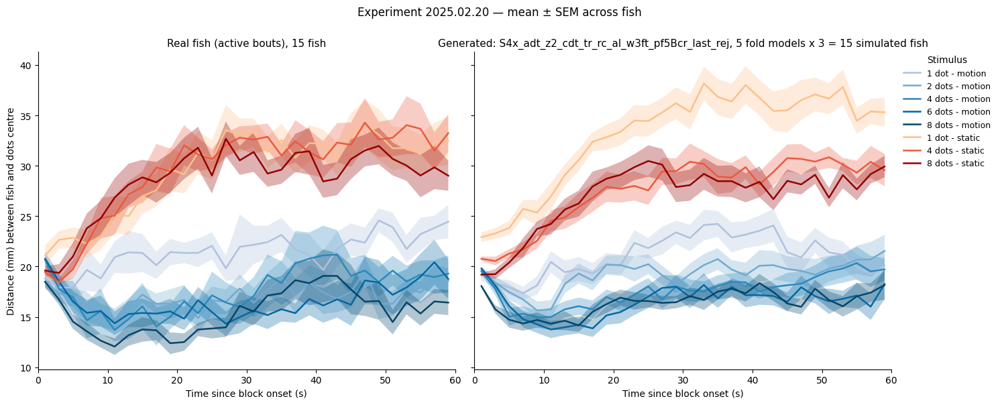

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M28b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

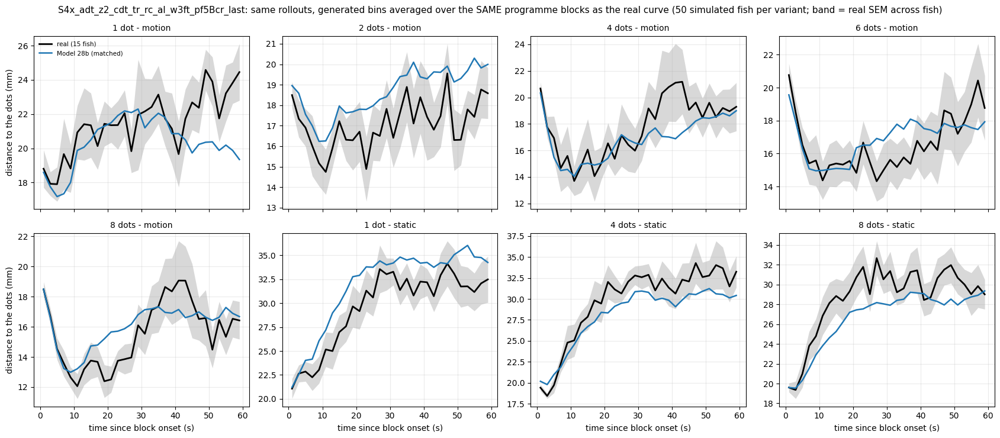

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_28b, _ = profile_variants_matched("report_ckpts/M28b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last", {"Model 28b": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_28b, _ = attraction_table("report_ckpts/M28b", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last                  
           plateau   null attraction                                  plateau   null attraction
cond_label                                                                                     
d1s3.5       22.41  23.57       1.16                                    21.58  22.20       0.62
d2s3.5       17.39  23.58       6.19                                    19.80  22.42       2.62
d4s3.5       18.74  23.93       5.19                                    17.24  22.28       5.04
d6s3.5       16.69  23.12       6.43                                    17.13  22.16       5.02
d8s3.5       16.41  23.36       6.94                                    17.09  22.05       4.97


In [ ]:
# Model 28b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_28b = toward_by_n("report_ckpts/M28b", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_28b.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last
win    N                                                 
0-20 s 1   9.09                                      9.96
       2  13.90                                     12.16
       4  15.73                                     14.93
       6  14.50                                     14.92
       8  16.00                                     18.16
4-20 s 1   6.25                                      9.04
       2  12.27                                     11.56
       4  14.35                                     13.86
       6  12.79                                     13.80
       8  15.11                                     16.82


Model 28b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 28b   real gap Model 28b    real gap Model 28b
cond                                                                  
d1s3.5  25.08         -9.22   6.64          3.63    7.55          2.36
d2s3.5  22.99         -5.07  12.94         -0.81   12.56         -1.13
d4s3.5  27.14         -5.74  15.54         -1.03   12.09          0.49
d6s3.5  32.55        -11.33  13.80          1.94   15.84         -2.03
d8s3.5  34.04         -9.29  14.45          3.31   13.80          1.28
d1s0     6.82         -5.38   4.22         -3.32    1.96          0.42
d4s0     4.81         -0.92   1.86          2.46    1.74          2.45
d8s0     5.26         -1.63   2.63          1.50    2.39          2.81

turn size |Δθ| (deg): real f

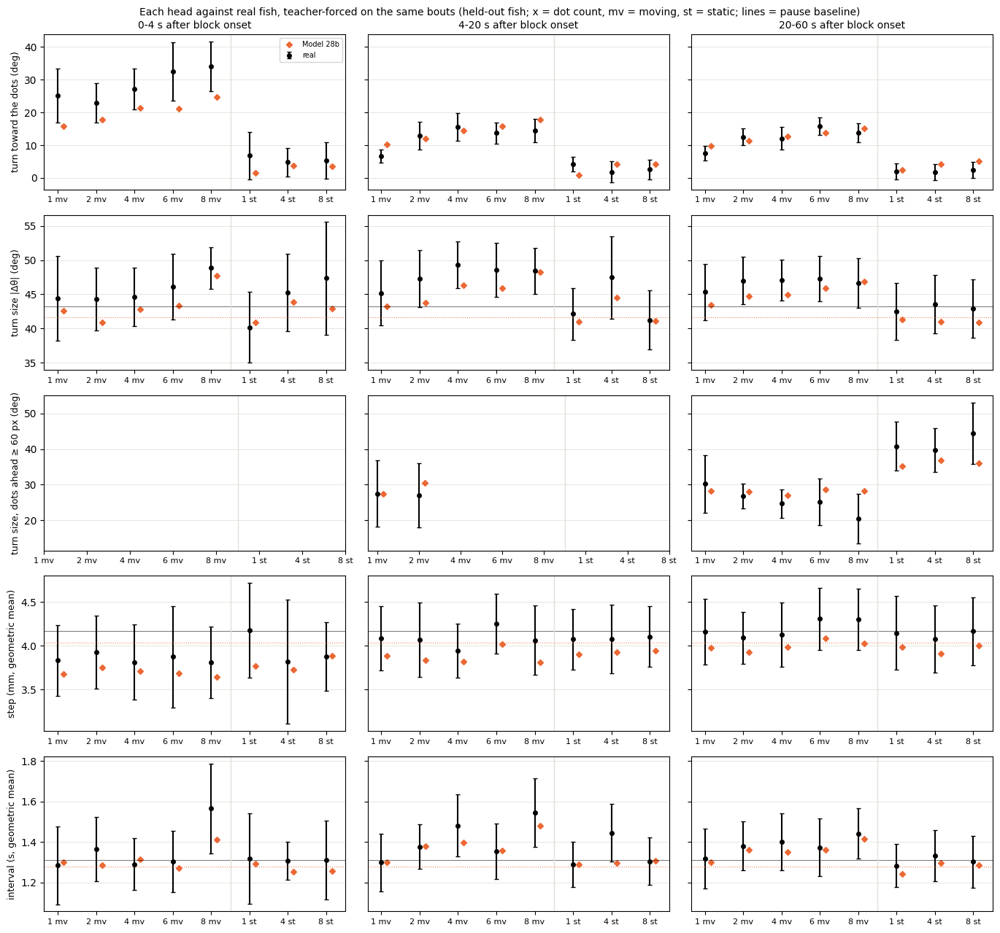

In [ ]:
# Model 28b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_28b, hg_28b = head_gaps({"Model 28b": ("report_ckpts/M28b", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="m28d"></a>
### 28c / 28d — 26e + correction, always on

**Change:** keep-best step / final step

Grading 6.67 / 5.84 (real 6.00), 8-dot plateau 1.1–1.6 mm closer.

#### 28c / 28d — 26e + correction, always on — seed 0 (key `28c`)

In [ ]:
# Model 28c: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M28c/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_28c = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_28c.index = ["turn", "displacement", "interval", "joint"]
print(lik_28c.round(3).to_string())

turn             7.665
displacement     4.504
interval         1.215
joint           13.385


In [ ]:
# Model 28c: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_28c, c2st_28c = run(ckpt_dir="report_ckpts/M28c", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br.csv  (15 rows) in 984s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_rej
abs_dtheta_w1                                           8.5292
symbol_js                                               0.0118
dt_w1                                                   0.4117
dist_w1                                                 3.6947
trans_js                                                0.0132
acf_l2                    

In [ ]:
# Model 28c: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M28c", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_28c = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_28c.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.682            0.015      0.612         0.017
matched to the real runs (same bouts, 1:1)            0.670            0.016      0.600         0.016



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.453         0.088        0.031          0.350         0.942
                      median           0.449       0.452         0.098        0.035          0.354         0.950
                      SD               0.159       0.179         0.015        0.011          0.739         1.022
                      q90              0.679       0.715         0.074        0.041

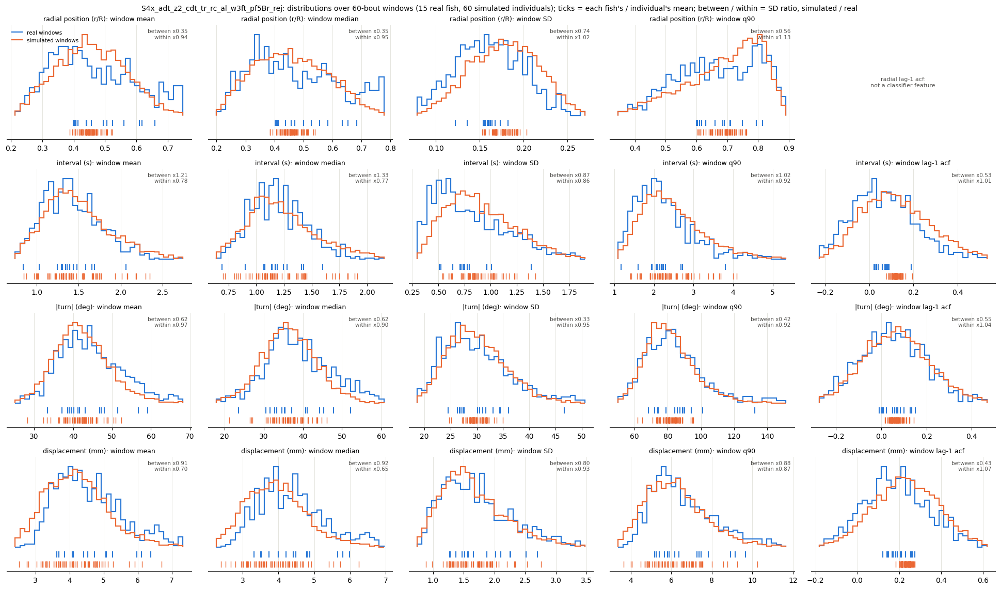

In [ ]:
# Model 28c: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_28c = window_stats_grid("report_ckpts/M28c", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_fold4.pt: 3 rollouts
dropped 11.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.94     1.31  0.15  1.41   3.0   7.0                  22.3 +/- 0.9  22.7 +/- 0.8
d2s3.5    1.68     1.30  2.64  2.89  11.0   9.0                  17.4 +/- 0.9  19.5 +/- 0.6
d4s3.5    1.86     1.01  4.68  4.92  19.0  15.0                  18.7 +/- 1.7  16.6 +/- 0.5

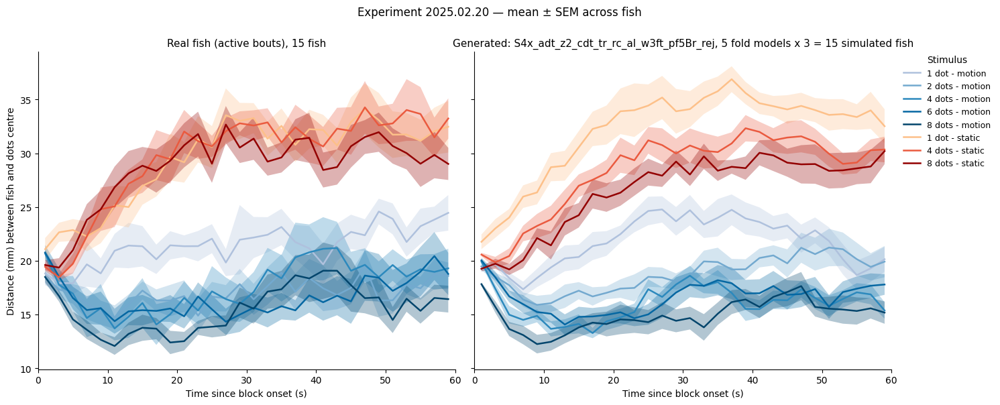

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28c: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M28c", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

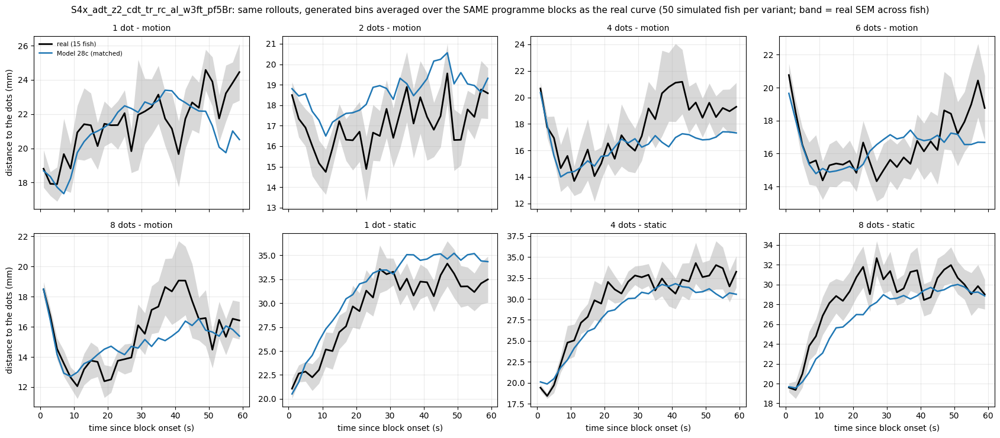

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28c: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_28c, _ = profile_variants_matched("report_ckpts/M28c", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br", {"Model 28c": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28c: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_28c, _ = attraction_table("report_ckpts/M28c", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br                  
           plateau   null attraction                            plateau   null attraction
cond_label                                                                               
d1s3.5       22.41  23.57       1.16                              22.38  22.55       0.17
d2s3.5       17.39  23.58       6.19                              18.87  22.22       3.35
d4s3.5       18.74  23.93       5.19                              16.84  22.35       5.51
d6s3.5       16.69  23.12       6.43                              16.84  22.38       5.55
d8s3.5       16.41  23.36       6.94                              15.17  22.27       7.10


In [ ]:
# Model 28c: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_28c = toward_by_n("report_ckpts/M28c", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br"], rej=REJ["wall_reject"])
print(tow_28c.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br
win    N                                           
0-20 s 1   9.09                                9.96
       2  13.90                               11.60
       4  15.73                               14.22
       6  14.50                               14.24
       8  16.00                               17.35
4-20 s 1   6.25                                9.04
       2  12.27                               11.03
       4  14.35                               13.12
       6  12.79                               13.16
       8  15.11                               16.01


Model 28c: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 28c   real gap Model 28c    real gap Model 28c
cond                                                                  
d1s3.5  25.08         -9.22   6.64          3.63    7.55          2.36
d2s3.5  22.99         -5.94  12.94         -1.34   12.56         -0.85
d4s3.5  27.14         -6.42  15.54         -1.72   12.09          1.02
d6s3.5  32.55        -12.05  13.80          1.29   15.84         -1.23
d8s3.5  34.04         -9.86  14.45          2.52   13.80          2.22
d1s0     6.82         -5.38   4.22         -3.32    1.96          0.42
d4s0     4.81         -0.92   1.86          2.46    1.74          2.45
d8s0     5.26         -1.63   2.63          1.50    2.39          2.81

turn size |Δθ| (deg): real f

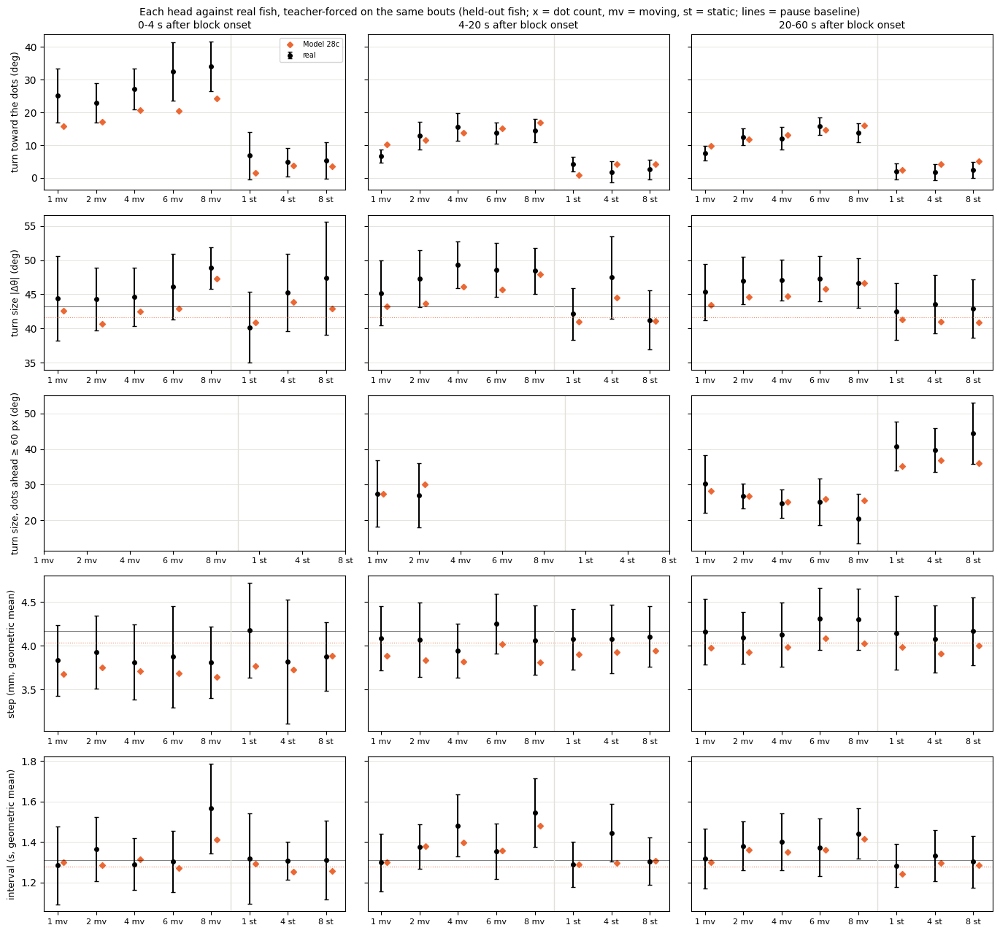

In [ ]:
# Model 28c: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_28c, hg_28c = head_gaps({"Model 28c": ("report_ckpts/M28c", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br")}, rej=REJ["wall_reject"])

#### 28c / 28d — 26e + correction, always on — seed 0 (key `28d`)

In [ ]:
# Model 28d: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M28d/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_28d = _l[_l.arm == "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_28d.index = ["turn", "displacement", "interval", "joint"]
print(lik_28d.round(3).to_string())

turn             7.665
displacement     4.504
interval         1.215
joint           13.384


In [ ]:
# Model 28d: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_28d, c2st_28d = run(ckpt_dir="report_ckpts/M28d", arms="S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last.csv  (15 rows) in 985s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last_rej
abs_dtheta_w1                                                8.4808
symbol_js                                                    0.0117
dt_w1                                                        0.4095
dist_w1                                                      3.6798
trans_js                                    

In [ ]:
# Model 28d: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M28d", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_28d = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_28d.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.688            0.015      0.611         0.013
matched to the real runs (same bouts, 1:1)            0.676            0.016      0.598         0.015



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.456         0.088        0.034          0.383         0.919
                      median           0.449       0.452         0.098        0.037          0.379         0.930
                      SD               0.159       0.181         0.015        0.011          0.720         1.015
                      q90              0.679       0.719         0.074        0.043

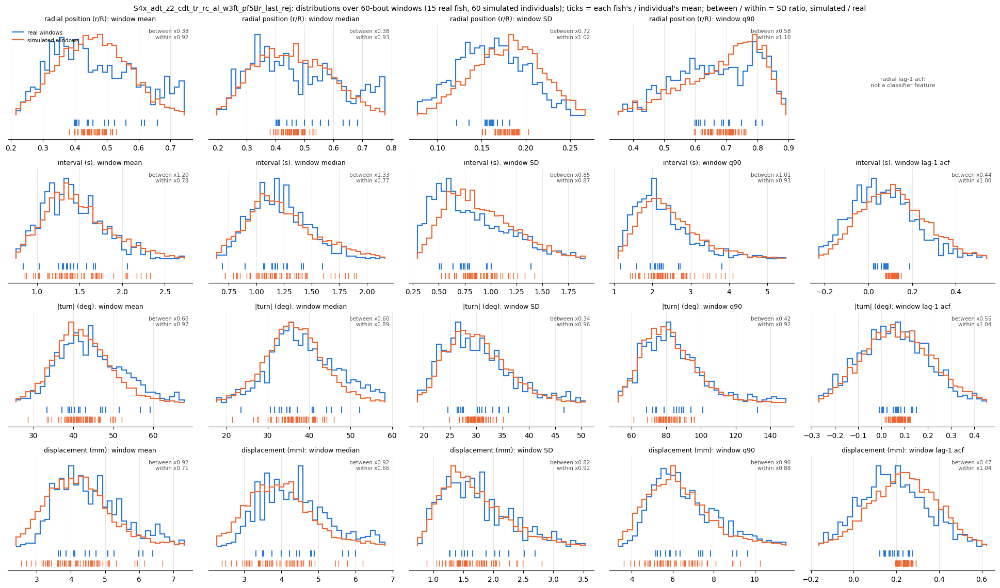

In [ ]:
# Model 28d: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_28d = window_stats_grid("report_ckpts/M28d", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last", rej=REJ["wall_reject"], reps=4)


  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last_fold0.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last_fold1.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last_fold2.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last_fold3.pt: 3 rollouts
  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last_fold4.pt: 3 rollouts
dropped 10.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.61     1.14  0.15  0.13   3.0   5.0                  22.3 +/- 0.9  21.2 +/- 0.9
d2s3.5    1.23     0.97  2.64  2.88  11.0  11.0                  17.4 +/- 0.9  18.0 +/- 0.5
d4s3.5    1.44     0.82  4.68  4.82  19.0   9.0                  1

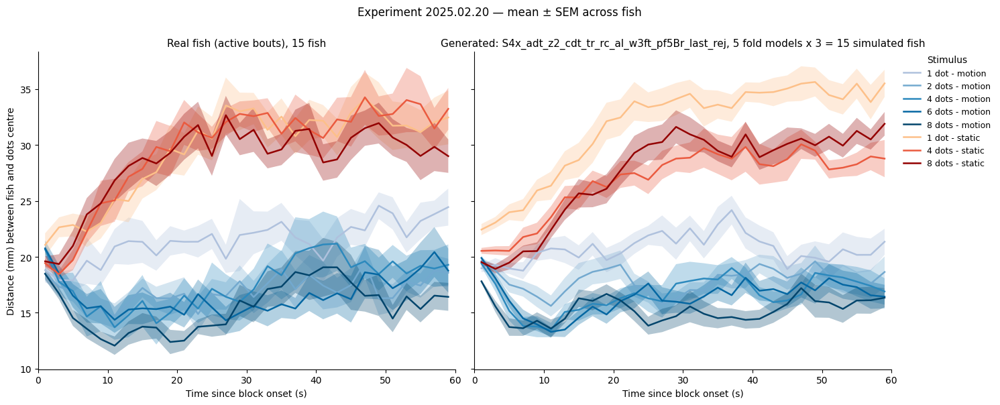

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28d: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M28d", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

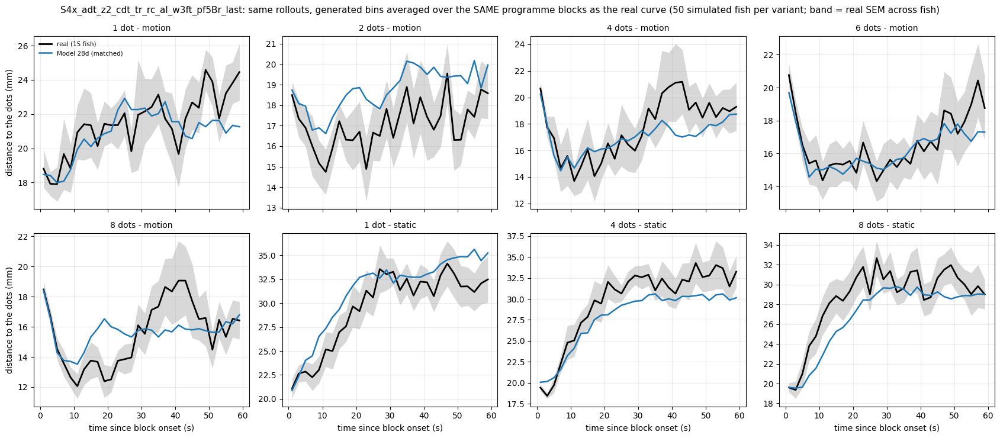

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28d: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_28d, _ = profile_variants_matched("report_ckpts/M28d", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last", {"Model 28d": {"arm": "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28d: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_28d, _ = attraction_table("report_ckpts/M28d", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last                  
           plateau   null attraction                                 plateau   null attraction
cond_label                                                                                    
d1s3.5       22.41  23.57       1.16                                   21.88  22.35       0.47
d2s3.5       17.39  23.58       6.19                                   18.73  22.12       3.38
d4s3.5       18.74  23.93       5.19                                   17.40  22.12       4.72
d6s3.5       16.69  23.12       6.43                                   16.29  22.53       6.24
d8s3.5       16.41  23.36       6.94                                   15.63  22.27       6.64


In [ ]:
# Model 28d: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_28d = toward_by_n("report_ckpts/M28d", ["S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last"], rej=REJ["wall_reject"])
print(tow_28d.round(2).to_string())

           real  S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last
win    N                                                
0-20 s 1   9.09                                     9.96
       2  13.90                                    11.57
       4  15.73                                    14.10
       6  14.50                                    13.99
       8  16.00                                    17.22
4-20 s 1   6.25                                     9.04
       2  12.27                                    10.98
       4  14.35                                    12.97
       6  12.79                                    12.83
       8  15.11                                    15.83


Model 28d: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 28d   real gap Model 28d    real gap Model 28d
cond                                                                  
d1s3.5  25.08         -9.22   6.64          3.63    7.55          2.36
d2s3.5  22.99         -5.90  12.94         -1.35   12.56         -0.92
d4s3.5  27.14         -6.41  15.54         -1.90   12.09          0.87
d6s3.5  32.55        -12.09  13.80          1.01   15.84         -1.47
d8s3.5  34.04         -9.80  14.45          2.42   13.80          1.97
d1s0     6.82         -5.38   4.22         -3.32    1.96          0.42
d4s0     4.81         -0.92   1.86          2.46    1.74          2.45
d8s0     5.26         -1.63   2.63          1.50    2.39          2.81

turn size |Δθ| (deg): real f

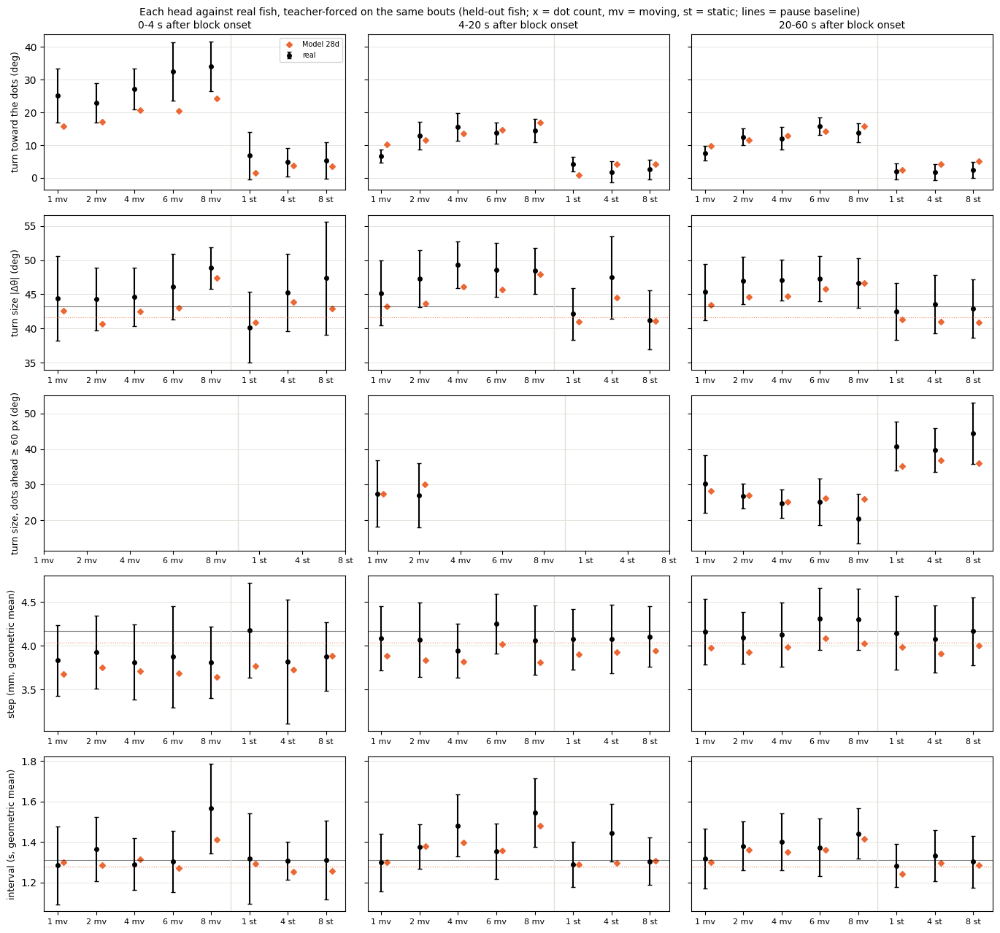

In [ ]:
# Model 28d: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_28d, hg_28d = head_gaps({"Model 28d": ("report_ckpts/M28d", "S4x_adt_z2_cdt_tr_rc_al_w3ft_pf5Br_last")}, rej=REJ["wall_reject"])

<a id="m16b"></a>
### 16b — Model 27 + correction

**Change:** 20 s cut-off, final step

The best profile shape of all (dip 4.04, moving error 0.76) but Model 27's worse AUC.

#### 16b — Model 27 + correction — seed 0 (key `16b`)

In [ ]:
# Model 16b: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M16b/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_16b = _l[_l.arm == "S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_16b.index = ["turn", "displacement", "interval", "joint"]
print(lik_16b.round(3).to_string())

turn             7.657
displacement     4.513
interval         1.236
joint           13.406


In [ ]:
# Model 16b: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_16b, c2st_16b = run(ckpt_dir="report_ckpts/M16b", arms="S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 742s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                                                   7.1061
symbol_js                                                       0.0094
dt_w1                                                           0.4110
dist_w1                                                         4.4160
trans_js         

In [ ]:
# Model 16b: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M16b", "S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_16b = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_16b.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.693            0.018      0.633         0.022
matched to the real runs (same bouts, 1:1)            0.690            0.019      0.627         0.025



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.464         0.088        0.038          0.432         0.919
                      median           0.449       0.461         0.098        0.042          0.432         0.931
                      SD               0.159       0.177         0.015        0.011          0.698         0.987
                      q90              0.679       0.720         0.074        0.046

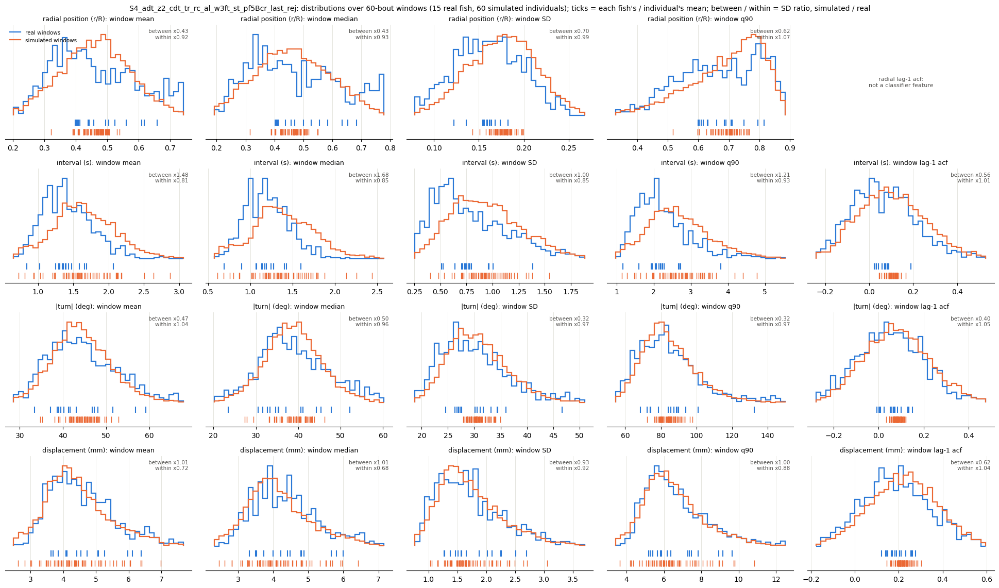

In [ ]:
# Model 16b: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_16b = window_stats_grid("report_ckpts/M16b", "S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold0.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold1.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold2.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold3.pt: 3 rollouts
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.77     1.16  0.15   1.4   3.0   5.0                  22.3 +/- 0.9  20.6 +/- 1.0
d2s3.5    0.95     0.80  2.64  3.24  11.0  15.0                  17.4 +/- 0.9  17.1 +/- 0.7
d4s3.5    1.39     0.77  4.68  4.72  19.0  19.0    

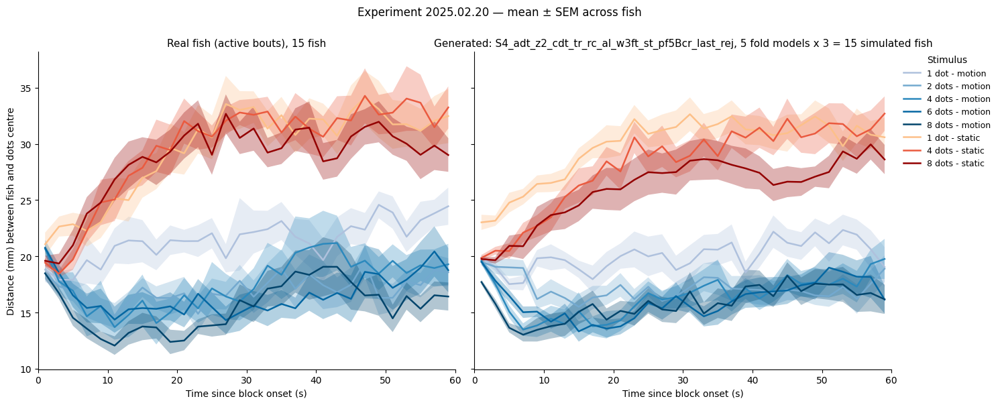

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 16b: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M16b", "S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

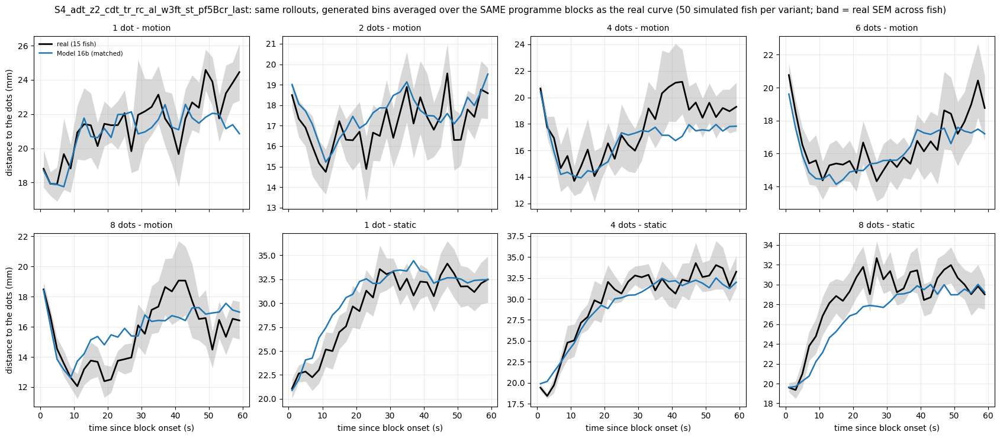

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 16b: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_16b, _ = profile_variants_matched("report_ckpts/M16b", "S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last", {"Model 16b": {"arm": "S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 16b: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_16b, _ = attraction_table("report_ckpts/M16b", ["S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                    plateau   null attraction
cond_label                                                                                       
d1s3.5       22.41  23.57       1.16                                      21.70  22.51       0.81
d2s3.5       17.39  23.58       6.19                                      17.52  22.33       4.81
d4s3.5       18.74  23.93       5.19                                      17.18  22.32       5.14
d6s3.5       16.69  23.12       6.43                                      16.61  22.39       5.78
d8s3.5       16.41  23.36       6.94                                      16.18  22.35       6.17


In [ ]:
# Model 16b: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_16b = toward_by_n("report_ckpts/M16b", ["S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last"], rej=REJ["wall_reject"])
print(tow_16b.round(2).to_string())

           real  S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
win    N                                                   
0-20 s 1   9.09                                        9.92
       2  13.90                                       12.80
       4  15.73                                       14.45
       6  14.50                                       15.68
       8  16.00                                       18.03
4-20 s 1   6.25                                        8.94
       2  12.27                                       12.06
       4  14.35                                       13.10
       6  12.79                                       14.31
       8  15.11                                       16.25


Model 16b: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 16b   real gap Model 16b    real gap Model 16b
cond                                                                  
d1s3.5  25.08         -9.07   6.64          4.04    7.55          2.67
d2s3.5  22.99         -3.79  12.94         -0.09   12.56         -1.34
d4s3.5  27.14         -5.57  15.54         -1.87   12.09          0.23
d6s3.5  32.55         -9.63  13.80          2.32   15.84         -1.96
d8s3.5  34.04         -7.62  14.45          3.41   13.80          0.81
d1s0     6.82         -6.10   4.22         -3.31    1.96         -0.25
d4s0     4.81         -2.33   1.86          0.89    1.74          2.40
d8s0     5.26         -0.81   2.63          1.25    2.39          2.93

turn size |Δθ| (deg): real f

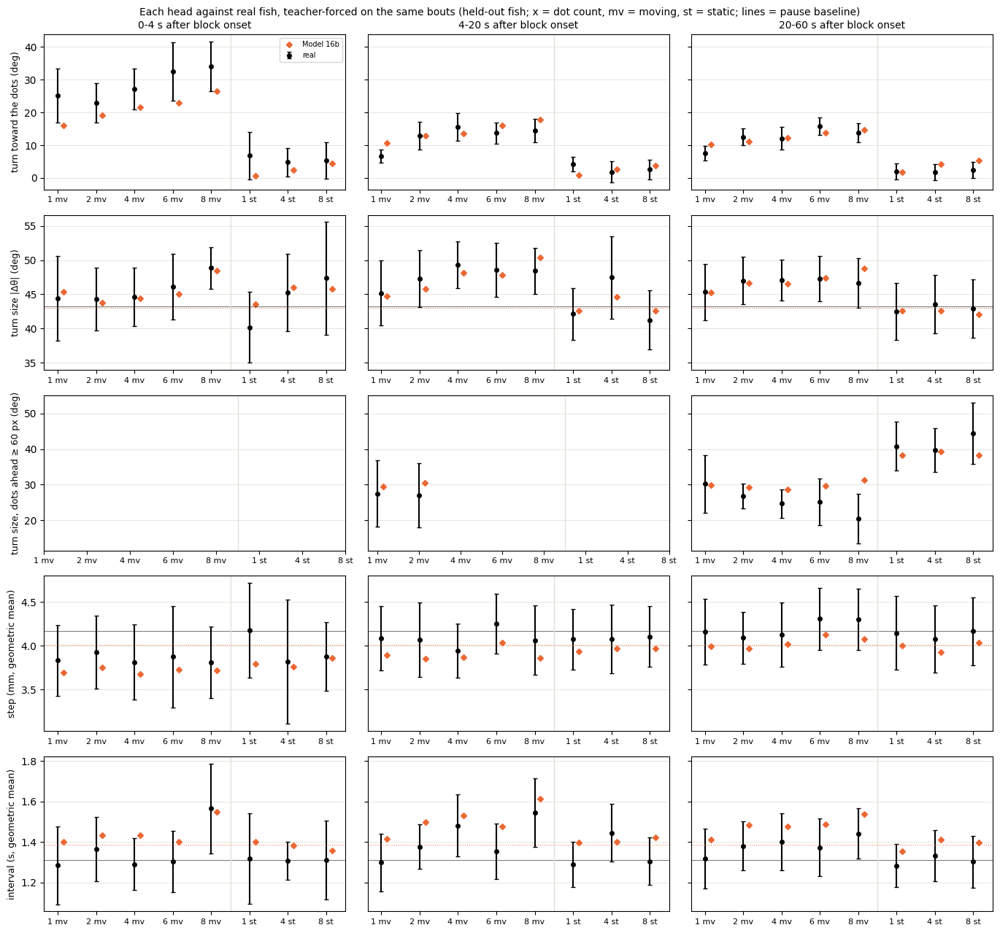

In [ ]:
# Model 16b: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_16b, hg_16b = head_gaps({"Model 16b": ("report_ckpts/M16b", "S4_adt_z2_cdt_tr_rc_al_w3ft_st_pf5Bcr_last")}, rej=REJ["wall_reject"])

<a id="m28f"></a>
### 28e / 28f — Model 17 + correction, always on

**Change:** keep-best step / final step

Within noise of 14f (the cut-off) on every metric.

#### 28e / 28f — Model 17 + correction, always on — seed 0 (key `28e`)

In [ ]:
# Model 28e: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M28e/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_28e = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_28e.index = ["turn", "displacement", "interval", "joint"]
print(lik_28e.round(3).to_string())

turn             7.628
displacement     4.513
interval         1.203
joint           13.344


In [ ]:
# Model 28e: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_28e, c2st_28e = run(ckpt_dir="report_ckpts/M28e", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br.csv  (15 rows) in 1065s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_rej
abs_dtheta_w1                                                   8.6889
symbol_js                                                       0.0133
dt_w1                                                           0.4375
dist_w1                                                         4.6631
trans_js        

In [ ]:
# Model 28e: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M28e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_28e = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_28e.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.656            0.006      0.577         0.011
matched to the real runs (same bouts, 1:1)            0.654            0.005      0.565         0.011



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.467         0.088        0.043          0.486         0.903
                      median           0.449       0.471         0.098        0.047          0.478         0.904
                      SD               0.159       0.174         0.015        0.014          0.900         0.973
                      q90              0.679       0.713         0.074        0.055

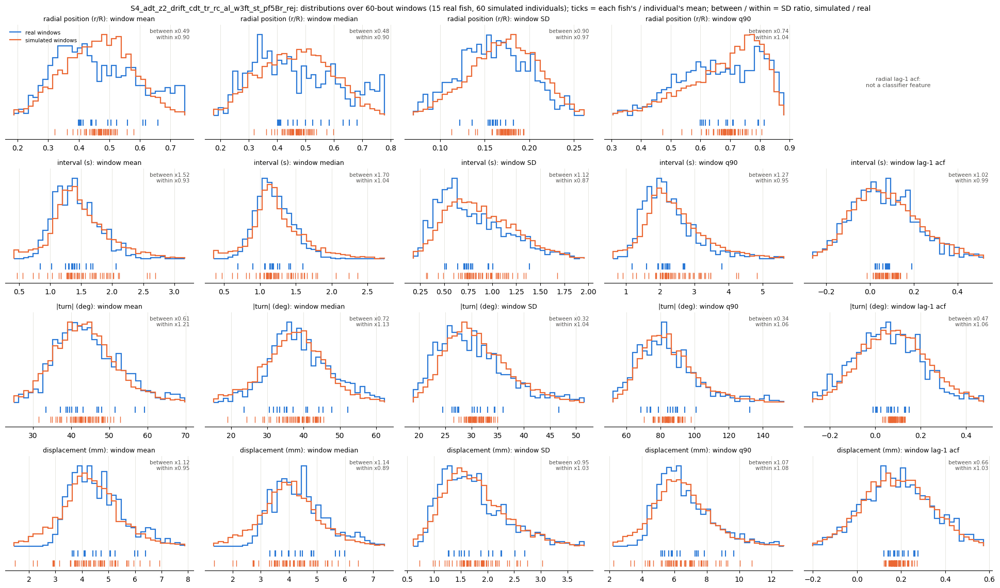

In [ ]:
# Model 28e: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_28e = window_stats_grid("report_ckpts/M28e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_fold4.pt: 3 rollouts
dropped 9.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.75     1.10  0.15  0.59   3.0   5.0                  22.3 +/- 0.9  20.7 +/- 1.2
d2s3.5    0.88     0.72  2.64  2.99  11.0  11.0                  17.4 +/- 0.9  18.0 +/- 0.8
d4s3.5    2.37     1.31  4.68  4.57  19.0   9.0     

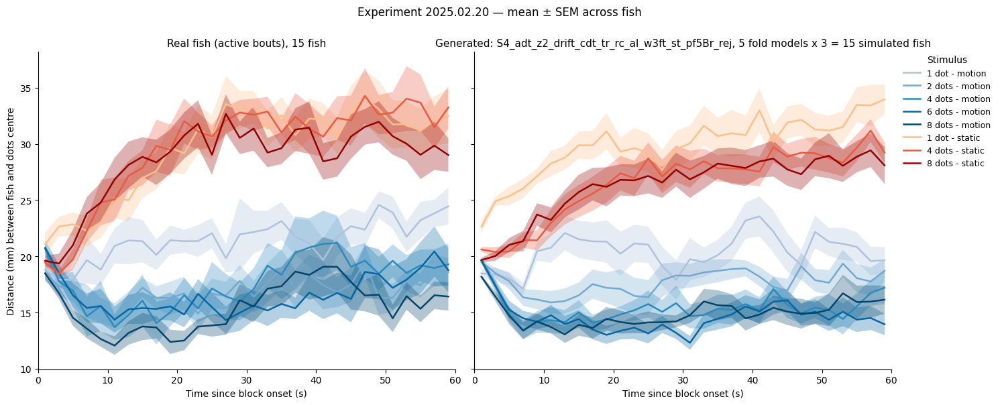

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28e: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M28e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

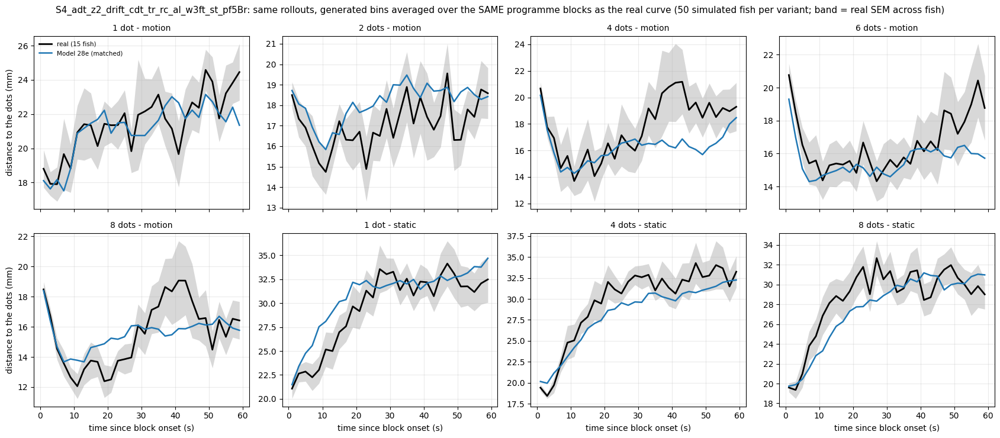

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28e: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_28e, _ = profile_variants_matched("report_ckpts/M28e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br", {"Model 28e": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28e: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_28e, _ = attraction_table("report_ckpts/M28e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br                  
           plateau   null attraction                                    plateau   null attraction
cond_label                                                                                       
d1s3.5       22.41  23.57       1.16                                      21.47  22.50       1.03
d2s3.5       17.39  23.58       6.19                                      17.96  22.36       4.40
d4s3.5       18.74  23.93       5.19                                      16.23  22.65       6.42
d6s3.5       16.69  23.12       6.43                                      15.33  22.48       7.15
d8s3.5       16.41  23.36       6.94                                      15.73  22.50       6.77


In [ ]:
# Model 28e: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_28e = toward_by_n("report_ckpts/M28e", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br"], rej=REJ["wall_reject"])
print(tow_28e.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br
win    N                                                   
0-20 s 1   9.09                                        9.59
       2  13.90                                       12.88
       4  15.73                                       14.84
       6  14.50                                       15.83
       8  16.00                                       18.33
4-20 s 1   6.25                                        8.44
       2  12.27                                       11.90
       4  14.35                                       13.44
       6  12.79                                       14.27
       8  15.11                                       16.35


Model 28e: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 28e   real gap Model 28e    real gap Model 28e
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.93    7.55          1.91
d2s3.5  22.99         -3.10  12.94         -0.58   12.56         -0.84
d4s3.5  27.14         -4.92  15.54         -1.56   12.09          1.39
d6s3.5  32.55         -7.87  13.80          2.10   15.84         -0.57
d8s3.5  34.04         -6.46  14.45          3.03   13.80          2.57
d1s0     6.82         -6.47   4.22         -3.10    1.96          0.12
d4s0     4.81         -2.04   1.86          0.95    1.74          1.96
d8s0     5.26         -0.72   2.63          1.08    2.39          2.55

turn size |Δθ| (deg): real f

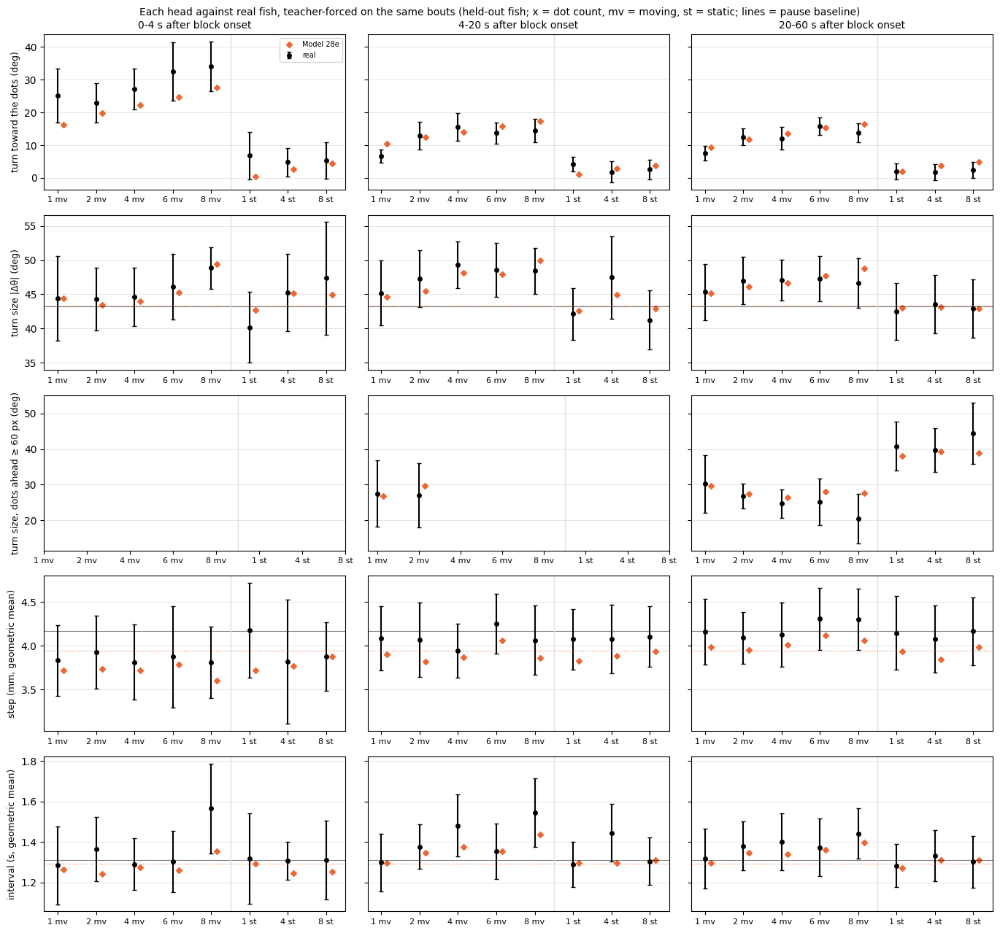

In [ ]:
# Model 28e: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_28e, hg_28e = head_gaps({"Model 28e": ("report_ckpts/M28e", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br")}, rej=REJ["wall_reject"])

#### 28e / 28f — Model 17 + correction, always on — seed 0 (key `28f`)

In [ ]:
# Model 28f: held-out likelihood per head, bits per bout (lower = better), mean over the 15 held-out fish.
_l = pd.read_csv("report_ckpts/M28f/likA_model1.csv").drop_duplicates(["arm", "fish"])
lik_28f = _l[_l.arm == "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last"][["bits_per_bout", "bits_per_bout_dist", "bits_per_bout_dt", "bits_per_bout_joint"]].mean()
lik_28f.index = ["turn", "displacement", "interval", "joint"]
print(lik_28f.round(3).to_string())

turn             7.628
displacement     4.513
interval         1.203
joint           13.344


In [ ]:
# Model 28f: distinguishability -- the window classifier's AUC, standard and steady-state readings, and the spread of
# simulated individuals relative to real fish (bf = between fish, wf = within fish); 8 rollouts per held-out fish.
panel_28f, c2st_28f = run(ckpt_dir="report_ckpts/M28f", arms="S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last", R=20, jobs=4, progress=False, cfg_override=REJ, tag="rej")

generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last.csv  (15 rows) in 1133s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last_rej
abs_dtheta_w1                                                        8.7207
symbol_js                                                            0.0133
dt_w1                                                                0.4376
dist_w1                                        

In [ ]:
# Model 28f: the same classifier under two fairer windowings of the SAME rollouts (8 per held-out fish, the seeds of
# the AUC above). "1 per real": the plain tiling cut down to one generated window per real one, which removes the extra
# classifier power of the ~1.6x more generated windows. "matched": the rollout cut at the real fish's own window
# positions (identical bouts, conditions and phase, 1:1), which also removes the difference in composition. All 39
# features, and without the four radial-position features.
from c2st_protocol import matched_c2st_table
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    _t = matched_c2st_table("report_ckpts/M28f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last", rej=REJ["wall_reject"], jobs=4)
_t = _t[(_t.windows == "all") & _t.generated.isin(["plain tiling, 1 generated window per real one",
                                                    "matched to the real runs (same bouts, 1:1)"])]
auc2_28f = _t.set_index("generated")[["all features", "all features se", "no radial", "no radial se"]]
print(auc2_28f.round(3).to_string())

                                               all features  all features se  no radial  no radial se
generated                                                                                            
plain tiling, 1 generated window per real one         0.642            0.013      0.566         0.015
matched to the real runs (same bouts, 1:1)            0.640            0.012      0.562         0.015



  rolled out fish 1/15
  rolled out fish 2/15
  rolled out fish 3/15
  rolled out fish 4/15
  rolled out fish 5/15
  rolled out fish 6/15
  rolled out fish 7/15
  rolled out fish 8/15
  rolled out fish 9/15
  rolled out fish 10/15
  rolled out fish 11/15
  rolled out fish 12/15
  rolled out fish 13/15
  rolled out fish 14/15
  rolled out fish 15/15
                                 real_median  sim_median  between_real  between_sim  between_ratio  within_ratio
channel               stat                                                                                      
radial position (r/R) mean             0.444       0.466         0.088        0.047          0.531         0.893
                      median           0.449       0.468         0.098        0.050          0.516         0.893
                      SD               0.159       0.173         0.015        0.015          0.990         0.956
                      q90              0.679       0.712         0.074        0.060

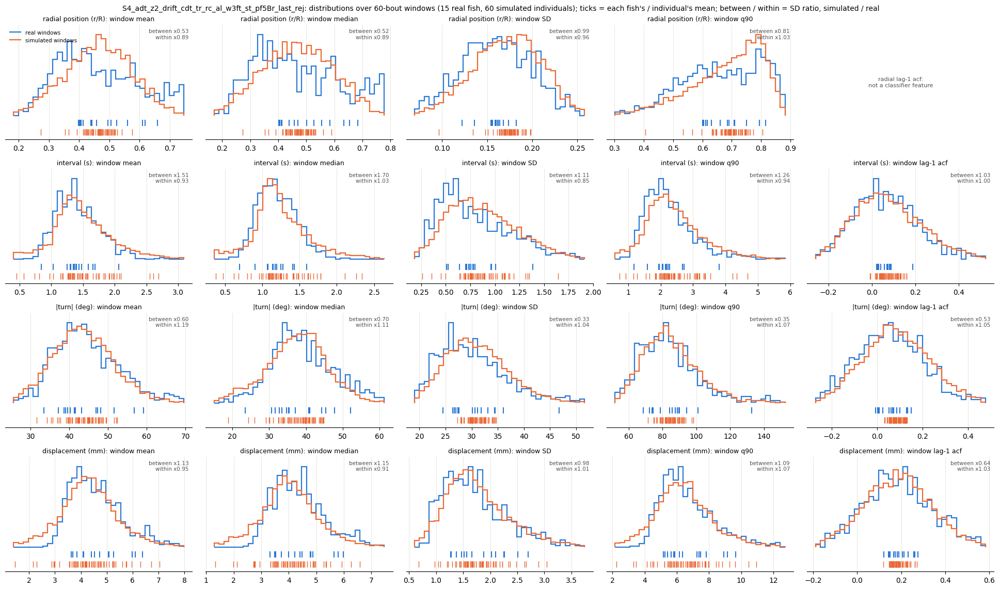

In [ ]:
# Model 28f: individuality -- every window statistic (mean, median, SD, q90, lag-1 autocorrelation) of radial position,
# interval, |turn| and displacement over the classifier's 60-bout windows: the distribution over all windows, real (blue)
# against simulated (orange), and underneath one tick per real fish / simulated individual at its mean. 4 rollouts per
# held-out fish, each a new individual; in each panel the between- and within-fish SD, simulated / real.
from model_figures import window_stats_grid
real_w, gen_w, ws_28f = window_stats_grid("report_ckpts/M28f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last", rej=REJ["wall_reject"], reps=4)


  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last_fold0.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last_fold1.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last_fold2.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last_fold3.pt: 3 rollouts
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last_fold4.pt: 3 rollouts
dropped 9.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.68     1.13  0.15  0.05   3.0   3.0                  22.3 +/- 0.9  20.6 +/- 1.1
d2s3.5    0.91     0.77  2.64  3.24  11.0  11.0                  17.4 +/- 0.9  17.9 +/- 0.8
d4s3.5    1.54     0.84  4.

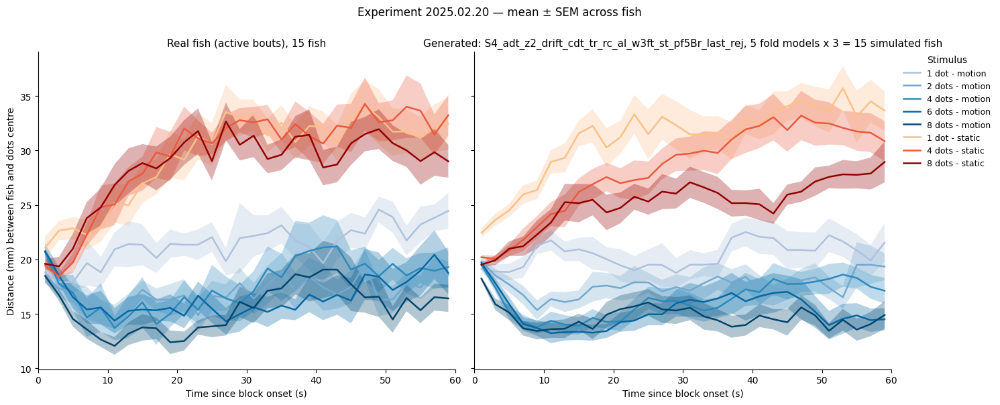

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28f: distance to the dots across the block, real fish next to programme rollouts (each simulated fish swims
    # the whole programme on its own clock, the dots re-anchored to it at every block onset), 5 fold models x 3 fish.
    st, gen_p, prof = dot_profile("report_ckpts/M28f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last", rej=REJ["wall_reject"])

distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                                                                                                     
REA

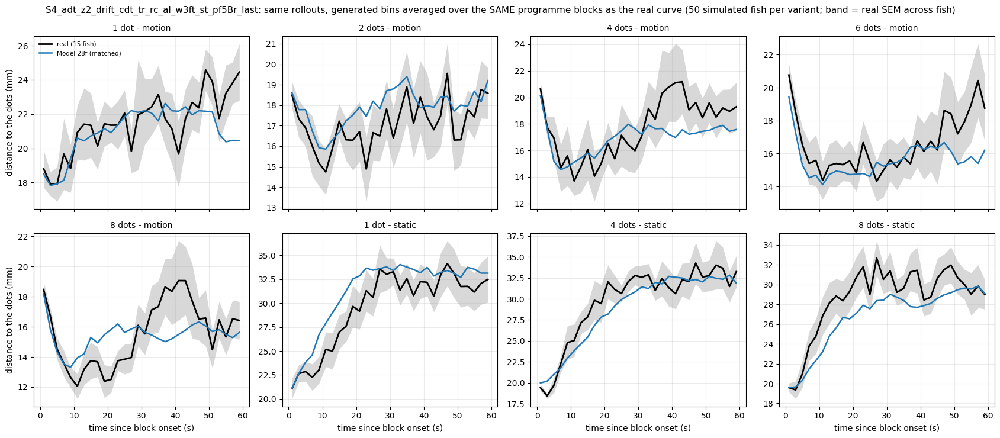

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28f: the same profile with 50 simulated fish, matched to the real block composition -- the numbers to read
    # (dip = approach within 20 s and its latency; plateau 20-60 s; grading = 1-dot minus 8-dot plateau; errors in real SEM).
    varm_28f, _ = profile_variants_matched("report_ckpts/M28f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last", {"Model 28f": {"arm": "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last"}}, rej=REJ["wall_reject"], r_per_model=10,
                                           show_raw=False)

In [ ]:
from model_figures import block_seeding
with block_seeding(True):   # per-block random streams: a fair comparison of the static curves
    # Model 28f: attraction = stimulus-blind null minus the 20-60 s plateau, per dot count (mm). Real fish: a step
    # (~1 mm for one dot, ~6 mm from two up).
    attr_28f, _ = attraction_table("report_ckpts/M28f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last"], rej=REJ["wall_reject"], r_per_model=6)

PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last                  
           plateau   null attraction                                         plateau   null attraction
cond_label                                                                                            
d1s3.5       22.41  23.57       1.16                                           21.92  22.71       0.79
d2s3.5       17.39  23.58       6.19                                           18.44  22.68       4.24
d4s3.5       18.74  23.93       5.19                                           17.47  22.32       4.86
d6s3.5       16.69  23.12       6.43                                           16.19  22.19       6.00
d8s3.5       16.41  23.36       6.94                                       

In [ ]:
# Model 28f: turn toward the moving dots by dot count (deg), predicted bout by bout from the real history (held-out
# fish, population latent), over the first 20 s of a block and over 4-20 s.
import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    tow_28f = toward_by_n("report_ckpts/M28f", ["S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last"], rej=REJ["wall_reject"])
print(tow_28f.round(2).to_string())

           real  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last
win    N                                                        
0-20 s 1   9.09                                             9.59
       2  13.90                                            13.10
       4  15.73                                            15.07
       6  14.50                                            15.93
       8  16.00                                            18.62
4-20 s 1   6.25                                             8.44
       2  12.27                                            12.13
       4  14.35                                            13.67
       6  12.79                                            14.36
       8  15.11                                            16.66


Model 28f: 100.0% of the real stimulus bouts matched to the records

turn toward the dots (deg): real fish (mean over held-out fish) and each model's gap = model - real (paired, same bouts)
        0-4 s               4-20 s               20-60 s              
         real gap Model 28f   real gap Model 28f    real gap Model 28f
cond                                                                  
d1s3.5  25.08         -8.75   6.64          3.93    7.55          1.91
d2s3.5  22.99         -2.96  12.94         -0.33   12.56         -0.69
d4s3.5  27.14         -4.78  15.54         -1.33   12.09          1.55
d6s3.5  32.55         -7.78  13.80          2.24   15.84         -0.43
d8s3.5  34.04         -6.12  14.45          3.38   13.80          2.78
d1s0     6.82         -6.47   4.22         -3.10    1.96          0.12
d4s0     4.81         -2.04   1.86          0.95    1.74          1.96
d8s0     5.26         -0.72   2.63          1.08    2.39          2.55

turn size |Δθ| (deg): real f

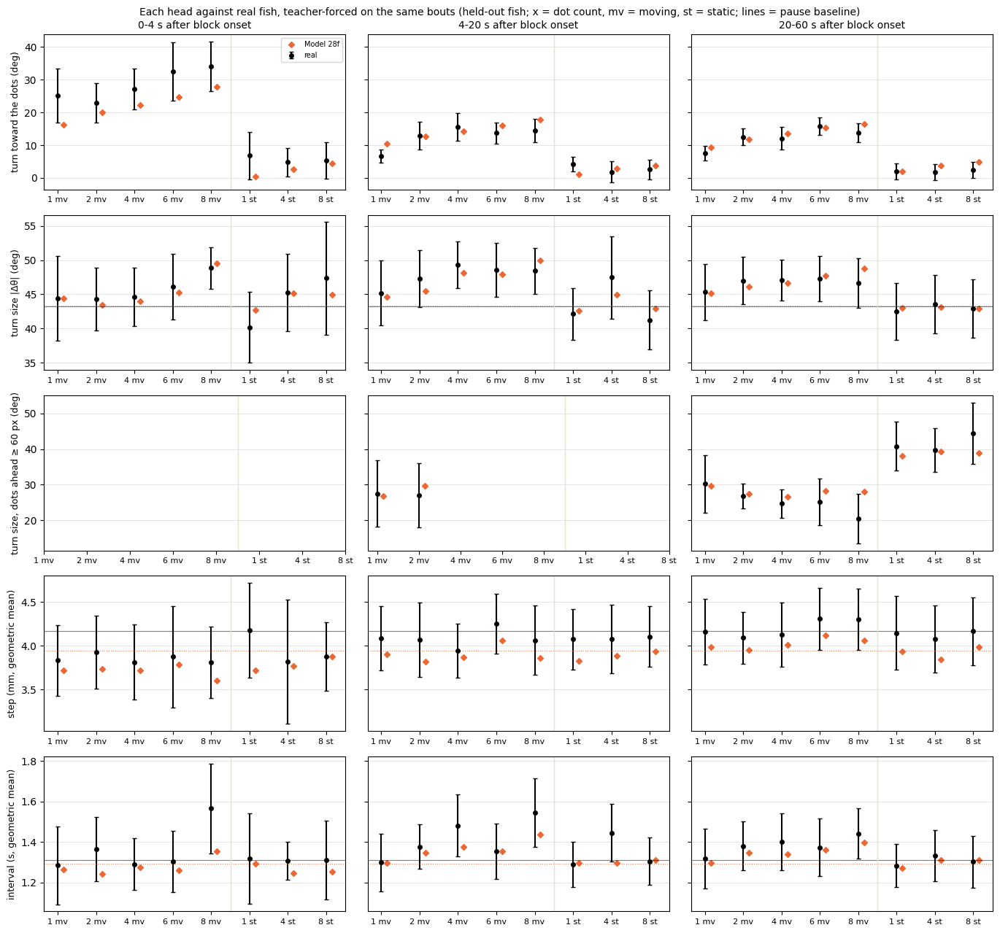

In [ ]:
# Model 28f: each head against real fish, per stimulus condition and block phase (teacher-forced on the held-out
# fish's real bouts; gap = model - real on the same bouts, 95 % CI across fish): where the approach is lost.
from model_figures import head_gaps
hg_rows_28f, hg_28f = head_gaps({"Model 28f": ("report_ckpts/M28f", "S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Br_last")}, rej=REJ["wall_reject"])

<a id="support"></a>
## Supporting numbers

Key numbers only; the full blocks are in `Report_models.ipynb` (Models 12, 25, 26).

In [ ]:
import json, os
import numpy as np, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

def _s(key):
    """Key numbers of one notebook unit (None if it does not exist yet). A trailing * = profile numbers on the old stream."""
    p = f"report_outputs/summary_M{key.rstrip('*')}.json" if key else None
    return json.load(open(p)) if p and os.path.exists(p) else None

GROUPS = [
    ("Seed noise: Model 17's recipe at four seeds (Model 12; profiles on the old stream)",
     [("12a seed 0", "12a"), ("12b seed 101", "12b"), ("12c seed 202", "12c"), ("12d seed 303", "12d")]),
    ("Each component ALONE on Model 4 (Model 25, seed 0; control 20f)",
     [("20f Model 4", "20f"), ("25a + centred lags & truncation", "25a"), ("25b + run clock", "25b"),
      ("25c + aligned-and-far flag", "25c"), ("25d + x3 turn weight", "25d"), ("25e + static block", "25e"),
      ("25f + range products (S4x)", "25f")]),
    ("Each component REMOVED from 18a (Model 26, seed 0; control 18a)",
     [("18a", "18a"), ("26a - centred lags & truncation", "26a"), ("26b - run clock", "26b"),
      ("26c - aligned-and-far flag", "26c"), ("26d - x3 turn weight", "26d"), ("26e - static block", "26e")]),
]
COLS = [("likelihood", "lik_joint", 3), ("matched AUC", "auc_matched", 3), ("std AUC", "auc_std", 3),
        ("no-radial AUC", "auc_matched_norad", 3), ("dip", "dip", 2), ("grading", "grading", 2),
        ("moving err", "mv_err_sem", 2), ("static err", "st_err_sem", 2)]
for title, items in GROUPS:
    print(title)
    print(pd.DataFrame([{n: ("XX" if _s(k) is None or _s(k).get(c) is None else round(_s(k)[c], nd)) for n, c, nd in COLS}
                        for _, k in items], index=[i[0] for i in items]).to_string())
    print()

Seed noise: Model 17's recipe at four seeds (Model 12; profiles on the old stream)
              likelihood  matched AUC  std AUC  no-radial AUC   dip  grading  moving err  static err
12a seed 0        13.344        0.634    0.672          0.559  2.67     5.08        1.15        0.85
12b seed 101      13.356        0.628    0.659          0.538  2.70     4.76        1.49        0.85
12c seed 202      13.323        0.656    0.659          0.589  2.70     3.60        1.57        1.07
12d seed 303      13.357        0.691    0.689          0.620  2.47     4.66        1.44        1.07

Each component ALONE on Model 4 (Model 25, seed 0; control 20f)
                                 likelihood  matched AUC  std AUC  no-radial AUC   dip  grading  moving err  static err
20f Model 4                          13.366        0.669    0.680          0.618  2.07     2.85        1.32        1.10
25a + centred lags & truncation      13.396        0.679    0.723          0.614  2.23     2.52        1.45